In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

In [2]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

In [3]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Blood 3p

In [ ]:
blood_3p_filt <- readRDS("data/3p_blood_2021/vn_Tcells_3p_5p_datasets_blood_3p.rds")

In [30]:
blood_3p_subset  <- readRDS("data/3p_blood_2021/vn_Tcells_3p_5p_datasets_blood_3p_subset.rds")

In [6]:
blood_3p_filt$data_folder  <- paste(blood_3p_filt$patient, blood_3p_filt$time)  


blood_3p_filt$data_folder %>% table  %>% length

[1] 42

In [7]:
505 + 97 + 42 + 190

[1] 834

In [8]:
blood_3p_filt

An object of class Seurat 
26782 features across 324539 samples within 1 assay 
Active assay: RNA (26782 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [9]:
blood_5p

ERROR: Error in eval(expr, envir, enclos): object 'blood_5p' not found


In [ ]:
593574 + 324539 + 287426 + 346456

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(blood_3p_filt)

In [ ]:
blood_3p_subset$patient  %>% table

In [ ]:
DimPlot(blood_3p_subset, group.by = "RNA_snn_res.1")

In [33]:
is_cd4_ctl  <- colnames(blood_3p_filt) %in% colnames(subset(blood_3p_subset, seurat_clusters == 5))

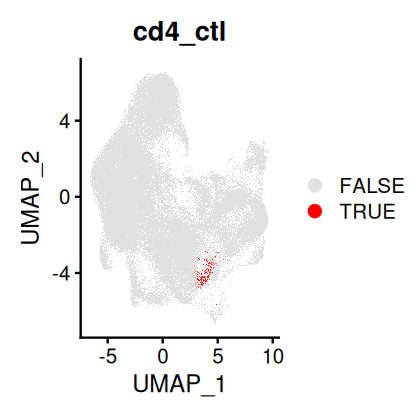

In [34]:
blood_3p_filt$cd4_ctl  <- is_cd4_ctl

DimPlot(blood_3p_filt, group.by = "cd4_ctl", raster = T, cols = c("grey88", "red"))

In [ ]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

`summarise()` has grouped output by 'smp_id'. You can override using the
`.groups` argument.
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


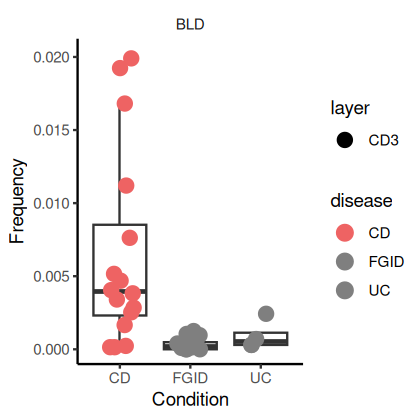

In [35]:
options(repr.plot.width=3.5, repr.plot.height=3.5)

md <- blood_3p_filt@meta.data
md$smp_id <- paste(md$patient, md$time, md$tissue, md$layer)

df4 <- md %>% group_by(smp_id, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>% 
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!smp_id, names_to = "cd4_ctl", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(smp_id, disease, patient, 
                                   time, tissue, layer) %>% unique()
df4  <- left_join(df4, md_to_join, by = "smp_id")

# The final plot

df4 %>% filter(cd4_ctl == T & time == "T0D" & disease %in% c("CD","UC","FGID")) %>% 
ggplot(aes(x = disease, y = freq)) + # you can change the x to whatever variable you're interested in
  geom_boxplot(outlier.shape = NA) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(position=position_jitter(0.2), size = 4, aes(color = disease, shape = layer)) + # in aes, you can also use shape or fill (for the shapes that allow it)
  facet_grid(cols = vars(tissue), scales = "free") +
  ylab("Frequency") +
  xlab("Condition") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  scale_color_manual(values = c("indianred2","grey50","grey50")) 
  

In [ ]:
df4 %>% filter(cd4_ctl == T & disease %in% c("CD","UC","FGID") )  %>% 
ggplot(aes(x = disease, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  #facet_wrap(~tissue, scales = "free") +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "3p identification cohort CD4 CTL") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
scale_color_manual(values = c("CD" = (scales::hue_pal() (4))[1], "UC" = (scales::hue_pal() (4))[4], 
                             "FGID" = (scales::hue_pal() (4))[2])) +
scale_fill_manual(values = c("CD" = (scales::hue_pal() (4))[1], "UC" = (scales::hue_pal() (4))[4], 
                             "FGID" = (scales::hue_pal() (4))[2])) +
ggtheme()

In [140]:
ggsave("figures/boxplot_freq_blood_3p_21/250114_cd4_ctl.svg", width = 9, height = 9, units = "cm", create.dir = T)
ggsave("figures/boxplot_freq_blood_3p_21/250114_cd4_ctl.png", width = 9, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.404858299595142, 0.0141964792731403, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.105029758431556, 0, 0, 0.0439689286237725, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.404858299595142, 0.0141964792731403, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.105029758431556, 0, 0, 0.0439689286237725, :
“cannot compute exact p-value with ties”


`summarise()` has grouped output by 'smp_id'. You can override using the
`.groups` argument.
Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


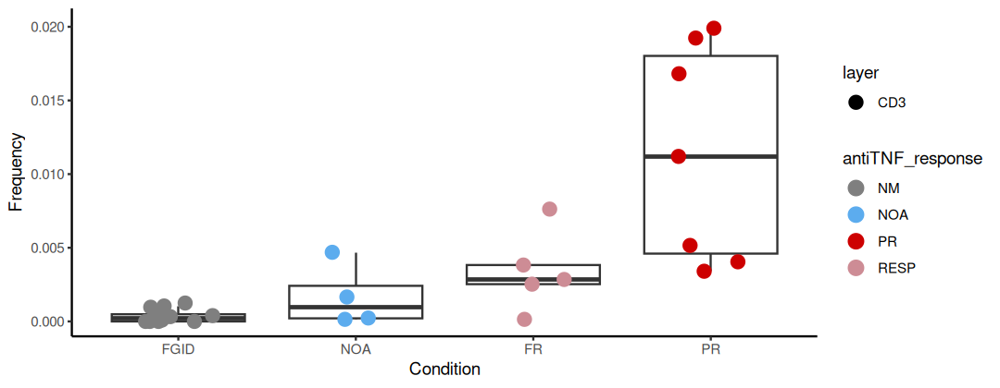

In [36]:
df8 <- md %>% filter(time == "T0D" & disease %in% c("CD","FGID","UC")) %>% group_by(smp_id, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>% 
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!smp_id, names_to = "cd4_ctl", values_to = "freq")

md_to_join <- md %>% dplyr::select(disease, patient, 
                                   time, tissue, time, layer, smp_id,antiTNF_response) %>% unique()

df8  <- left_join(df8, md_to_join, by = "smp_id") %>% unique

options(repr.plot.width=9, repr.plot.height=3.5)

df8 %>% filter(disease %in% c("FGID","CD") & time == "T0D" & cd4_ctl == T) %>% 
ggplot(aes(x = factor(antiTNF_response, levels = c("NM","NOA","RESP","PR"), 
                      labels = c("FGID","NOA","FR","PR")),
           y = freq)) + # you can change the x to whatever variable you're interested in
  geom_boxplot(outlier.shape = NA) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(position=position_jitter(0.2), size = 4, aes(color = antiTNF_response, shape = layer)) + # in aes, you can also use shape or fill (for the shapes that allow it)
 ylab("Frequency") +
  xlab("Condition") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  scale_color_manual(values = c("grey50","steelblue2","red3","lightpink3")) 


In [37]:
df9  <- df8 %>% filter(disease %in% c("FGID","CD") & time == "T0D" & cd4_ctl == T) 

In [38]:
df9

smp_id,cd4_ctl,freq,disease,patient,time,tissue,layer,antiTNF_response
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
p002 T0D BLD CD3,TRUE,1.050298e-03,FGID,p002,T0D,BLD,CD3,NM
p003 T0D BLD CD3,TRUE,0.000000e+00,FGID,p003,T0D,BLD,CD3,NM
p009 T0D BLD CD3,TRUE,0.000000e+00,FGID,p009,T0D,BLD,CD3,NM
p010 T0D BLD CD3,TRUE,4.048583e-03,CD,p010,T0D,BLD,CD3,PR
p011 T0D BLD CD3,TRUE,1.419648e-04,CD,p011,T0D,BLD,CD3,RESP
p014 T0D BLD CD3,TRUE,7.625559e-03,CD,p014,T0D,BLD,CD3,RESP
p016 T0D BLD CD3,TRUE,2.848597e-03,CD,p016,T0D,BLD,CD3,RESP
p017 T0D BLD CD3,TRUE,4.396893e-04,FGID,p017,T0D,BLD,CD3,NM
p018 T0D BLD CD3,TRUE,5.160031e-03,CD,p018,T0D,BLD,CD3,PR


`summarise()` has grouped output by 'smp_id'. You can override using the
`.groups` argument.


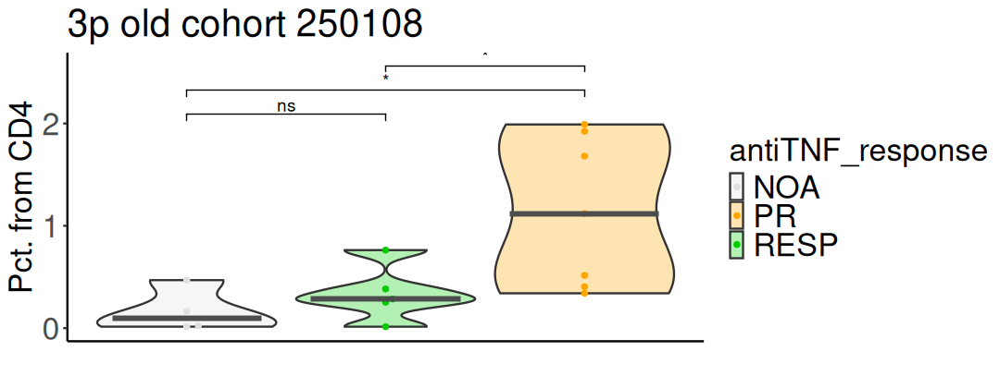

In [141]:
df8 <- md %>% filter(time == "T0D" & disease %in% c("CD","FGID","UC")) %>% group_by(smp_id, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>% 
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!smp_id, names_to = "cd4_ctl", values_to = "freq")

md_to_join <- md %>% dplyr::select(disease, patient, 
                                   time, tissue, time, layer, smp_id,antiTNF_response) %>% unique()

df8  <- left_join(df8, md_to_join, by = "smp_id") %>% unique

options(repr.plot.width=9, repr.plot.height=3.5)

df8 %>% filter(disease %in% c("CD") & time == "T0D" & cd4_ctl == T) %>% 
mutate(antiTNF_response = ifelse(antiTNF_response == "NM","NOA",antiTNF_response))  %>% 
ggplot(aes(x = factor(antiTNF_response, levels = c("NM","NOA","RESP","PR"), 
                      labels = c("FGID","NOA","FR","PR")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antiTNF_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antiTNF_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
 # facet_wrap(~factor(seurat_clusters, levels = 1:11), scales = "free", ncol = 11) +
#  facet_wrap(~tissue, scales = "free") +

  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "3p old cohort 250108") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif", method = "t.test") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red",
                             "RESP" = "green3")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red",
                            "RESP" = "green3")) + ggtheme()


In [315]:
ggsave("figures/boxplot_freq_blood_3p_21/250108_cd4_ctl_atnf.svg", width = 12, height = 9, units = "cm", create.dir = T)
ggsave("figures/boxplot_freq_blood_3p_21/250108_cd4_ctl_atnf.png", width = 12, height = 9, units = "cm")

In [6]:
blood_3p  <- readRDS("../241201_VN_PREDICT2/data/3p_blood_2021/blood_3p_integrated_stacas_sample.rds")

# Blood 5p integrated by participant

In [5]:
blood_5p  <- readRDS("../241201_VN_PREDICT2/data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



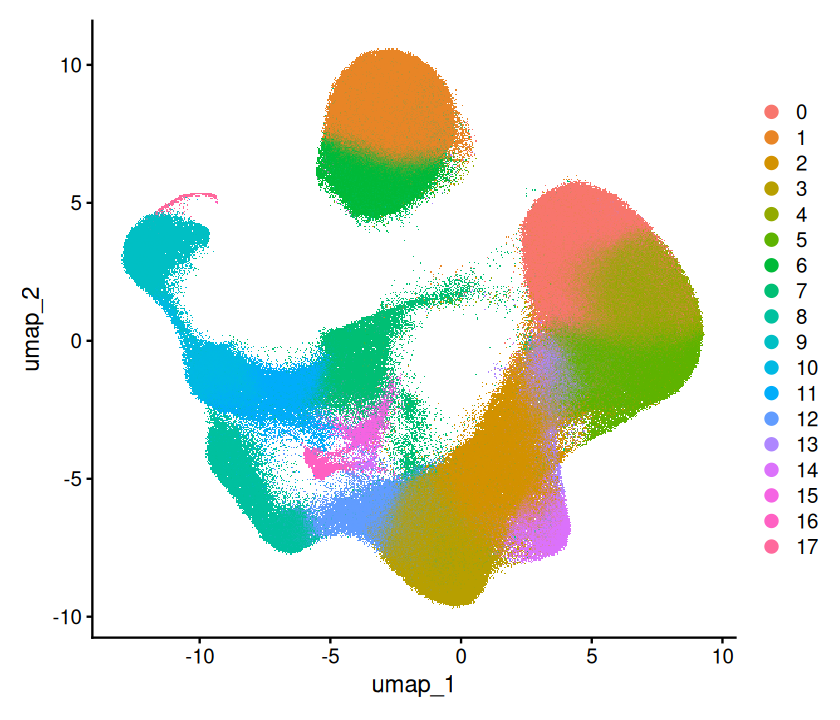

In [4]:
options(repr.plot.width = 7, repr.plot.height = 6)

DimPlot(blood_5p)

In [293]:
blood_5p <- FindClusters(blood_5p, res = c(0.6, 0.7))

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 593574
Number of edges: 13475632

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8947
Number of communities: 15
Elapsed time: 772 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 593574
Number of edges: 13475632

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8866
Number of communities: 18
Elapsed time: 751 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



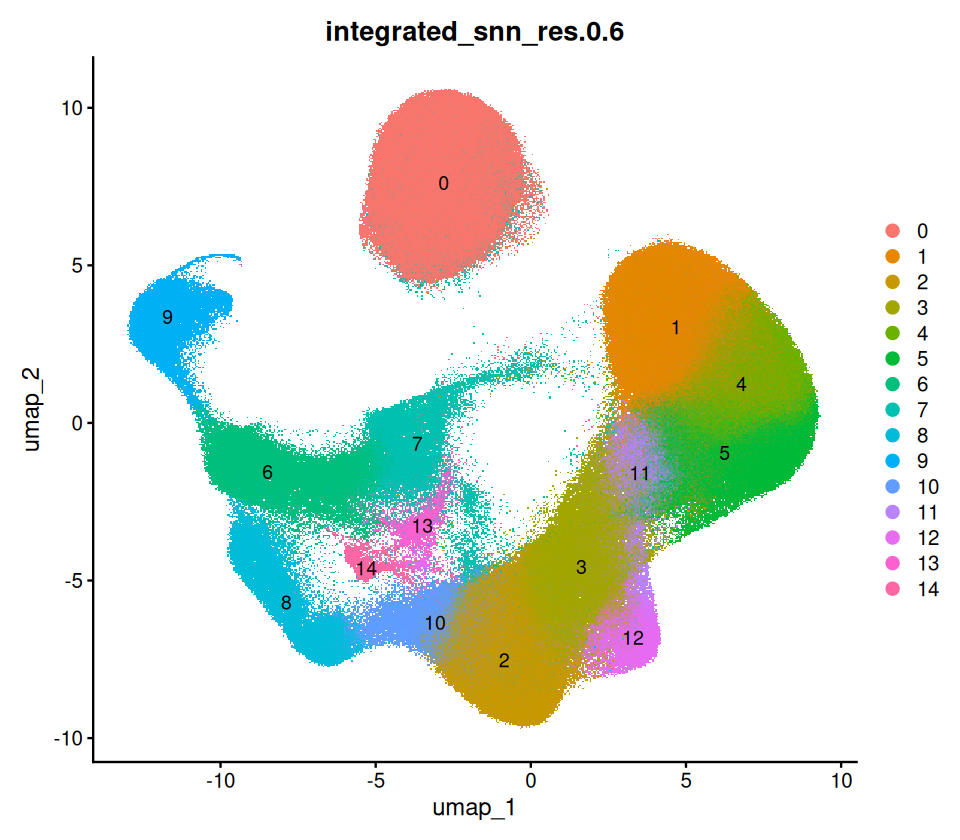

In [325]:
options(repr.plot.width = 8, repr.plot.height = 7)

DimPlot(blood_5p, group.by = "integrated_snn_res.0.6", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



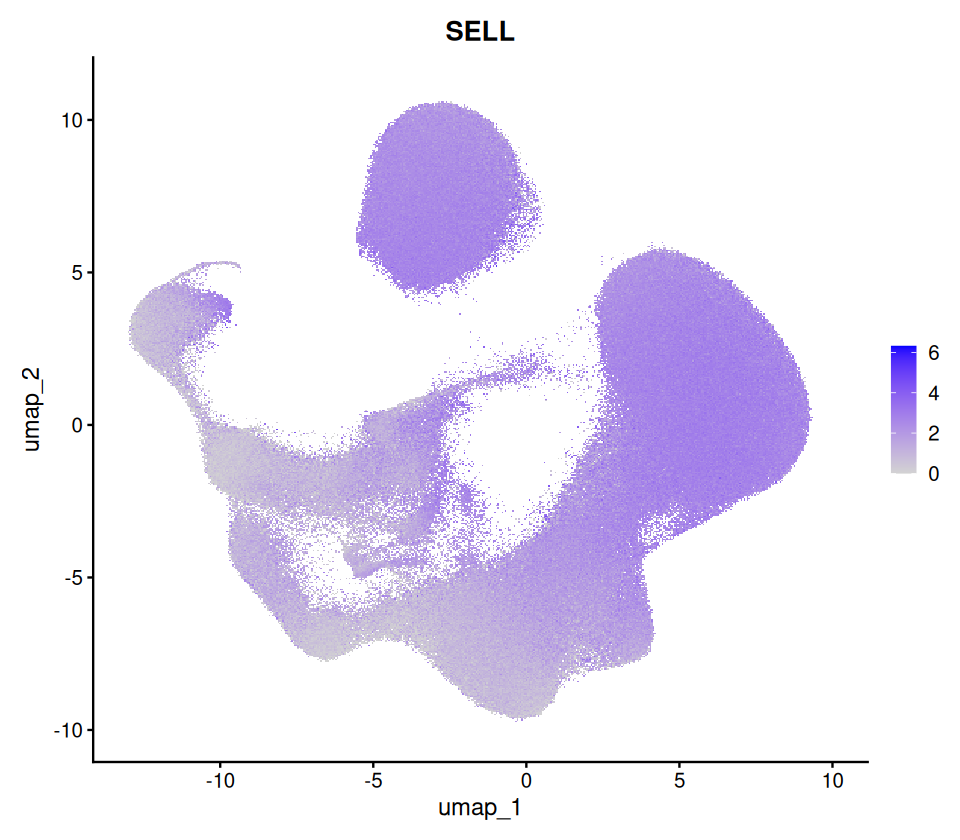

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



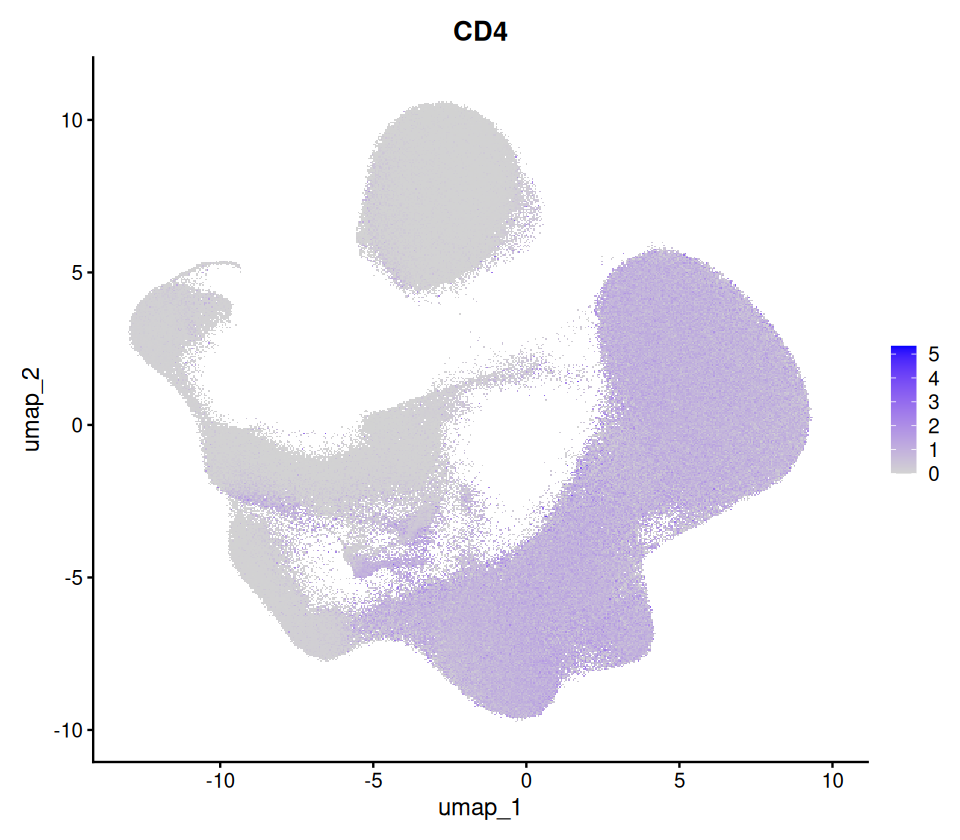

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



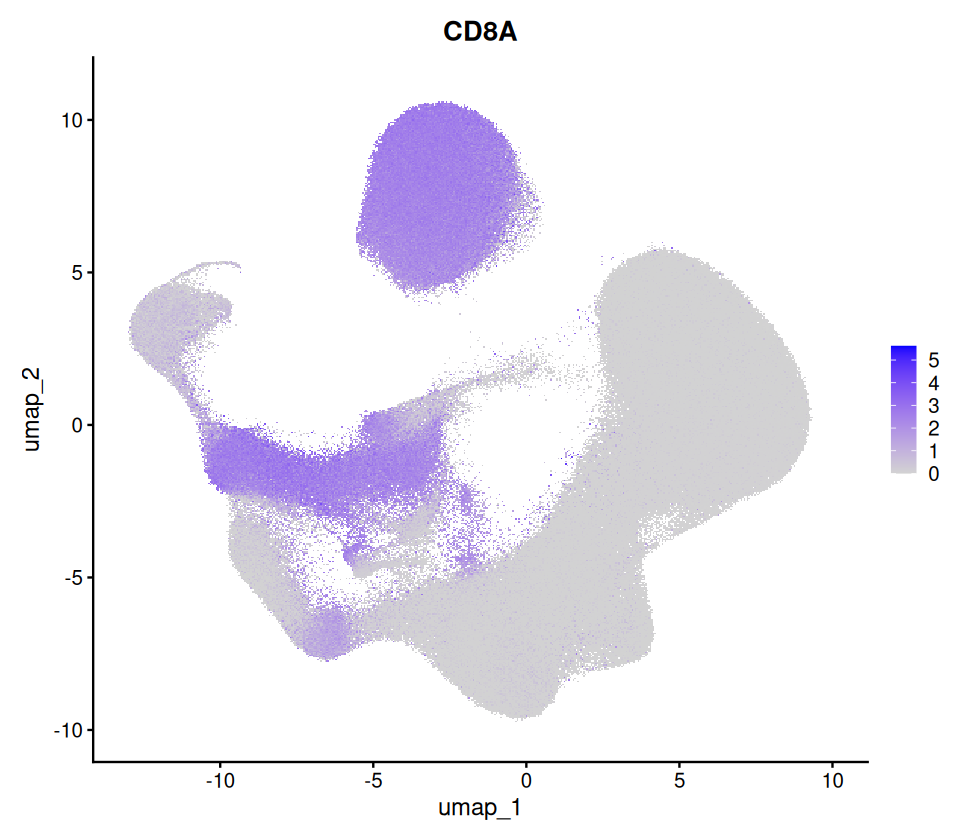

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



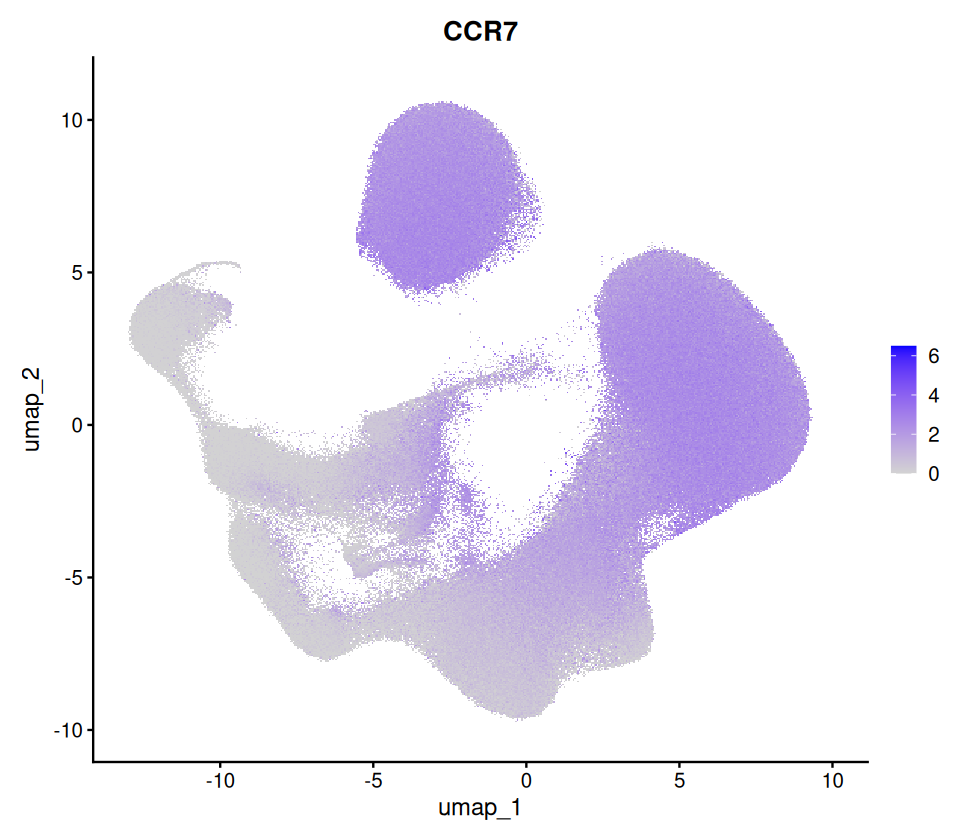

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



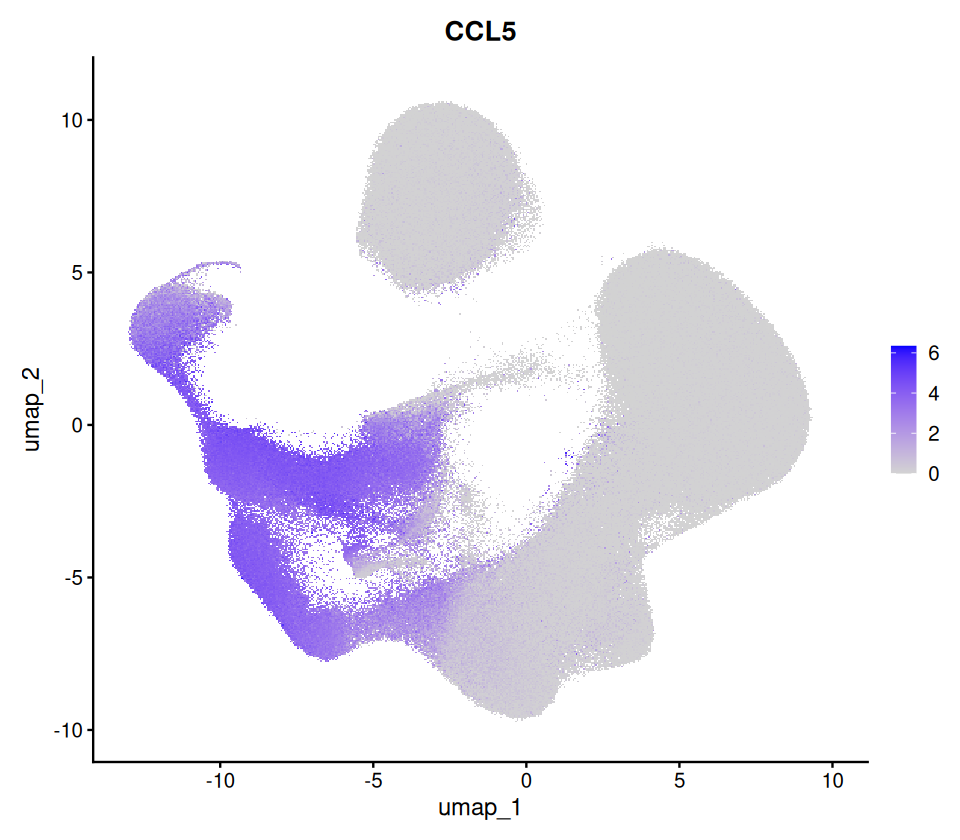

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



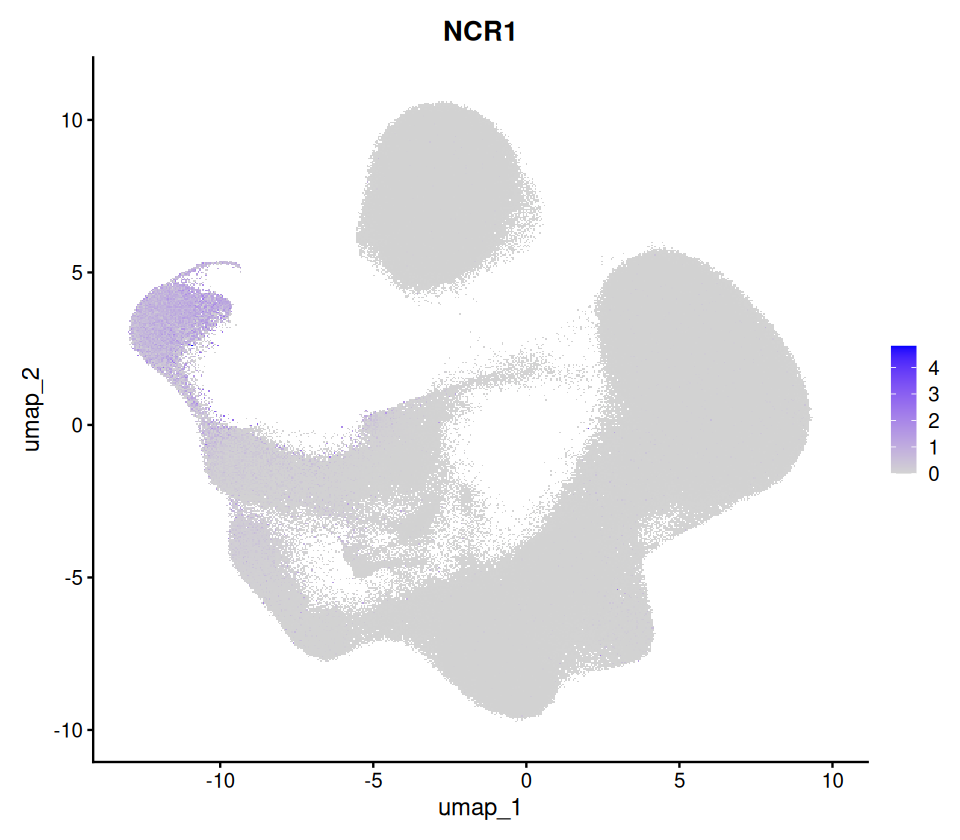

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



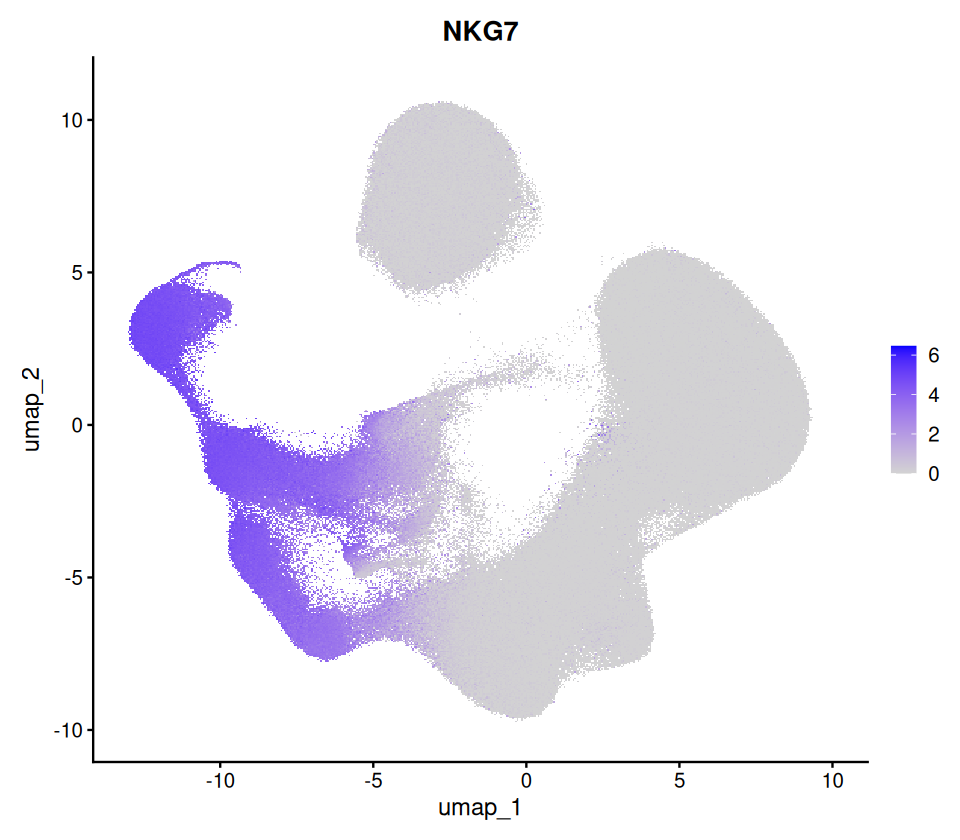

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



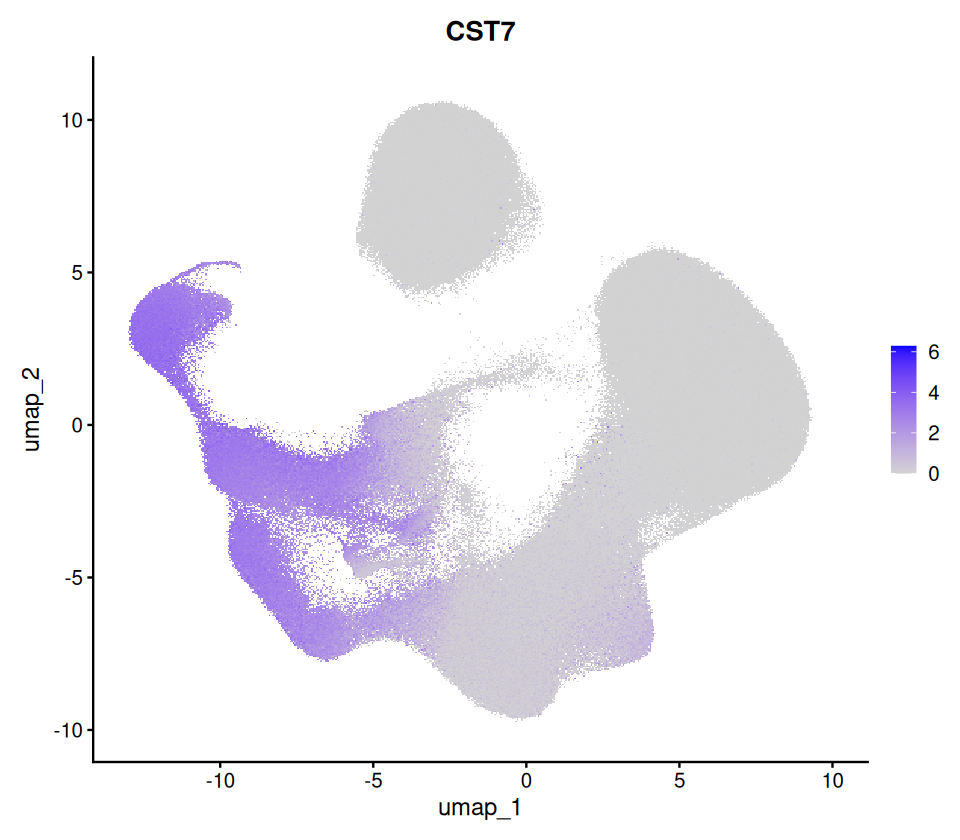

Warning message:
“Could not find MKI67 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



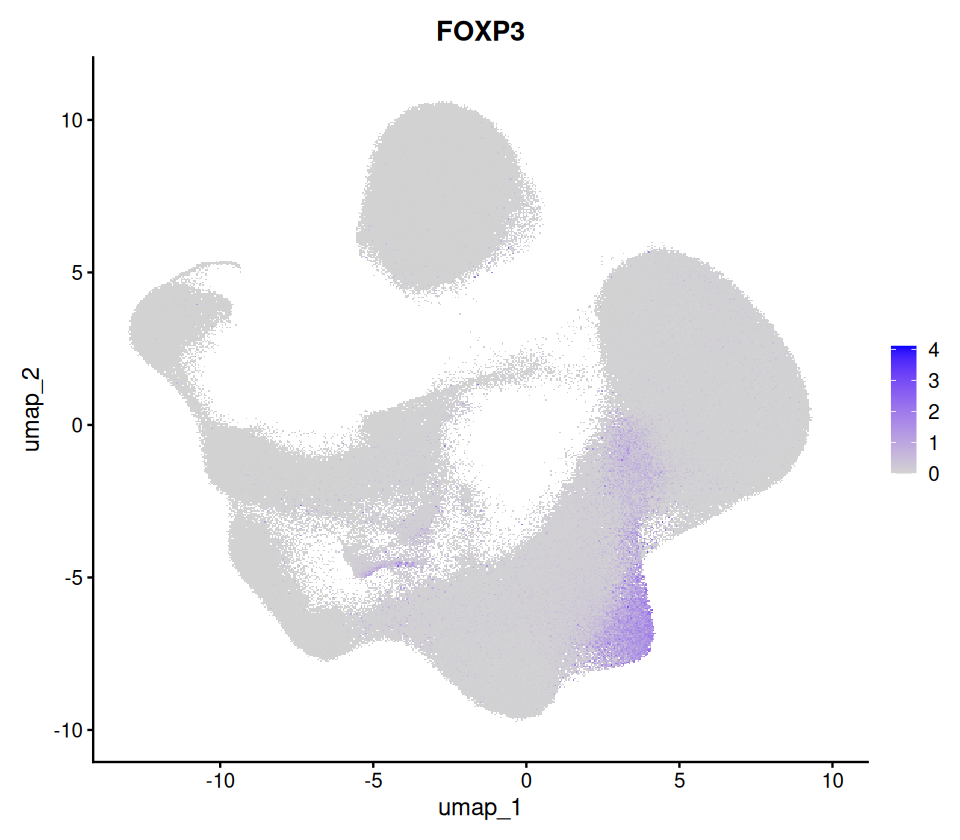

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



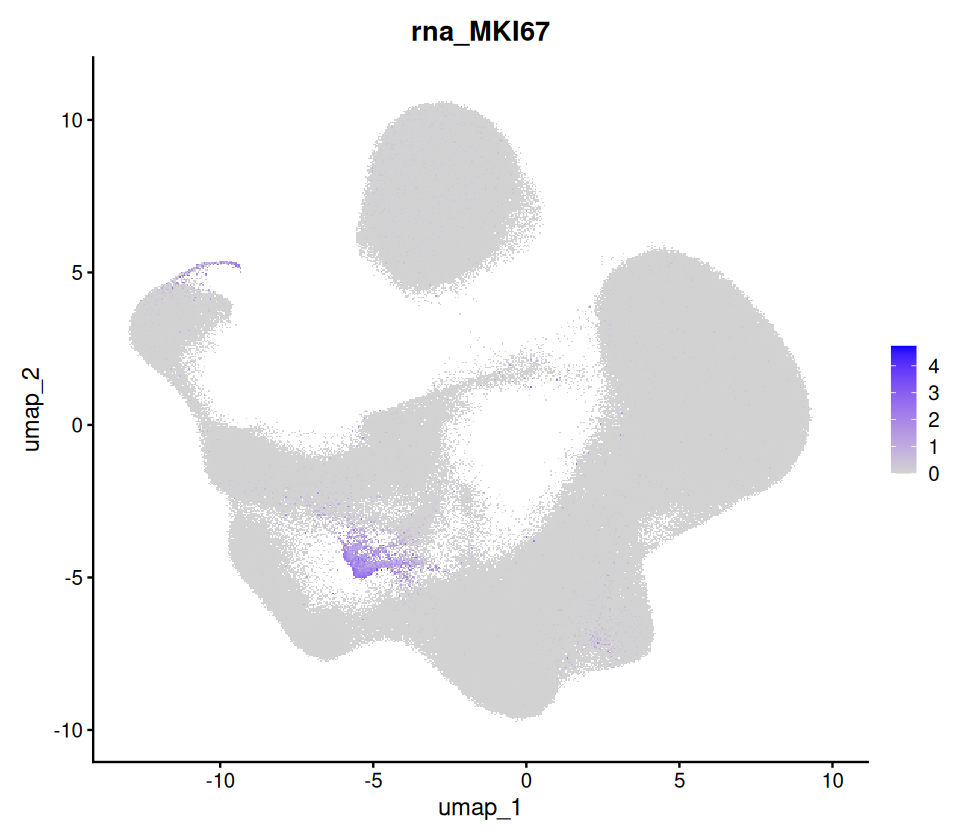

Warning message:
“Could not find IL26 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



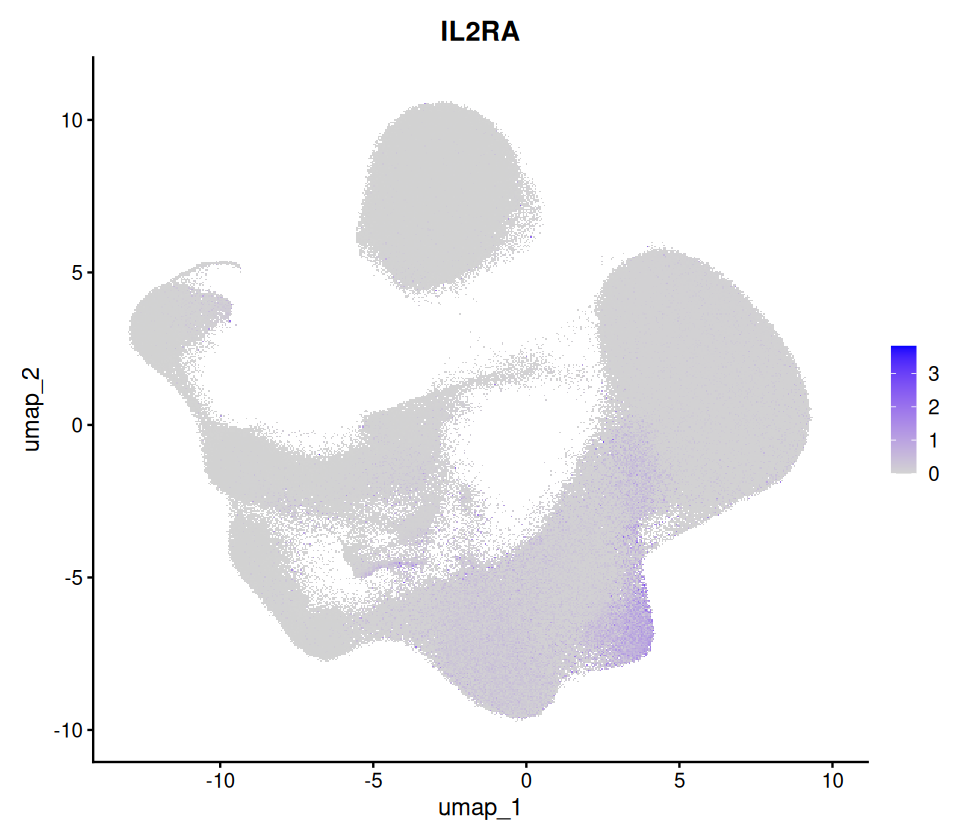

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



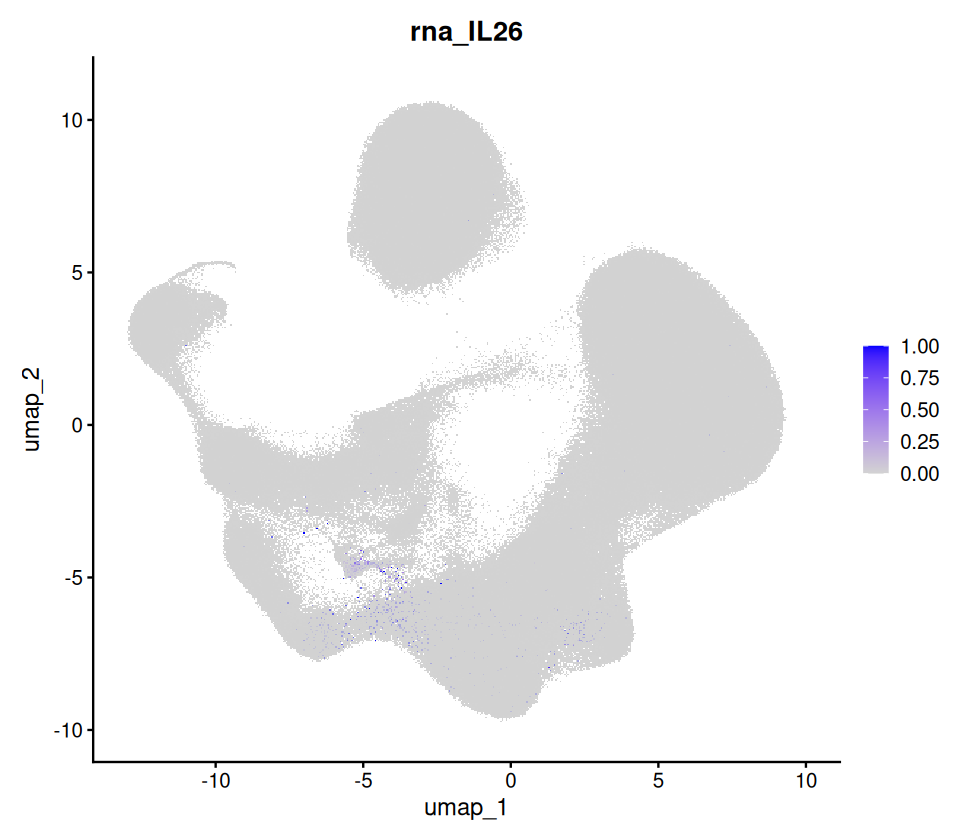

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



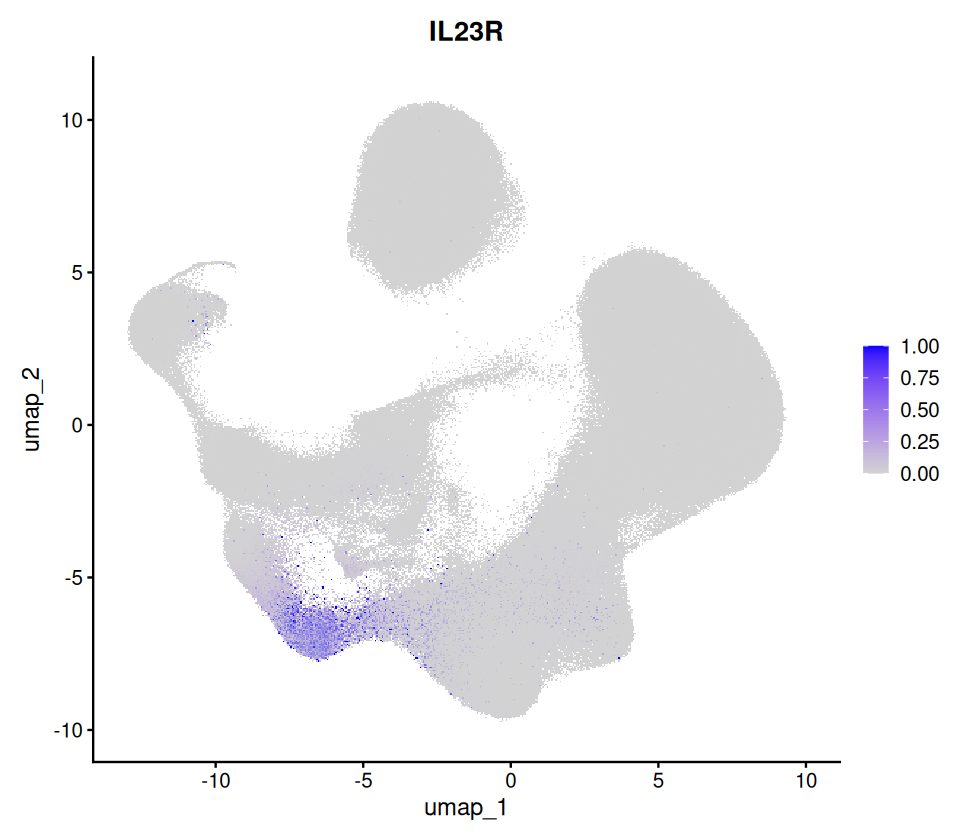

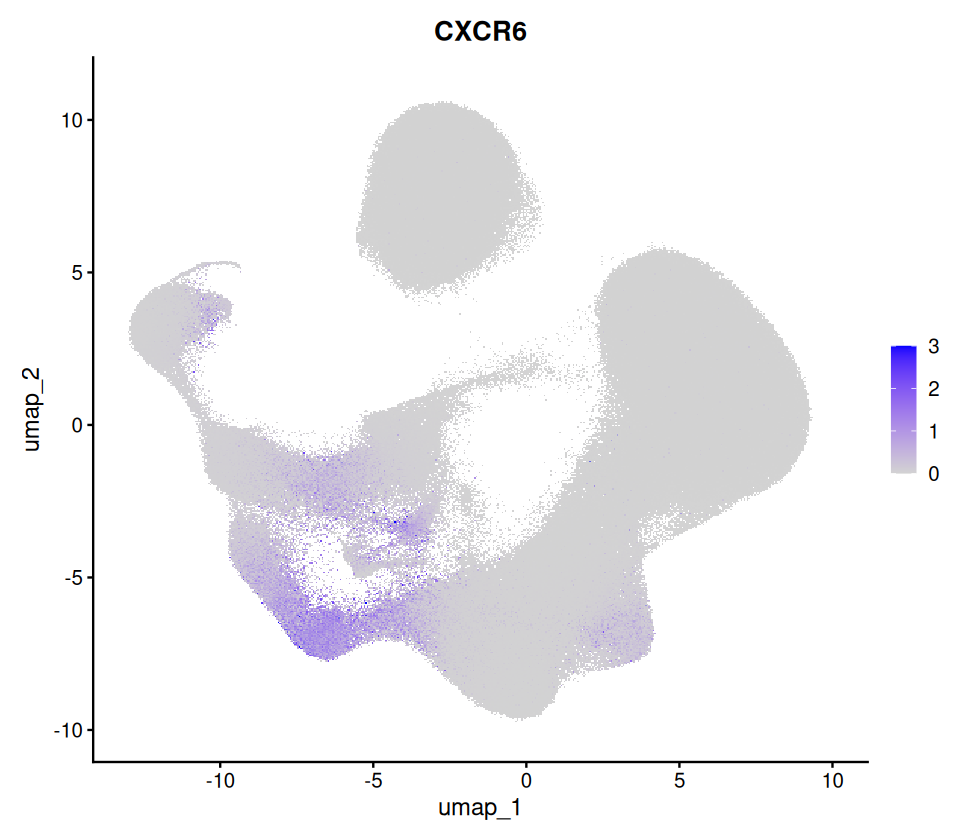

In [321]:
FeaturePlot(blood_5p, features= c("SELL"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("CD4"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("CD8A"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("CCR7"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("CCL5"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("NCR1"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("NKG7"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("CST7"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("FOXP3"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("MKI67"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("IL2RA"), min.cutoff = 0)
FeaturePlot(blood_5p, features= c("IL26"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(blood_5p, features= c("IL23R"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(blood_5p, features= c("CXCR6"), min.cutoff = 0, max.cutoff = 3)


Warning message:
“Could not find IL26 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



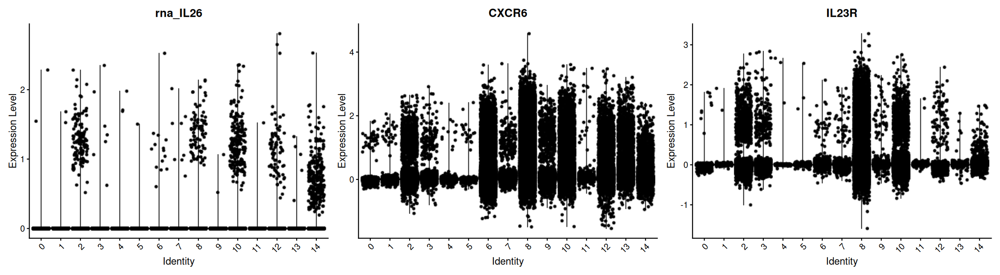

In [324]:
options(repr.plot.width = 20, repr.plot.height = 5.5)
VlnPlot(blood_5p, features = c("IL26","CXCR6","IL23R"), ncol = 3, group.by = "integrated_snn_res.0.6")

## Annotations of clusters

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



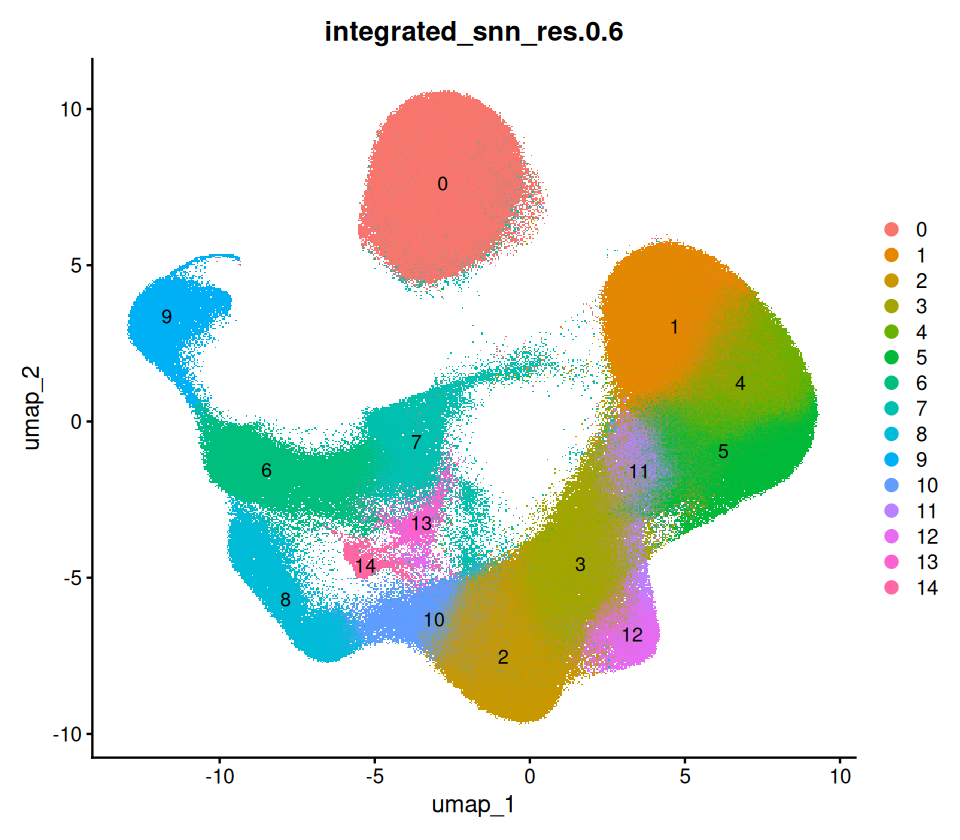

In [6]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(blood_5p, label = T, group.by = "integrated_snn_res.0.6")

In [5]:
blood_5p@meta.data <- blood_5p@meta.data  %>% mutate(seurat_clusters2 = recode_factor(integrated_snn_res.0.6, 
                                                                              "0" = '1',
                                                                               "1" = "2",
                                                                               "2" = "4",
                                                                               "3" = "3",
                                                                               "4" = "2",
                                                                               "5" = "2",
                                                                               "6" = "8",
                                                                               "7" = "7",
                                                                               "8" = "10",
                                                                               "9" = "9",
                                                                               "10" = "11",
                                                                               "11" = "5",
                                                                               "12" = "6",
                                                                               "13" = "12",
                                                                               "14" = "13"))

In [6]:
pallete_blood  <- c(
"1" =  "#89b8da",
"2" =  "#F1CE63",
"3" =  '#D39200',
"4" =  '#AAA300',
"5" =  'indianred2',
"6" =  '#FF61C9',
"7" =  '#00B6EB',
"8" =  '#00BFC2',
"9" =  '#00C08C',
"10" =  "#9D7660" ,
"11" =  '#6DB100',
"12" =  '#D4A6C8',
"13" =  '#B07AA1'
)


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



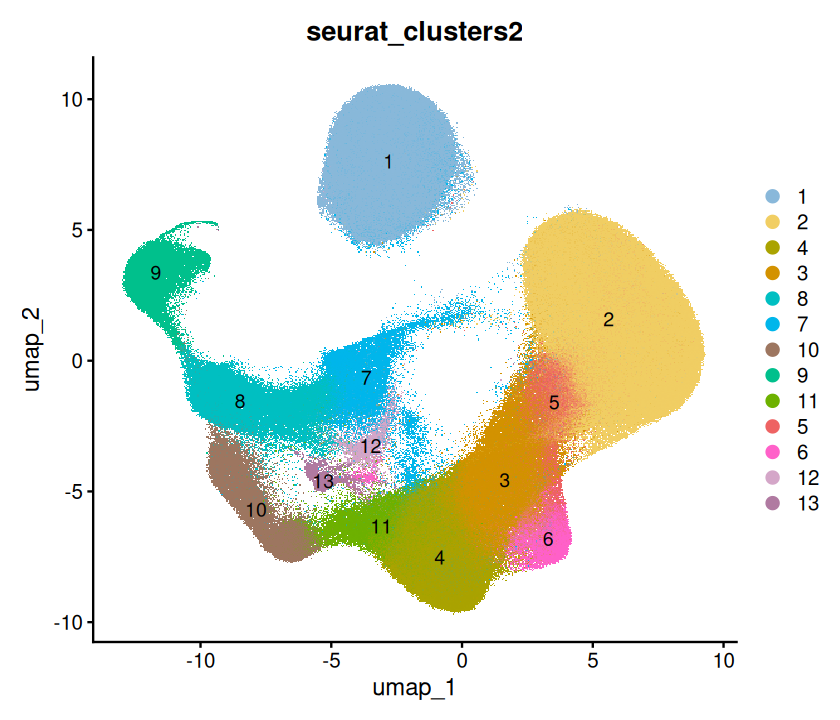

In [7]:
DimPlot(blood_5p, label = T, group.by = "seurat_clusters2", cols = pallete_blood)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



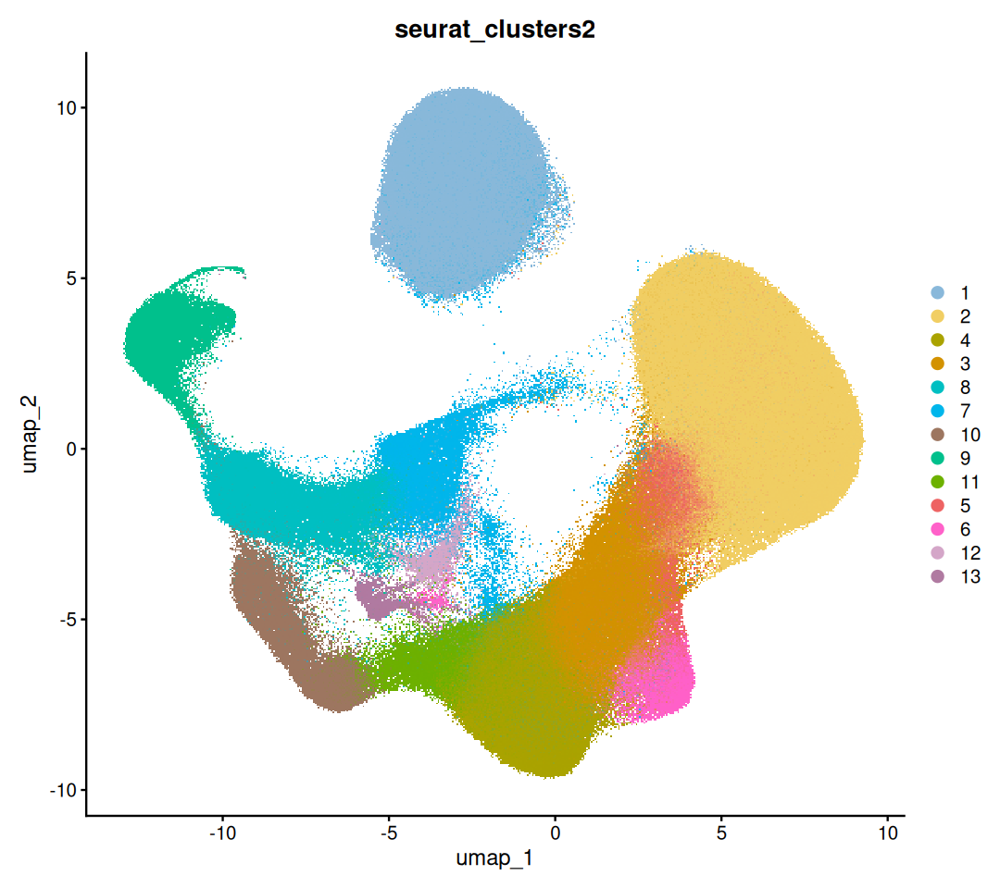

In [531]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(blood_5p, label = F, group.by = "seurat_clusters2", cols = pallete_blood)

In [571]:
blood_5p@misc$col_pal  <- c(
"1" =  "#89b8da",
"2" =  "#F1CE63",
"3" =  '#D39200',
"4" =  '#AAA300',
"5" =  'indianred2',
"6" =  '#FF61C9',
"7" =  '#00B6EB',
"8" =  '#00BFC2',
"9" =  '#00C08C',
"10" =  "#9D7660" ,
"11" =  '#6DB100',
"12" =  '#D4A6C8',
"13" =  '#B07AA1'
)


In [8]:
blood_5p@meta.data <- blood_5p@meta.data  %>% mutate(annotations = recode_factor(seurat_clusters2, 
                                                                               "1" = "CD8_Naive",
                                                                               "2" = "CD4_Naive",
                                                                               "3" = "CD4_Central_Memory",
                                                                               "4" = "CD4_Teff_Th2",
                                                                               "5" = "CD4_Treg_Naive",
                                                                               "6" = "CD4_Treg_Activated",
                                                                               "7" = "CD8_Central_Memory",
                                                                               "8" = "CD8_Effector_Memory",
                                                                               "9" = "NK_cells",
                                                                               "10" = "CD8_Tgd",
                                                                                "11" = "CD4_Teff_Th1/Th17",
                                                                                "12" = "ISAGhi",
                                                                                "13" = "Proliferating"))

In [572]:
saveRDS(blood_5p, "data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

In [574]:
blood_5p

An object of class Seurat 
19054 features across 593574 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

## Heatmap of cluster markers

In [547]:
markers3  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              
              "FOXP3", "IKZF2","IL2RA","CTLA4",
    "IFIT1","ISG15","OAS3","IRF7",
              "IL4","IL13",'IL5',  "GATA3",
              "CCR6", 'CXCR3',"IL17F","IL26","TNF",'RORA',"RORC" ,'IL22',
              "IL23R","CXCR6","KLRB1","ZBTB16","CCL5","EOMES", "IFNG",
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
              
               "IL17A",'IL21',"MKI67", "PCNA", "MCM6")

In [548]:
avgexp3 = AverageExpression(blood_5p, features = markers3, group.by = "seurat_clusters2",
                          assay = "RNA")

In [552]:
colnames(avgexp3$RNA)

[1] "g1"  "g2"  "g4"  "g3"  "g8"  "g7"  "g10" "g9"  "g11" "g5"  "g6"  "g12"
[13] "g13"

In [ ]:
1,2,6,4,10,11,12,3,9,7,5,8,13

In [ ]:
1,2,7,3,5,6,12,4,11,10,8,9,13

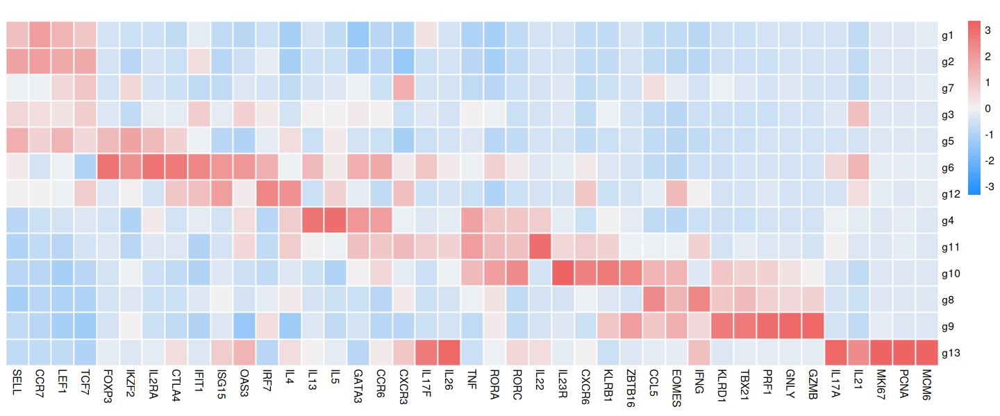

In [565]:
options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA)[c(1,2,6,4,10,11,12,3,9,7,5,8,13),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [547]:
markers3  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              
              "FOXP3", "IKZF2","IL2RA","CTLA4",
    "IFIT1","ISG15","OAS3","IRF7",
              "IL4","IL13",'IL5',  "GATA3",
              "CCR6", 'CXCR3',"IL17F","IL26","TNF",'RORA',"RORC" ,'IL22',
              "IL23R","CXCR6","KLRB1","ZBTB16","CCL5","EOMES", "IFNG",
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
              
               "IL17A",'IL21',"MKI67", "PCNA", "MCM6")

In [548]:
avgexp3 = AverageExpression(blood_5p, features = markers3, group.by = "seurat_clusters2",
                          assay = "RNA")

In [552]:
colnames(avgexp3$RNA)

[1] "g1"  "g2"  "g4"  "g3"  "g8"  "g7"  "g10" "g9"  "g11" "g5"  "g6"  "g12"
[13] "g13"

In [ ]:
1,2,6,4,10,11,12,3,9,7,5,8,13

In [ ]:
1,2,7,3,5,6,12,4,11,10,8,9,13

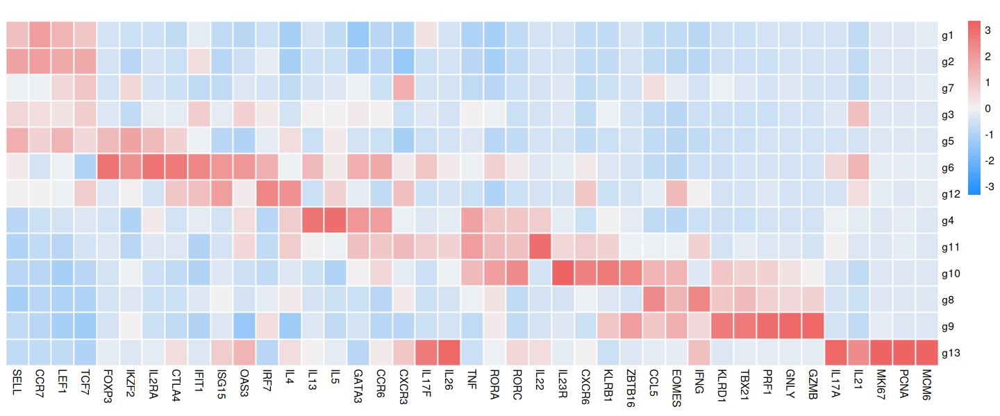

In [565]:
options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA)[c(1,2,6,4,10,11,12,3,9,7,5,8,13),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [567]:
pheatmap::pheatmap(t(avgexp3$RNA)[c(1,2,6,4,10,11,12,3,9,7,5,8,13),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 12, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood_part2.pdf")

## Markers with CD4 CTL subsluster

In [14]:
blood_5p@meta.data  <- blood_5p@meta.data  %>% 
mutate(seurat_clusters3 = if_else(cd4_ctl == TRUE, "CD4_CTL", seurat_clusters2))

In [15]:
blood_5p$seurat_clusters3  %>% table

.
      1      10      11      12      13       2       3       4       5       6 
 106441   25271   15721    4840    3882  196865   57801   62393   17024   12014 
      7       8       9 CD4_CTL 
  27184   39620   22902    1616 

In [17]:
markers3  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              
              "FOXP3", "IKZF2","IL2RA","CTLA4",
    "IFIT1","ISG15","OAS3","IRF7",
              "IL4","IL13",'IL5',  "GATA3",
              "CCR6", 'CXCR3',"IL17F","IL26","TNF",'RORA',"RORC" ,'IL22',
              "IL23R","CXCR6","KLRB1","ZBTB16","CCL5","EOMES", "IFNG",
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
              
               "IL17A",'IL21',"MKI67", "PCNA", "MCM6")

In [18]:
avgexp3 = AverageExpression(blood_5p, features = markers3, group.by = "seurat_clusters3",
                          assay = "RNA")

Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.
First group.by variable `seurat_clusters3` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


In [19]:
markers1  <- rev(c("CD3E","CD3D","CD4","CD8A","CD8B","TRDV2","TRGV9","FCER1G","NCR1"))

In [20]:
avgexp1 = AverageExpression(blood_5p, features = markers1, group.by = "seurat_clusters3",
                          assay = "RNA")

In [21]:
colnames(avgexp3$RNA)

[1] "g1"      "g10"     "g11"     "g12"     "g13"     "g2"      "g3"     
 [8] "g4"      "g5"      "g6"      "g7"      "g8"      "g9"      "CD4-CTL"

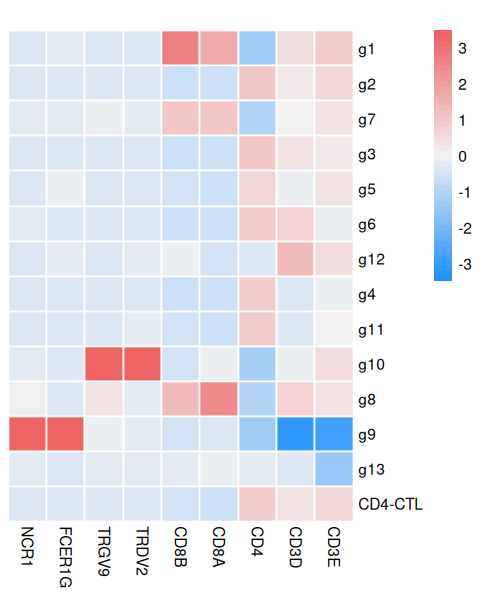

In [24]:
options(repr.plot.width = 4, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp1$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [25]:
options(repr.plot.width = 4, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp1$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 4, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood_part1_with_cd4_ctl.pdf")

In [ ]:
options(repr.plot.width = 4, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp1$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [23]:
colnames(avgexp3$RNA)

[1] "g1"      "g10"     "g11"     "g12"     "g13"     "g2"      "g3"     
 [8] "g4"      "g5"      "g6"      "g7"      "g8"      "g9"      "CD4-CTL"

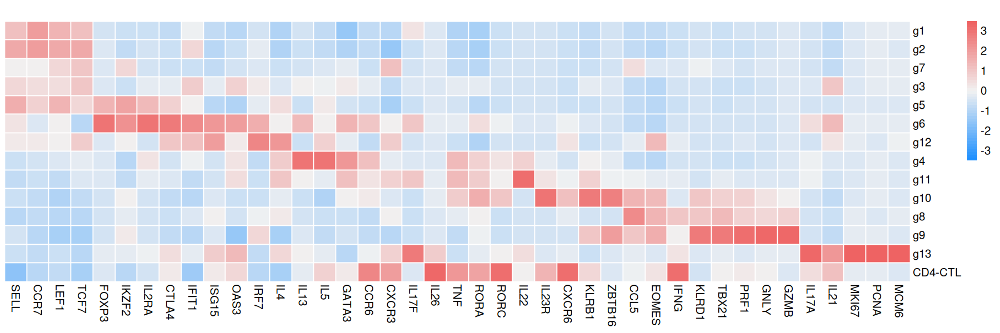

In [65]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 4, height = 4,
                  fontsize = 12)

In [26]:
markers3  <- c('LEF1', 'TCF7', 'SELL', 'CCR7', 'FOXP3', 'IKZF2', 'IL2RA', 'CTLA4', 'IFIT1', 'ISG15', 'IRF7',
              "IL4",'IL5',"IL13","GATA3",  
              'IL22','CXCR3',"CCR6", "CCR6","TNF","RORA","CXCR3",
                             "IL23R","KLRB1","ZBTB16","CCL5","EOMES", 
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
               "MKI67", "PCNA", "MCM6","IL17F", "IL17A",'IL21',
               "CXCR6","RORC","IL26","IFNG"
               

              
              )

In [27]:
avgexp3 = AverageExpression(blood_5p, features = markers3, group.by = "seurat_clusters3",
                          assay = "RNA")

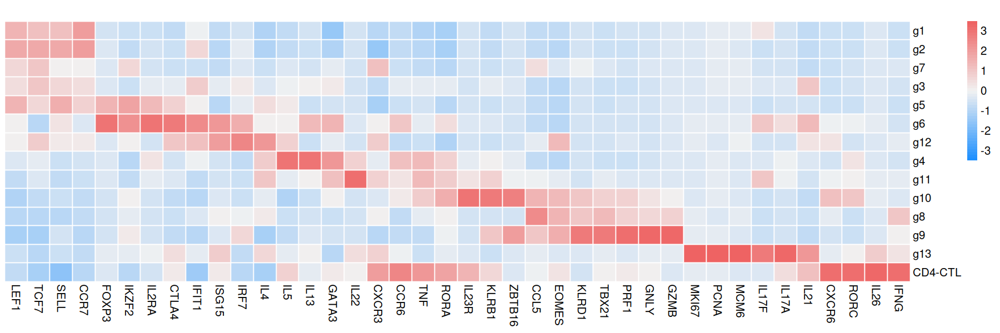

In [28]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp3$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 4, height = 4,
                  fontsize = 12)

In [33]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp3$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 10, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood_partv2.pdf")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



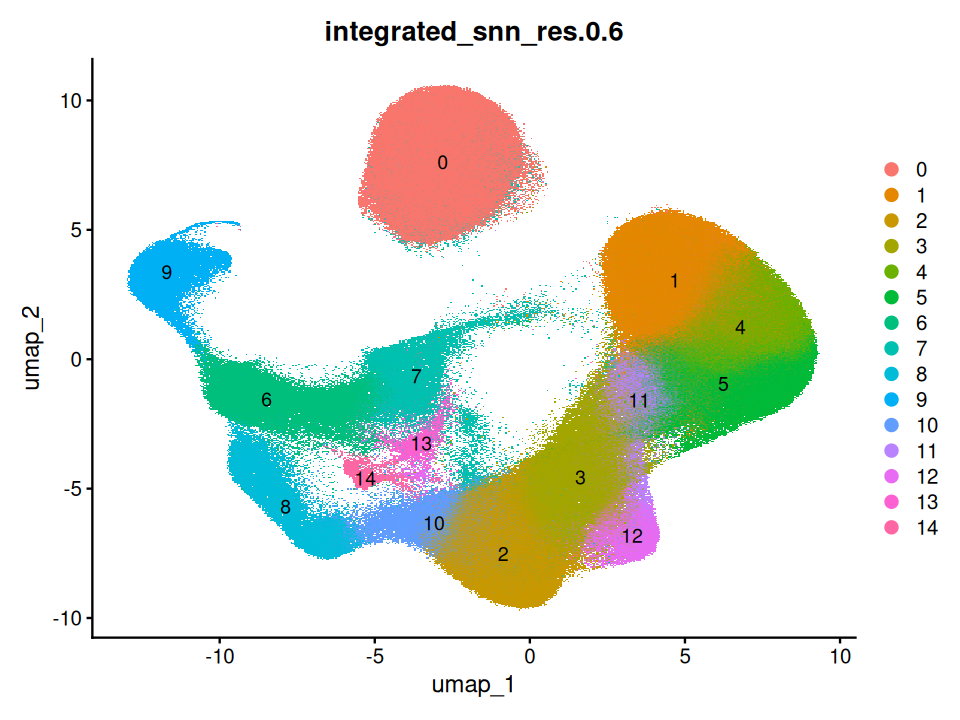

In [36]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(blood_5p, group.by = "integrated_snn_res.0.6", label = T)

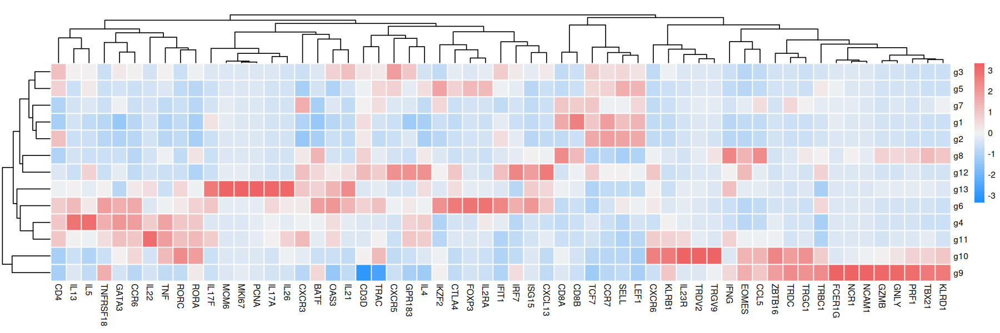

In [533]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [370]:
table(blood_5p$seurat_clusters2, blood_5p$participant_id)

    
     001-009 001-011 001-014 001-015 001-018 001-019 001-022 001-023 001-024
  1     1301    1520    1315     900    1438    1696    1953    1337    1153
  2     2573    4270    1877    3057    4277    5742    5335    2414    4310
  4      551     653     370     578    2385    1226    1865    1776    1415
  3      442     651     410     721    3790    1287    1533    1684    1332
  8      597     404     109    1016     151     968     452     433     208
  7      209     547     237     491     787     909     847     604     318
  10     193      94     153     383     200     734     403     821     151
  9      492      67      46      38      30     318     377      18     321
  11     130     276      39     180     337     564     412     457     186
  5      279     631      65     261     586     473     350     215     438
  6       86      93      62     130     166     239     208     260     204
  12      63      41      20      78      80     105     110     117   

## Subclustering

In [37]:
blood_subclust  <- subset(blood_5p, integrated_snn_res.0.6 %in% c(10,14))

In [38]:
merged_ds <- SplitObject(blood_subclust, split.by = "version_10x")

merged.list <- lapply(X = merged_ds, FUN = function(x) {
DefaultAssay(x)  <- "RNA"
x$barcode  <- colnames(x)
x <- NormalizeData(x)
x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 800)
})

blood_subclust <- Run.STACAS(merged.list, dims = 1:12, k.weight = 70)
blood_subclust <- RunUMAP(blood_subclust, dims = 1:12) 
blood_subclust <- FindNeighbors(blood_subclust)
blood_subclust <- FindClusters(blood_subclust, res = c(0.5))


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the STACAS package.
  Please report the issue to the authors.”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Preparing PCA embeddings for objects...

Building integration tree with base dataset: 3

Merging dataset 1 into 3

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 2 into 3 1

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“The 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 21219
Number of edges: 618811

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8492
Number of communities: 11
Elapsed time: 5 seconds


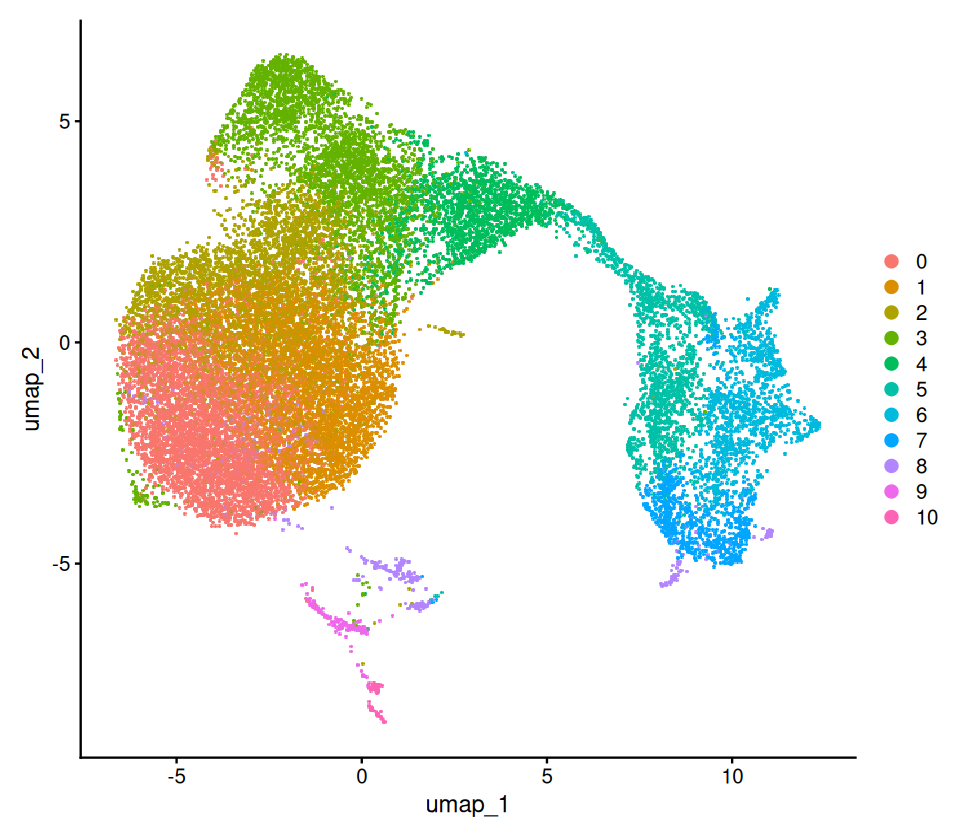

In [39]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(blood_subclust, label = F, raster = T, raster.dpi = c(600,600), pt.size = 2)

In [40]:
saveRDS(blood_subclust, "data/5p_blood_2024/blood_subclust_5p.rds")

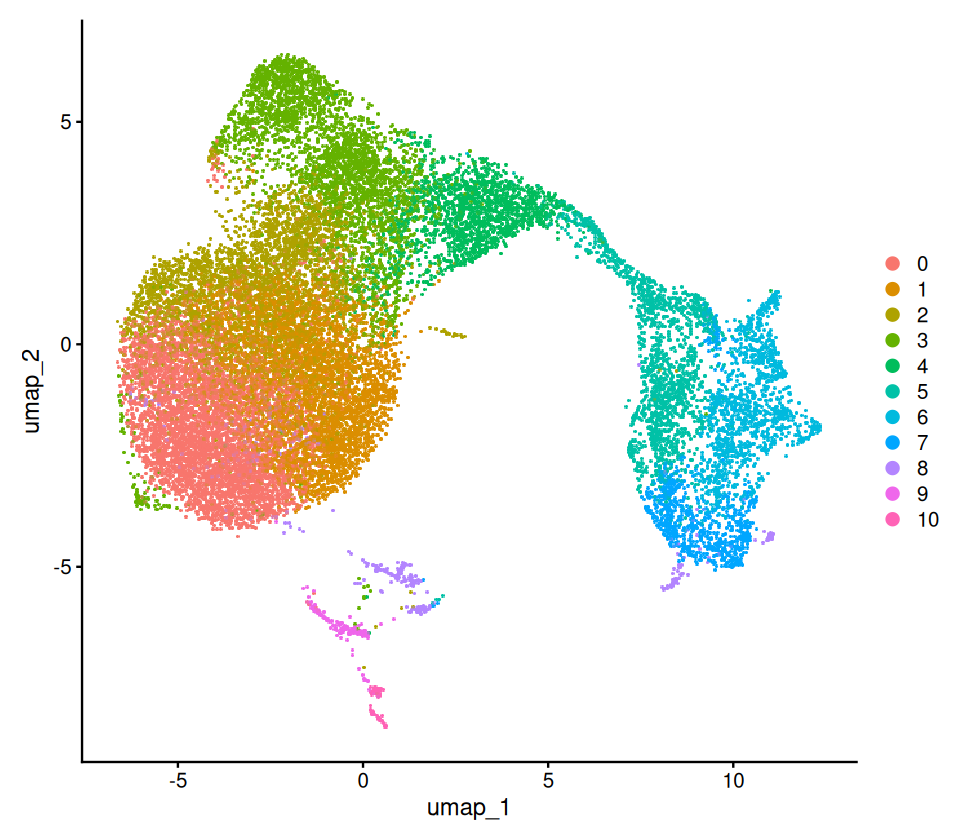

In [40]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(blood_subclust, label = F, raster = T, raster.dpi = c(600,600), pt.size = 2)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



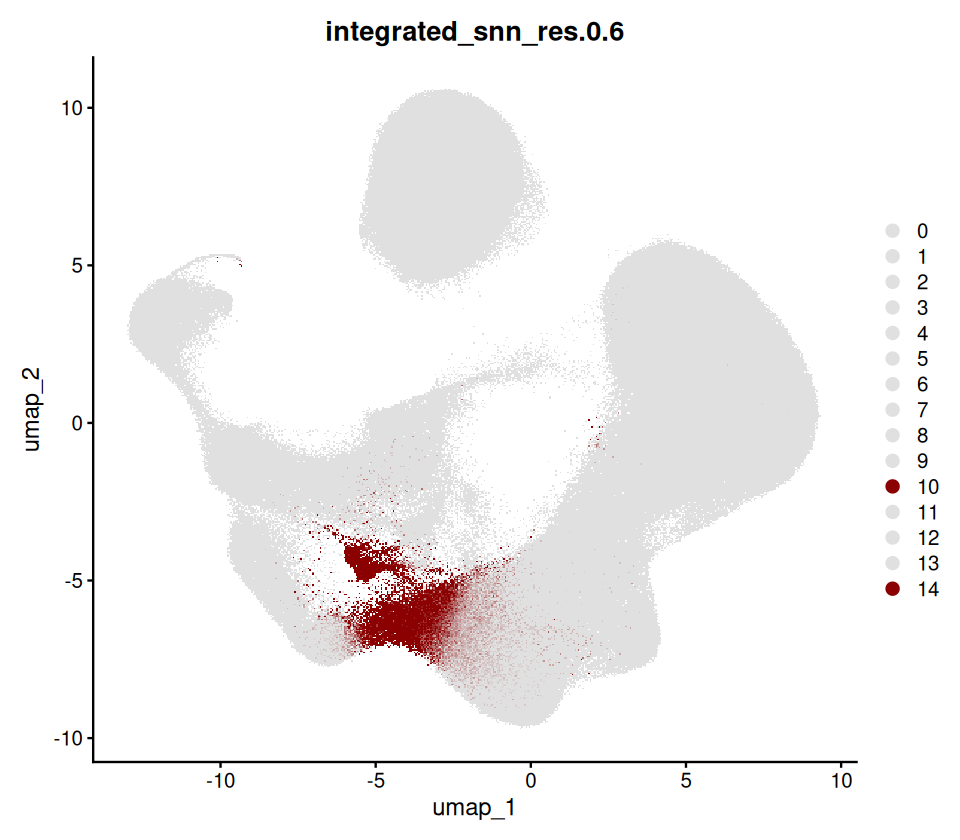

In [43]:
DimPlot(blood_5p, group.by = "integrated_snn_res.0.6", cols = c(rep("grey88", times = 10),"darkred",
                                                                rep("grey88", times = 3),"darkred"))

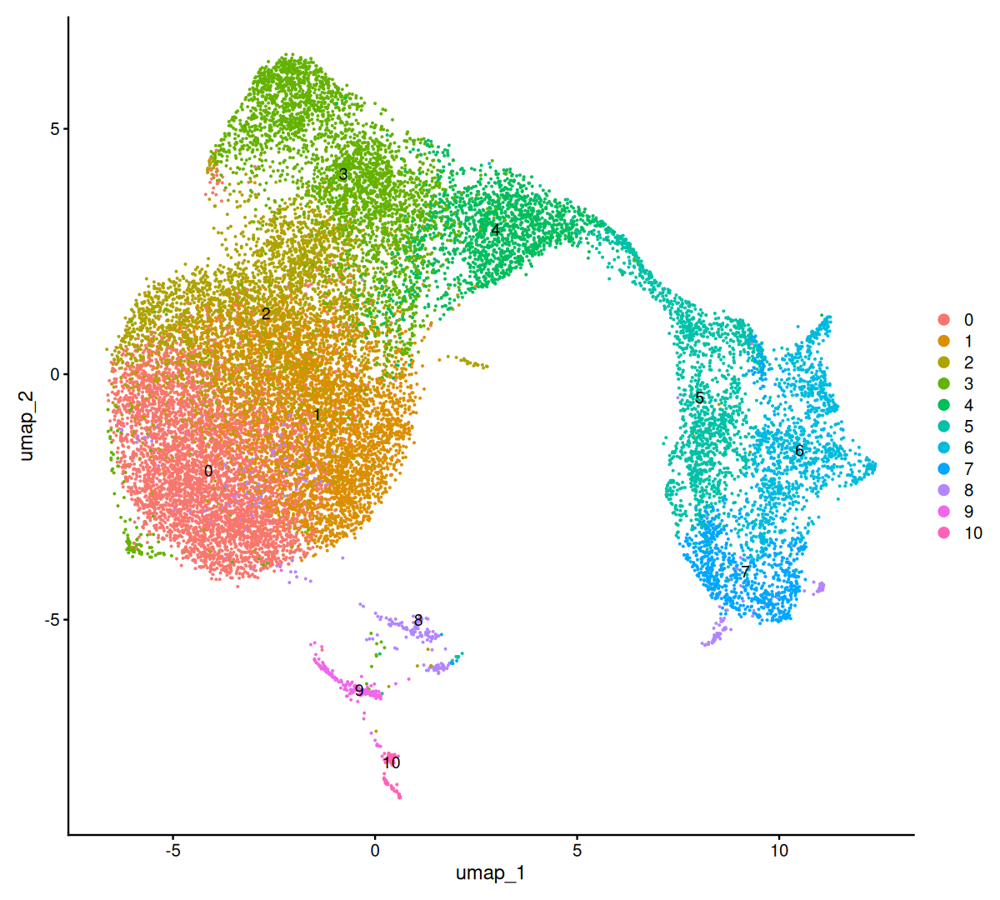

In [338]:
DimPlot(blood_subclust, label = T)

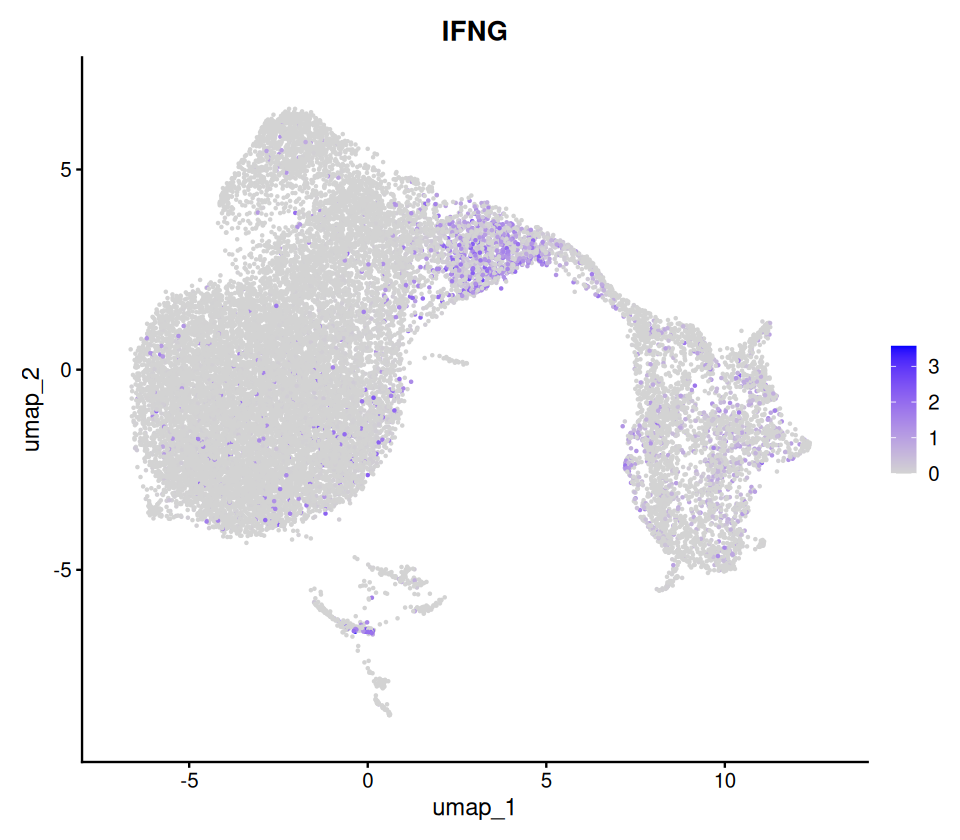

In [45]:
FeaturePlot(blood_subclust, features = "IFNG", min.cutoff = 0)

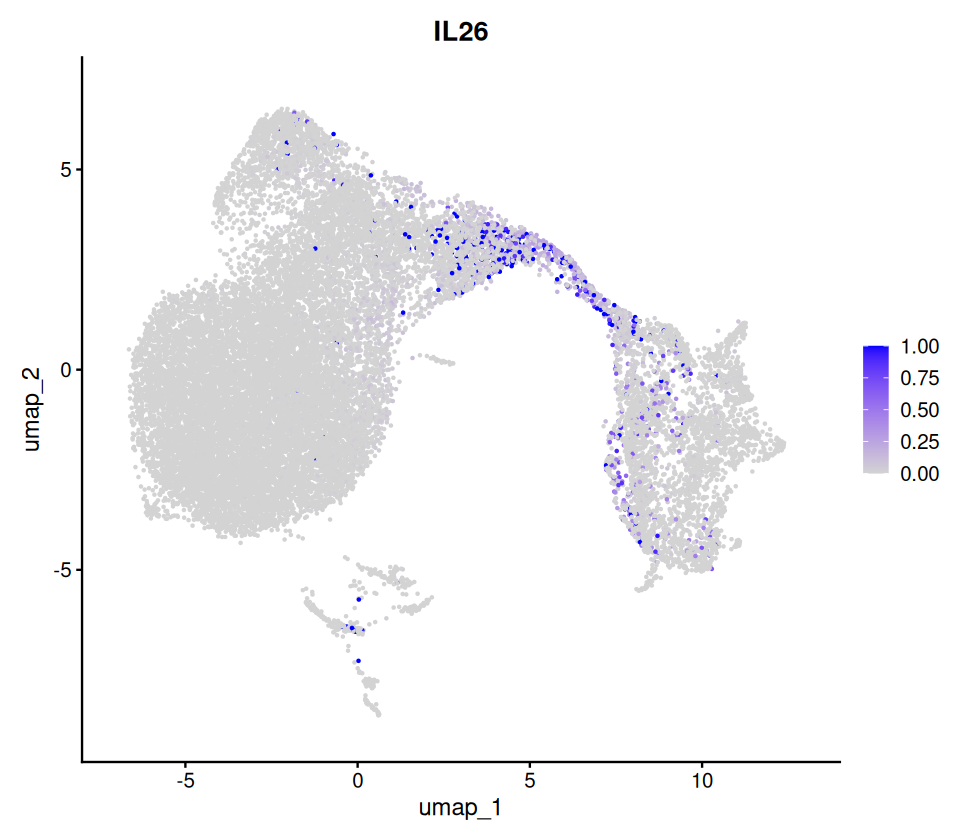

In [47]:
FeaturePlot(blood_subclust, features = "IL26", min.cutoff = 0, max.cutoff = 1)

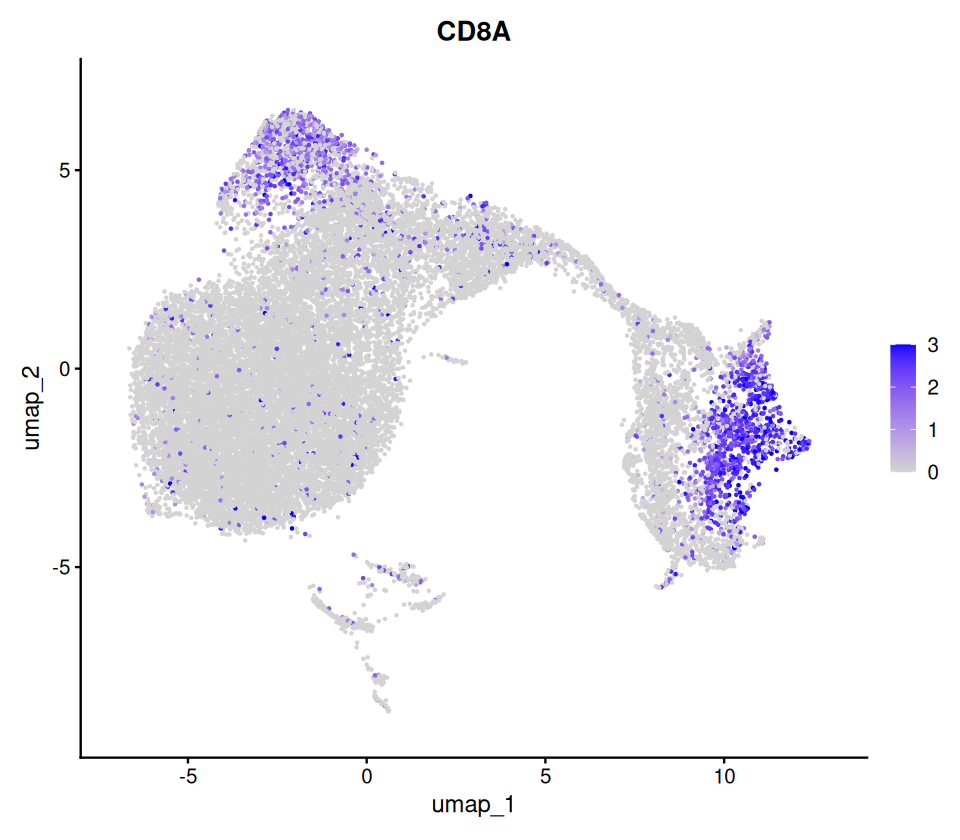

In [146]:
options(repr.plot.width = 8, repr.plot.height = 7)
FeaturePlot(blood_subclust, features = "CD8A", min.cutoff = 0, max.cutoff = 3)

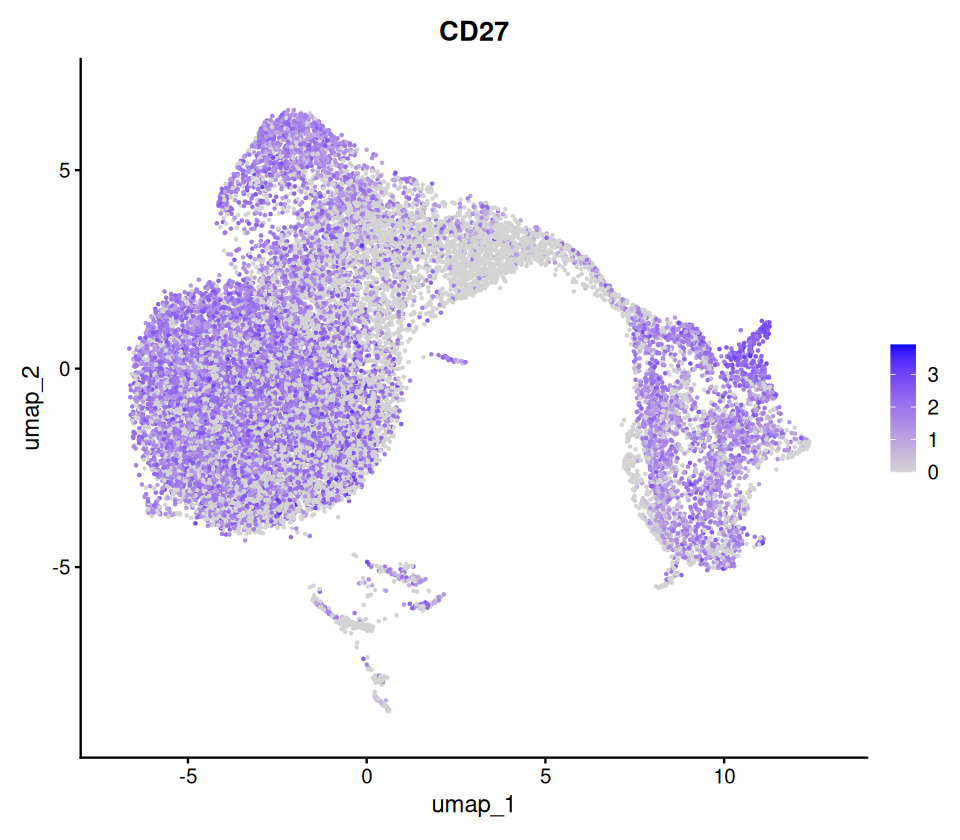

In [169]:
FeaturePlot(blood_subclust, features = "CD27", min.cutoff = 0)

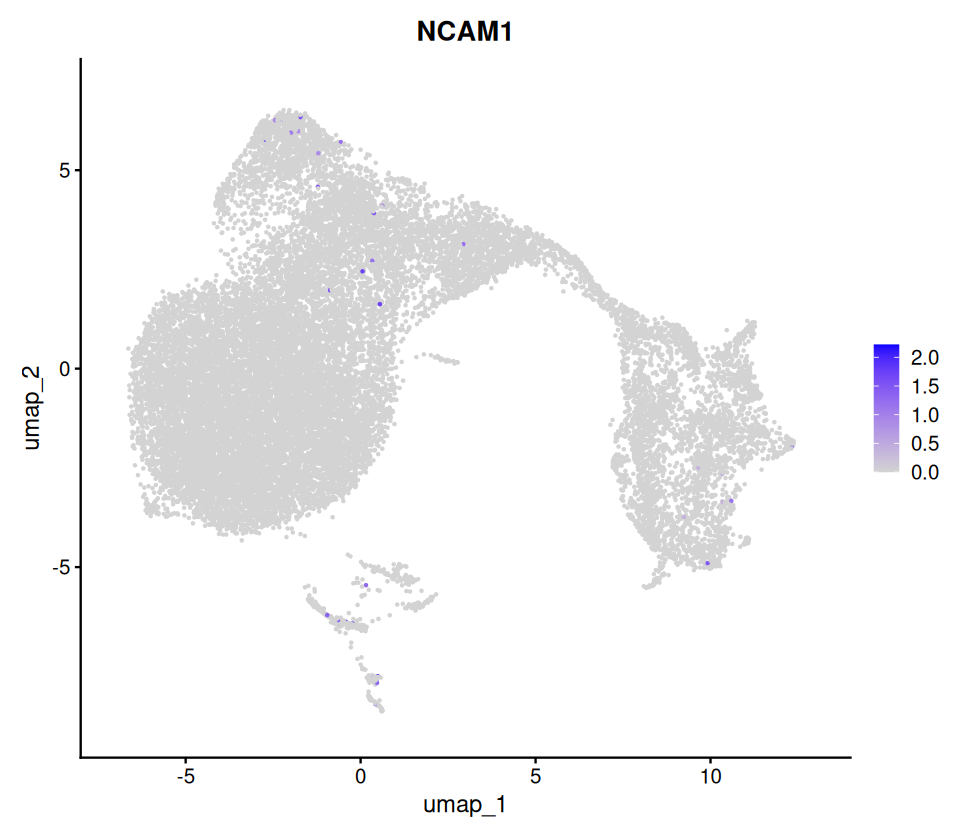

In [164]:
FeaturePlot(blood_subclust, features = "NCAM1", min.cutoff = 0)

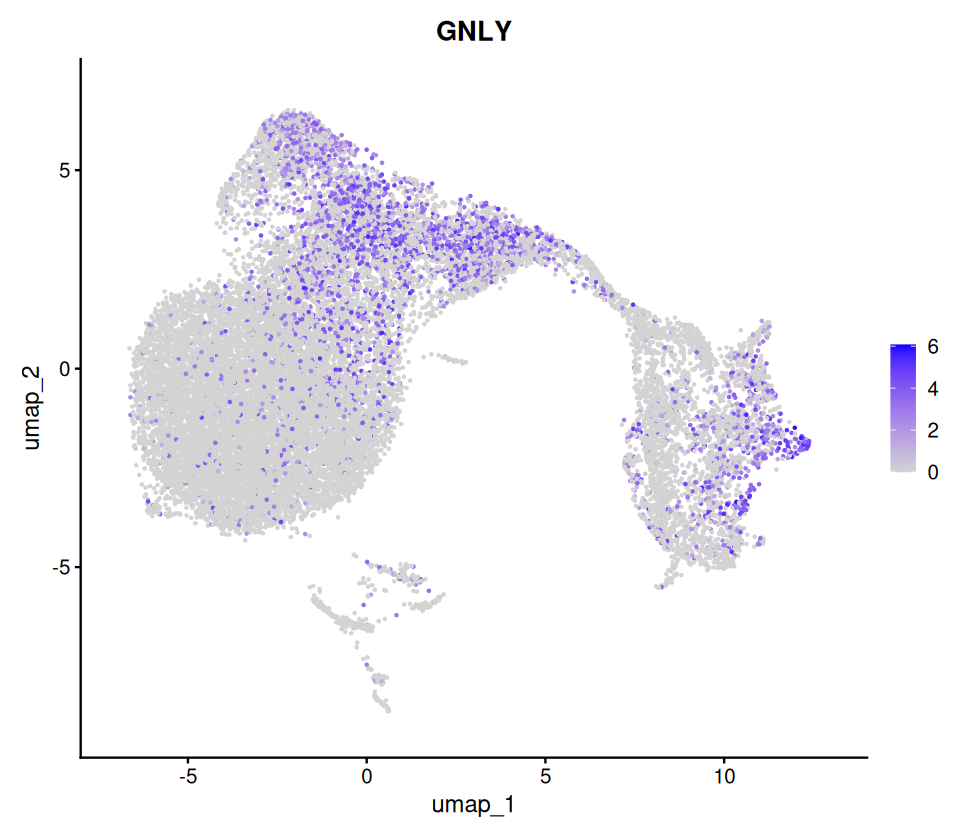

In [163]:
FeaturePlot(blood_subclust, features = "GNLY", min.cutoff = 0)

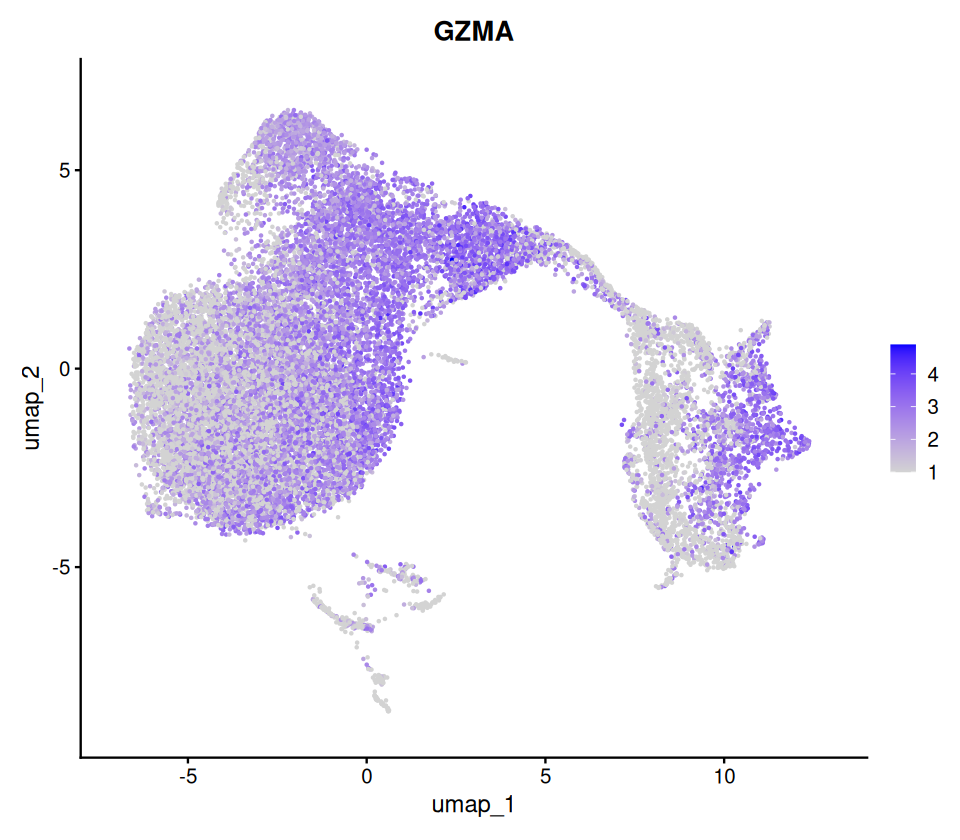

In [168]:
FeaturePlot(blood_subclust, features = "GZMA", min.cutoff = 1)

Warning message:
“Could not find CD4 in the default search locations, found in ‘RNA’ assay instead”


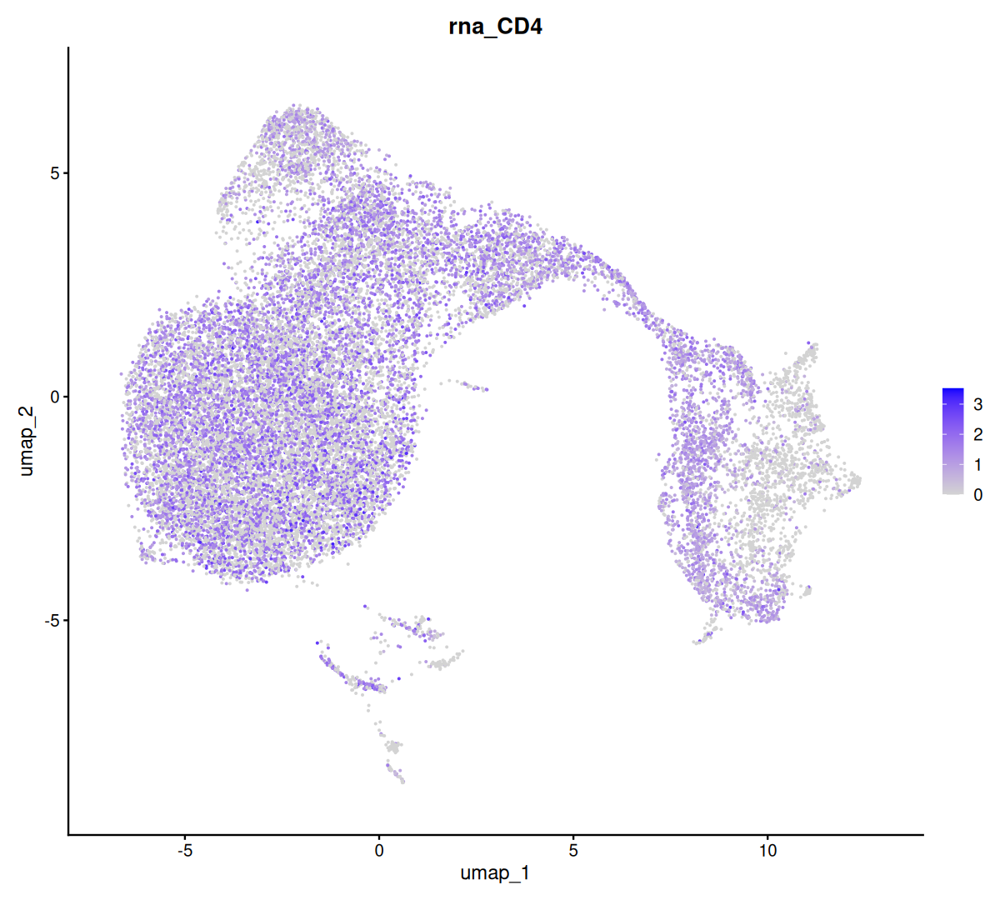

In [342]:
FeaturePlot(blood_subclust, features = "CD4", min.cutoff = 0)

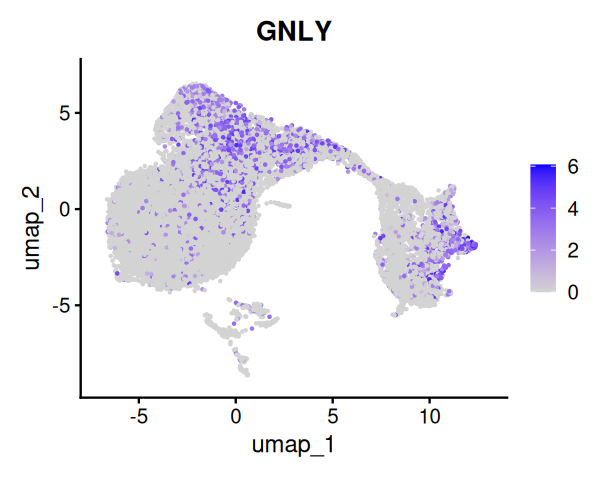

In [138]:
FeaturePlot(blood_subclust, features = "GNLY", min.cutoff = 0)

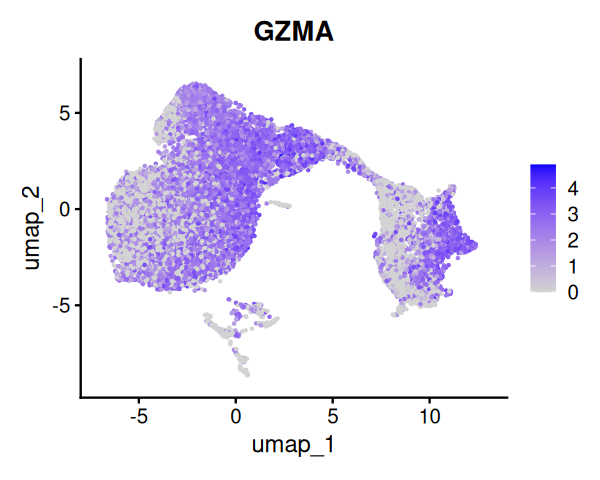

In [141]:
FeaturePlot(blood_subclust, features = "GZMA", min.cutoff = 0)

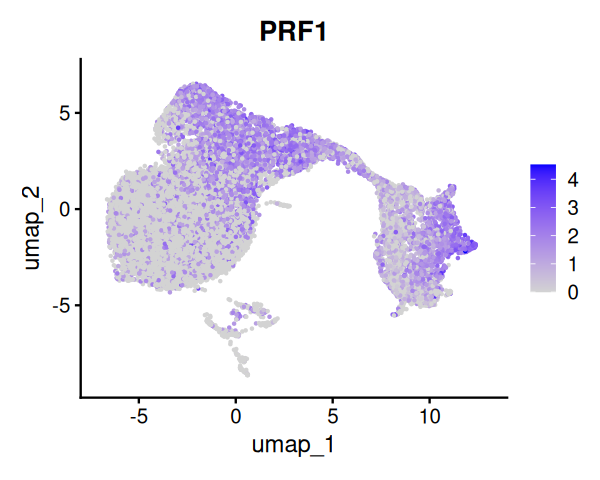

In [140]:
FeaturePlot(blood_subclust, features = "PRF1", min.cutoff = 0)

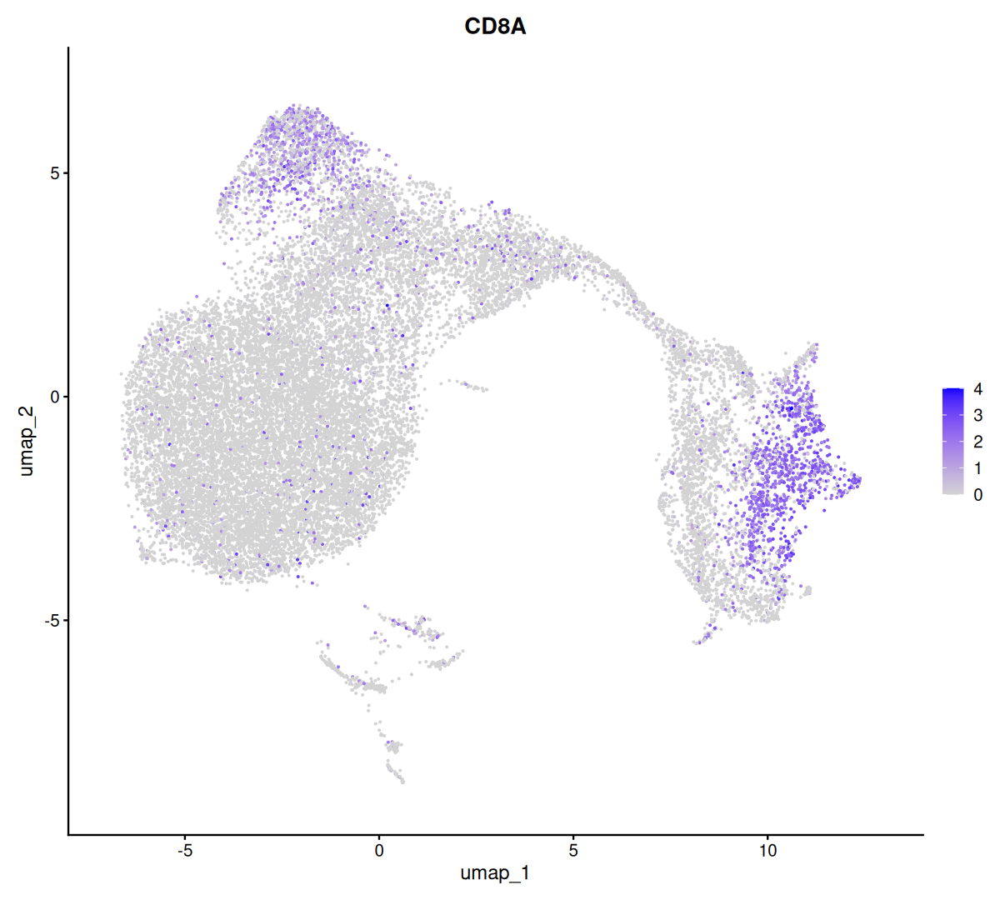

In [341]:
FeaturePlot(blood_subclust, features = "CD8A", min.cutoff = 0)

In [91]:
avgexp5p_sub = AverageExpression(blood_subclust, 
                            features = c("CD4","CD8A","CD8B","CD3D",'GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2'), 
                            group.by = "seurat_clusters",
                          assay = "RNA")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `seurat_clusters` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


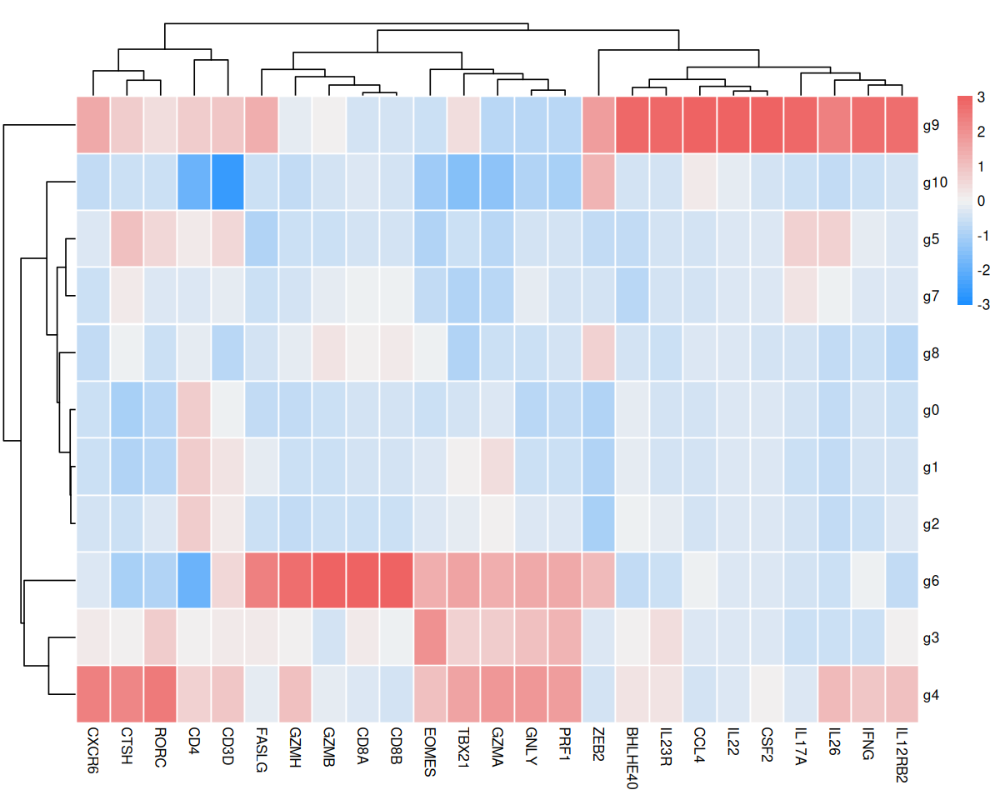

In [95]:
options(repr.plot.width = 10, repr.plot.height = 8)
pheatmap::pheatmap(t(avgexp5p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  #fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

In [153]:
options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp5p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

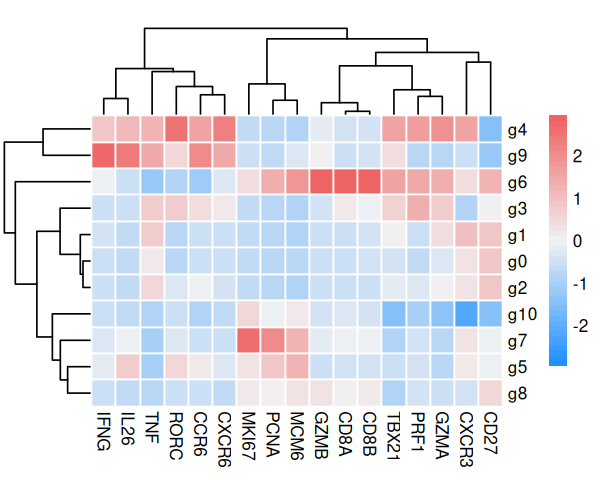

In [154]:
options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp5p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  #fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

In [135]:
avgexp5p_sub = AverageExpression(blood_subclust, 
                            features = c("TNF","CXCR3","GZMB","PRF1",
                                         "TBX21","CCR6","RORC","CXCR6","CD27","HLA-DRB1",
                                         "GZMA","PRF1","IFNG","IL26","CD8A","CD8B","MKI67","PCNA","MCM6"
                                        ), 
                            group.by = "seurat_clusters",
                          assay = "RNA")

Warning message:
“The following 1 features were not found in the RNA assay: HLA-DRB1”


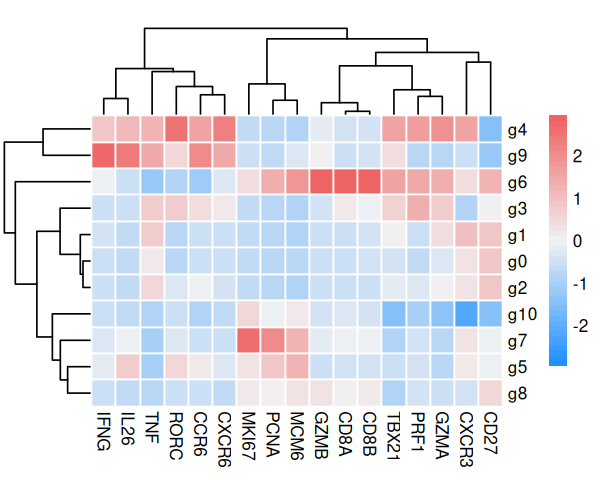

In [136]:
options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp5p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  #fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

In [332]:
md <- blood_5p@meta.data
md <- left_join(md, blood_subclust@meta.data  %>% 
                dplyr::select(barcode, cluster_subclust1 = integrated_snn_res.0.5))

Joining with `by = join_by(barcode)`


In [333]:
rownames(md) <- colnames(blood_5p)

In [334]:
blood_5p@meta.data <- md

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 9)

DimPlot(blood_5p, group.by = "annot_subclust", cols = c(scales::hue_pal() (11),"grey88"), label = T)

In [335]:
blood_5p@meta.data <- blood_5p@meta.data  %>% mutate(annot_subclust = ifelse(is.na(cluster_subclust1), "Other", cluster_subclust1))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



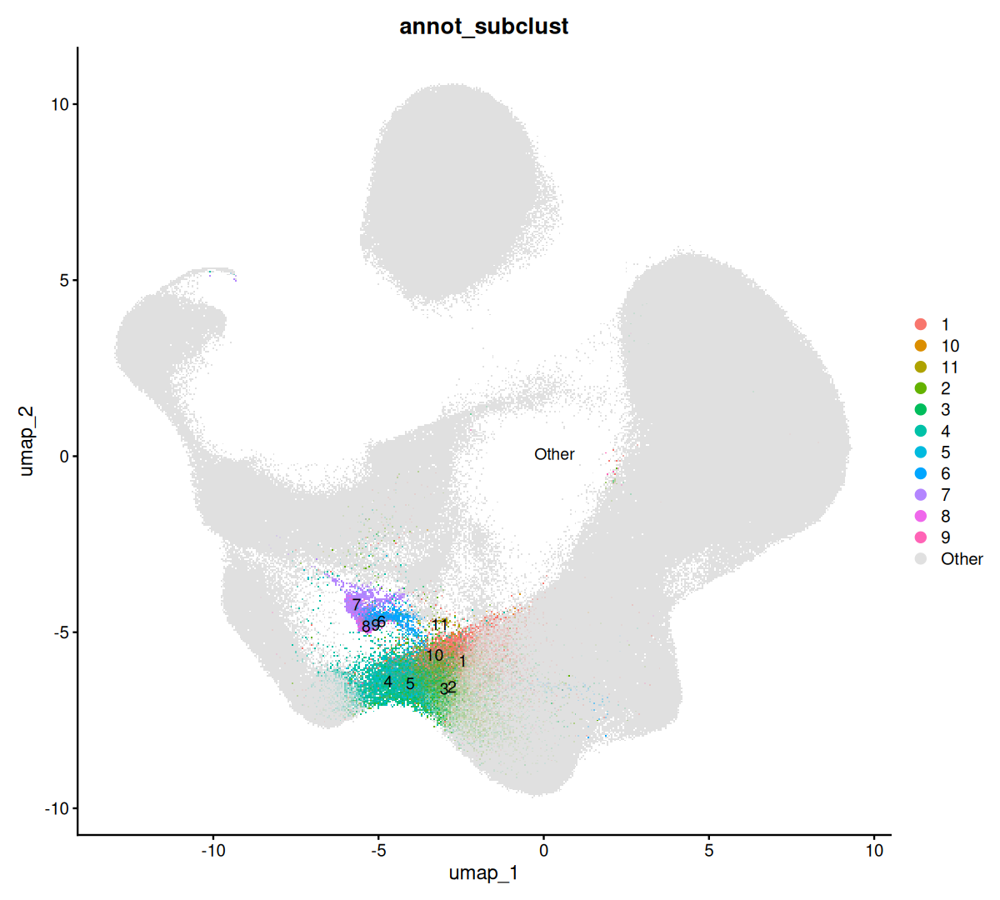

In [337]:
options(repr.plot.width = 10, repr.plot.height = 9)

DimPlot(blood_5p, group.by = "annot_subclust", cols = c(scales::hue_pal() (11),"grey88"), label = T)

## Visualize subcluster

In [152]:
md_subclust_vsm <- blood_subclust@meta.data  %>% dplyr::select(barcode, 
                                            subclust_clusters_test = seurat_clusters
                                                          )

In [153]:
md_join <- blood_5p@meta.data  %>% left_join(md_subclust_vsm)

Joining with `by = join_by(barcode)`


In [154]:
md_join$subclust_clusters_test  %>% table

.
   0    1    2    3    4    5    6    7    8    9   10 
4708 4168 3298 3224 1616 1547 1247  819  328  173   91 

In [155]:
blood_subclust$seurat_clusters  %>% table

.
   0    1    2    3    4    5    6    7    8    9   10 
4708 4168 3298 3224 1616 1547 1247  819  328  173   91 

In [156]:
rownames(md_join) <- colnames(blood_5p)

In [157]:
blood_5p@meta.data <- md_join

In [158]:
blood_5p@meta.data <- blood_5p@meta.data  %>% 
mutate(subclust_clusters = ifelse(is.na(subclust_clusters), "Other", subclust_clusters) 
       )

In [159]:
blood_5p$subclust_clusters  %>% table

.
     1     10     11      2      3      4      5      6      7      8      9 
  4708    173     91   4168   3298   3224   1616   1547   1247    819    328 
 Other 
572355 

In [149]:
blood_5p$cd4_ctl  <- ifelse(blood_5p$subclust_clusters %in% c(4), T, F)

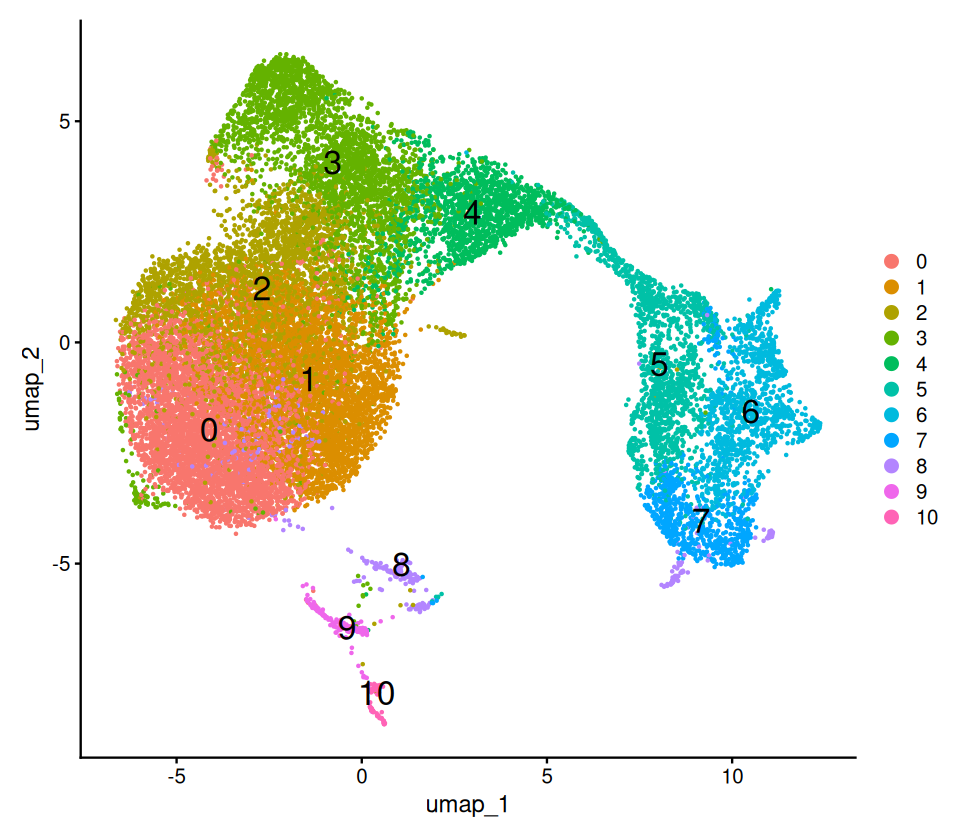

In [150]:
DimPlot(blood_subclust, label = T, label.size = 7)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



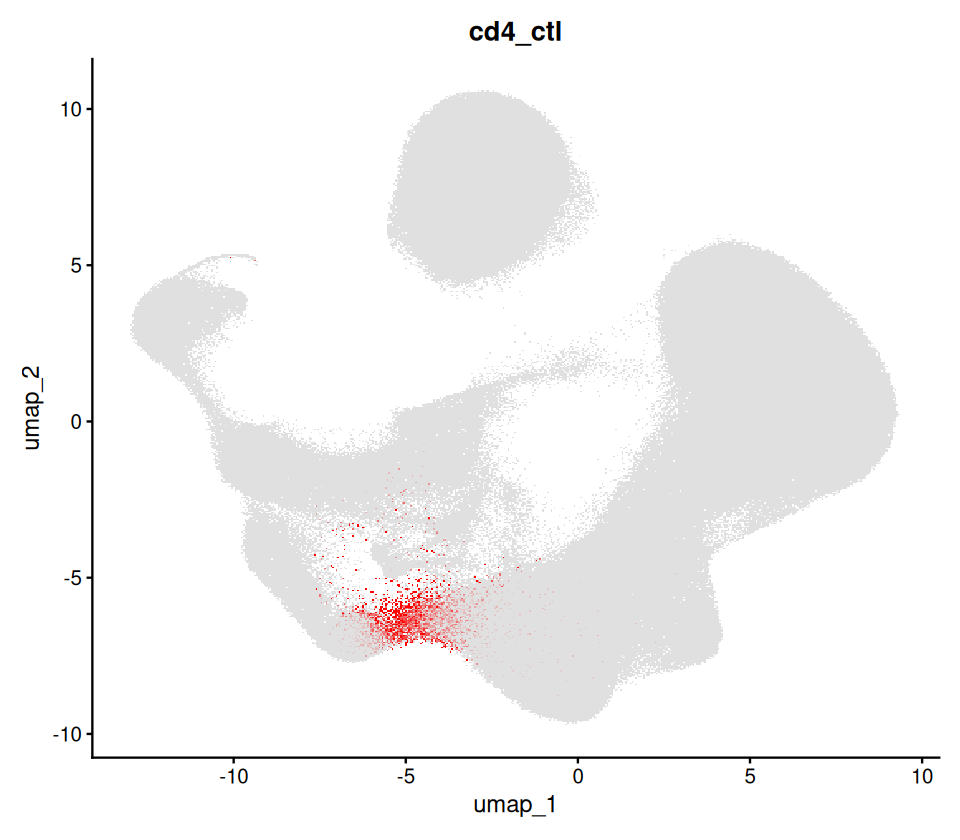

In [151]:
options(repr.plot.width = 8, repr.plot.height = 7)

DimPlot(blood_5p, group.by = "cd4_ctl", cols = c("grey88","red")) + NoLegend()


In [142]:
md_filt <- blood_5p@meta.data

df4 <- md_filt %>% 
group_by(data_folder, subclust_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = subclust_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md_filt %>% dplyr::select(diagnosis, antitnf_response, 
                                   timepoint, tissue, layer, version_10x, data_folder, participant_id) %>% 
unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


Warning message in wilcox.test.default(c(0, 0, 0, 8.22055137844612, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 8.22055137844612, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.0178986933953821, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 4.56140350877193, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 4.56140350877193, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.121441101065983, 0.136798905608755, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.121441101065983, 0.136798905608755, :
“cannot compute exact p-value with ties

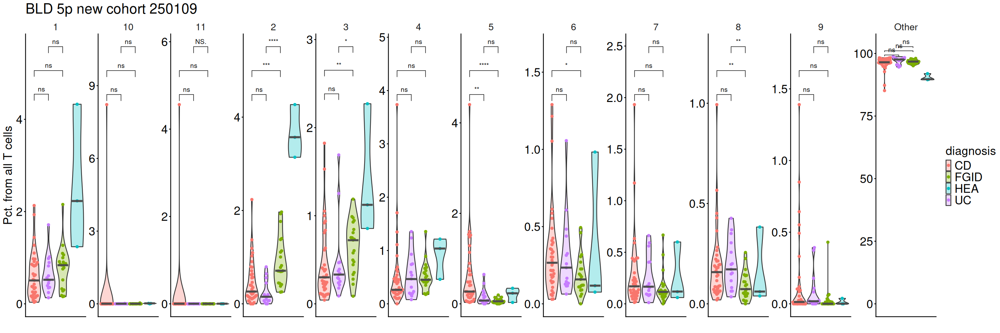

In [144]:
options(repr.plot.width = 24, repr.plot.height = 8)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0")

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("CD","UC","FGID")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") + ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


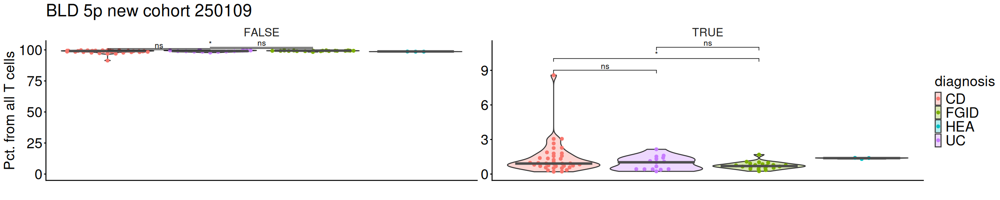

In [117]:
md_filt <- blood_5p@meta.data

df4 <- md_filt %>% 
group_by(data_folder, cd4_ctl2) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "cd4_ctl2", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md_filt %>% dplyr::select(diagnosis, antitnf_response, 
                                   timepoint, tissue, layer, version_10x, data_folder, participant_id) %>% 
unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")


options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0")

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("CD","UC","FGID")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~cd4_ctl2, scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") + ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("CD") & timepoint == "T0")

 df_filt  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") +
ggtheme()

# Gut CD4 CTL signature

In [26]:
# genes from with > 1.25 LFC

gut_sig  <- c(
    'GZMB',
'GZMH',
'KLRD1',
'GNLY',
'IL17F',
'LINC02446',
'MSC',
'IFNG',
'CSF2',
'GZMA',
'CHN1',
'KLRK1',
'ZEB2',
'ASPM',
'FASLG',
'IL22',
'CCL4',
'CCL4L2',
'CCL3',
'HLA-DRB5',
'NKG7',
'CD8A',
'XCL2',
'GPR25',
'IL17A',
'CD160',
'NCR3',
'EGR2',
'LINC01871',
'AL359834.1',
'CD70',
'TRBV7-4',
'CEBPD',
'XCL1',
'HLA-DRB1',
'HLA-DPB1',
'MIR155HG',
'SLC4A10',
'PRF1',
'IL23R',
'HLA-DQA1',
'ENTPD1',
'CRTAM',
'AL606807.1',
'CD8B',
'IL21',
'TRGV9',
'FABP5',
'BCL2L11',
'CCL20',
'CXCR6',
'HIST1H1B',
'HLA-DPA1',
'TRAV1-1',
'LINC02195',
'CCL3L1'
)

In [27]:
blood_5p  <- AddModuleScore(
  object = blood_5p,
  features = list(gut_sig),
  search = T,
  ctrl = 50,
  nbin = 50,
  assay = "RNA",
  name = 'Gut_CD4_CTLsig_')

Warning message:
“The following features are not present in the object: LINC02446, HLA-DRB5, LINC01871, AL359834.1, TRBV7-4, HLA-DRB1, HLA-DPB1, MIR155HG, HLA-DQA1, AL606807.1, HLA-DPA1, TRAV1-1, LINC02195, attempting to find updated synonyms”
Warning message:
“No updated symbols found”
Warning message:
“The following features are still not present in the object: LINC02446, HLA-DRB5, LINC01871, AL359834.1, TRBV7-4, HLA-DRB1, HLA-DPB1, MIR155HG, HLA-DQA1, AL606807.1, HLA-DPA1, TRAV1-1, LINC02195”


In [79]:
ls()

[1] "all_md"              "blood_5p"            "cd4_clones_in_gut"  
 [4] "cl_t"                "clone_table"         "clone_table_nona"   
 [7] "df"                  "df_all"              "ggtheme"            
[10] "gut_5p"              "i"                   "md"                 
[13] "md_joint_with_tcr"   "md_tcr_gut"          "md7"                
[16] "metadata_6"          "n_all"               "n_in_gut"           
[19] "overlap"             "shared_clones_no_na"

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



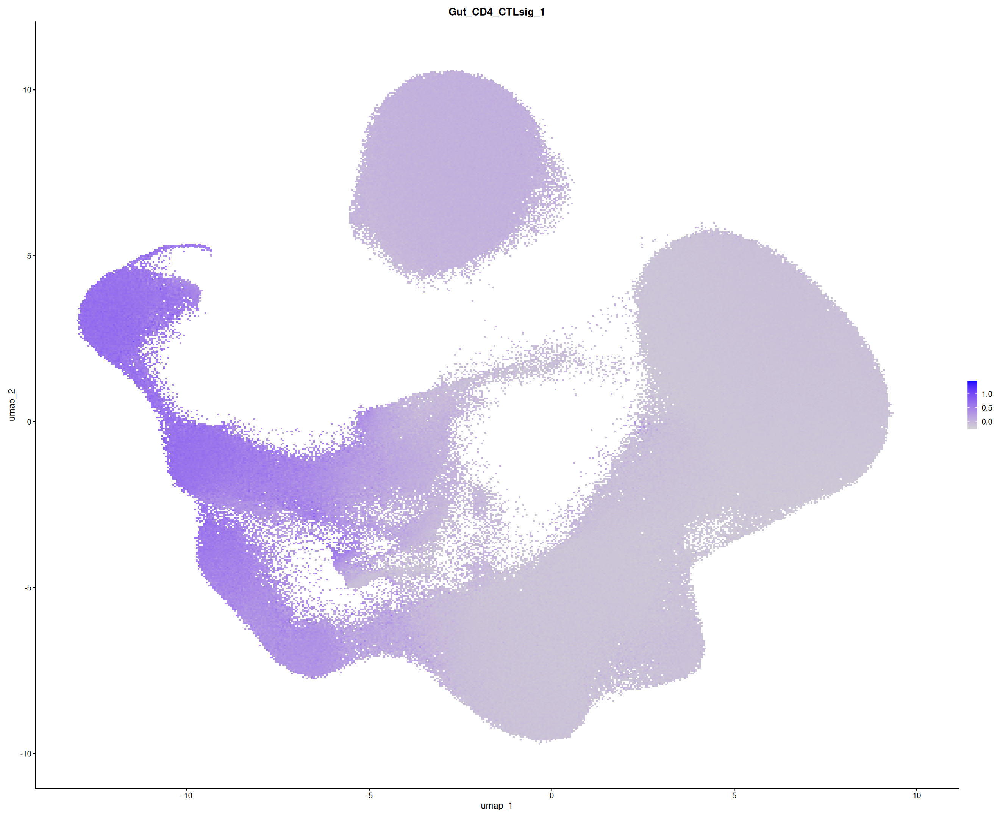

In [28]:
FeaturePlot(blood_5p, features = "Gut_CD4_CTLsig_1")

# Frequency plots

## CD4 CTL

In [152]:
md_filt <- blood_5p@meta.data

In [153]:
df4 <- md_filt %>% 
group_by(data_folder, subclust_vsm_res05) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = subclust_vsm_res05, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md_filt %>% dplyr::select(diagnosis, antitnf_response, 
                                   timepoint, tissue, layer, version_10x, data_folder, participant_id) %>% 
unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")



`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [154]:
df4

data_folder,seurat_clusters,freq,diagnosis,antitnf_response,timepoint,tissue,layer,version_10x,participant_id
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1542394_1_1_1,1,0.0161121574,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,2,0.0018832392,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,3,0.0062774639,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,4,0.0121364302,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,5,0.0027202344,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,6,0.0004184976,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,7,0.0004184976,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,8,0.0002092488,CD,FR,R,BLD,PBMC,v2,003-006
1542394_1_1_1,9,0.0006277464,CD,FR,R,BLD,PBMC,v2,003-006


In [155]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Warning message in wilcox.test.default(c(0, 0.121441101065983, 0.136798905608755, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.121441101065983, 0.136798905608755, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.196386488609584, 0, 0.0662690523525514, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.133630289532294, 0.0662690523525514, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.3903743315508, 0.0539738226959924, 0.492476060191518, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.3903743315508, 0.0539738226959924

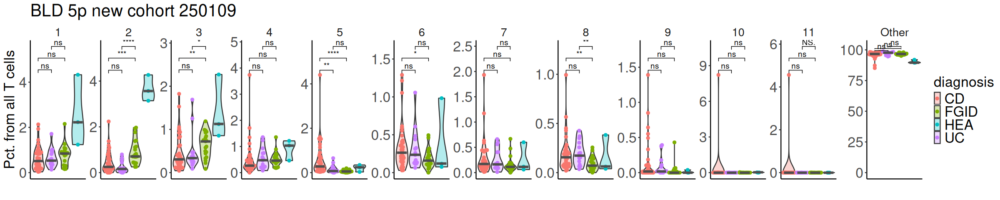

In [156]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0")

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("CD","UC","FGID")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") + ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.121441101065983, 0.136798905608755, 0.179479509422674, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.121441101065983, 0.136798905608755, 0.179479509422674, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.0425531914893617, 0.156739811912226, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.0539738226959924, 0.492476060191518, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.0539738226959924, 0.492476060191518, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.551378446115288, 0.0851063829787234, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0), c(8.22055137844612, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0), c(0, 0, 0, :
“cannot c

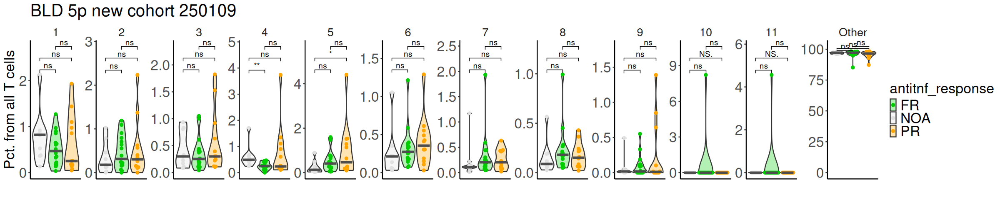

In [157]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("CD") & timepoint == "T0")

 df_filt  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") +
ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf.svg", width = 45, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.133630289532294, 0.0662690523525514, :
“cannot compute exact p-value with ties”


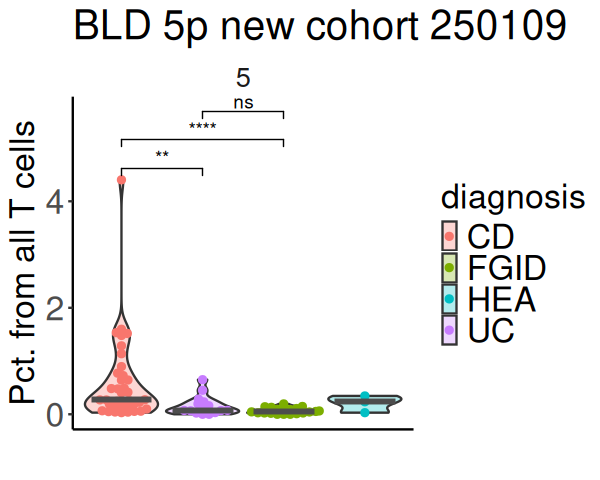

In [160]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0" & seurat_clusters == 5)

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("CD","UC","FGID","HEA")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
#scale_color_manual(values = scales::hue_pal()(4)[c(1,2,4)]) +
#scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") + ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

In [396]:
ggsave("figures/boxplot_freq_blood_5p_24/250109_cd4_ctl.svg", width = 9, height = 9, units = "cm", create.dir = T)
ggsave("figures/boxplot_freq_blood_5p_24/250109_cd4_ctl.png", width = 9, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.133630289532294, 0.0662690523525514, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.133630289532294, 0.0662690523525514, :
“cannot compute exact p-value with ties”


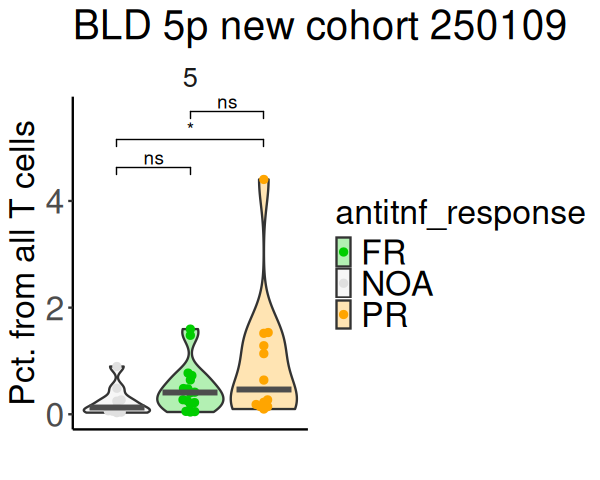

In [497]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("CD") & timepoint == "T0" & seurat_clusters == 5)

 df_filt  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") +
ggtheme()

ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf.svg", width = 45, height = 9, units = "cm")

In [398]:
ggsave("figures/boxplot_freq_blood_5p_24/250109_cd4_ctl_atnf.svg", width = 12, height = 9, units = "cm", create.dir = T)
ggsave("figures/boxplot_freq_blood_5p_24/250109_cd4_ctl_atnf.png", width = 12, height = 9, units = "cm")

## All clusters blood 5p

In [155]:
md_filt <- blood_5p@meta.data

In [156]:
df4 <- md_filt %>% 
group_by(data_folder, seurat_clusters2) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md_filt %>% dplyr::select(diagnosis, antitnf_response, 
                                   timepoint, tissue, layer, version_10x, data_folder, participant_id) %>% 
unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")



`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [157]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


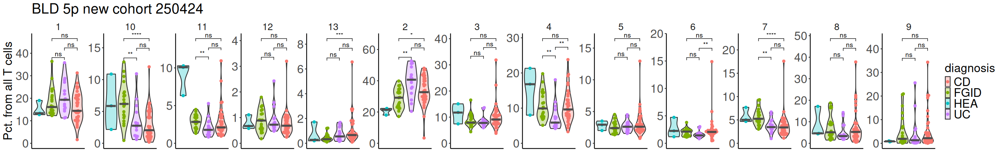

In [158]:
options(repr.plot.width = 24, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0")

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD")), y = freq*100)) + 
geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters), scales = "free", ncol = 13) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,3,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250424") +
#ggpubr::stat_compare_means(label = "p.signif") + 
ggpubr::stat_compare_means(comparisons = list(c(2,3),c(3,4),c(2,4)), label = "p.signif") + 
ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.121441101065983, 0.136798905608755, 0.179479509422674, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.121441101065983, 0.136798905608755, 0.179479509422674, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.0425531914893617, 0.156739811912226, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.0539738226959924, 0.492476060191518, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.0539738226959924, 0.492476060191518, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.551378446115288, 0.0851063829787234, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0), c(8.22055137844612, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0, 0, 0, 0, 0, 0, 0, 0), c(0, 0, 0, :
“cannot c

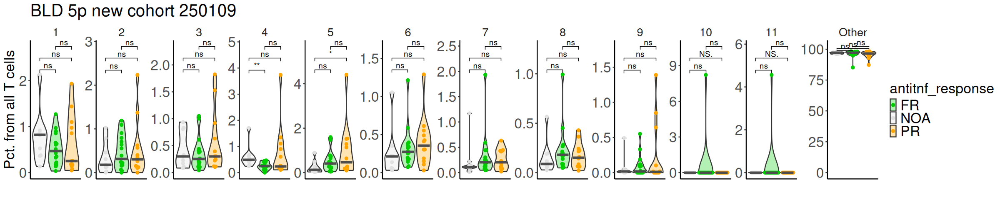

In [157]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("CD") & timepoint == "T0")

 df_filt  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") +
ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf.svg", width = 45, height = 9, units = "cm")

Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.641711229946524, 0.134934556739981, 0.246238030095759, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0, 0.133630289532294, 0.0662690523525514, :
“cannot compute exact p-value with ties”


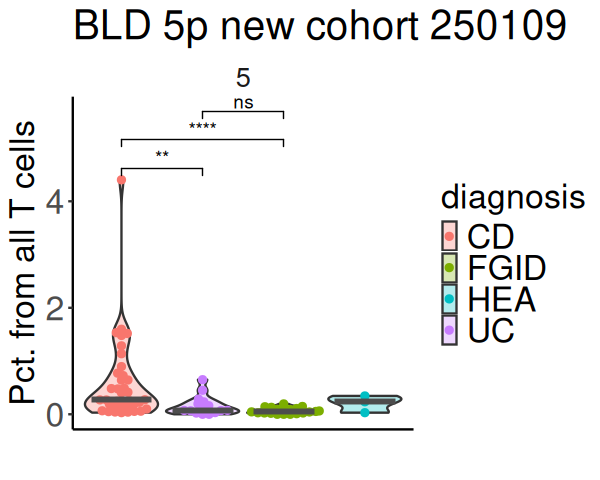

In [160]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("UC","CD","FGID","HEA") & timepoint == "T0" & seurat_clusters == 5)

 

df_filt  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("CD","UC","FGID","HEA")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
#scale_color_manual(values = scales::hue_pal()(4)[c(1,2,4)]) +
#scale_fill_manual(values = scales::hue_pal()(4)[c(1,2,4)]) +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") + ggtheme()

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort.svg", width = 45, height = 9, units = "cm")

## CLR transformation

In [ ]:
blood_5p$cd4_ctl

In [202]:
df_proportions <- blood_5p@meta.data %>% 
mutate(seurat_clusters2 = if_else(cd4_ctl == TRUE,"CD4_CTL",seurat_clusters2))  %>% 
group_by(data_folder, seurat_clusters2) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters2, values_from = freq, values_fill = 0.0001)  %>% 
column_to_rownames("data_folder")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [203]:
df_proportions

,1,10,11,12,13,2,3,4,5,6,7,8,9,CD4_CTL
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1542394_1_1_1,0.08683825,0.044151496,0.036827788,0.004184976,0.0012554928,0.35614145,0.07553882,0.09855618,0.008997698,0.013391923,0.05105671,0.030131827,1.902072e-01,0.0027202344
1542400_1_1_1,0.09236314,0.112074792,0.017458887,0.006420365,0.0031538635,0.28733949,0.08121198,0.11703086,0.020612751,0.032665015,0.05553052,0.081887813,9.089885e-02,0.0013516558
1542406_1_1_1,0.11233307,0.109190888,0.015318146,0.004713276,0.0070699136,0.20424195,0.08169678,0.11743912,0.020424195,0.019245876,0.02120974,0.031029065,2.560880e-01,0.0001000000
1542411_1_1_1,0.16525612,0.030512249,0.006904232,0.007126949,0.0044543430,0.42227171,0.08151448,0.04766147,0.029621381,0.010690423,0.01002227,0.024053452,1.585746e-01,0.0013363029
1542413_1_1_1,0.14331551,0.024598930,0.011764706,0.004278075,0.0181818182,0.33903743,0.06737968,0.07593583,0.025668449,0.020320856,0.02032086,0.177540107,6.524064e-02,0.0064171123
1542420_1_1_1,0.11496424,0.049251113,0.032249359,0.006746728,0.0009445419,0.26406693,0.07367427,0.11442450,0.021184725,0.014168128,0.04614762,0.058426663,2.024018e-01,0.0013493456
1542426_1_1_1,0.13597811,0.016142271,0.018878249,0.004924761,0.0071135431,0.17127223,0.07359781,0.09603283,0.009849521,0.013679891,0.02517100,0.221887825,2.030096e-01,0.0024623803
1542433_1_1_1,0.01604010,0.010526316,0.082205514,0.009523810,0.0656641604,0.03358396,0.22255639,0.05413534,0.027067669,0.148872180,0.17593985,0.070175439,8.320802e-02,0.0005012531
1542440_1_1_1,0.14347250,0.031146455,0.010603048,0.014413519,0.0049701789,0.50944334,0.08780649,0.05500331,0.029324056,0.013088138,0.03876740,0.033797217,2.750166e-02,0.0006626905


In [204]:

geom_mean <- function(x) exp(mean(log(x)))

clr_transform <- function(x){
  log(x / geom_mean(x))
}

clr_df <- t(apply(df_proportions, 1, clr_transform))
clr_df <- as.data.frame(clr_df)



In [205]:
clr_df

,1,10,11,12,13,2,3,4,5,6,7,8,9,CD4_CTL
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1542394_1_1_1,1.1292952,0.45287478,0.27150064,-1.9032511,-3.10722388,2.54057596,0.9898946,1.2558747,-1.13778324,-0.74010027,0.59818487,0.070829948,1.91336174,-2.334034
1542400_1_1_1,0.9772576,1.17069596,-0.68862166,-1.6889955,-2.39984227,2.11219394,0.8485924,1.2139672,-0.52256062,-0.06216585,0.46846240,0.856879702,0.96127689,-3.247140
1542406_1_1_1,1.4468674,1.41849666,-0.54556281,-1.7242178,-1.31875269,2.04470436,1.1284136,1.4913191,-0.25788073,-0.31730415,-0.22014041,0.160323400,2.27092011,-5.577186
1542411_1_1_1,1.9057008,0.21633251,-1.26966121,-1.2379125,-1.70791614,2.84385327,1.1989849,0.6623276,0.18670071,-0.83244740,-0.89698593,-0.021517188,1.86442950,-2.911889
1542413_1_1_1,1.4051965,-0.35714909,-1.09474803,-2.1063489,-0.65942996,2.26625847,0.6504914,0.7700366,-0.31458948,-0.54820433,-0.54820433,1.619344483,0.61823056,-1.700884
1542420_1_1_1,1.3305788,0.48288962,0.05945582,-1.5049847,-3.47109758,2.16216023,0.8856112,1.3258729,-0.36076193,-0.76304738,0.41780300,0.653729995,1.89621265,-3.114423
1542426_1_1_1,1.4881813,-0.64287132,-0.48630226,-1.8300370,-1.46231222,1.71894161,0.8743026,1.1403775,-1.13688982,-0.80838575,-0.19862018,1.977859294,1.88894048,-2.523184
1542433_1_1_1,-0.8206600,-1.24187343,0.81347056,-1.3419569,0.58880146,-0.08170324,1.8094287,0.3957354,-0.29741182,1.40733627,1.57439036,0.655246558,0.82559192,-4.286396
1542440_1_1_1,1.6958343,0.16839136,-0.90916752,-0.6021425,-1.66685322,2.96300958,1.2048264,0.7370844,0.10809913,-0.69860275,0.38727051,0.250069390,0.04393718,-3.681756


In [206]:
colnames(clr_df)  <- paste0("cluster",colnames(clr_df))

In [207]:
clr_df2  <- clr_df  %>% rownames_to_column("data_folder")  %>% left_join(md_to_join, by = "data_folder")  %>% 
dplyr::filter(diagnosis %in% c("CD","HEA","UC","FGID"))  %>% 
pivot_longer(cols = starts_with("cluster"), names_to = "seurat_clusters2", values_to = "freq_clr")  %>% 
mutate(seurat_clusters = gsub(seurat_clusters2, pattern = "cluster", replacement = ""))

In [208]:
clr_df2

data_folder,diagnosis,antitnf_response,timepoint,tissue,layer,version_10x,participant_id,seurat_clusters2,freq_clr,seurat_clusters
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster1,1.12929517,1
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster10,0.45287478,10
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster11,0.27150064,11
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster12,-1.90325108,12
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster13,-3.10722388,13
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster2,2.54057596,2
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster3,0.98989461,3
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster4,1.25587474,4
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster5,-1.13778324,5


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


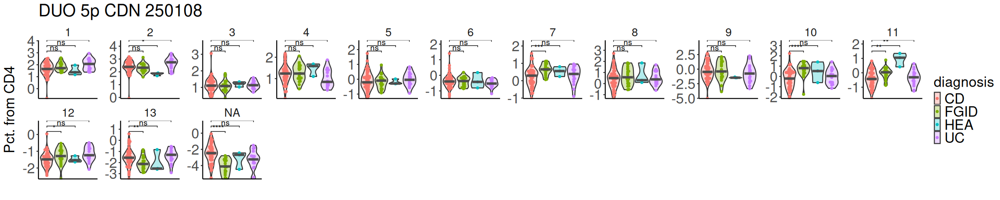

In [209]:
options(repr.plot.width = 20, repr.plot.height = 4)

clr_df2  %>% 
dplyr::filter(diagnosis %in% c("CD","HEA","UC","FGID"))  %>% 
ggplot(aes(x = diagnosis, y = freq_clr)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = diagnosis), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = 1:13), scales = "free", ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "DUO 5p CDN 250108") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +#stat_pvalue_manual(
#    stat_test, label = "p.adj.signif", 
#    #y.position = 35,
#    remove.bracket = TRUE
#    ) + 
ggtheme()

In [210]:
diag = c("CD","HEA","UC","FGID")


In [211]:
clr_df2

data_folder,diagnosis,antitnf_response,timepoint,tissue,layer,version_10x,participant_id,seurat_clusters2,freq_clr,seurat_clusters
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster1,1.12929517,1
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster10,0.45287478,10
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster11,0.27150064,11
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster12,-1.90325108,12
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster13,-3.10722388,13
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster2,2.54057596,2
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster3,0.98989461,3
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster4,1.25587474,4
1542394_1_1_1,CD,FR,R,BLD,PBMC,v2,003-006,cluster5,-1.13778324,5


In [219]:
for(i in diag){
  
            
        stat_test <- clr_df2 %>%
            mutate(diagnosis = if_else(diagnosis  == i,i,"Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq_clr ~ diagnosis, detailed = TRUE, ref.group = "Other") 
          
            stat_test$diag = i
          
            if(i == diag[1]){
                stat_all  <- stat_test
            } else {
                stat_all  <- rbind(stat_all, stat_test)
            }
            }
        

In [220]:
stat_all  %>% arrange(p)

seurat_clusters,estimate,.y.,group1,group2,n1,n2,statistic,p,conf.low,conf.high,method,alternative,diag
<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
CD4_CTL,1.433769065,freq_clr,Other,FGID,71,21,1247,3.15e-06,0.873348533,1.97257616,Wilcoxon,two.sided,FGID
CD4_CTL,-1.185062188,freq_clr,Other,CD,41,51,459,4.16e-06,-1.680926397,-0.73787602,Wilcoxon,two.sided,CD
10,-0.843816863,freq_clr,Other,FGID,71,21,308,4.80e-05,-1.207377197,-0.46847338,Wilcoxon,two.sided,FGID
7,-0.372268372,freq_clr,Other,FGID,71,21,373,5.39e-04,-0.594408231,-0.16188767,Wilcoxon,two.sided,FGID
10,0.597340862,freq_clr,Other,CD,41,51,1469,8.91e-04,0.264418788,0.95485570,Wilcoxon,two.sided,CD
7,0.297949767,freq_clr,Other,CD,41,51,1441,1.92e-03,0.127000510,0.50538454,Wilcoxon,two.sided,CD
13,0.548668805,freq_clr,Other,FGID,71,21,1072,2.42e-03,0.224592138,0.86950403,Wilcoxon,two.sided,FGID
12,0.261021472,freq_clr,Other,CD,41,51,1409,4.35e-03,0.080445398,0.44388285,Wilcoxon,two.sided,CD
11,-1.251511756,freq_clr,Other,HEA,89,3,5,4.89e-03,-1.923994656,-0.56927867,Wilcoxon,two.sided,HEA


In [227]:
stat_all  <- stat_all  %>% mutate(p.adj = if_else(p*14 < 0.05, p*14, 1))

In [228]:
stat_all  %>% arrange(p)

seurat_clusters,estimate,.y.,group1,group2,n1,n2,statistic,p,conf.low,conf.high,method,alternative,diag,p.adj
<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>
CD4_CTL,1.433769065,freq_clr,Other,FGID,71,21,1247,3.15e-06,0.873348533,1.97257616,Wilcoxon,two.sided,FGID,0.00004410
CD4_CTL,-1.185062188,freq_clr,Other,CD,41,51,459,4.16e-06,-1.680926397,-0.73787602,Wilcoxon,two.sided,CD,0.00005824
10,-0.843816863,freq_clr,Other,FGID,71,21,308,4.80e-05,-1.207377197,-0.46847338,Wilcoxon,two.sided,FGID,0.00067200
7,-0.372268372,freq_clr,Other,FGID,71,21,373,5.39e-04,-0.594408231,-0.16188767,Wilcoxon,two.sided,FGID,0.00754600
10,0.597340862,freq_clr,Other,CD,41,51,1469,8.91e-04,0.264418788,0.95485570,Wilcoxon,two.sided,CD,0.01247400
7,0.297949767,freq_clr,Other,CD,41,51,1441,1.92e-03,0.127000510,0.50538454,Wilcoxon,two.sided,CD,0.02688000
13,0.548668805,freq_clr,Other,FGID,71,21,1072,2.42e-03,0.224592138,0.86950403,Wilcoxon,two.sided,FGID,0.03388000
12,0.261021472,freq_clr,Other,CD,41,51,1409,4.35e-03,0.080445398,0.44388285,Wilcoxon,two.sided,CD,1.00000000
11,-1.251511756,freq_clr,Other,HEA,89,3,5,4.89e-03,-1.923994656,-0.56927867,Wilcoxon,two.sided,HEA,1.00000000


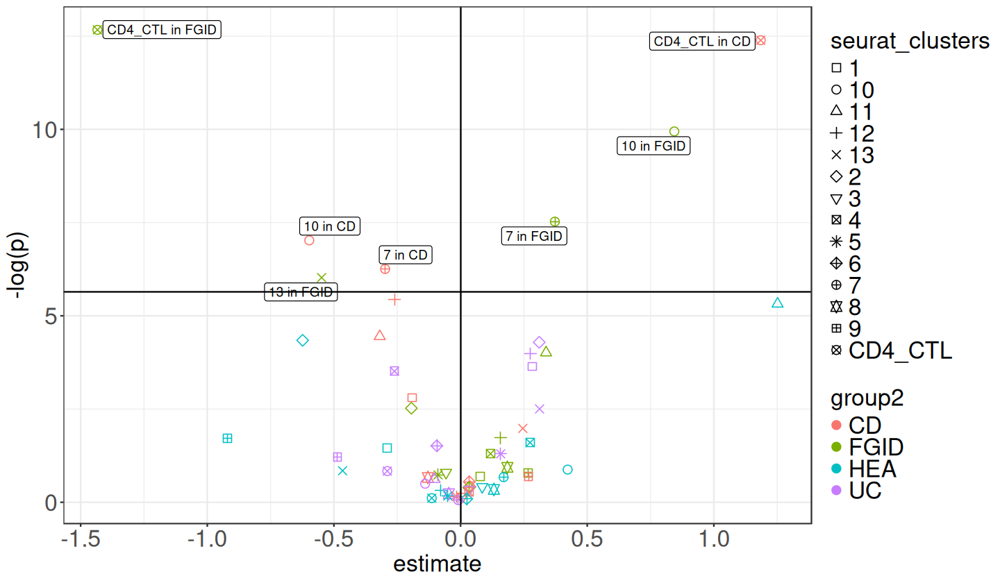

In [232]:
options(repr.plot.width =12, repr.plot.height = 7)
stat_all  %>% arrange(p)  %>% 
mutate(estimate = -estimate)  %>% 
mutate(delabel = if_else(p.adj <0.05, paste0(seurat_clusters, " in ", group2),""))  %>% 
ggplot(aes(x = estimate, y = -log(p), label = delabel)) +
theme_bw() +
geom_point(aes(color = group2, shape = seurat_clusters), size = 3) +
        ggrepel::geom_label_repel()  +
scale_fill_manual() +
scale_shape_manual(values = c(0:14)) +
geom_hline(yintercept = -log(0.05/(14))) +
geom_vline(xintercept = 0) +
ggtheme()
ggsave("figures/boxplot_freq_blood_5p_24/volcano_all_freq.svg", width = 7, height = 5.5)

# Cohort characterization plots

In [6]:
md_3p  <- read_csv("data/metadata/250113_Blood_3p_metadata.csv")
md_5p  <- read_csv("tables/data/metadata/250113_Blood_5p_metadata.csv")

In [79]:
md_5p$participant_id  %>% table

.
001-009 001-011 001-014 001-015 001-018 001-019 001-022 001-023 001-024 001-026 
   6939    9269    4716    7855   14411   14301   13902   10179   10149    7595 
001-027 001-028 001-030 001-031 001-032 001-033 001-034 001-035 001-040 001-041 
   8397    8107    7780    6587   13060    6867    8281    6399    5963    5738 
001-042 001-043 001-044 001-045 001-047 001-048 001-049 001-050 001-051 001-052 
  10722    7445    6293    8860    8131   16584    7971    8170    9390    8258 
001-053 001-055 001-057 001-058 001-059 001-062 001-063 001-064 001-070 001-071 
   8172    6951    4561   11642   10890   10330    2248   10422    5855    6322 
001-074 001-077 001-078 001-079 001-082 001-086 001-089 001-090 001-091 001-092 
   5899    6343    7037    5466    6542   12066    4884    6603    5812    5386 
001-094 001-101 003-001 003-002 003-004 003-005 003-006 003-007 003-008 003-010 
   6265    6074    4611    6742    3782    2853    8989   11776    4338    3343 
003-011 003-012 003-016 00

### Unify response

In [421]:
md_5p$antitnf_response  %>% table

.
    FR     NM    NOA     NR     PR 
141717 169686 139057  24497 107747 

In [422]:
md_3p$antiTNF_response  %>% table

.
    NM    NOA     PR   RESP 
145995  61989  68453  48102 

### Unify diagnosis

In [423]:
md_5p$diagnosis  %>% table

.
    CD   FGID    HEA    OTH     UC 
296021 146504  19527  16005 104647 

In [424]:
md_3p$disease  %>% table

.
      CD     FGID H Pylori Perineal    Psych       UC 
  146595   120580     7154     8148    10113    31949 

### Unify patient ID

In [425]:
md_3p$patient  %>% table

.
 p002  p003  p009  p010  p011  p014  p015  p016  p017  p018  p019  p020  p021 
 8569  5780  9222   247  7044 11184 10122 17375  6823 14341 16474  8148 10113 
 p022  p023  p024  p025  p026  p027  p028  p030  p031  p032  p033  p034  p035 
 1828  9552  8806  7154  8573  8311  7575  8011  7436  8577  8288  1289   805 
 p036  p037  p038  p040  p041  p042  p043  p044  p045  p047  p048  p049  p050 
 9470  8390  5694  8565  8124 10671  7487 10977 10599  6663  9039  9223  7990 

In [426]:
md_5p$participant_id  %>% table

.
001-009 001-011 001-014 001-015 001-018 001-019 001-022 001-023 001-024 001-026 
   6939    9269    4716    7855   14411   14301   13902   10179   10149    7595 
001-027 001-028 001-030 001-031 001-032 001-033 001-034 001-035 001-040 001-041 
   8397    8107    7780    6587   13060    6867    8281    6399    5963    5738 
001-042 001-043 001-044 001-045 001-047 001-048 001-049 001-050 001-051 001-052 
  10722    7445    6293    8860    8131   16584    7971    8170    9390    8258 
001-053 001-055 001-057 001-058 001-059 001-062 001-063 001-064 001-070 001-071 
   8172    6951    4561   11642   10890   10330    2248   10422    5855    6322 
001-074 001-077 001-078 001-079 001-082 001-086 001-089 001-090 001-091 001-092 
   5899    6343    7037    5466    6542   12066    4884    6603    5812    5386 
001-094 001-101 003-001 003-002 003-004 003-005 003-006 003-007 003-008 003-010 
   6265    6074    4611    6742    3782    2853    8989   11776    4338    3343 
003-011 003-012 003-016 00

### Unify time

In [427]:
md_3p$time  %>% table

.
   T0D    T3M 
301084  23455 

In [38]:
md_5p$timepoint  %>% table

.
     R     R2     T0 
 86216   1421 466276 

In [428]:
md_5p$timepoint  %>% table

.
     R     R2     T0 
 91012   1421 501141 

In [42]:
md_5p$version_10x  <- paste0("5p_", md_5p$version_10x)

In [431]:
colnames(md_3p)

[1] "SingleR_HPCA"     "nCount_RNA"       "nFeature_RNA"     "patient"         
 [5] "time"             "tissue"           "layer"            "prime"           
 [9] "RNA_snn_res.0.3"  "seurat_clusters"  "barcode"          "disease"         
[13] "antiTNF_response" "percent.mt"       "percent.rp"       "RNA_snn_res.0.8" 
[17] "manual_annots"    "RNA_snn_res.1"    "cd4_ctl"

In [432]:
head(md_3p)

,SingleR_HPCA,nCount_RNA,nFeature_RNA,patient,time,tissue,layer,prime,RNA_snn_res.0.3,seurat_clusters,barcode,disease,antiTNF_response,percent.mt,percent.rp,RNA_snn_res.0.8,manual_annots,RNA_snn_res.1,cd4_ctl
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<fct>,<chr>,<fct>,<lgl>
Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,3308,927,p002,T0D,BLD,CD3,3p,0,4,Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,2.750907,49.60701,4,00_CD4_Naive,4,FALSE
Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,8581,1744,p002,T0D,BLD,CD3,3p,1,3,Cell2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,4.102086,51.17119,7,07_CD8,3,FALSE
Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,2072,888,p002,T0D,BLD,CD3,3p,2,10,Cell3_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,3.861004,34.16988,5,05_CD8,10,FALSE
Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,3772,892,p002,T0D,BLD,CD3,3p,3,0,Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,4.135737,53.41994,1,01_CD8_Naive,0,FALSE
Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,2903,840,p002,T0D,BLD,CD3,3p,3,0,Cell5_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,3.720289,49.12160,1,01_CD8_Naive,0,FALSE
Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,T_cells,8469,2186,p002,T0D,BLD,CD3,3p,6,20,Cell6_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,FGID,NM,5.065533,34.32519,13,13_,20,FALSE


In [9]:
md_3p <- md_3p  %>% mutate(diagnosis = ifelse(disease %in% c("CD","FGID","UC"), disease, "OTH"),
                                             antitnf_response = ifelse(antiTNF_response == "RESP", "FR", antiTNF_response),
                                            participant_id = paste0("001-",substr(patient,2,4)),
                                            timepoint= ifelse(time == "T0D", "T0","R"),
                                            version_10x = "3p_v1")

In [11]:
colnames(md_3p) %in% colnames(md_5p)

[1]  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE
[13] FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE

In [85]:
md_3p_to_join  <- md_3p[,colnames(md_3p) %in% colnames(md_5p)]

In [86]:
md_5p_to_join  <- md_5p[,colnames(md_5p) %in% colnames(md_3p_to_join)]

In [87]:
colnames(md_3p_to_join)

[1] "SingleR_HPCA"     "nCount_RNA"       "nFeature_RNA"     "tissue"          
 [5] "layer"            "prime"            "RNA_snn_res.0.3"  "seurat_clusters" 
 [9] "barcode"          "percent.mt"       "diagnosis"        "antitnf_response"
[13] "participant_id"   "timepoint"        "version_10x"

In [88]:
colnames(md_3p_to_join)[order(colnames(md_3p_to_join))]

[1] "antitnf_response" "barcode"          "diagnosis"        "layer"           
 [5] "nCount_RNA"       "nFeature_RNA"     "participant_id"   "percent.mt"      
 [9] "prime"            "RNA_snn_res.0.3"  "seurat_clusters"  "SingleR_HPCA"    
[13] "timepoint"        "tissue"           "version_10x"

In [89]:
colnames(md_5p_to_join)[order(colnames(md_5p_to_join))]

[1] "antitnf_response" "barcode"          "diagnosis"        "layer"           
 [5] "nCount_RNA"       "nFeature_RNA"     "participant_id"   "percent.mt"      
 [9] "prime"            "RNA_snn_res.0.3"  "seurat_clusters"  "SingleR_HPCA"    
[13] "timepoint"        "tissue"           "version_10x"

In [90]:
md_3p_to_join  <- md_3p_to_join[,order(colnames(md_3p_to_join))]
md_5p_to_join  <- md_5p_to_join[,order(colnames(md_5p_to_join))]
colnames(md_3p_to_join) == colnames(md_5p_to_join)

[1] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE

In [91]:
md_3p_to_join$dataset  <- "2021"
md_5p_to_join$dataset  <- "2024"

In [92]:
md_5p_to_join$participant_id  %>% table

.
001-009 001-011 001-014 001-015 001-018 001-019 001-022 001-023 001-024 001-026 
   6939    9269    4716    7855   14411   14301   13902   10179   10149    7595 
001-027 001-028 001-030 001-031 001-032 001-033 001-034 001-035 001-040 001-041 
   8397    8107    7780    6587   13060    6867    8281    6399    5963    5738 
001-042 001-043 001-044 001-045 001-047 001-048 001-049 001-050 001-051 001-052 
  10722    7445    6293    8860    8131   16584    7971    8170    9390    8258 
001-053 001-055 001-057 001-058 001-059 001-062 001-063 001-064 001-070 001-071 
   8172    6951    4561   11642   10890   10330    2248   10422    5855    6322 
001-074 001-077 001-078 001-079 001-082 001-086 001-089 001-090 001-091 001-092 
   5899    6343    7037    5466    6542   12066    4884    6603    5812    5386 
001-094 001-101 003-001 003-002 003-004 003-005 003-006 003-007 003-008 003-010 
   6265    6074    4611    6742    3782    2853    8989   11776    4338    3343 
003-011 003-012 003-016 00

In [93]:
md_3p_to_join$dataset  <- "2021"
md_5p_to_join$dataset  <- "2024"

md  <- rbind(md_3p_to_join, md_5p_to_join)


counts_of_patients <- md  %>% 
group_by(participant_id, dataset, timepoint)  %>% tally  %>% ungroup  %>% 
dplyr::select(-n)  %>% group_by(participant_id, dataset, timepoint)  %>% tally  %>% 
mutate(dataset_time = paste(dataset, timepoint))  %>% ungroup  %>% 
dplyr::select(-dataset, -timepoint)  %>% 
pivot_wider(names_from = dataset_time, values_from = n, values_fill = 0)  %>% 
mutate(yy = 1)

In [94]:
counts_of_patients

participant_id,2021 T0,2024 T0,2024 R,2021 R,2024 R2,yy
<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>
001-002,1,0,0,0,0,1
001-003,1,0,0,0,0,1
001-009,1,1,0,0,0,1
001-010,1,0,0,0,0,1
001-011,1,1,1,0,0,1
001-014,1,0,1,1,0,1
001-015,1,1,0,0,0,1
001-016,1,0,0,1,0,1
001-017,1,0,0,0,0,1


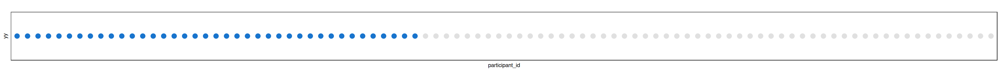

In [469]:
options(repr.plot.width = 28, repr.plot.height = 2)

counts_of_patients  %>% 
ggplot(aes(x = participant_id, y = yy)) + geom_point(aes(colour = as.factor(`2021 T0`)), size = 4) + 
scale_color_manual(values = c("grey88", "dodgerblue3")) +
  theme_bw() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

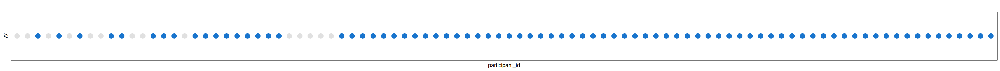

In [470]:

counts_of_patients  %>% 
ggplot(aes(x = participant_id, y = yy)) + geom_point(aes(colour = as.factor(`2024 T0`)), size = 4) + 
scale_color_manual(values = c("grey88", "dodgerblue3")) +
  theme_bw() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

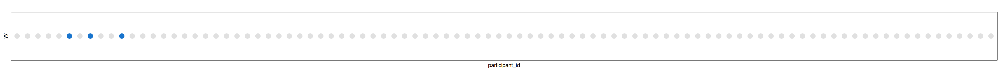

In [471]:

counts_of_patients  %>% 
ggplot(aes(x = participant_id, y = yy)) + geom_point(aes(colour = as.factor(`2021 R`)), size = 4) + 
scale_color_manual(values = c("grey88", "dodgerblue3")) +
  theme_bw() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

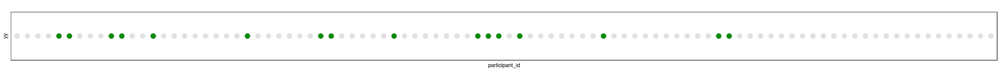

In [472]:

counts_of_patients  %>% 
ggplot(aes(x = participant_id, y = yy)) + geom_point(aes(colour = as.factor(`2024 R`)), size = 4) + 
scale_color_manual(values = c("grey88", "green4")) +
  theme_bw() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

In [156]:
md$age  %>% summary

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
    6.6    11.3    13.9    14.0    17.0    24.0  329669 

In [56]:
participant_list  <- md  %>% group_by(participant_id, diagnosis
                                    )  %>% tally   %>% 
arrange(diagnosis)

In [57]:
participant_list

participant_id,diagnosis,n
<chr>,<chr>,<int>
001-010,CD,247
001-011,CD,16313
001-014,CD,15900
001-016,CD,17375
001-018,CD,28752
001-019,CD,30775
001-022,CD,15730
001-024,CD,18955
001-026,CD,16168


In [58]:
duplicated(participant_list$participant_id)  %>% table

.
FALSE  TRUE 
   94     1 

In [59]:
which(duplicated(participant_list$participant_id))

[1] 94

In [60]:
participant_list  %>% dplyr::filter(participant_id == "001-032")

participant_id,diagnosis,n
<chr>,<chr>,<int>
001-032,CD,16841
001-032,NA,4796


In [61]:
participant_list <- dplyr::filter(participant_list, !(participant_id == "001-032" & is.na(diagnosis)))

In [62]:
duplicated(participant_list$participant_id)  %>% table

.
FALSE 
   94 

In [480]:
participant_list

participant_id,diagnosis,n
<chr>,<chr>,<int>
001-010,CD,247
001-011,CD,16313
001-014,CD,15900
001-016,CD,17375
001-018,CD,28752
001-019,CD,30775
001-022,CD,15730
001-024,CD,18955
001-026,CD,16168


In [63]:
counts_of_patients2 <- left_join(counts_of_patients, participant_list  %>% 
                                 ungroup  %>% dplyr::select(-n)) %>% 
mutate(diagnosis2 = recode_factor(diagnosis, "CD" = "01_CD", "UC" = "04_UC", "FGID" = "02_FGID",
                                 "HEA" = "03_HEA", "OTH" = "05_OTH"))   %>% 
arrange(desc(`2021 T0`), diagnosis2)

Joining with `by = join_by(participant_id)`


In [64]:
counts_of_patients2$participant_id

[1] "001-010" "001-011" "001-014" "001-016" "001-018" "001-019" "001-022"
 [8] "001-024" "001-026" "001-027" "001-031" "001-032" "001-040" "001-041"
[15] "001-042" "001-048" "001-015" "001-036" "001-038" "001-047" "001-002"
[22] "001-003" "001-009" "001-017" "001-023" "001-028" "001-030" "001-033"
[29] "001-034" "001-035" "001-037" "001-043" "001-044" "001-045" "001-049"
[36] "001-050" "001-020" "001-021" "001-025" "001-051" "001-052" "001-058"
[43] "001-063" "001-064" "001-071" "001-074" "001-082" "001-086" "001-089"
[50] "001-094" "003-004" "003-006" "003-007" "003-010" "003-011" "003-012"
[57] "003-021" "003-024" "003-026" "003-027" "003-039" "003-042" "003-046"
[64] "003-066" "003-074" "001-055" "001-057" "001-059" "001-062" "003-016"
[71] "003-017" "003-030" "003-034" "003-036" "003-051" "003-059" "003-072"
[78] "003-077" "001-053" "001-077" "001-078" "001-079" "001-090" "001-092"
[85] "003-001" "003-002" "003-005" "HE-009"  "HE-011"  "HE-012"  "001-070"
[92] "001-091" "003-008" "001-101"

In [482]:
counts_of_patients2$participant_id

[1] "001-010" "001-011" "001-014" "001-016" "001-018" "001-019" "001-022"
 [8] "001-024" "001-026" "001-027" "001-031" "001-032" "001-040" "001-041"
[15] "001-042" "001-048" "001-015" "001-036" "001-038" "001-047" "001-002"
[22] "001-003" "001-009" "001-017" "001-023" "001-028" "001-030" "001-033"
[29] "001-034" "001-035" "001-037" "001-043" "001-044" "001-045" "001-049"
[36] "001-050" "001-020" "001-021" "001-025" "001-051" "001-052" "001-058"
[43] "001-063" "001-064" "001-071" "001-074" "001-082" "001-086" "001-089"
[50] "001-094" "003-004" "003-006" "003-007" "003-010" "003-011" "003-012"
[57] "003-021" "003-024" "003-026" "003-027" "003-039" "003-042" "003-046"
[64] "003-066" "003-074" "001-055" "001-057" "001-059" "001-062" "003-016"
[71] "003-017" "003-030" "003-034" "003-036" "003-051" "003-059" "003-072"
[78] "003-077" "001-053" "001-077" "001-078" "001-079" "001-090" "001-092"
[85] "003-001" "003-002" "003-005" "HE-009"  "HE-011"  "HE-012"  "001-070"
[92] "001-091" "003-008" "001-101"

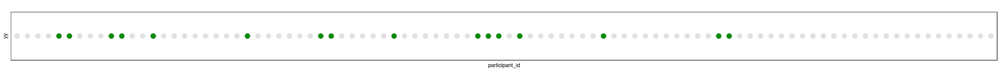

In [483]:
counts_of_patients2   %>% 
ggplot(aes(x = participant_id, y = yy)) + geom_point(aes(colour = as.factor(`2024 R`)), size = 4) + 
scale_color_manual(values = c("grey88", "green4")) +
  theme_bw() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

In [486]:
counts_of_patients2$participant_id

[1] "001-010" "001-011" "001-014" "001-016" "001-018" "001-019" "001-022"
 [8] "001-024" "001-026" "001-027" "001-031" "001-032" "001-040" "001-041"
[15] "001-042" "001-048" "001-015" "001-036" "001-038" "001-047" "001-002"
[22] "001-003" "001-009" "001-017" "001-023" "001-028" "001-030" "001-033"
[29] "001-034" "001-035" "001-037" "001-043" "001-044" "001-045" "001-049"
[36] "001-050" "001-020" "001-021" "001-025" "001-051" "001-052" "001-058"
[43] "001-063" "001-064" "001-071" "001-074" "001-082" "001-086" "001-089"
[50] "001-094" "003-004" "003-006" "003-007" "003-010" "003-011" "003-012"
[57] "003-021" "003-024" "003-026" "003-027" "003-039" "003-042" "003-046"
[64] "003-066" "003-074" "001-055" "001-057" "001-059" "001-062" "003-016"
[71] "003-017" "003-030" "003-034" "003-036" "003-051" "003-059" "003-072"
[78] "003-077" "001-053" "001-077" "001-078" "001-079" "001-090" "001-092"
[85] "003-001" "003-002" "003-005" "HE-009"  "HE-011"  "HE-012"  "001-070"
[92] "001-091" "003-008" "001-101"

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”
✔ Created directory: ./figures/cohort_characterization_blood/basic_metadata2.

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”


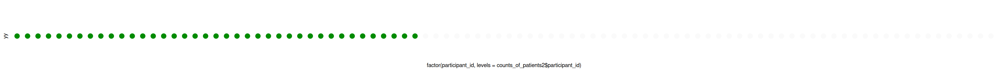

In [487]:
counts_of_patients2  %>% 
ggplot(aes(x = factor(participant_id, levels = counts_of_patients2$participant_id), 
                      y = yy)) + geom_point(aes(colour = as.factor(`2021 T0`)), size = 4) + 
scale_color_manual(values = c("grey98", "green4")) +
  theme_minimal() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

ggsave("./figures/cohort_characterization_blood/basic_metadata2/to_2021.svg", width = 28, height = 3, units = "cm", create.dir = TRUE)

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”
Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”


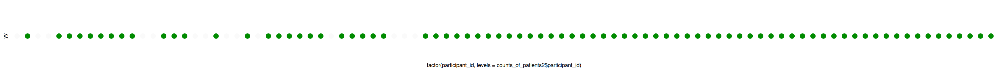

In [485]:
counts_of_patients2  %>% 
ggplot(aes(x = factor(participant_id, levels = counts_of_patients2$participant_id), y = yy)) + geom_point(aes(colour = as.factor(`2024 T0`)), size = 4) + 
scale_color_manual(values = c("grey98", "green4")) +
  theme_minimal() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

ggsave("./figures/cohort_characterization_blood/basic_metadata/to_2024.svg", width = 28, height = 3, units = "cm", create.dir = TRUE)

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”
Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”


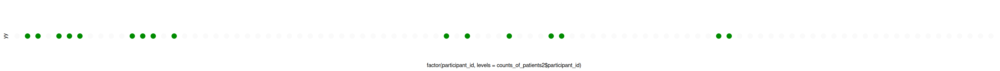

In [488]:
counts_of_patients2  %>% 
ggplot(aes(x = factor(participant_id, levels = counts_of_patients2$participant_id), y = yy)) + geom_point(aes(colour = as.factor(`2024 R`)), size = 4) + 
scale_color_manual(values = c("grey98", "green4")) +
  theme_minimal() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

ggsave("./figures/cohort_characterization_blood/basic_metadata2/r_2024.svg", width = 28, height = 3, units = "cm", create.dir = TRUE)

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”
Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”


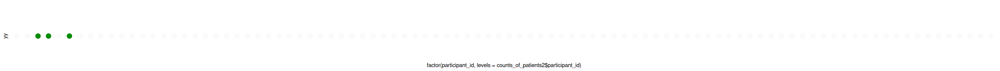

In [489]:
counts_of_patients2  %>% 
ggplot(aes(x = factor(participant_id, levels = counts_of_patients2$participant_id), y = yy)) + geom_point(aes(colour = as.factor(`2021 R`)), size = 4) + 
scale_color_manual(values = c("grey98", "green4")) +
  theme_minimal() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + NoLegend()

ggsave("./figures/cohort_characterization_blood/basic_metadata2/r_2021.svg", width = 28, height = 3, units = "cm", create.dir = TRUE)

Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”
Warning message:
“Use of `counts_of_patients2$participant_id` is discouraged.
ℹ Use `participant_id` instead.”


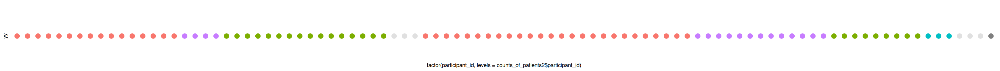

In [491]:
counts_of_patients2  %>% 
ggplot(aes(x = factor(participant_id, levels = counts_of_patients2$participant_id), y = yy)) + geom_point(aes(colour = as.factor(diagnosis)), size = 4) + 
#scale_color_manual(values = c("grey98", "green4")) +
  theme_minimal() + theme(axis.text.x = element_blank(),
                    axis.text.y = element_blank(),
                    axis.ticks = element_blank(),
                    panel.grid = element_blank(),
                    ) + ggtitle("") + 
scale_color_manual(values = c(scales::hue_pal()(4)[1],
                              scales::hue_pal()(4)[2],
                              scales::hue_pal()(4)[3],
                              "grey88",
                             scales::hue_pal()(4)[4]
                              )) + NoLegend()

ggsave("./figures/cohort_characterization_blood/basic_metadata2/group.svg", width = 28, height = 3, units = "cm", create.dir = TRUE)

In [492]:
counts_of_patients2

participant_id,2021 T0,2024 T0,2024 R,2021 R,2024 R2,yy,diagnosis,diagnosis2
<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<chr>,<fct>
001-010,1,0,0,0,0,1,CD,01_CD
001-011,1,1,1,0,0,1,CD,01_CD
001-014,1,0,1,1,0,1,CD,01_CD
001-016,1,0,0,1,0,1,CD,01_CD
001-018,1,1,1,0,0,1,CD,01_CD
001-019,1,1,1,1,0,1,CD,01_CD
001-022,1,1,1,0,0,1,CD,01_CD
001-024,1,1,0,0,0,1,CD,01_CD
001-026,1,1,0,0,0,1,CD,01_CD


## Only patients which are not in 3p

In [66]:
counts_of_patients2  %>% dplyr::filter(`2021 T0` < 1 & `2024 T0` > 0)  %>% 
group_by(diagnosis)  %>% tally

diagnosis,n
<chr>,<int>
CD,26
FGID,9
HEA,3
OTH,3
UC,13
NA,1


In [67]:
pt_in_new_cohort  <- counts_of_patients2  %>% dplyr::filter(`2021 T0` < 1 & `2024 T0` > 0)  %>% pull(participant_id)

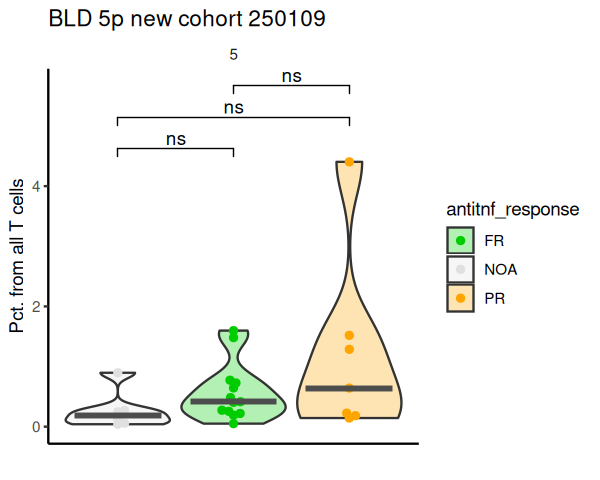

In [96]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(diagnosis %in% c("CD") & timepoint == "T0" & seurat_clusters == 5 & participant_id %in% pt_in_new_cohort)

 df_filt  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 5p new cohort 250109") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") 

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf.svg", width = 45, height = 9, units = "cm")

In [102]:
corr_table  <- df4  %>% dplyr::filter(seurat_clusters == 5)  %>% 
dplyr::filter(diagnosis %in% c("CD") & participant_id %in% pt_in_new_cohort)  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "NM", "NOA", antitnf_response))  %>% 
mutate(resp2 = case_when(antitnf_response == "NOA" ~0 ,
                         antitnf_response == "FR" ~ 1,
                         antitnf_response == "PR" ~ 2
                         ))

In [103]:
corr_table

data_folder,seurat_clusters,freq,diagnosis,antitnf_response,timepoint,tissue,layer,version_10x,participant_id,resp2
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1542394_1_1_1,5,0.0027202344,CD,FR,R,BLD,PBMC,v2,003-006,1
1542400_1_1_1,5,0.0013516558,CD,FR,R,BLD,PBMC,v2,003-007,1
1542413_1_1_1,5,0.0064171123,CD,PR,T0,BLD,PBMC,v2,003-021,2
1542420_1_1_1,5,0.0013493456,CD,NOA,T0,BLD,PBMC,v2,003-024,0
1542426_1_1_1,5,0.0024623803,CD,NOA,T0,BLD,PBMC,v2,003-026,0
1542433_1_1_1,5,0.0005012531,CD,FR,T0,BLD,PBMC,v2,003-027,1
1737883_1_1_1,5,0.0026921926,CD,NOA,T0,BLD,PBMC,v2,003-010,0
1737884_1_1_1,5,0.0025531915,CD,FR,T0,BLD,PBMC,v2,003-011,1
1737885_1_1_1,5,0.0021943574,CD,FR,T0,BLD,PBMC,v2,003-012,1


`geom_smooth()` using formula = 'y ~ x'


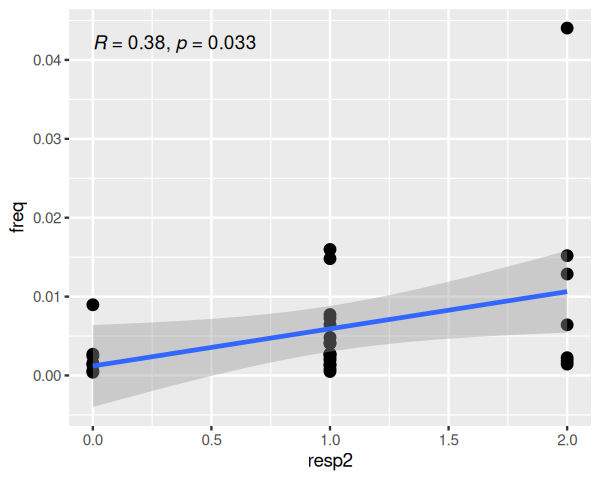

In [104]:
corr_table  %>% 
ggplot(aes(x=resp2, y=freq)) +
  geom_point(shape = 16, alpha = 1, size = 3) +
 geom_smooth(method=lm) +
ggpubr::stat_cor()

In [122]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
`geom_smooth()` using formula = 'y ~ x'


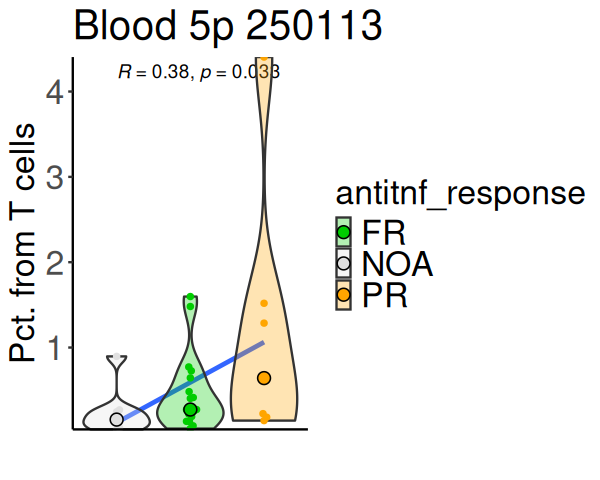

In [131]:
corr_table  %>% 
ggplot(aes(x=resp2, y=freq*100)) +
geom_smooth(method=lm, fullrange = TRUE, se = F) +
ggpubr::stat_cor() +
geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = antitnf_response), color = "black") +
  ylab("Pct. from T cells") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Blood 5p 250113") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange")) + ggtheme()

In [132]:
ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf_correlation.svg", 
       width = 14.5, height = 9, units = "cm")

`geom_smooth()` using formula = 'y ~ x'


# Annotations from 5p onto 3p

In [2]:
blood_5p  <- readRDS("data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

In [4]:
blood_5p$data_folder  %>% table  %>% length

[1] 97

In [111]:
saveRDS(blood_5p, "data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



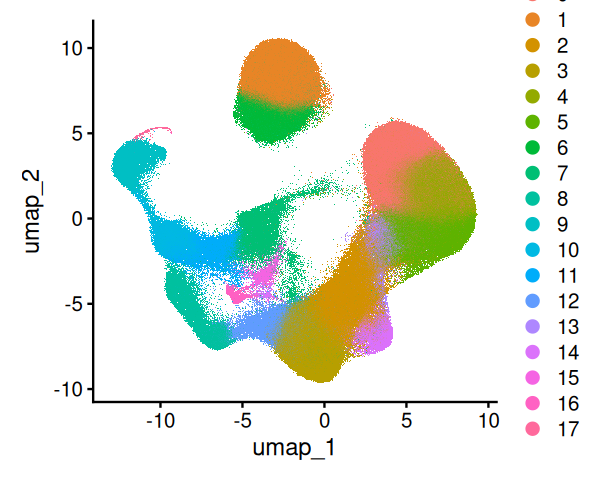

In [71]:
DimPlot(blood_5p)

In [597]:
library(Azimuth)

In [598]:
blood_5p.ref <- RunUMAP(blood_5p, dims = 1:12, reduction = "pca", return.model = TRUE)

UMAP will return its model

01:49:28 UMAP embedding parameters a = 0.9922 b = 1.112

01:49:28 Read 593574 rows and found 12 numeric columns

01:49:28 Using Annoy for neighbor search, n_neighbors = 30

01:49:28 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

01:51:01 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpWLi4ds/file35c9a5432058bf

01:51:01 Searching Annoy index using 1 thread, search_k = 3000

01:57:21 Annoy recall = 100%

01:57:25 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

01:58:20 Initializing from normalized Laplacian + noise (using RSpectra)

02:00:13 Commencing optimization for 200 epochs, with 25420110 positive edges

02:07:29 Optimization finished



In [569]:
ls()

[1] "all_contig_annotations" "all_md"                 "avgexp"                
 [4] "avgexp1"                "avgexp3"                "bld_available_data_vdj"
 [7] "bld_folders"            "blood_3p_filt"          "blood_3p_subset"       
[10] "blood_5p"               "blood_5p_samples"       "blood_subclust"        
[13] "clone_table"            "counts_of_patients"     "counts_of_patients2"   
[16] "create.VDJ.metadata2"   "data_folders"           "data_folders_df"       
[19] "df_filt"                "df4"                    "df8"                   
[22] "folder_process"         "folders_ready"          "genes.blocklist"       
[25] "ggtheme"                "i"                      "is_cd4_ctl"            
[28] "markers1"               "markers2"               "markers3"              
[31] "md"                     "md_3p"                  "md_3p_to_join"         
[34] "md_5p"                  "md_5p_to_join"          "md_filt"               
[37] "md_join"                "md_joint_with_tcr"      "md_predict"            
[40] "md_sub"                 "md_sub2"                "md_subclust_vsm"       
[43] "md_to_join"             "merged_ds"              "merged.list"           
[46] "metadata_6"             "mrk"                    "mrk_cd4_ctl"           
[49] "pallete_blood"          "participant_list"       "paths"                 
[52] "paths_folders_ready"    "predict_md"             "pt_in_new_cohort"      
[55] "res"                    "subclust"               "vdj_data_processed"

In [599]:
rm(blood_5p)

In [600]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,21519410,1149.3,32479247,1734.6,32479247,1734.6
Vcells,11340227693,86519.1,16492358030,125826.8,14962709337,114156.5


In [580]:
ls()

[1] "all_contig_annotations" "all_md"                 "avgexp"                
 [4] "avgexp1"                "avgexp3"                "bld_available_data_vdj"
 [7] "bld_folders"            "blood_3p_filt"          "blood_3p_subset"       
[10] "blood_5p_samples"       "blood_subclust"         "clone_table"           
[13] "counts_of_patients"     "counts_of_patients2"    "create.VDJ.metadata2"  
[16] "data_folders"           "data_folders_df"        "df_filt"               
[19] "df4"                    "df8"                    "folder_process"        
[22] "folders_ready"          "genes.blocklist"        "ggtheme"               
[25] "i"                      "is_cd4_ctl"             "markers1"              
[28] "markers2"               "markers3"               "md"                    
[31] "md_3p"                  "md_3p_to_join"          "md_5p"                 
[34] "md_5p_to_join"          "md_filt"                "md_join"               
[37] "md_joint_with_tcr"      "md_predict"             "md_sub"                
[40] "md_sub2"                "md_subclust_vsm"        "md_to_join"            
[43] "merged_ds"              "merged.list"            "metadata_6"            
[46] "mrk"                    "mrk_cd4_ctl"            "pallete_blood"         
[49] "participant_list"       "paths"                  "paths_folders_ready"   
[52] "predict_md"             "pt_in_new_cohort"       "res"                   
[55] "subclust"               "vdj_data_processed"

In [595]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,21518169,1149.2,32479247,1734.6,32479247,1734.6
Vcells,6814391218,51989.7,16492358030,125826.8,14962709337,114156.5


In [601]:
saveRDS(blood_5p.ref, "data/mapping_data_onto_predict/blood_5p_ref.rds")

In [602]:
blood_5p.ref$annotations  %>% table

.
          CD8_Naive           CD4_Naive  CD4_Central_Memory        CD4_Teff_Th2 
             106441              196865               57801               62393 
     CD4_Treg_Naive  CD4_Treg_Activated  CD8_Central_Memory CD8_Effector_Memory 
              17024               12014               27184               39620 
           NK_cells             CD8_Tgd   CD4_Teff_Th1/Th17              ISAGhi 
              22902               25271               17326                4840 
      Proliferating 
               3893 

In [603]:
blood_cdn.anchors <- FindTransferAnchors(reference = blood_5p.ref, query = blood_3p_filt,
    dims = 1:12, reference.reduction = "pca", query.assay="RNA")

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 65403 anchors



In [604]:
ref <- MapQuery(anchorset = blood_cdn.anchors, reference = blood_5p.ref, query = blood_3p_filt,
    refdata = blood_5p.ref$annotations, reference.reduction = "pca", reduction.model = "umap")

Finding integration vectors

Finding integration vector weights

Predicting cell labels

Warning message:
"Feature names cannot have underscores ('_'), replacing with dashes ('-')"
Warning message:
"Layer counts isn't present in the assay object; returning NULL"
Warning message:
"Layer counts isn't present in the assay object; returning NULL"
Warning message:
"Layer counts isn't present in the assay object; returning NULL"

Integrating dataset 2 with reference dataset

Finding integration vectors

Integrating data

Computing nearest neighbors

Running UMAP projection

03:18:45 Read 324539 rows

03:18:45 Processing block 1 of 1

03:18:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

03:18:49 Initializing by weighted average of neighbor coordinates using 1 thread

03:18:50 Commencing optimization for 67 epochs, with 9736170 positive edges

03:19:49 Finished



In [605]:
saveRDS(ref, "data/mapping_data_onto_predict/tcells_3p_blood_query.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



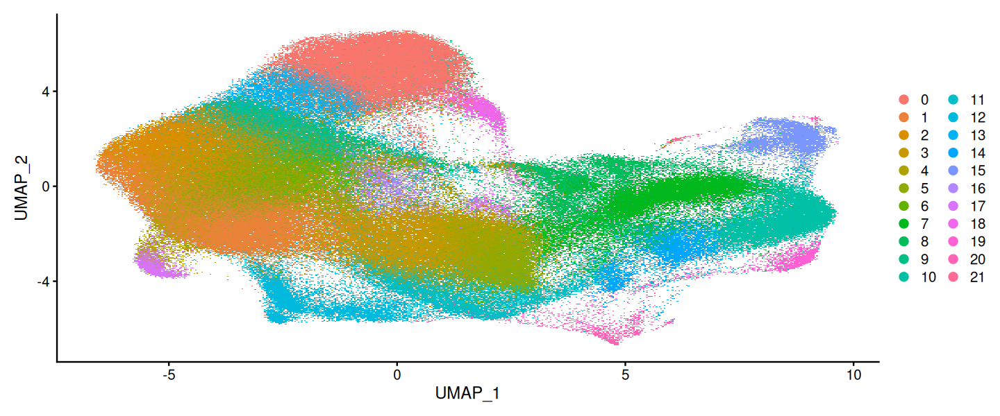

In [606]:
DimPlot(ref)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



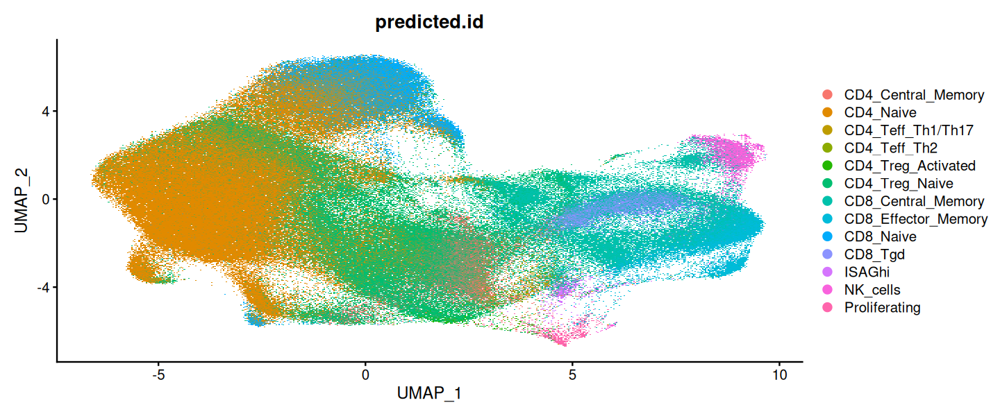

In [607]:
DimPlot(ref, group.by = "predicted.id")

In [608]:
ls()

[1] "blood_3p_filt"        "blood_5p.ref"         "blood_cdn.anchors"   
 [4] "blood_subclust"       "clone_table"          "create.VDJ.metadata2"
 [7] "df_filt"              "df4"                  "df8"                 
[10] "folder_process"       "folders_ready"        "genes.blocklist"     
[13] "ggtheme"              "i"                    "is_cd4_ctl"          
[16] "markers1"             "markers2"             "markers3"            
[19] "md"                   "md_3p"                "md_3p_to_join"       
[22] "md_5p"                "md_5p_to_join"        "md_filt"             
[25] "md_join"              "md_joint_with_tcr"    "md_predict"          
[28] "md_sub"               "md_sub2"              "md_subclust_vsm"     
[31] "md_to_join"           "merged_ds"            "merged.list"         
[34] "metadata_6"           "mrk"                  "mrk_cd4_ctl"         
[37] "pallete_blood"        "participant_list"     "paths"               
[40] "paths_folders_ready"  "predict_md"           "pt_in_new_cohort"    
[43] "ref"                  "res"                  "subclust"

In [609]:
rm(blood_3p_filt)
rm(blood_5p.ref)

In [610]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,22466673,1199.9,32479247,1734.6,32479247,1734.6
Vcells,2524057703,19257.1,22799268700,173944.7,22466276781,171404.1


In [4]:
blood_3p_stacas  <- readRDS("data/3p_blood_2021/blood_3p_integrated_stacas_sample.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



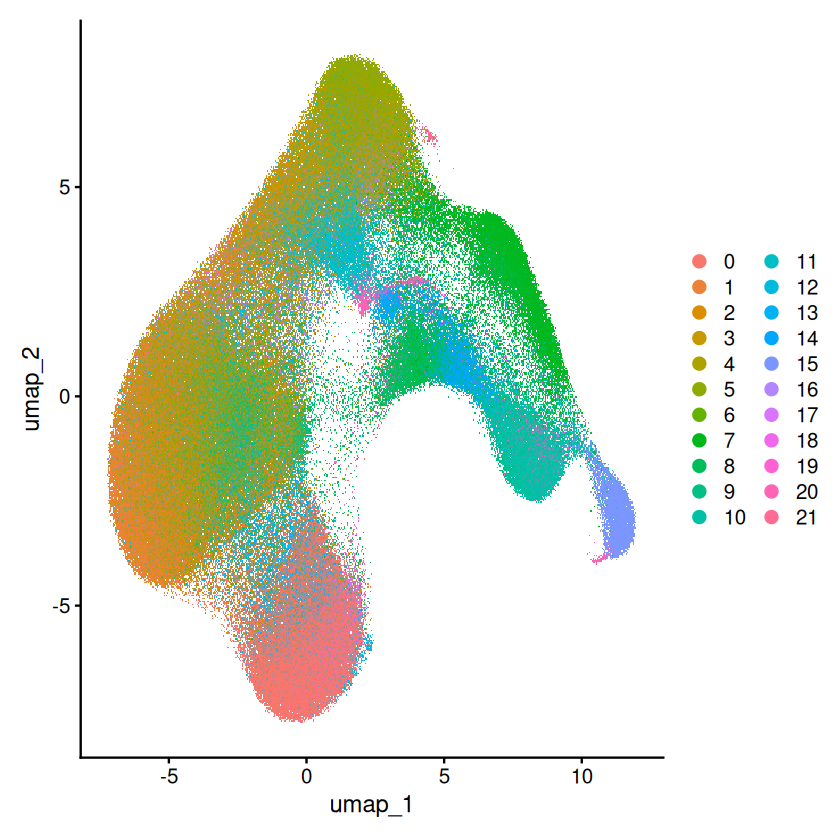

In [5]:
DimPlot(blood_3p_stacas)

In [176]:
DefaultAssay(blood_3p_stacas)

[1] "integrated"

In [177]:
blood_3p_stacas  <- FindNeighbors(blood_3p_stacas)
blood_3p_stacas  <- FindClusters(blood_3p_stacas, res = c(0.4, 0.6, 0.8,1,1.2))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 324539
Number of edges: 7099228

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8950
Number of communities: 12
Elapsed time: 226 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 324539
Number of edges: 7099228

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8738
Number of communities: 13
Elapsed time: 239 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 324539
Number of edges: 7099228

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8527
Number of communities: 16
Elapsed time: 243 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 324539
Number of edges: 7099228

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8371
Number of communities: 19
Elapsed time: 229 seco

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



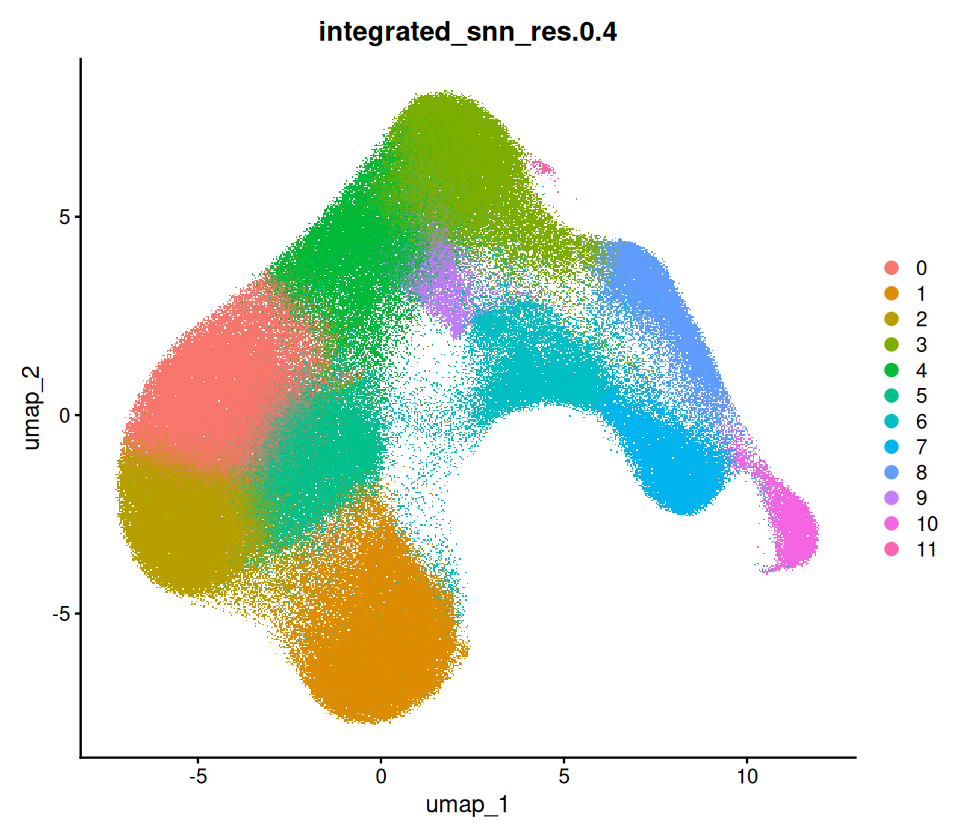

In [178]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(blood_3p_stacas, group.by = "integrated_snn_res.0.4")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



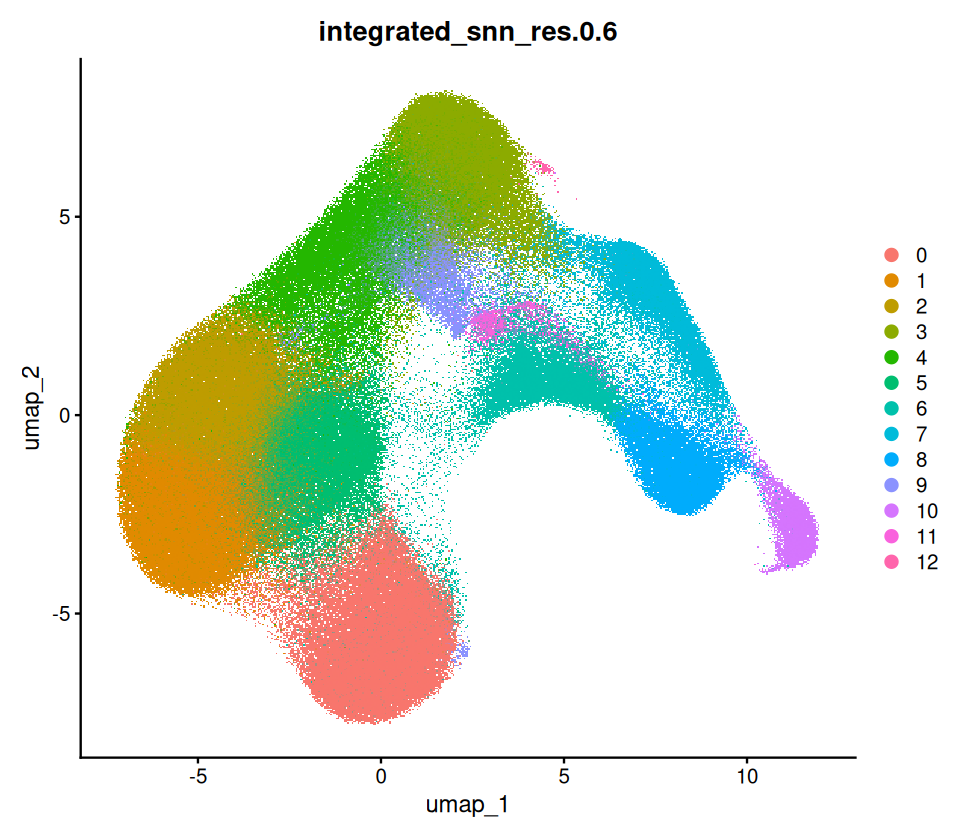

In [179]:
DimPlot(blood_3p_stacas, group.by = "integrated_snn_res.0.6")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



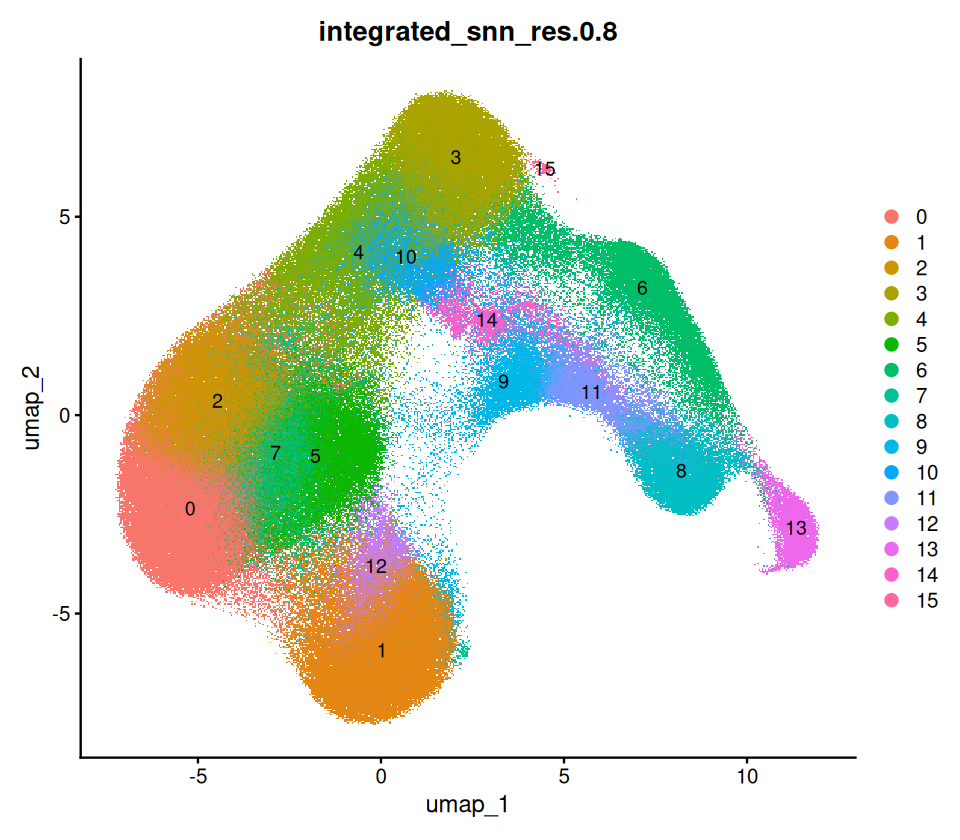

In [180]:
DimPlot(blood_3p_stacas, group.by = "integrated_snn_res.0.8", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



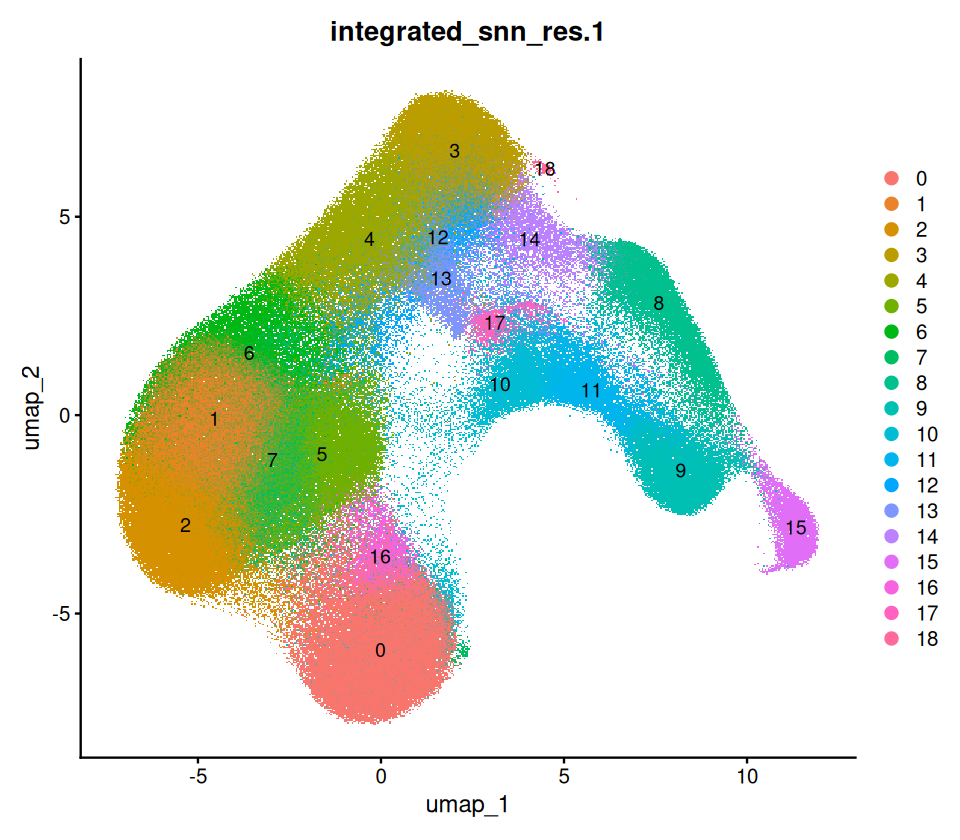

In [181]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(blood_3p_stacas, group.by = "integrated_snn_res.1", label = T)

## 3p annotations

In [8]:
markers3  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              
              "FOXP3", "IKZF2","IL2RA","CTLA4",
    "IFIT1","ISG15","OAS3","IRF7",
              "IL4","IL13",'IL5',  "GATA3",
              "CCR6", 'CXCR3',"IL17F","IL26","TNF",'RORA',"RORC" ,
              "IL23R","CXCR6","KLRB1","ZBTB16","CCL5","EOMES", "IFNG",
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
              "IL17A",'IL21',"MKI67", "PCNA", "MCM6")

In [88]:
avgexp3 = AverageExpression(blood_3p_stacas, features = markers3, group.by = "integrated_snn_res.1",
                          assay = "RNA")

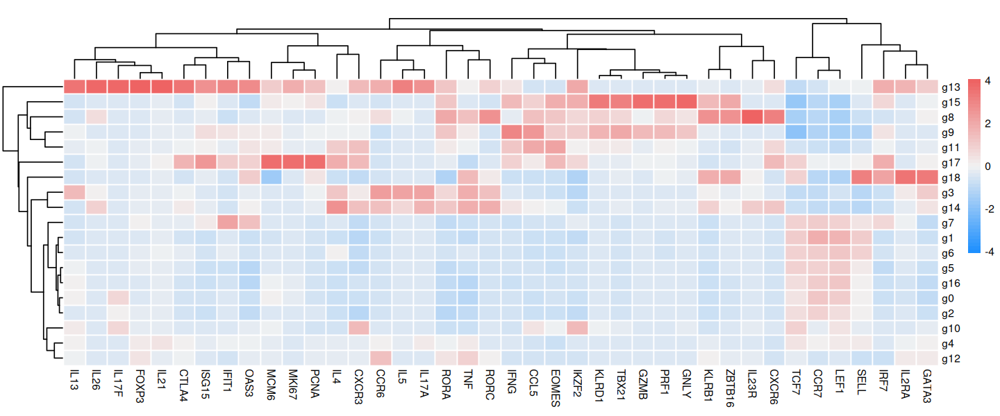

In [89]:
options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [182]:
blood_3p_stacas@meta.data <- blood_3p_stacas@meta.data  %>% mutate(seurat_clusters2 = recode_factor(integrated_snn_res.1, 
                                                                              "0" = '1',
                                                                               "1" = "2",
                                                                               "2" = "2",
                                                                               "3" = "3",
                                                                               "4" = "4",
                                                                               "5" = "2",
                                                                               "6" = "2",
                                                                               "7" = "2",
                                                                               "8" = "10",
                                                                               "9" = "8",
                                                                               "10" = "7",
                                                                               "11" = "8",
                                                                               "12" = "5",
                                                                               "13" = "6",
                                                                               "14" = "11",
                                                                               "15" = "9",
                                                                               "16" = "1",
                                                                               "17" = "13",
                                                                               "18" = "3"))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



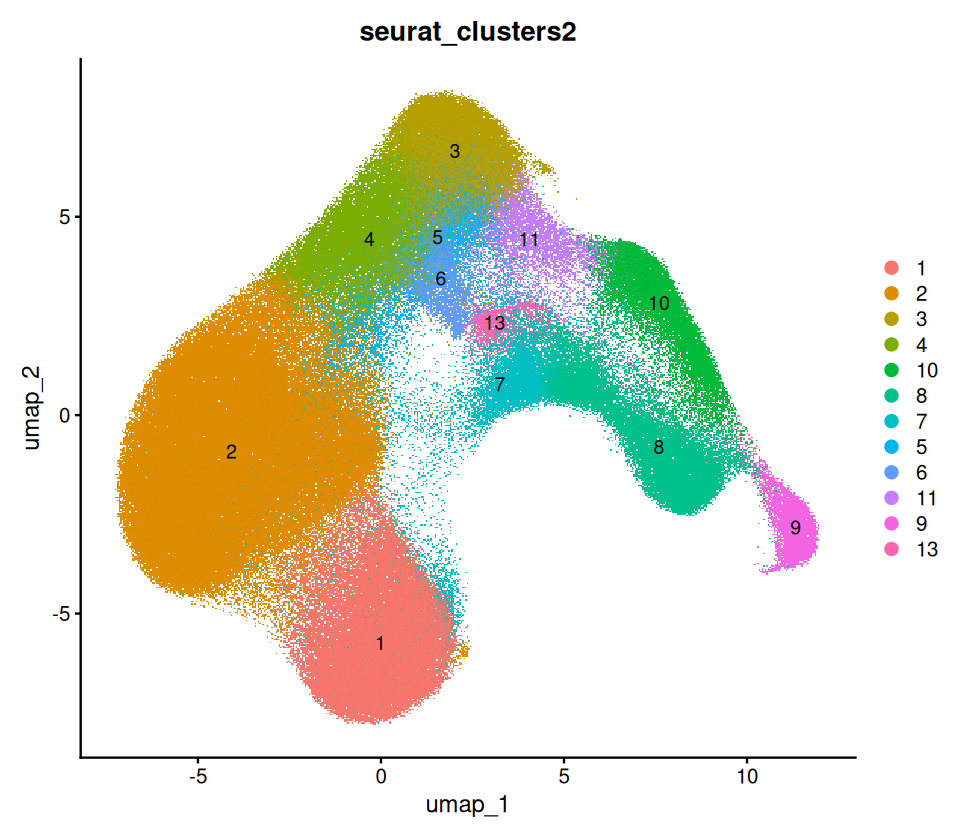

In [183]:
DimPlot(blood_3p_stacas, group.by = "seurat_clusters2", label = T)

In [6]:
blood_3p_stacas  <- FindNeighbors(blood_3p_stacas)
blood_3p_stacas  <- FindClusters(blood_3p_stacas, res = c(1.2))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 324539
Number of edges: 7099228

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8253
Number of communities: 21
Elapsed time: 246 seconds


In [9]:
avgexp3 = AverageExpression(blood_3p_stacas, features = markers3, group.by = "integrated_snn_res.1.2",
                          assay = "RNA")

First group.by variable `integrated_snn_res.1.2` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.


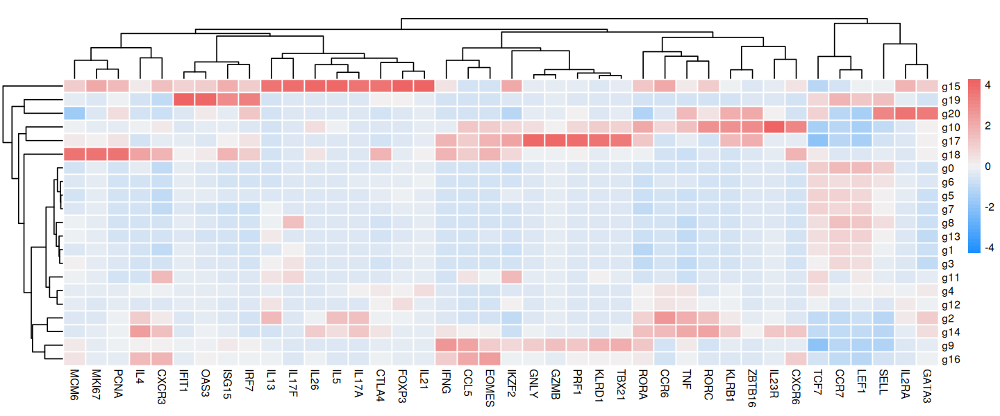

In [10]:
options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [12]:
blood_3p_stacas@meta.data <- blood_3p_stacas@meta.data  %>% mutate(seurat_clusters2 = recode_factor(integrated_snn_res.1.2, 
                                                                              "0" = '2',
                                                                               "1" = '2',
                                                                               "2" = '4',
                                                                               "3" = '1',
                                                                               "4" = '3',
                                                                               "5" = '2',
                                                                               "6" = '2',
                                                                               "7" = '2',
                                                                               "8" = '1',
                                                                               "9" = '8',
                                                                               "10" = '10',
                                                                               "11" = '7',
                                                                               "12" = '5',
                                                                               "13" = '1',
                                                                               "14" = '11',
                                                                               "15" = '6',
                                                                               "16" = '7',
                                                                               "17" = '9',
                                                                               "18" = '13',
                                                                               "19" = '12',
                                                                               "20" = '4'
                                                                                     ))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



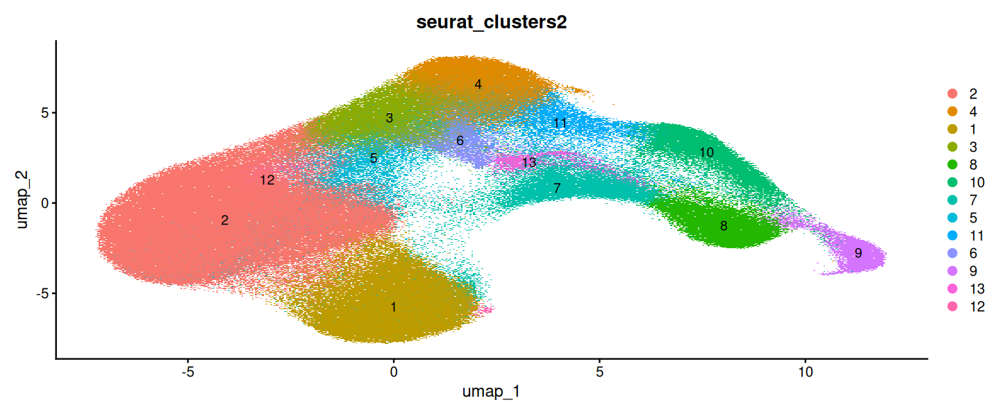

In [13]:
DimPlot(blood_3p_stacas, group.by = "seurat_clusters2", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



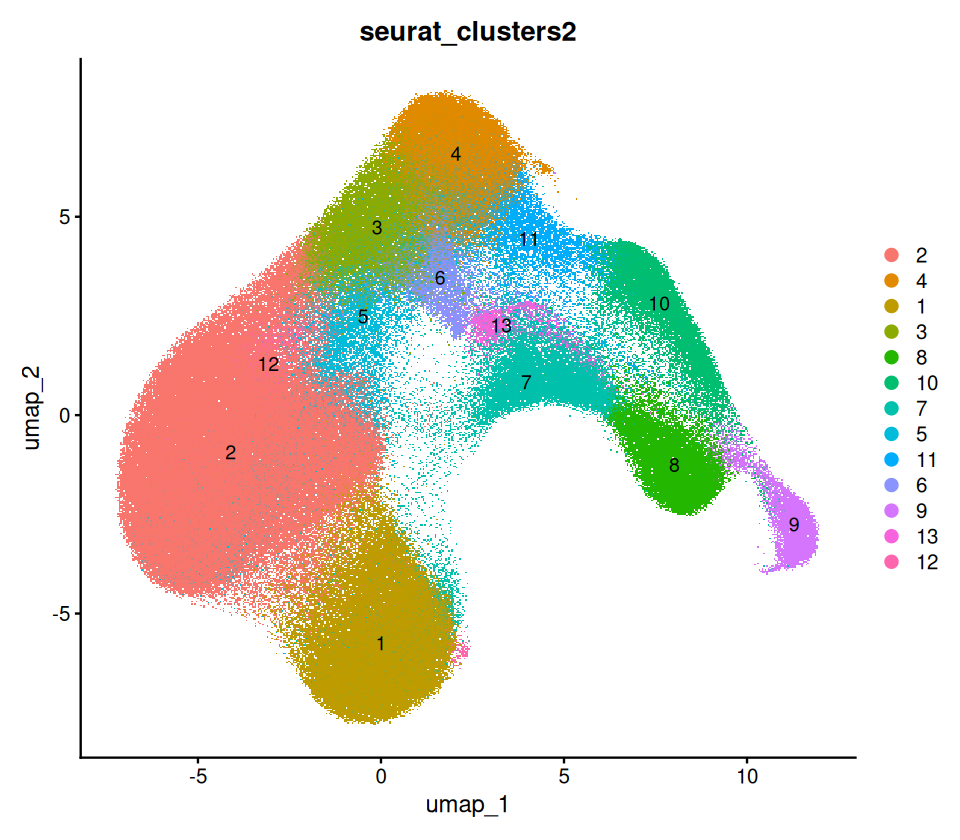

In [185]:
DimPlot(blood_3p_stacas, group.by = "seurat_clusters2", label = T)

In [186]:
pallete_blood  <- c(
"1" =  "#89b8da",
"2" =  "#F1CE63",
"3" =  '#D39200',
"4" =  '#AAA300',
"5" =  'indianred2',
"6" =  '#FF61C9',
"7" =  '#00B6EB',
"8" =  '#00BFC2',
"9" =  '#00C08C',
"10" =  "#9D7660" ,
"11" =  '#6DB100',
"12" =  '#D4A6C8',
"13" =  '#B07AA1'
)


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



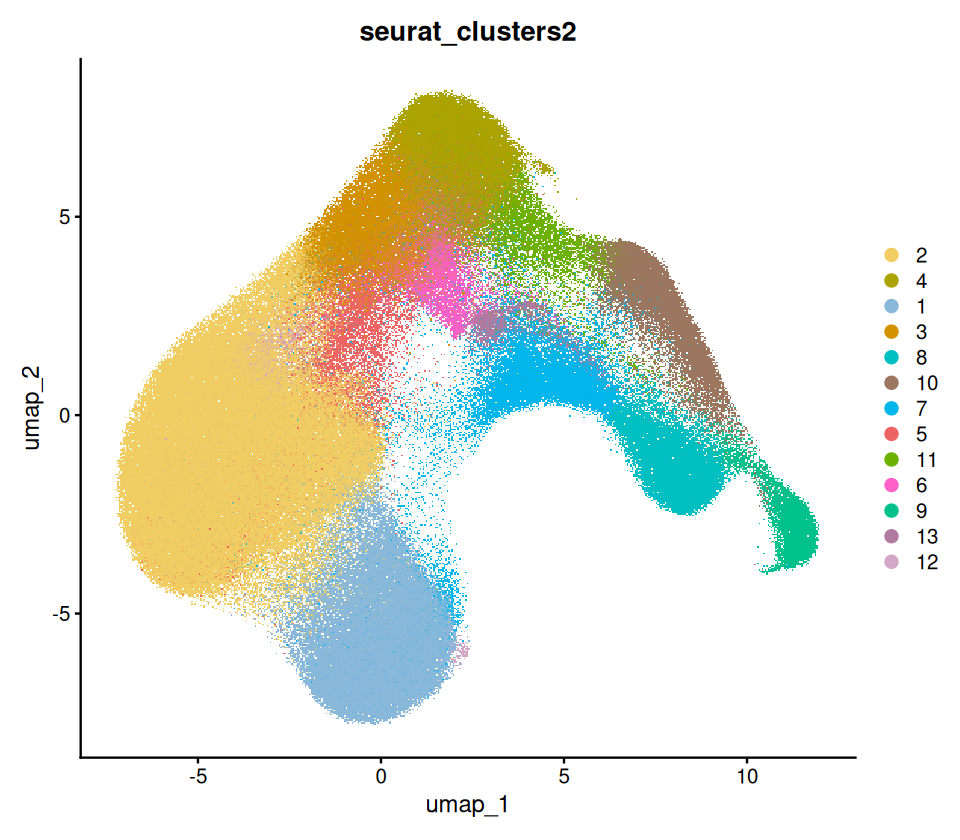

In [187]:
DimPlot(blood_3p_stacas, group.by = "seurat_clusters2", label = F, cols = pallete_blood)

In [14]:
markers1  <- rev(c("CD3E","CD3D","CD4","CD8A","CD8B","TRDV2","TRGV9","FCER1G","NCR1"))
markers3  <- c('LEF1', 'TCF7', 'SELL', 'CCR7', 'FOXP3', 'IKZF2', 'IL2RA', 'CTLA4', 'IFIT1', 'ISG15', 'IRF7',
              "IL4","IL13","GATA3",  
              'CXCR3',"CCR6", "CCR6","TNF","RORA","CXCR3",
                             "IL23R","KLRB1","ZBTB16","CCL5","EOMES", 
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
               "MKI67", "PCNA", "MCM6","IL17F", "IL17A",'IL21',
               "CXCR6","RORC","IL26","IFNG"
               

              
              )

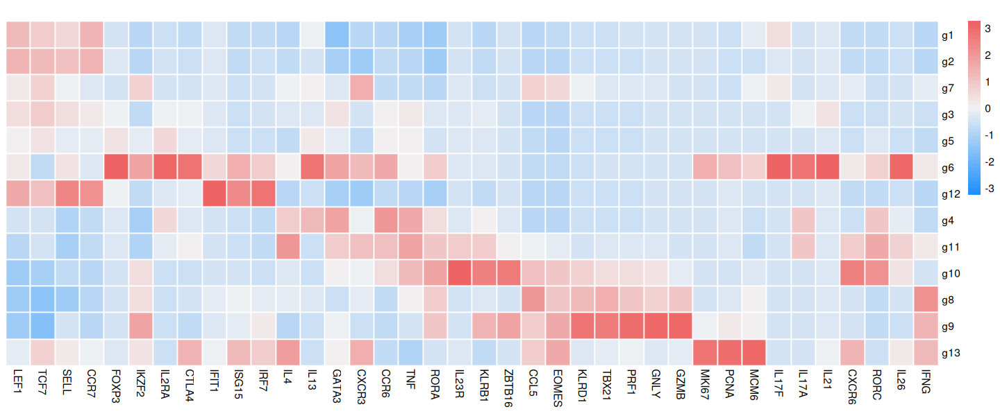

In [19]:
avgexp3 = AverageExpression(blood_3p_stacas, features = markers3, group.by = "seurat_clusters2",
                          assay = "RNA")

options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA)[c(3,1,7,4,8,10,13,2,9,6,5,11,12),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [20]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp3$RNA)[c(3,1,7,4,8,10,13,2,9,6,5,11,12),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 10, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood3p_partv3.pdf")

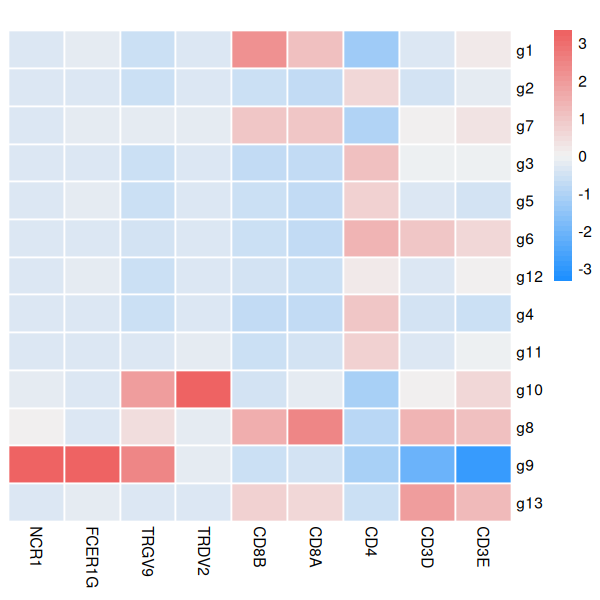

In [22]:
avgexp1 = AverageExpression(blood_3p_stacas, features = markers1, group.by = "seurat_clusters2",
                          assay = "RNA")

options(repr.plot.width = 5, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp1$RNA)[c(3,1,7,4,8,10,13,2,9,6,5,11,12),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [23]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp1$RNA)[c(3,1,7,4,8,10,13,2,9,6,5,11,12),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 4, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood_partv1_3p_v3.pdf")

## 3p heatmap markers

In [250]:
markers1  <- rev(c("CD3E","CD3D","CD4","CD8A","CD8B","TRDV2","TRGV9","FCER1G","NCR1"))

In [246]:
markers3  <- c('LEF1', 'TCF7', 'SELL', 'CCR7', 'FOXP3', 'IKZF2', 'IL2RA', 'CTLA4', 'IFIT1', 'ISG15', 'IRF7',
              "IL4","IL13","GATA3",  
              'CXCR3',"CCR6", "CCR6","TNF","RORA","CXCR3",
                             "IL23R","KLRB1","ZBTB16","CCL5","EOMES", 
               'KLRD1',"TBX21",'PRF1',"GNLY",'GZMB',
               "MKI67", "PCNA", "MCM6","IL17F", "IL17A",'IL21',
               "CXCR6","RORC","IL26","IFNG"
               

              
              )

In [ ]:
blood_3p_stacas$cd4_ctl

In [234]:
blood_3p_stacas$seurat_clusters3  <- if_else(blood_3p_stacas$cd4_ctl == TRUE,"CD4_CTL",blood_3p_stacas$seurat_clusters2)

In [235]:
table(blood_3p_stacas$seurat_clusters3)


      1      10      11      12      13       2       3       4       5       6 
  52177   15734    7139    2068    2709  128539   22259   29636   11697    7008 
      7       8       9 CD4_CTL 
  20559   17344    6744     926 

In [240]:
avgexp3$RNA

  [[ suppressing 14 column names ‘g1’, ‘g10’, ‘g11’ ... ]]



40 x 14 sparse Matrix of class "dgCMatrix"
                                                                      
LEF1   2.962515e+00 2.965211e-01 7.389680e-01 3.351537376 1.448757e+00
TCF7   2.384415e+00 1.052090e+00 1.463383e+00 2.604502207 2.315228e+00
SELL   4.497767e+00 2.376562e+00 1.890405e+00 7.473718912 3.890831e+00
CCR7   5.707639e+00 4.354607e-01 7.990147e-01 7.736860782 2.293576e+00
FOXP3  2.892168e-03 3.242494e-03 1.249259e-02 0.055201976 2.126157e-02
IKZF2  4.229674e-02 1.590726e-01 3.650091e-02 0.061925628 1.573774e-01
IL2RA  5.109264e-03 1.299552e-02 8.764921e-02 0.080737213 1.733493e-02
CTLA4  4.618690e-03 1.711450e-02 7.167837e-02 0.048251838 1.811485e-01
IFIT1  9.551892e-02 4.349100e-02 6.021334e-02 2.429393958 3.386943e-01
ISG15  9.531083e-01 1.452329e+00 1.396857e+00 8.567307208 6.014762e+00
IRF7   2.502919e-01 2.936957e-01 2.455365e-01 1.801468052 9.396795e-01
IL4    .            9.268954e-04 4.818916e-03 .           4.366608e-03
IL5    .            2.132057e-04 8

In [244]:
t(avgexp3$RNA)

  [[ suppressing 39 column names ‘LEF1’, ‘TCF7’, ‘SELL’ ... ]]



14 x 39 sparse Matrix of class "dgCMatrix"
                                                                      
g1      2.9625155 2.3844151 4.4977673 5.7076388 0.002892168 0.04229674
g10     0.2965211 1.0520901 2.3765619 0.4354607 0.003242494 0.15907261
g11     0.7389680 1.4633833 1.8904053 0.7990147 0.012492588 0.03650091
g12     3.3515374 2.6045022 7.4737189 7.7368608 0.055201976 0.06192563
g13     1.4487569 2.3152280 3.8908313 2.2935763 0.021261567 0.15737744
g2      3.0558592 2.6882859 5.3383536 5.7394494 0.018385223 0.04152723
g3      2.1182778 2.3878422 4.4394853 2.8770205 0.060244173 0.05842671
g4      1.1086237 1.4387459 1.9340415 0.9024589 0.026114638 0.01622387
g5      1.7160438 2.0697417 3.3276415 2.2016631 0.104179359 0.10284849
g6      1.7814764 1.3594348 4.2493457 1.8094597 0.534128947 0.29547514
g7      1.7979898 2.3525954 3.4437208 1.8572954 0.008865354 0.18189709
g8      0.3747471 0.7282272 1.4939549 0.3759890 0.007127802 0.16260309
g9      0.2899736 0.6747331 2.9706

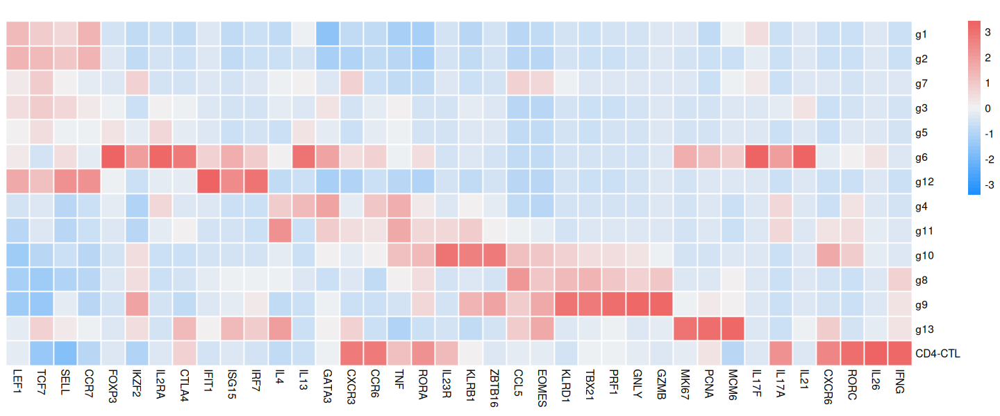

In [252]:
avgexp3 = AverageExpression(blood_3p_stacas, features = markers3, group.by = "seurat_clusters3",
                          assay = "RNA")

options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp3$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [254]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp3$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 10, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood3p_partv2.pdf")

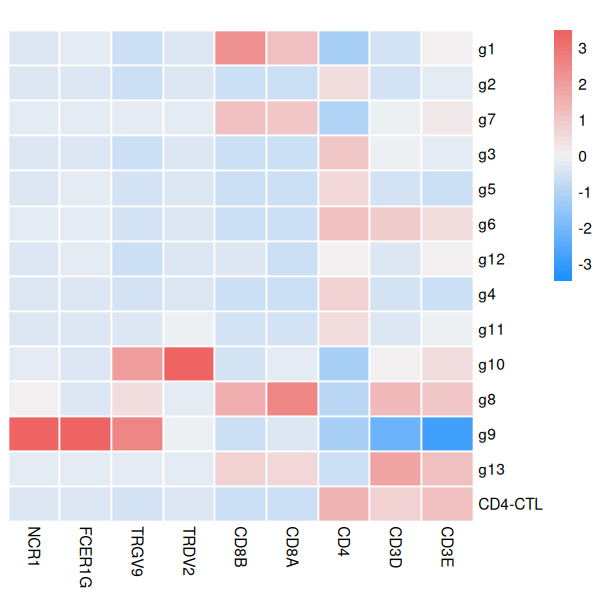

In [253]:
avgexp1 = AverageExpression(blood_3p_stacas, features = markers1, group.by = "seurat_clusters3",
                          assay = "RNA")

options(repr.plot.width = 5, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp1$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [255]:
options(repr.plot.width = 15, repr.plot.height = 5)
hm  <- pheatmap::pheatmap(t(avgexp1$RNA)[c(1,6,11,7,9,10,4,8,3,2,12,13,5,14),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 4, height = 4,
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_blood_partv1_3p.pdf")

In [101]:
blood_3p_subset  <- readRDS("data/3p_blood_2021/vn_Tcells_3p_5p_datasets_blood_3p_subset.rds")

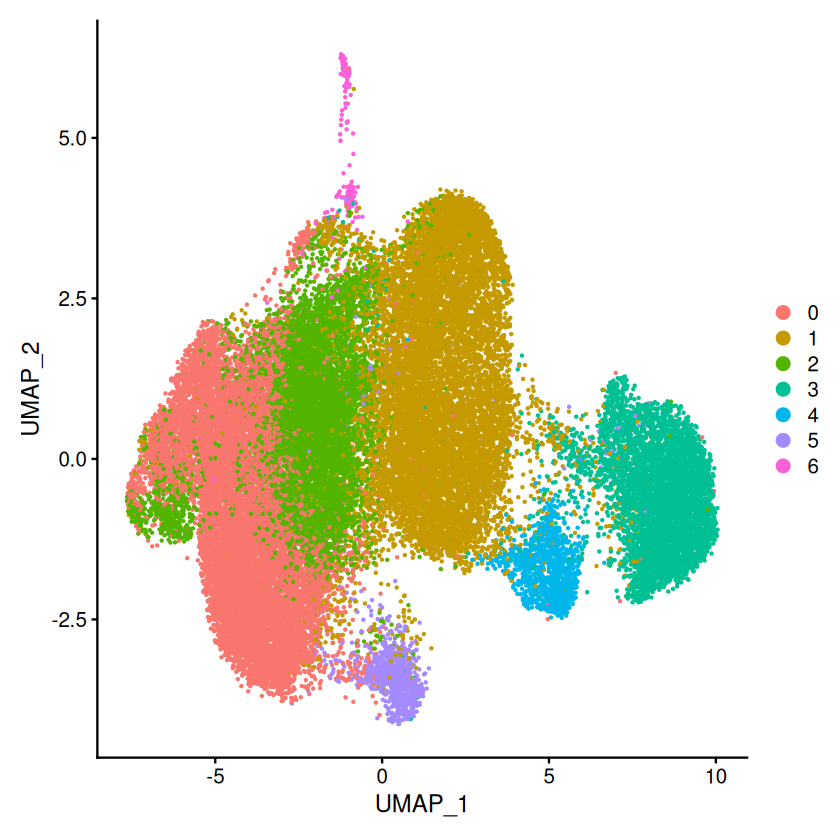

In [12]:
DimPlot(blood_3p_subset)

In [44]:
blood_3p_subset

An object of class Seurat 
26782 features across 39832 samples within 1 assay 
Active assay: RNA (26782 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [45]:
mrk2  <- FindAllMarkers(blood_3p_subset)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6



In [46]:
mrk3  <- FindMarkersrkers(blood_3p_subset, ident.1 = 5)

In [47]:
mrk3

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ID2,0.000000e+00,2.5264967,0.739,0.214,0.000000e+00
AC092580.4,0.000000e+00,2.9492555,0.598,0.110,0.000000e+00
CHN1,0.000000e+00,4.0656676,0.349,0.020,0.000000e+00
CXCR6,0.000000e+00,3.3105604,0.246,0.024,0.000000e+00
IFNG,0.000000e+00,3.8839600,0.195,0.012,0.000000e+00
CPNE7,0.000000e+00,3.9428023,0.195,0.014,0.000000e+00
NMU,0.000000e+00,5.6079444,0.178,0.004,0.000000e+00
GOLIM4,0.000000e+00,4.4934690,0.131,0.005,0.000000e+00
SLC4A10,0.000000e+00,5.1258448,0.129,0.004,0.000000e+00


In [52]:
write.csv2(mrk3, "mrk_3p_blood.csv")

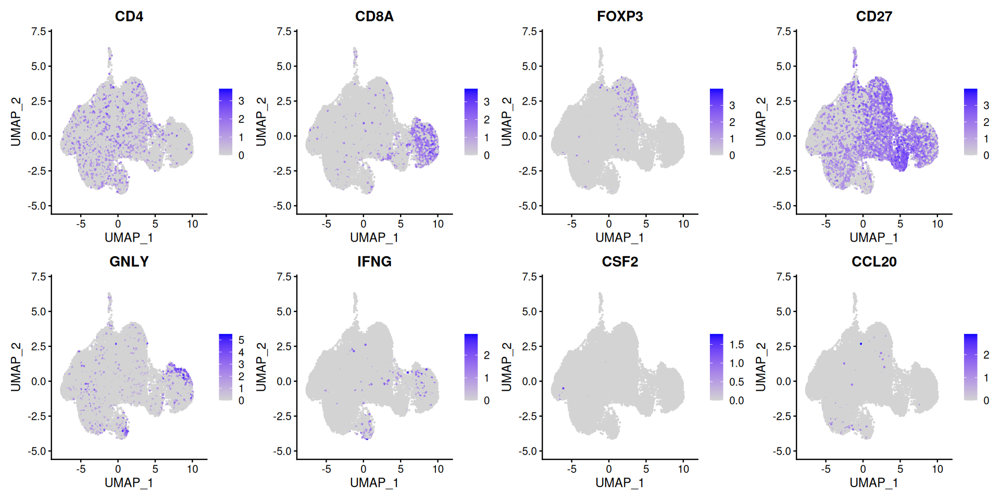

In [103]:
options(repr.plot.width = 16, repr.plot.height = 8)
FeaturePlot(blood_3p_subset, features = c("CD4","CD8A","FOXP3","CD27","GNLY","IFNG","CSF2","CCL20"), ncol = 4)

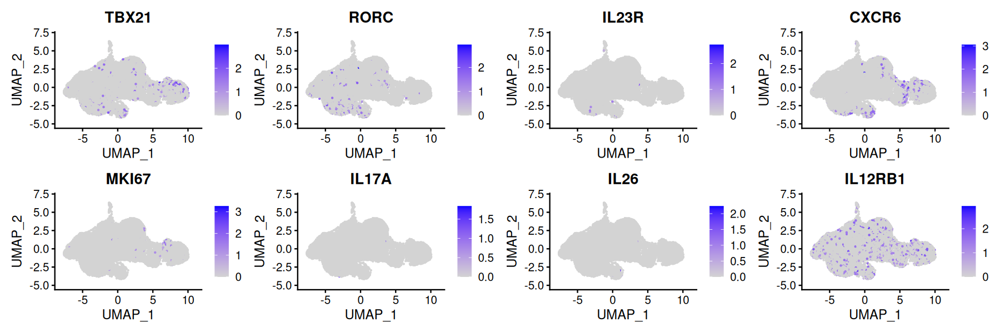

In [256]:
FeaturePlot(blood_3p_subset, features = c("TBX21","RORC","IL23R","CXCR6","MKI67","IL17A","IL26","IL12RB1"), ncol = 4)

In [13]:
cl5  <- colnames(subset(blood_3p_subset, seurat_clusters == 5))

In [14]:
blood_3p_stacas$cd4_ctl  <- colnames(blood_3p_stacas) %in% cl5

In [15]:
table(blood_3p_stacas$cd4_ctl)


 FALSE   TRUE 
323613    926 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



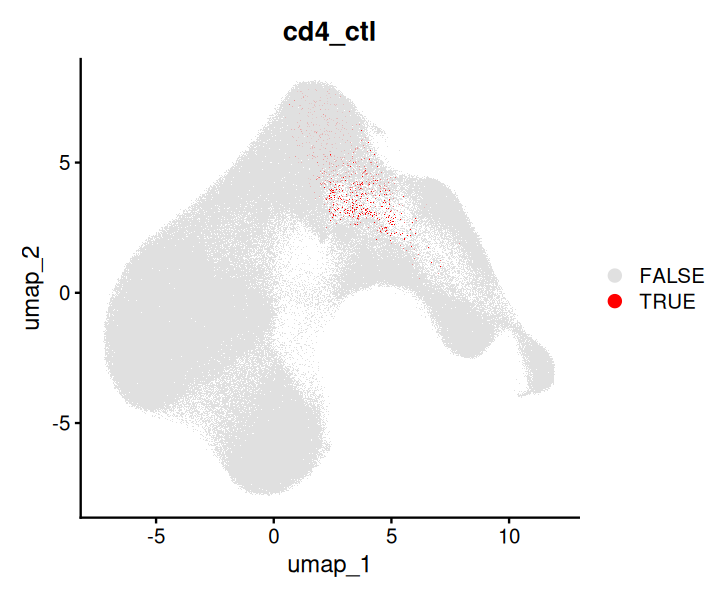

In [16]:
options(repr.plot.width = 6, repr.plot.height = 5)

DimPlot(blood_3p_stacas, group.by = "cd4_ctl", label = F, cols = c("grey88","red"))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



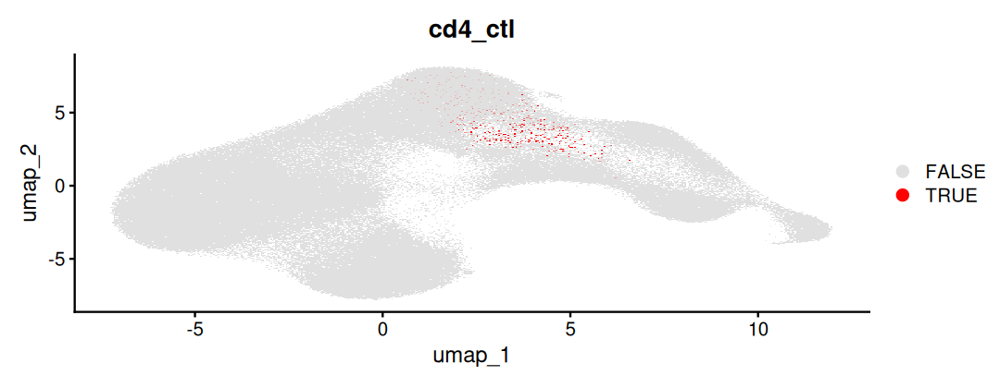

In [39]:
DimPlot(blood_3p_stacas, group.by = "cd4_ctl", label = F, cols = c("grey88","red"))

In [40]:
Idents(blood_3p_stacas)  <- blood_3p_stacas$cd4_ctl

In [41]:
mrk  <- FindAllMarkers(blood_3p_stacas, only.pos = T)

Calculating cluster FALSE

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Calculating cluster TRUE

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”


In [51]:
mrk3

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ID2,0.000000e+00,2.5264967,0.739,0.214,0.000000e+00
AC092580.4,0.000000e+00,2.9492555,0.598,0.110,0.000000e+00
CHN1,0.000000e+00,4.0656676,0.349,0.020,0.000000e+00
CXCR6,0.000000e+00,3.3105604,0.246,0.024,0.000000e+00
IFNG,0.000000e+00,3.8839600,0.195,0.012,0.000000e+00
CPNE7,0.000000e+00,3.9428023,0.195,0.014,0.000000e+00
NMU,0.000000e+00,5.6079444,0.178,0.004,0.000000e+00
GOLIM4,0.000000e+00,4.4934690,0.131,0.005,0.000000e+00
SLC4A10,0.000000e+00,5.1258448,0.129,0.004,0.000000e+00


In [43]:
mrk  %>% dplyr::filter(cluster == "TRUE")

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
S100A4,0.000000e+00,1.7138649,1.000,0.930,0.000000e+00,TRUE,S100A4
CD52,1.225747e-247,0.9158749,1.000,0.993,1.225747e-244,TRUE,CD52
IL32,3.513931e-243,1.1076170,0.997,0.953,3.513931e-240,TRUE,IL32
CD74,1.339182e-221,1.7880400,0.929,0.751,1.339182e-218,TRUE,CD74
SH3BGRL3,3.329154e-217,0.9894074,0.999,0.959,3.329154e-214,TRUE,SH3BGRL3
S100A6,1.526890e-209,1.0887889,0.992,0.933,1.526890e-206,TRUE,S100A6
ITGB1,1.294092e-208,1.6522377,0.957,0.893,1.294092e-205,TRUE,ITGB1
KIAA0101,1.525376e-198,2.2390631,0.911,0.811,1.525376e-195,TRUE,KIAA0101
GAPDH,3.128124e-184,1.0279987,0.989,0.938,3.128124e-181,TRUE,GAPDH


In [17]:
md_filt <- blood_3p_stacas@meta.data

df4 <- md_filt %>% 
group_by(patient, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!patient, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md_filt %>% dplyr::select(disease, antiTNF_response, patient) %>% 
unique()
df4  <- left_join(df4, md_to_join, by = "patient")



`summarise()` has grouped output by 'patient'. You can override using the
`.groups` argument.


In [18]:
df4

patient,seurat_clusters,freq,disease,antiTNF_response
<chr>,<chr>,<dbl>,<chr>,<chr>
p002,FALSE,0.9989497024,FGID,NM
p002,TRUE,0.0010502976,FGID,NM
p003,FALSE,1.0000000000,FGID,NM
p003,TRUE,0.0000000000,FGID,NM
p009,FALSE,1.0000000000,FGID,NM
p009,TRUE,0.0000000000,FGID,NM
p010,FALSE,0.9959514170,CD,PR
p010,TRUE,0.0040485830,CD,PR
p011,FALSE,0.9998580352,CD,RESP


In [19]:
options(repr.plot.width = 5, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(seurat_clusters == "TRUE" & disease == "CD")  %>% 
mutate(antitnf_response = ifelse(antiTNF_response == "NM", "NOA", antiTNF_response))  %>% 
mutate(antitnf_response = ifelse(antitnf_response == "RESP", "FR", antitnf_response)) 

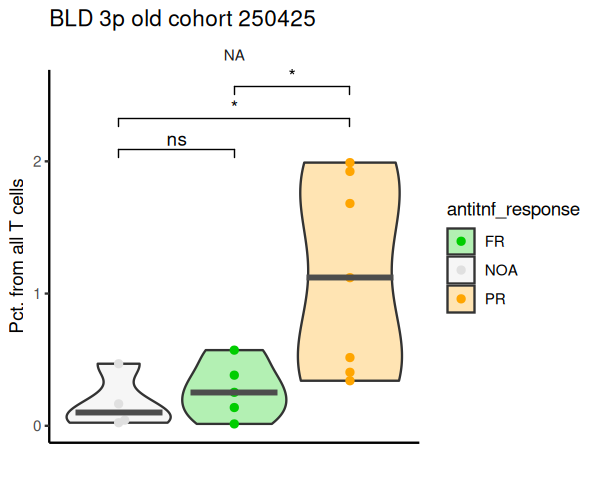

In [20]:
df_filt  %>% 
ggplot(aes(x = factor(antitnf_response, levels = c("NM","NOA","FR","PR","NR")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 2, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~factor(seurat_clusters, levels = c(1:11, "Other")), scales = "free", ncol = 12) +
  ylab("Pct. from all T cells") +
  xlab("") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange", "NR" = "red")) +
  #scale_y_continuous(expand = c(NA,40))+
  ylim(c(0,NA))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "BLD 3p old cohort 250425") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.signif") 

#ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250109_blood_5p_new_cohort_atnf.svg", width = 45, height = 9, units = "cm")

In [123]:
corr_table  <- df_filt  %>%  
mutate(resp2 = case_when(antitnf_response == "NOA" ~0 ,
                         antitnf_response == "FR" ~ 1,
                         antitnf_response == "PR" ~ 2
                         ))

In [124]:
corr_table

patient,seurat_clusters,freq,disease,antiTNF_response,antitnf_response,resp2
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>
p010,TRUE,0.0040485830,CD,PR,PR,2
p011,TRUE,0.0001419648,CD,RESP,FR,1
p014,TRUE,0.0057224607,CD,RESP,FR,1
p016,TRUE,0.0013812950,CD,RESP,FR,1
p018,TRUE,0.0051600307,CD,PR,PR,2
p019,TRUE,0.0004249120,CD,NOA,NOA,0
p022,TRUE,0.0038293217,CD,RESP,FR,1
p024,TRUE,0.0034067681,CD,PR,PR,2
p026,TRUE,0.0002332906,CD,NOA,NOA,0


`geom_smooth()` using formula = 'y ~ x'


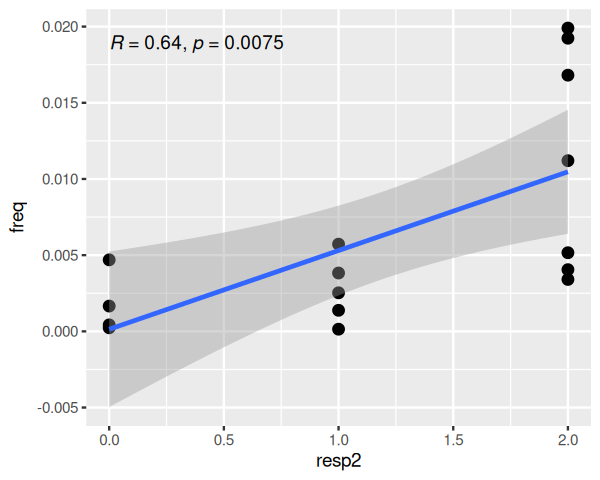

In [125]:
corr_table  %>% 
ggplot(aes(x=resp2, y=freq)) +
  geom_point(shape = 16, alpha = 1, size = 3) +
 geom_smooth(method=lm) +
ggpubr::stat_cor()

In [122]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

`geom_smooth()` using formula = 'y ~ x'


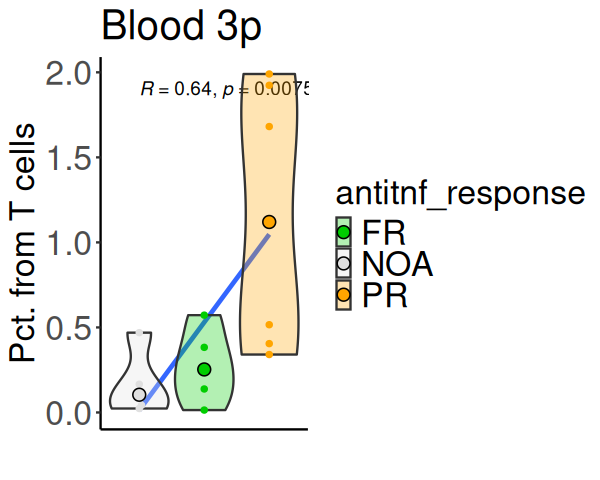

In [127]:
corr_table  %>% 
ggplot(aes(x=resp2, y=freq*100)) +
geom_smooth(method=lm, fullrange = TRUE, se = F) +
ggpubr::stat_cor() +
geom_violin(alpha = 0.3, aes(fill = antitnf_response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = antitnf_response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "point", 
              shape = 21,
               size = 3,
               aes(fill = antitnf_response), color = "black") +
  ylab("Pct. from T cells") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Blood 3p") +
scale_color_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange")) +
scale_fill_manual(values = c("NM" = "grey88", "NOA" = "grey88", 
                             "FR" = "green3", "PR" = "orange")) + ggtheme()

In [128]:
ggsave(create.dir = T, "figures/boxplot_freq_blood_integration/250424_blood_3p_old_correlation.svg", 
       width = 14.5, height = 9, units = "cm")

`geom_smooth()` using formula = 'y ~ x'


## Count of samples

In [26]:
blood_3p_stacas$layer  %>% table

.
   CD3 
324539 

In [28]:
blood_3p_stacas@meta.data  %>% group_by(patient, time, disease)  %>% tally  %>% 
ungroup  %>% 
dplyr::filter(n>100 & disease %in% c("HEA","CD","FGID","UC") & time != "T3M")  %>% 
dplyr::select(-n)  %>% 
group_by(patient, time, disease)  %>% 
tally()

patient,time,disease,n
<chr>,<chr>,<chr>,<int>
p002,T0D,FGID,1
p003,T0D,FGID,1
p009,T0D,FGID,1
p010,T0D,CD,1
p011,T0D,CD,1
p014,T0D,CD,1
p015,T0D,UC,1
p016,T0D,CD,1
p017,T0D,FGID,1


In [31]:
blood_3p_stacas@meta.data  %>% group_by(patient, time, disease)  %>% tally  %>% 
ungroup  %>% 
dplyr::filter(n>100 & disease %in% c("HEA","CD","FGID","UC") & time != "T3M")  %>% 
dplyr::select(-n)  %>% 
group_by(patient, time, disease)  %>% 
tally() %>% 
ungroup  %>% 
dplyr::select(-n)  %>% 
group_by(disease)  %>% 
tally() 

disease,n
<chr>,<int>
CD,16
FGID,16
UC,4


## Freq CD4 CTL blood vs gut

## 3p subclustering

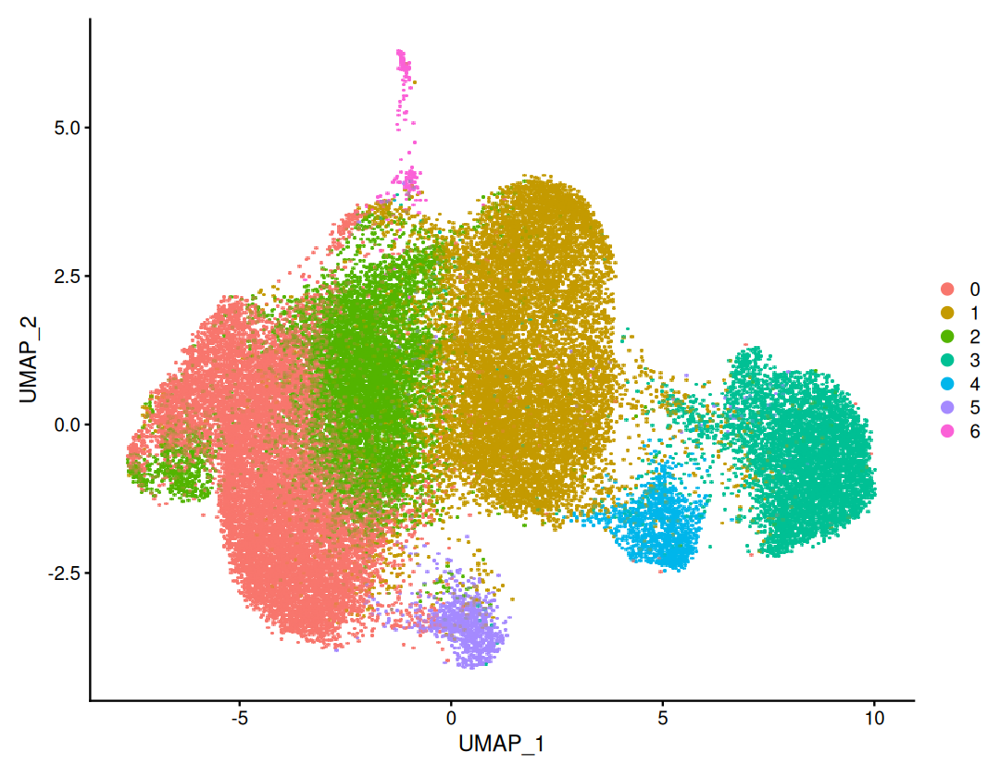

In [172]:
options(repr.plot.width = 9, repr.plot.height = 7)
DimPlot(blood_3p_subset, label = F, raster = T, raster.dpi = c(600,600), pt.size = 2)

In [146]:
blood_3p_stacas$subclustering  <- colnames(blood_3p_stacas) %in% colnames(blood_3p_subset)

In [ ]:
avgexp3p_sub = AverageExpression(blood_3p_subset, 
                            features = c("TNF","CXCR3","GZMB","PRF1",
                                         "TBX21","CCR6","RORC","CXCR6","CD27","HLA-DRB1",
                                         "GZMA","PRF1","IFNG","IL26","CD8A","CD8B","MKI67","PCNA","MCM6"
                                        ), 
                            group.by = "seurat_clusters",
                          assay = "RNA")

options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp3p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_3p_heatmap.pdf",
                  width = 4, height = 5)

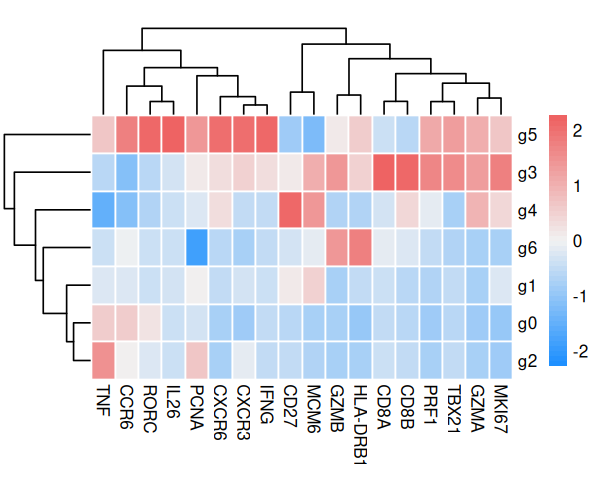

In [258]:
options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp3p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  #fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



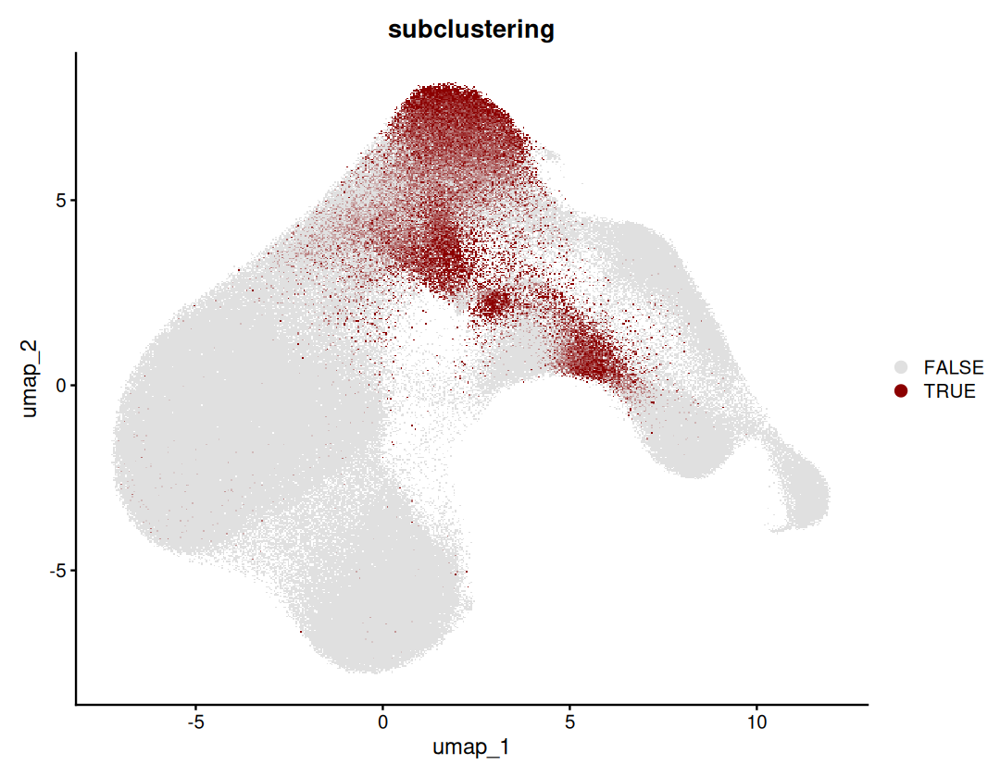

In [148]:
DimPlot(blood_3p_stacas, group.by = "subclustering", cols = c("grey88","darkred"))

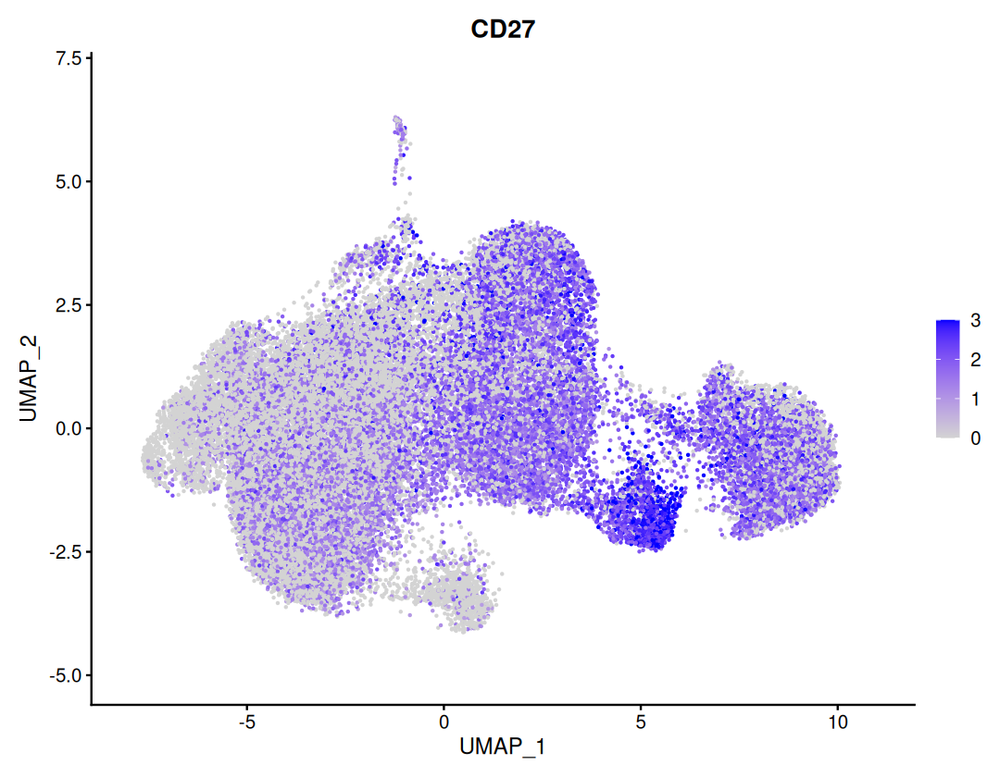

In [139]:
FeaturePlot(blood_3p_subset, features = "CD27", min.cutoff = 0, max.cutoff = 3)

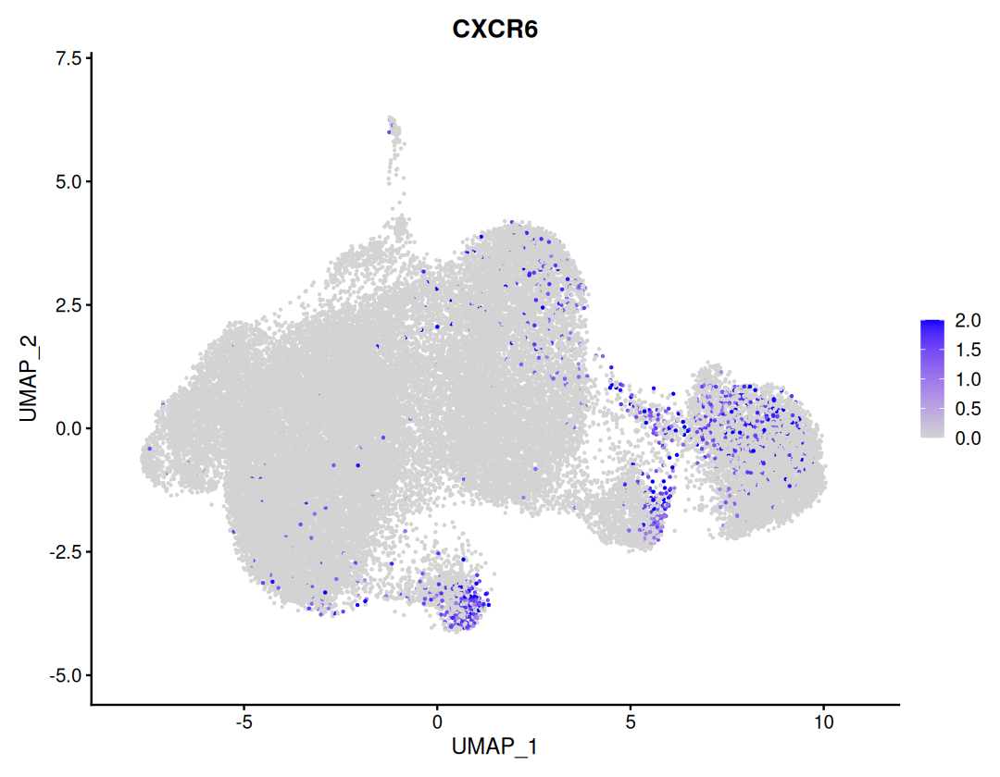

In [140]:
FeaturePlot(blood_3p_subset, features = "CXCR6", min.cutoff = 0, max.cutoff = 2)

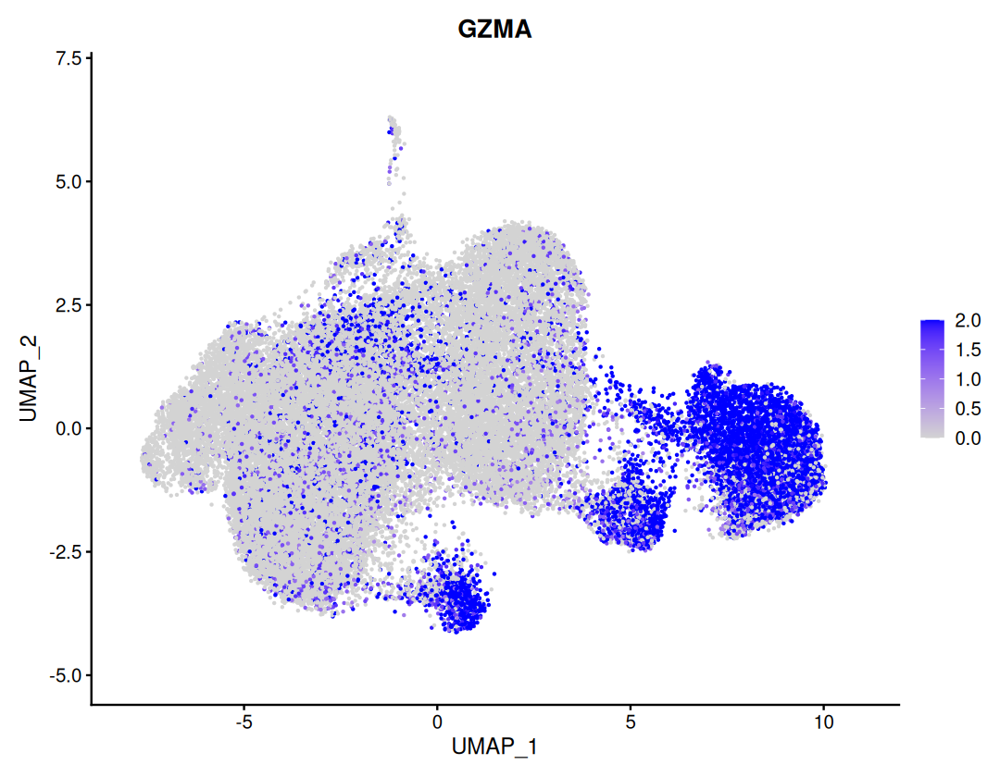

In [149]:
FeaturePlot(blood_3p_subset, features = "GZMA", min.cutoff = 0, max.cutoff = 2)

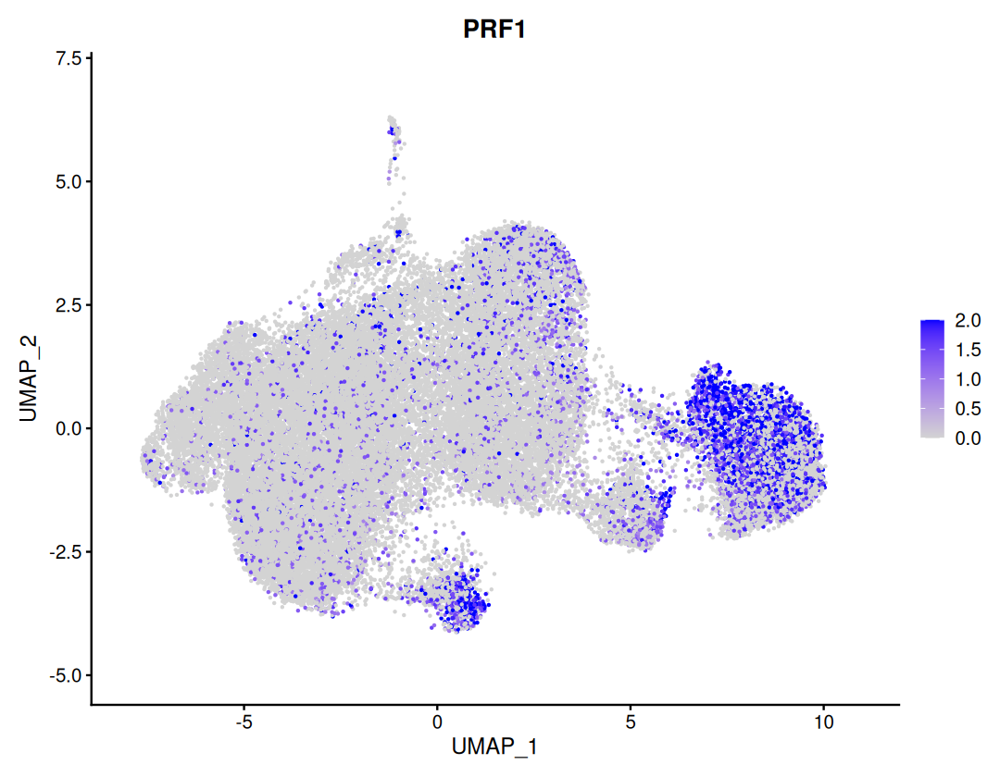

In [151]:
FeaturePlot(blood_3p_subset, features = "PRF1", min.cutoff = 0, max.cutoff = 2)

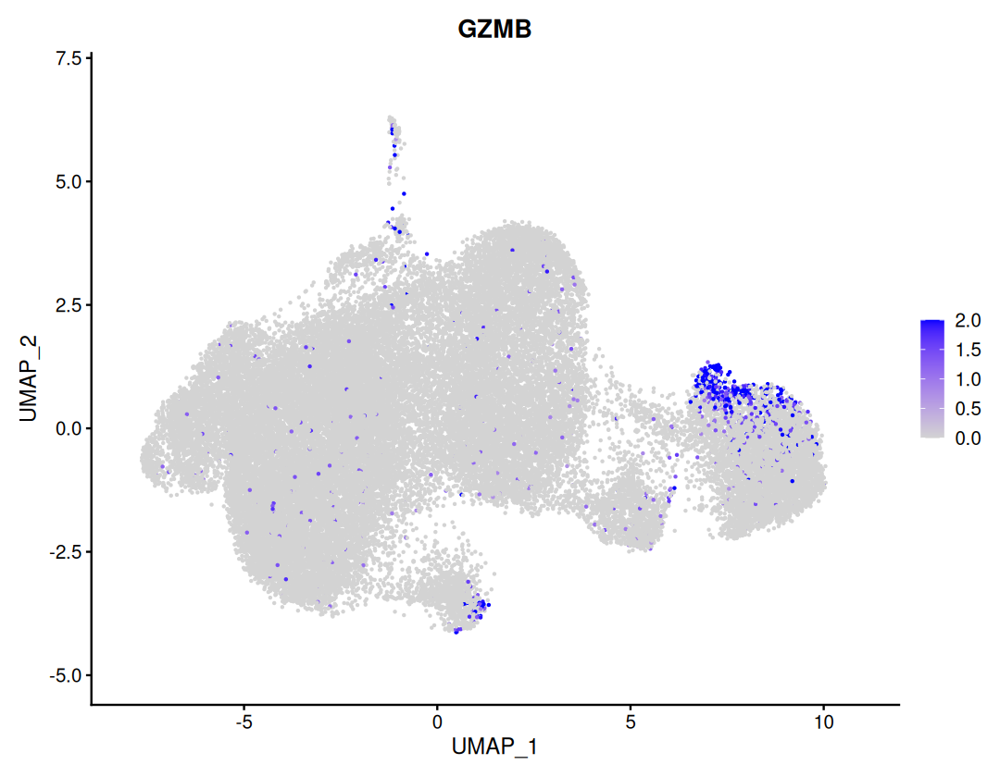

In [150]:
FeaturePlot(blood_3p_subset, features = "GZMB", min.cutoff = 0, max.cutoff = 2)

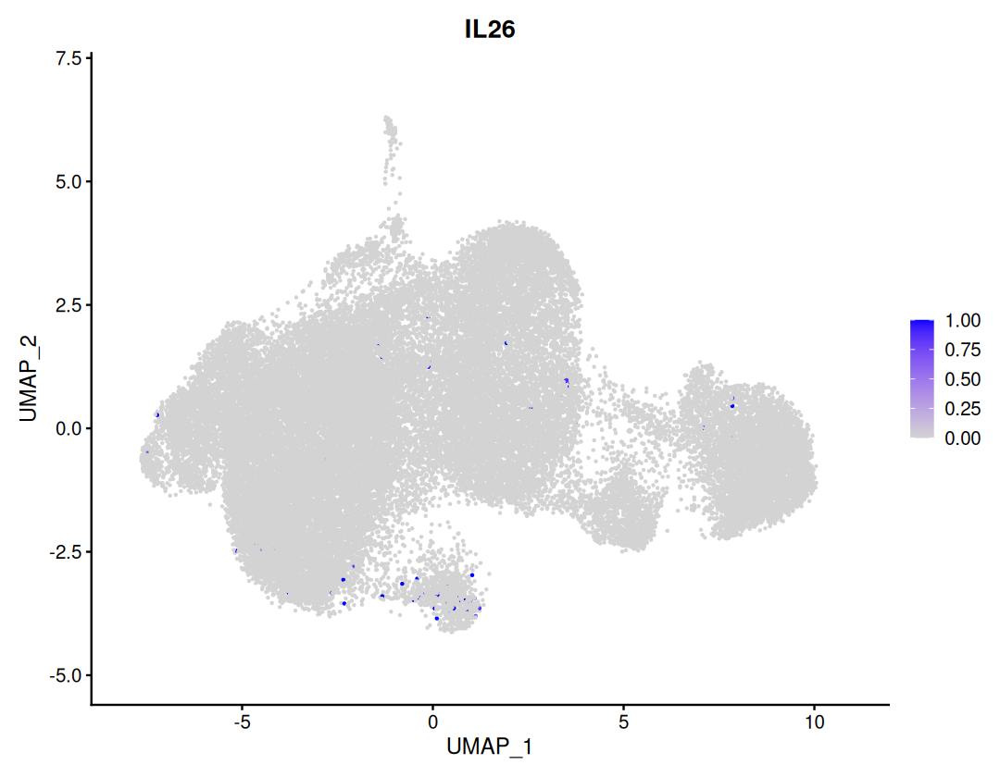

In [142]:
FeaturePlot(blood_3p_subset, features = "IL26", min.cutoff = 0, max.cutoff = 1)

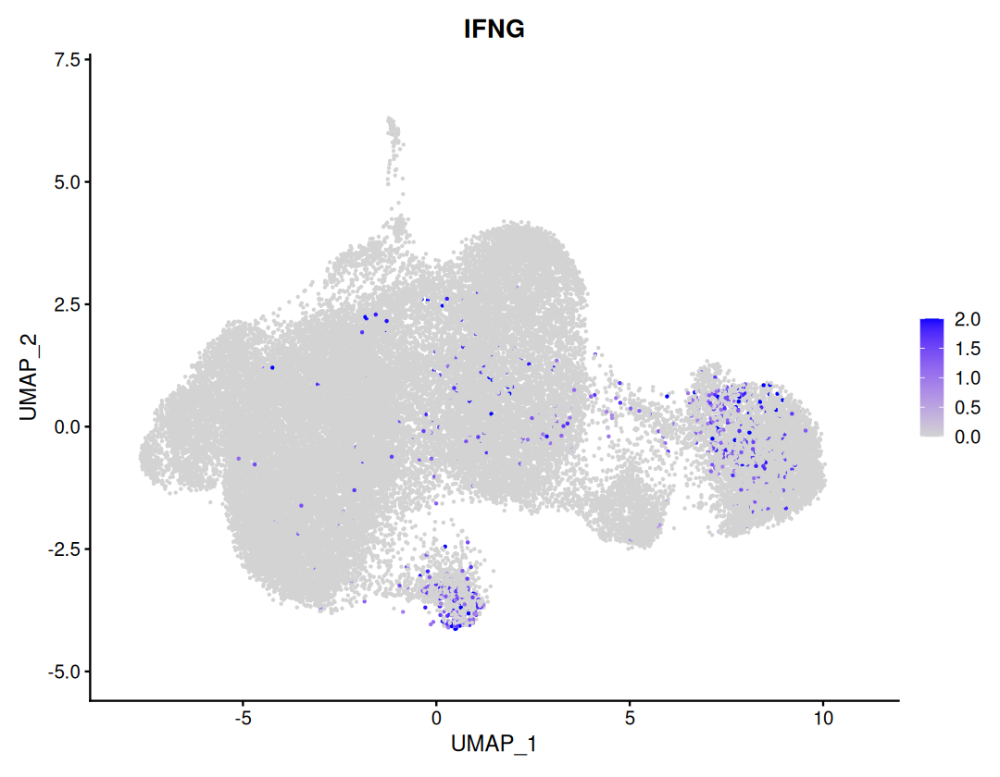

In [173]:
FeaturePlot(blood_3p_subset, features = "IFNG", min.cutoff = 0, max.cutoff = 2)

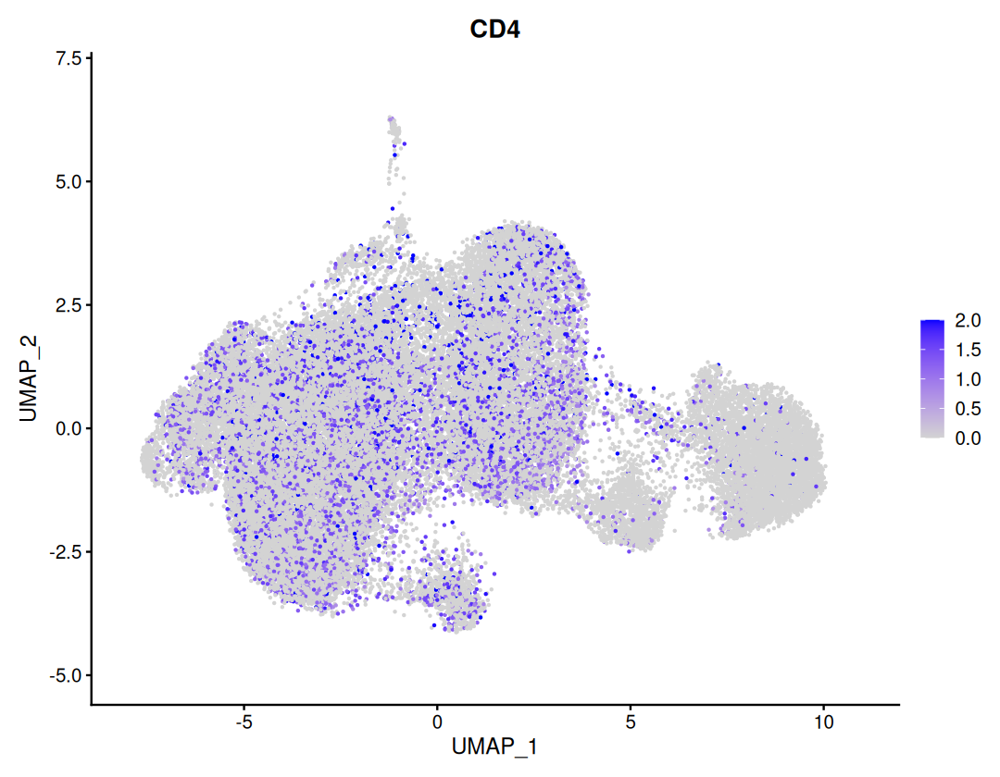

In [144]:
FeaturePlot(blood_3p_subset, features = "CD4", min.cutoff = 0, max.cutoff = 2)

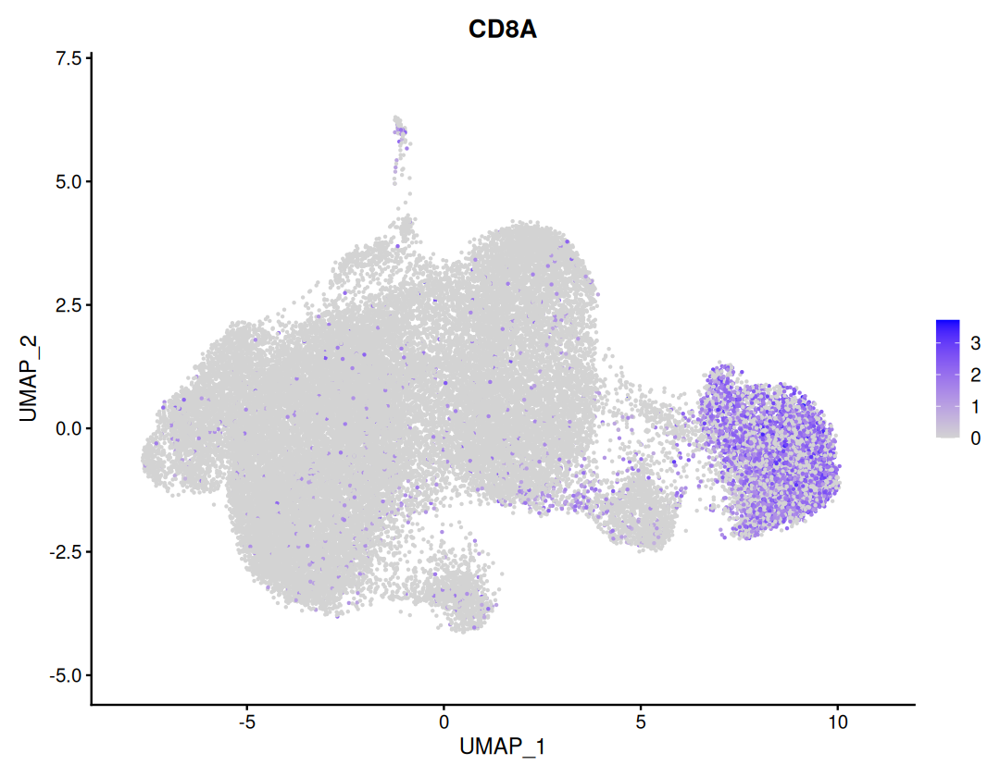

In [145]:
FeaturePlot(blood_3p_subset, features = "CD8A", min.cutoff = 0)

In [ ]:
avgexp5p_sub = AverageExpression(blood_subclust, 
                            features = c("TNF","CXCR3",
                                         "TBX21","CCR6","RORC","CXCR6","CD27","HLA-DRB1",
                                         "GZMA","PRF1","IFNG","IL26","CD8A","CD8B","MKI67","PCNA","MCM6"
                                        ), 
                            group.by = "seurat_clusters",
                          assay = "RNA")

In [70]:
options(repr.plot.width = 5, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp5p_sub$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/blood_subclustering_heatmap.pdf",
                  width = 4, height = 5)

## Small heatmaps comparing Th1 Th17 and CTL

In [33]:
blood_subclust_5p  <- readRDS("data/")

In [688]:
blood_subclust_subclust_5p  <- subset(blood_subclust, seurat_clusters %in% c(0:4))

In [689]:
blood_subclust_subclust_3p  <- subset(blood_3p_subset, seurat_clusters %in% c(0,2,5))

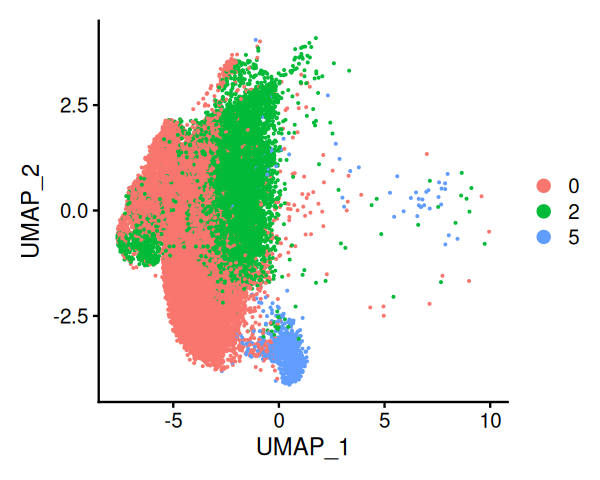

In [690]:
options(repr.plot.width = 5, repr.plot.height = 4)
DimPlot(blood_subclust_subclust_3p)

In [695]:
blood_subclust_subclust_3p@meta.data  <- blood_subclust_subclust_3p@meta.data  %>% 
mutate(annot_th1_th17 = case_when(seurat_clusters ==  0 ~ "Th17",
                                  seurat_clusters ==  2 ~ "Th1",
                                  seurat_clusters ==  5 ~ "CTL"
                                  ))

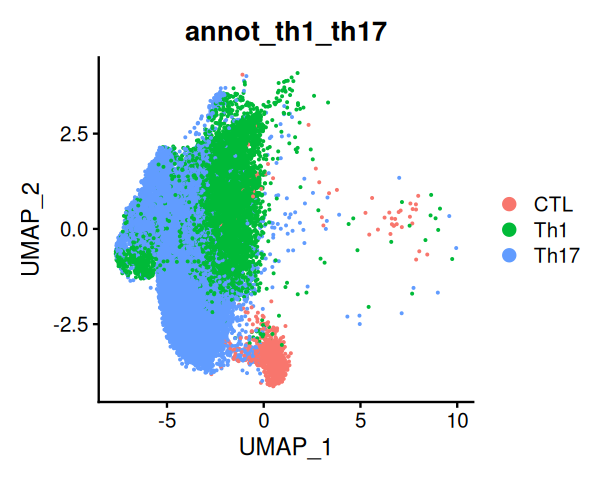

In [696]:
DimPlot(blood_subclust_subclust_3p, group.by = "annot_th1_th17")

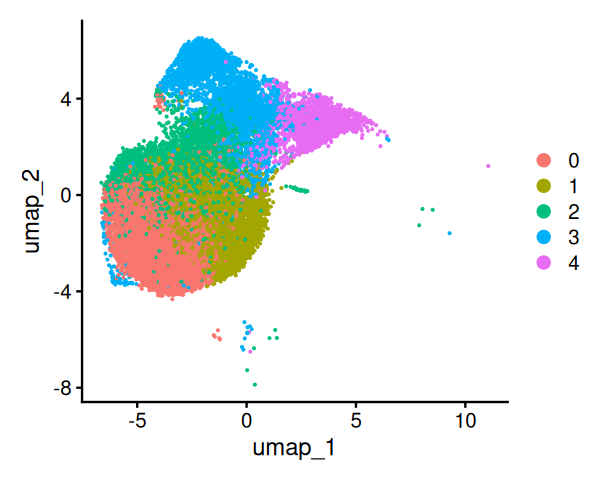

In [691]:
options(repr.plot.width = 5, repr.plot.height = 4)
DimPlot(blood_subclust_subclust_5p)

In [697]:
blood_subclust_subclust_5p@meta.data  <- blood_subclust_subclust_5p@meta.data  %>% 
mutate(annot_th1_th17 = case_when(seurat_clusters %in% c(2,3) ~ "Th17",
                                  seurat_clusters %in% c(0,1) ~ "Th1",
                                  seurat_clusters ==  4 ~ "CTL"
                                  ))

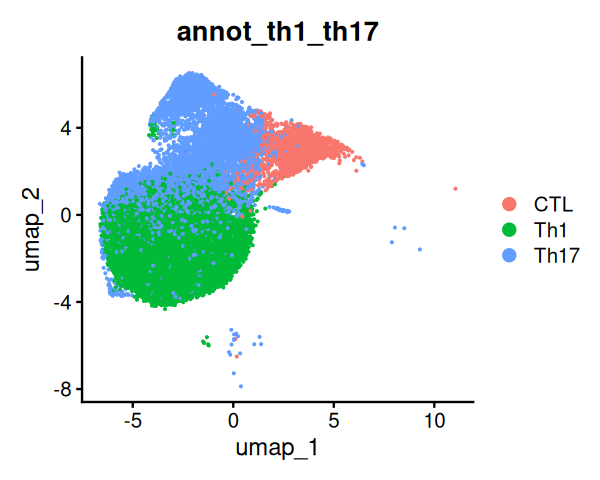

In [698]:
DimPlot(blood_subclust_subclust_5p, group.by = "annot_th1_th17")

In [702]:
avgexp3p = AverageExpression(blood_subclust_subclust_3p, 
                            features = c("IL17A","IFNG","IL26","RORC","TBX21"), 
                            group.by = "annot_th1_th17",
                          assay = "RNA")

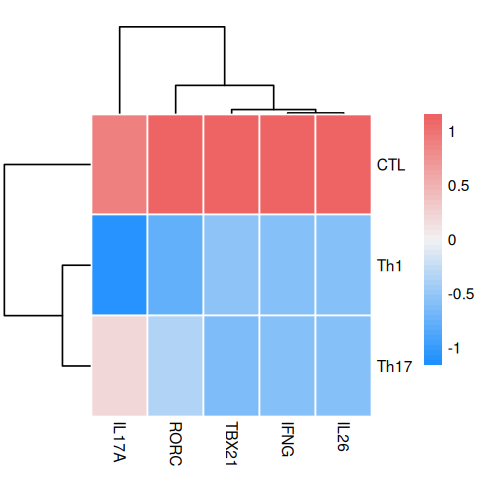

In [706]:
options(repr.plot.width = 4, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp3p$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [707]:
avgexp5p = AverageExpression(blood_subclust_subclust_5p, 
                            features = c("IL17F","IL17A","IFNG","IL26","RORC","TBX21"), 
                            group.by = "annot_th1_th17",
                          assay = "RNA")

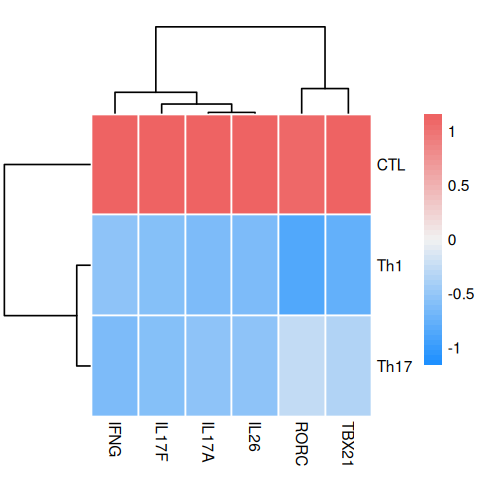

In [708]:
options(repr.plot.width = 4, repr.plot.height = 4)
pheatmap::pheatmap(t(avgexp5p$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

### With Naive

#### 3p

In [709]:
naive_3p  <- colnames(subset(blood_3p_stacas, seurat_clusters2 == 2))

In [710]:
blood_3p_stacas$barcode  <- colnames(blood_3p_stacas)

In [711]:
blood_subclust_subclust_3p_with_naive  <- subset(blood_3p_stacas, barcode %in% c(naive_3p, colnames(blood_subclust_subclust_3p)))

In [712]:
naive  <- naive_3p
th1  <- colnames(subset(blood_subclust_subclust_3p, annot_th1_th17 == "Th1"))
th17  <- colnames(subset(blood_subclust_subclust_3p, annot_th1_th17 == "Th17"))
ctl  <- colnames(subset(blood_subclust_subclust_3p, annot_th1_th17 == "CTL"))

In [713]:
blood_subclust_subclust_3p_with_naive@meta.data  <- blood_subclust_subclust_3p_with_naive@meta.data  %>% 
mutate(annot_th1_th17 = case_when(barcode %in% naive ~ "Naive",
                                  barcode %in% th1 ~ "Th1",
                                  barcode %in% th17 ~ "Th17",
                                  barcode %in%  ctl ~ "CTL"
                                  ))

In [771]:
avgexp3p = AverageExpression(blood_subclust_subclust_3p_with_naive, 
                            features = c("TNF","IL2","CXCR3",
                                         "TBX21","CCR6","IL17A","RORC",
                                         "GZMA","PRF1","IFNG","IL26"), 
                            group.by = "annot_th1_th17",
                          assay = "RNA")

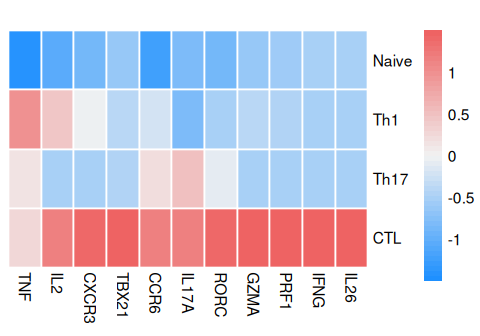

In [772]:
options(repr.plot.width = 4, repr.plot.height = 2.8)
pheatmap::pheatmap(t(avgexp3p$RNA)[c(2,3,4,1),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [773]:
options(repr.plot.width = 4, repr.plot.height = 2.8)
pheatmap::pheatmap(t(avgexp3p$RNA)[c(2,3,4,1),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, width = 5, height = 2.5, 
                  filename = "figures/characterization_CD4CTL/hm_small_blood_ctl_3p.pdf")

#### 5p

In [3]:
blood_5p  <- readRDS("data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

In [738]:
naive_5p  <- colnames(subset(blood_5p, annotations == "CD4_Naive"))

In [739]:
md_blood_5p  <- blood_5p@meta.data

In [742]:
blood_5p$barcode  <- colnames(blood_5p)

In [743]:
blood_subclust_subclust_5p_with_naive  <- subset(blood_5p, barcode %in% c(naive_5p, colnames(blood_subclust_subclust_5p)))

In [744]:
naive  <- naive_5p
th1  <- colnames(subset(blood_subclust_subclust_5p, annot_th1_th17 == "Th1"))
th17  <- colnames(subset(blood_subclust_subclust_5p, annot_th1_th17 == "Th17"))
ctl  <- colnames(subset(blood_subclust_subclust_5p, annot_th1_th17 == "CTL"))

In [745]:
blood_subclust_subclust_5p_with_naive@meta.data  <- blood_subclust_subclust_5p_with_naive@meta.data  %>% 
mutate(annot_th1_th17 = case_when(barcode %in% naive ~ "Naive",
                                  barcode %in% th1 ~ "Th1",
                                  barcode %in% th17 ~ "Th17",
                                  barcode %in%  ctl ~ "CTL"
                                  ))

In [762]:
avgexp5p = AverageExpression(blood_subclust_subclust_5p_with_naive, 
                            features = c("CXCR3","TNF","TBX21","IL2",
                                         "GZMA","CCR6","RORC",
                                         "PRF1","IL17A","IFNG","IL26"), 
                            group.by = "annot_th1_th17",
                          assay = "RNA")

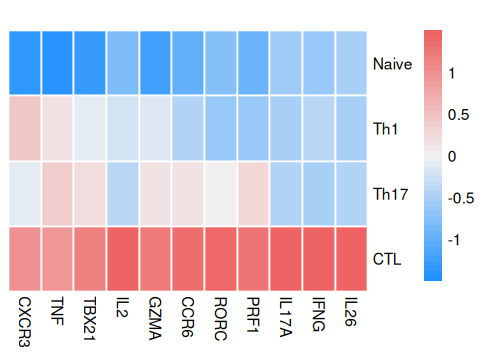

In [764]:
options(repr.plot.width = 4, repr.plot.height = 3)
pheatmap::pheatmap(t(avgexp5p$RNA)[c(2,3,4,1),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [774]:
options(repr.plot.width = 4, repr.plot.height = 3)
pheatmap::pheatmap(t(avgexp5p$RNA)[c(2,3,4,1),], main = "", 
         scale = "column", cluster_cols = T, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                fontsize = 9, width = 5, height = 2.5, 
                  filename = "figures/characterization_CD4CTL/hm_small_blood_ctl_5p.pdf")

## Subclust CD4 CTL score

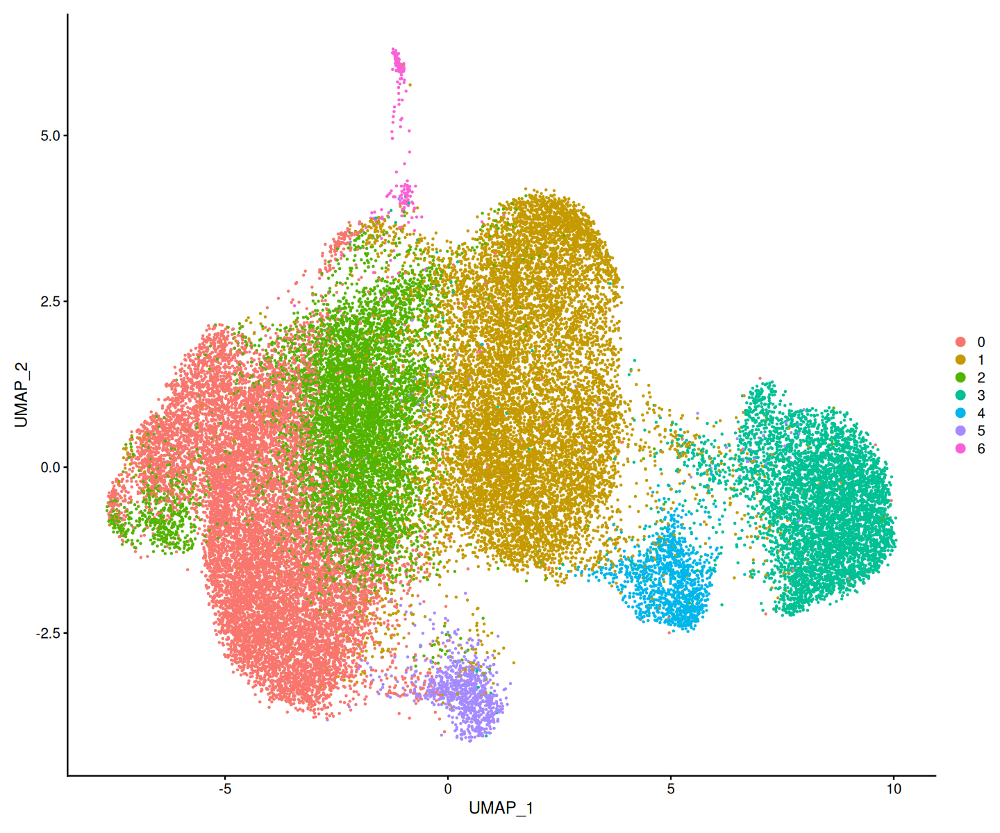

In [43]:
DimPlot(blood_3p_subset)

In [ ]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

blood_3p_subset  <- AddModuleScore(blood_3p_subset, features = list(cd4_ctl_sig),
  name     = "CTL_score")

blood_3p_subset_umap  <- blood_3p_subset@reductions$umap@cell.embeddings
blood_3p_subset$UMAP_1  <- blood_3p_subset_umap[,1]
blood_3p_subset$UMAP_2  <- blood_3p_subset_umap[,2]

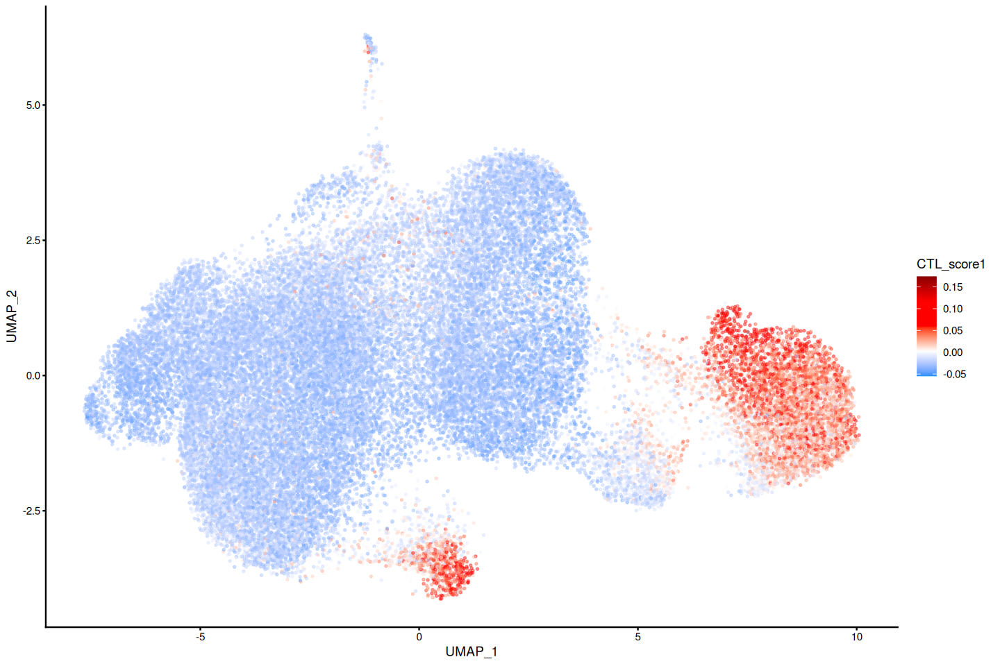

In [65]:
options(repr.plot.width = 12, repr.plot.height = 8)
blood_3p_subset@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","red","darkred"),
    #rescaler = ~ scales::rescale_mid(.x, mid = 0)
  )

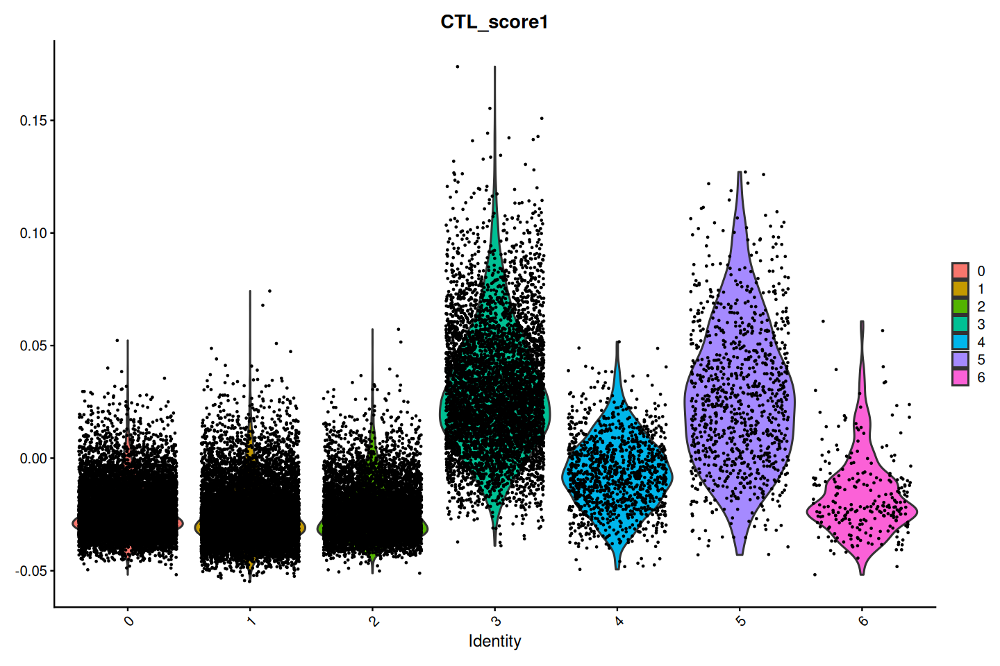

In [66]:
VlnPlot(blood_3p_subset, features = "CTL_score1")

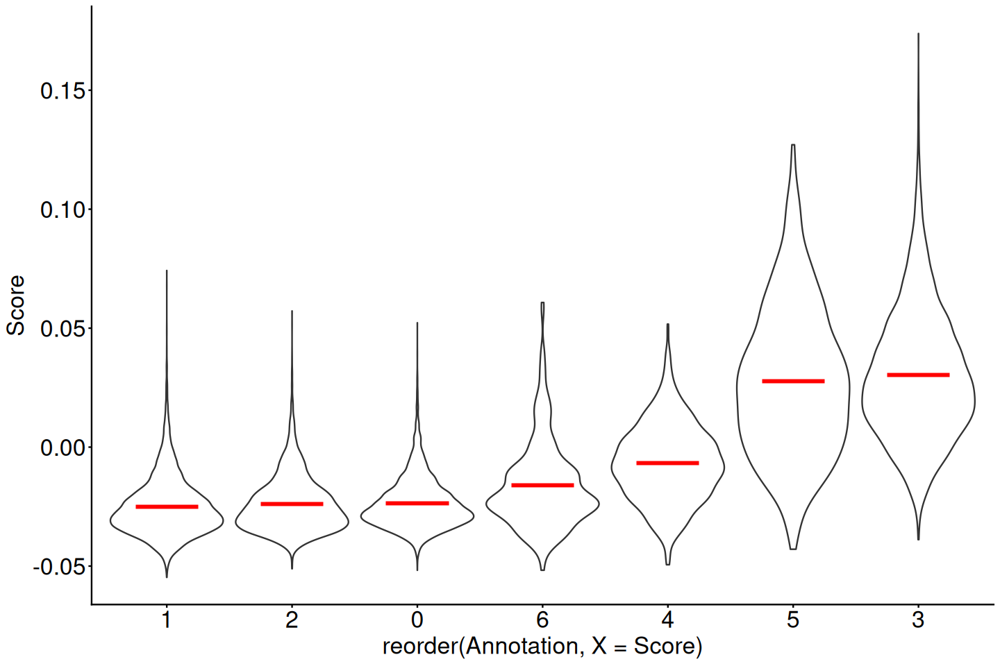

In [88]:
df  <- data.frame(Score = blood_3p_subset$CTL_score1,
                  Annotation = blood_3p_subset$seurat_clusters) 
df %>% 
ggplot(aes(x = reorder(Annotation, X = Score), y =Score)) +
  geom_violin(scale = "width") + 
  stat_summary(fun = "mean",
               geom = "crossbar", 
               width = 0.5,
               colour = "red") +
theme_classic() +
ggtheme()

ggsave("figures/blood_reclustering/vln_3p.svg", create.dir = TRUE, width = 12, height = 10, units = "cm")

In [57]:
DefaultAssay(blood_subclust)  <- "RNA"

In [58]:
cd4_ctl_sig  <- c(
    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

cd4_ctl_sig  <- unique(cd4_ctl_sig[which(cd4_ctl_sig  %in% rownames(blood_subclust))])

In [53]:
cd4_ctl_sig

[1] "GZMA"     "CTSH"     "IFNG"     "CCL4"     "ZEB2"     "CHN1"    
 [7] "TESC"     "ADAM12"   "IL26"     "GZMH"     "GZMB"     "COL5A3"  
[13] "OASL"     "NCR3"     "GNLY"     "GOLIM4"   "FASLG"    "APOBEC3H"
[19] "SLC27A2"  "LYN"      "KLRD1"    "PCLAF"    "EOMES"    "TK1"     
[25] "NCAPH"    "FCRL6"    "CDT1"     "PALLD"    "ASPM"     "C3orf14" 
[31] "CCNA2"    "KIFC1"    "CD160"    "NCAPG"    "PKMYT1"   "ZNF683"  
[37] "TROAP"    "NMU"      "BUB1B"    "MELK"     "FOXM1"    "DEPDC1B" 
[43] "CDCA5"    "SHCBP1"   "KIF14"    "KIF15"    "PLK1"     "SPC25"   
[49] "KIF4A"    "PRR11"    "ESCO2"    "MND1"     "PIF1"     "ADGRG1"  
[55] "SPC24"    "DIAPH3"   "E2F2"     "MCM10"    "SKA1"     "DEPDC1"  
[61] "SKA3"     "PBK"      "KIF20A"   "CES1"     "KIF18B"   "HIST1H3G"
[67] "HIST1H3C" "E2F7"     "CDC25A"   "FAM111B"  "FAM72B"   "KLRC4"   
[73] "TYMSOS"   "KLRC1"    "KLRC2"

In [59]:
blood_subclust  <- AddModuleScore(blood_subclust, features = list(cd4_ctl_sig),
  name     = "CTL_score")

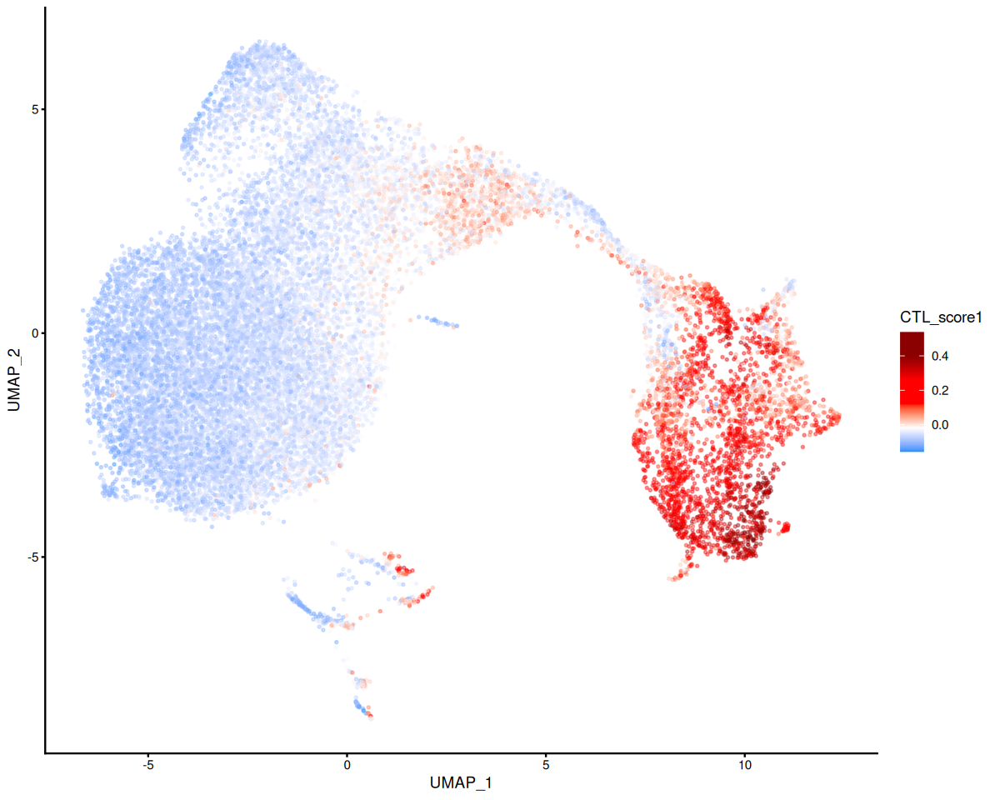

In [64]:
blood_5p_subset_umap  <- blood_subclust@reductions$umap@cell.embeddings
blood_subclust$UMAP_1  <- blood_5p_subset_umap[,1]
blood_subclust$UMAP_2  <- blood_5p_subset_umap[,2]

options(repr.plot.width = 10, repr.plot.height = 8)
blood_subclust@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red", "red", "darkred","darkred"),
    #rescaler = ~ scales::rescale_mid(.x, mid = 0)
  )

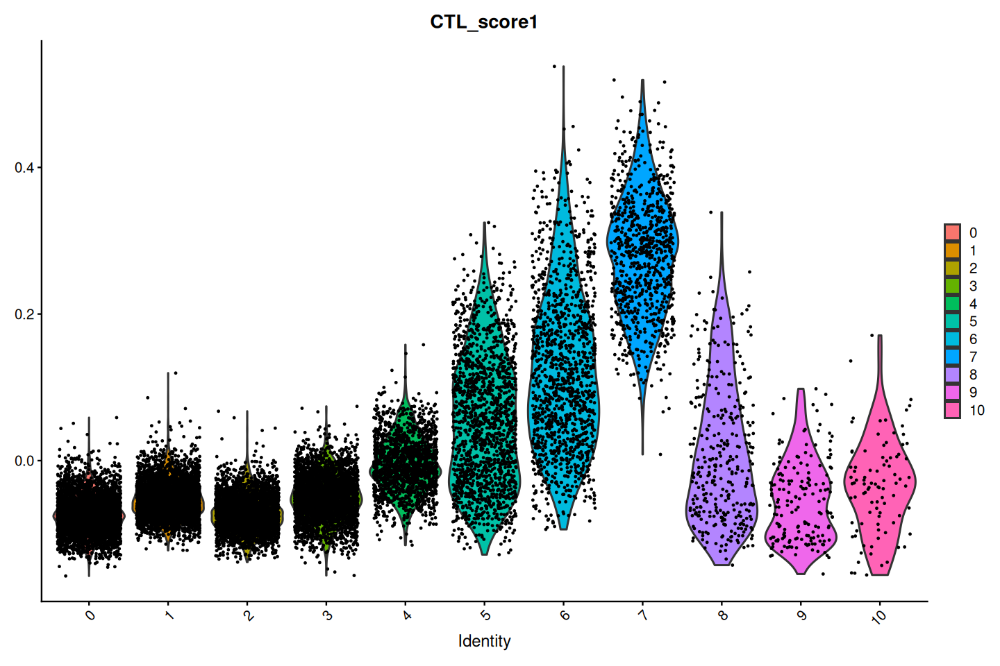

In [68]:
VlnPlot(blood_subclust, features = "CTL_score1")

✔ Created directory: figures/blood_reclustering.



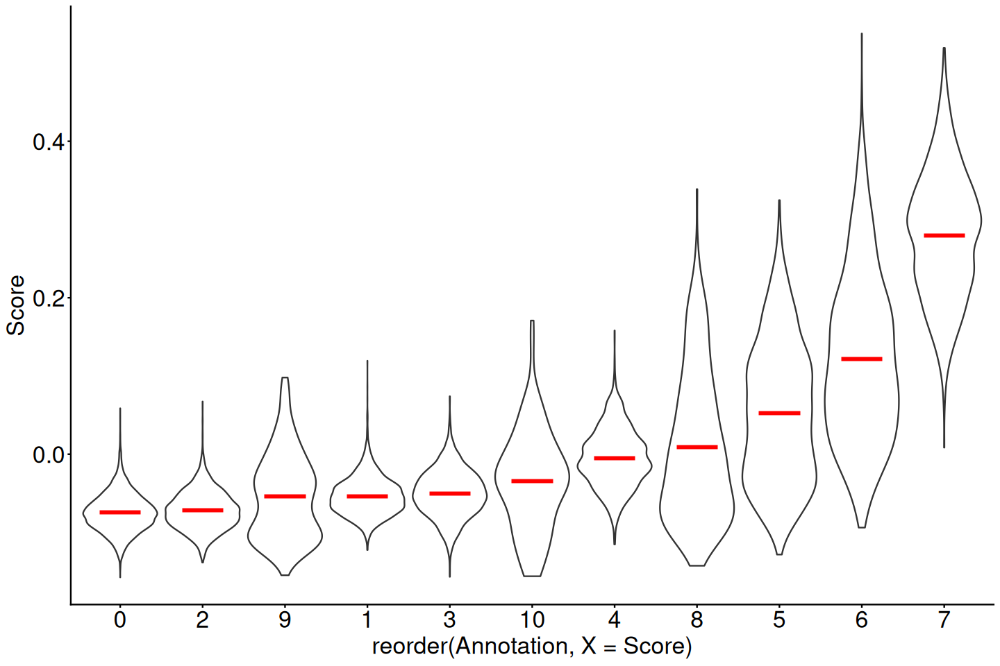

In [86]:
df  <- data.frame(Score = blood_subclust$CTL_score1,
                  Annotation = blood_subclust$seurat_clusters) 
df %>% 
ggplot(aes(x = reorder(Annotation, X = Score), y =Score)) +
  geom_violin(scale = "width") + 
  stat_summary(fun = "mean",
               geom = "crossbar", 
               width = 0.5,
               colour = "red") +
theme_classic() +
ggtheme()

ggsave("figures/blood_reclustering/vln_5p.svg", create.dir = TRUE, width = 20, height = 10, units = "cm")

# Blood TCR

In [5]:
md  <- blood_5p@meta.data

In [201]:
paths <- list.files("./data/tcr/")
data_folders <- gsub(paths, pattern = ".csv", replacement = '')
data_folders <- gsub(paths, pattern = "_1_1_2", replacement = '_1_1_1')


In [217]:
data_folders

[1] "003-043_T0_BLD_CD3_5p_VDJ" "003-043_T0_COL_EPI_5p_VDJ"
  [3] "003-043_T0_COL_LP_5p_VDJ"  "003-043_T0_DUO_EPI_5p_VDJ"
  [5] "003-043_T0_DUO_LP_5p_VDJ"  "003-043_T0_ILE_EPI_5p_VDJ"
  [7] "003-043_T0_ILE_LP_5p_VDJ"  "1193588_1_1_1"            
  [9] "1193589_1_1_1"             "1193590_1_1_1"            
 [11] "1193591_1_1_1"             "1193592_1_1_1"            
 [13] "1193593_1_1_1"             "1193594_1_1_1"            
 [15] "1193595_1_1_1"             "1193596_1_1_1"            
 [17] "1193597_1_1_1"             "1193598_1_1_1"            
 [19] "1193599_1_1_1"             "1193600_1_1_1"            
 [21] "1193601_1_1_1"             "1193602_1_1_1"            
 [23] "1193603_1_1_1"             "1193604_1_1_1"            
 [25] "1193605_1_1_1"             "1193606_1_1_1"            
 [27] "1193607_1_1_1"             "1193608_1_1_1"            
 [29] "1193609_1_1_1"             "1193610_1_1_1"            
 [31] "1193611_1_1_1"             "1193612_1_1_1"            
 [33] "1193613_1_1_1"             "1193614_1_1_1"            
 [35] "1193615_1_1_1"             "1193616_1_1_1"            
 [37] "1193617_1_1_1"             "1193618_1_1_1"            
 [39] "1193619_1_1_1"             "1193620_1_1_1"            
 [41] "1193621_1_1_1"             "1193623_1_1_1"            
 [43] "1193624_1_1_1"             "1193625_1_1_1"            
 [45] "1193626_1_1_1"             "1193627_1_1_1"            
 [47] "1193628_1_1_1"             "1193629_1_1_1"            
 [49] "1193630_1_1_1"             "1193631_1_1_1"            
 [51] "1193632_1_1_1"             "1193633_1_1_1"            
 [53] "1193634_1_1_1"             "1193635_1_1_1"            
 [55] "1193636_1_1_1"             "1193637_1_1_1"            
 [57] "1193638_1_1_1"             "1193639_1_1_1"            
 [59] "1193640_1_1_1"             "1193641_1_1_1"            
 [61] "1193642_1_1_1"             "1193643_1_1_1"            
 [63] "1270978_1_1_1"             "1270979_1_1_1"            
 [65] "1270980_1_1_1"             "1270981_1_1_1"            
 [67] "1270982_1_1_1"             "1270983_1_1_1"            
 [69] "1270985_1_1_1"             "1270986_1_1_1"            
 [71] "1270987_1_1_1"             "1270988_1_1_1"            
 [73] "1270989_1_1_1"             "1270990_1_1_1"            
 [75] "1270991_1_1_1"             "1270992_1_1_1"            
 [77] "1270993_1_1_1"             "1270994_1_1_1"            
 [79] "1271001_1_1_1"             "1271003_1_1_1"            
 [81] "1271004_1_1_1"             "1271005_1_1_1"            
 [83] "1271006_1_1_1"             "1271007_1_1_1"            
 [85] "1271008_1_1_1"             "1271009_1_1_1"            
 [87] "1271010_1_1_1"             "1271011_1_1_1"            
 [89] "1271012_1_1_1"             "1271013_1_1_1"            
 [91] "1271014_1_1_1"             "1271015_1_1_1"            
 [93] "1271016_1_1_1"             "1271017_1_1_1"            
 [95] "1271019_1_1_1"             "1271021_1_1_1"            
 [97] "1271022_1_1_1"             "1271023_1_1_1"            
 [99] "1271024_1_1_1"             "1271026_1_1_1"            
[101] "1271029_1_1_1"             "1271030_1_1_1"            
[103] "1271031_1_1_1"             "1271032_1_1_1"            
[105] "1271033_1_1_1"             "1271035_1_1_1"            
[107] "1271036_1_1_1"             "1271037_1_1_1"            
[109] "1271038_1_1_1"             "1271039_1_1_1"            
[111] "1271040_1_1_1"             "1271041_1_1_1"            
[113] "1271042_1_1_1"             "1271043_1_1_1"            
[115] "1271044_1_1_1"             "1271045_1_1_1"            
[117] "1271047_1_1_1"             "1271048_1_1_1"            
[119] "1271049_1_1_1"             "1271050_1_1_1"            
[121] "1271051_1_1_1"             "1271052_1_1_1"            
[123] "1271053_1_1_1"             "1271054_1_1_1"            
[125] "1271055_1_1_1"             "1271056_1_1_1"            
[127] "1271057_1_1_1"             "1271058_1_1_1"            
[129] "1271060_1_1_1"             

In [218]:
data_folders_df <- data.frame(data_folder = data_folders)
data_folders_df$in_meta <- data_folders %in% md$data_folder
data_folders_df  %>% dplyr::filter(in_meta == F)

data_folder,in_meta
<chr>,<lgl>
003-043_T0_BLD_CD3_5p_VDJ,FALSE
003-043_T0_COL_EPI_5p_VDJ,FALSE
003-043_T0_COL_LP_5p_VDJ,FALSE
003-043_T0_DUO_EPI_5p_VDJ,FALSE
003-043_T0_DUO_LP_5p_VDJ,FALSE
003-043_T0_ILE_EPI_5p_VDJ,FALSE
003-043_T0_ILE_LP_5p_VDJ,FALSE
1193588_1_1_1,FALSE
1193589_1_1_1,FALSE


In [219]:
bld_folders <- data.frame(data_folder = unique(blood_5p$data_folder) ,
                             in_vdj = unique(blood_5p$data_folder)  %in% data_folders)

In [220]:
bld_folders$in_vdj  %>% table

.
FALSE  TRUE 
    7    90 

In [222]:
bld_folders  %>% dplyr::filter(in_vdj == F)

data_folder,in_vdj
<chr>,<lgl>
1740264_1_1_1,FALSE
1740313_1_1_1,FALSE
HE009_T0_BLD_CD3_5p_GEX,FALSE
HE011_T0_BLD_CD3_5p_GEX,FALSE
HE012_T0_BLD_CD3_5p_GEX,FALSE
1740285_1_1_1,FALSE
1542420_1_1_1,FALSE


In [223]:
folders_ready <- data_folders[which(data_folders %in% md$data_folder)]

In [224]:
paths_folders_ready <- paste0("data/tcr/",paths[which(data_folders %in% md$data_folder)])

In [225]:
paths_folders_ready[1]

[1] "data/tcr/1542394_1_1_2.csv"

In [226]:
md$raw_barcode <-  substr(md$barcode,1,18)

In [233]:
source("vdj_code2.R")

In [228]:
i = 1

In [234]:
folder_process <- folders_ready[i]
md_sub <- md  %>% dplyr::filter(data_folder == folder_process)
all_contig_annotations <- read_csv(paths_folders_ready[i])

vdj_data_processed <- create.VDJ.metadata2(all_contig_annotations)
vdj_data_processed$raw_barcode <- rownames(vdj_data_processed)
md_sub2 <- left_join(md_sub, vdj_data_processed)
rownames(md_sub2) <- md_sub2$barcode
all_md <- md_sub2

Rows: 13533 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


In [235]:
for(i in 2:length(folders_ready)){
folder_process <- folders_ready[i]
md_sub <- md  %>% dplyr::filter(data_folder == folder_process)
all_contig_annotations <-     suppressWarnings(
read_csv(paths_folders_ready[i]))

vdj_data_processed <- create.VDJ.metadata2(all_contig_annotations)
vdj_data_processed$raw_barcode <- rownames(vdj_data_processed)
md_sub2 <- left_join(md_sub, vdj_data_processed)
rownames(md_sub2) <- md_sub2$barcode
    suppressWarnings(all_md <- rbind(all_md, md_sub2))
        
    print(paste("DONE:",i))
    }

Rows: 25184 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


[1] "DONE: 2"


Rows: 7276 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


[1] "DONE: 3"


Rows: 12694 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


[1] "DONE: 4"


... (168 outputs left out)

Rows: 35729 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


[1] "DONE: 89"


Rows: 18641 Columns: 18
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (11): barcode, contig_id, chain, v_gene, d_gene, j_gene, c_gene, cdr3, c...
dbl  (3): length, reads, umis
lgl  (4): is_cell, high_confidence, full_length, productive

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
`summarise()` has grouped output by 'barcode'. You can override using the
`.groups` argument.
Joining with `by = join_by(raw_barcode)`


[1] "DONE: 90"


In [236]:
write.csv(all_md, "tables/250107_tcr_all_contig_all_samples_blood.csv")

In [11]:
all_md  <- read_csv("tables/250107_tcr_all_contig_all_samples_blood.csv")

New names:
• `` -> `...1`
Rows: 553913 Columns: 84
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (59): ...1, orig.ident, SingleR_HPCA, data_folder, barcode, sample, diag...
dbl (14): nCount_RNA, nFeature_RNA, percent.mt, percent.rt, RNA_snn_res.0.3,...
num  (3): length, reads, umis
lgl  (8): is_in_subclust, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [12]:
all_md$`...1`  <- NULL

In [13]:
md  <- blood_5p@meta.data

In [14]:
colnames(md)

[1] "orig.ident"              "nCount_RNA"             
 [3] "nFeature_RNA"            "percent.mt"             
 [5] "percent.rt"              "SingleR_HPCA"           
 [7] "data_folder"             "RNA_snn_res.0.3"        
 [9] "seurat_clusters"         "barcode"                
[11] "integrated_snn_res.0.4"  "sample"                 
[13] "diagnosis"               "subgroup_primary"       
[15] "subgroup_secondary"      "subgroup_tertiary"      
[17] "Rome_coarse"             "Rome_classification"    
[19] "antitnf_response"        "participant_id"         
[21] "timepoint"               "age"                    
[23] "sex"                     "site"                   
[25] "tissue"                  "layer"                  
[27] "prime"                   "version_10x"            
[29] "sample_old"              "data_type"              
[31] "seq_run"                 "collection_purpose"     
[33] "collection_date"         "days"                   
[35] "antitnf"                 "antitnf_repeat"         
[37] "duo_inflammation"        "ile_inflammation"       
[39] "col_inflammation"        "sample_inflamed"        
[41] "colon_site"              "score_type"             
[43] "severity_score"          "weighted_severity_score"
[45] "severity_score_date"     "severity_score_range"   
[47] "weighted_score_range"    "internal_flag"          
[49] "integrated_snn_res.0.6"  "integrated_snn_res.0.7" 
[51] "cluster_subclust1"       "annot_subclust"         
[53] "seurat_clusters2"        "annotations"            
[55] "subclust_vsm_res05"      "cd4_ctl"

In [15]:
length(colnames(md))

[1] 56

In [16]:
colnames(all_md)[55:83]

[1] "is_cell"         "chain"           "contig_id"       "high_confidence"
 [5] "productive"      "length"          "reads"           "umis"           
 [9] "count_TRA"       "count_TRB"       "count_Multi"     "cdr3_A1"        
[13] "cdr3_A1_nt"      "cdr3_A2"         "cdr3_A2_nt"      "cdr3_B"         
[17] "cdr3_B_nt"       "cdr3_Multi"      "cdr3_Multi_nt"   "v_gene_A1"      
[21] "j_gene_A1"       "v_gene_A2"       "j_gene_A2"       "v_gene_B"       
[25] "d_gene_B"        "j_gene_B"        "v_gene_Multi"    "d_gene_Multi"   
[29] "j_gene_Multi"

In [17]:
md  <- blood_5p@meta.data

In [18]:
md_joint_with_tcr <- left_join(md , all_md  %>% dplyr::select(barcode, 55:83))

Joining with `by = join_by(barcode)`


In [19]:
md_joint_with_tcr

orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rt,SingleR_HPCA,data_folder,RNA_snn_res.0.3,seurat_clusters,barcode,⋯,v_gene_A1,j_gene_A1,v_gene_A2,j_gene_A2,v_gene_B,d_gene_B,j_gene_B,v_gene_Multi,d_gene_Multi,j_gene_Multi
<chr>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<fct>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>
SeuratProject,1311,832,4.950166,46.24585,T_cells,1740278_1_1_1,2,1,AAACCTGAGAGATGAG-1_1_1_1,⋯,TRAV19,TRAJ39,NA,NA,TRBV9,NA,TRBJ1-1,NA,NA,NA
SeuratProject,5018,2341,4.287179,39.94872,T_cells,1740278_1_1_1,9,6,AAACCTGAGAGTACCG-1_1_1_1,⋯,TRAV14DV4,TRAJ12,NA,NA,NA,NA,NA,NA,NA,NA
SeuratProject,6878,2999,2.692489,27.45394,T_cells,1740278_1_1_1,5,2,AAACCTGAGAGTGAGA-1_1_1_1,⋯,TRAV23DV6,TRAJ29,NA,NA,TRBV16,NA,TRBJ1-3,NA,NA,NA
SeuratProject,3977,2048,4.266118,36.89986,T_cells,1740278_1_1_1,9,6,AAACCTGAGCTGAACG-1_1_1_1,⋯,TRAV27,TRAJ26,NA,NA,TRBV29-1,NA,TRBJ2-7,NA,NA,NA
SeuratProject,4910,2442,2.917505,37.39101,T_cells,1740278_1_1_1,0,0,AAACCTGAGGCAATTA-1_1_1_1,⋯,TRAV8-4,TRAJ17,NA,NA,TRBV5-1,TRBD1,TRBJ1-1,NA,NA,NA
SeuratProject,3547,1819,5.058939,31.49967,T_cells,1740278_1_1_1,0,5,AAACCTGAGGCTAGAC-1_1_1_1,⋯,TRAV17,TRAJ9,TRAV16,TRAJ48,TRBV4-1,TRBD2,TRBJ2-5,NA,NA,NA
SeuratProject,4676,2315,4.156266,33.64953,T_cells,1740278_1_1_1,1,3,AAACCTGAGTAGCCGA-1_1_1_1,⋯,TRAV1-2,TRAJ37,NA,NA,TRBV20-1,NA,TRBJ1-3,NA,NA,NA
SeuratProject,4562,2242,3.449048,40.97424,T_cells,1740278_1_1_1,10,5,AAACCTGCAACTGCGC-1_1_1_1,⋯,NA,NA,NA,NA,TRBV6-1,NA,TRBJ2-1,NA,NA,NA
SeuratProject,3303,1851,3.241120,38.90981,T_cells,1740278_1_1_1,0,2,AAACCTGCAACTTGAC-1_1_1_1,⋯,TRAV23DV6,TRAJ40,NA,NA,TRBV5-1,NA,TRBJ2-3,NA,NA,NA


In [20]:
rownames(md_joint_with_tcr) <- colnames(blood_5p)

In [21]:
blood_5p@meta.data  <- md_joint_with_tcr

In [22]:
blood_5p@meta.data <- blood_5p@meta.data %>% mutate(
  clone_nt = paste(cdr3_B_nt,cdr3_A1_nt,cdr3_A2_nt),
  clone_aa = paste("CDR3b",cdr3_B,"CDR3a",cdr3_A1)
)

In [97]:
metadata_6 <- blood_5p@meta.data

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b NA CDR3a NA,109563,0
CDR3b CASSARSYGDSPLHF CDR3a CATDNYNNNDMRF,842,0
CDR3b CSVEGGQTYEAFF CDR3a NA,765,0
CDR3b CASSAFSNEQFF CDR3a NA,324,0
CDR3b NA CDR3a CAVRDSNYQLIW,309,0
CDR3b NA CDR3a CVVSDRGSTLGRLYF,287,0
CDR3b NA CDR3a CAVMDSNYQLIW,261,0
CDR3b CATSAFSNEQFF CDR3a CAETRGADGLTF,211,0
CDR3b NA CDR3a CAVMDSSYKLIF,194,0


In [98]:
metadata_6$test <- 0
metadata_6 <- metadata_6 %>% group_by(test, clone_aa) %>% mutate(clone_abundance = as.numeric(n()))


metadata_6 <- as.data.frame(metadata_6 %>% mutate(clone_abundance = 
                                                  as.numeric(ifelse(clone_abundance>100000,
                                                  NA_integer_,clone_abundance))) %>%
  mutate(log_clone_abundance = log(clone_abundance, base = 2)))

rownames(metadata_6) <- colnames(blood_5p)
blood_5p@meta.data <- metadata_6

Warning message:
“Removing 109563 cells missing data for vars requested”
Warning message:
“The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



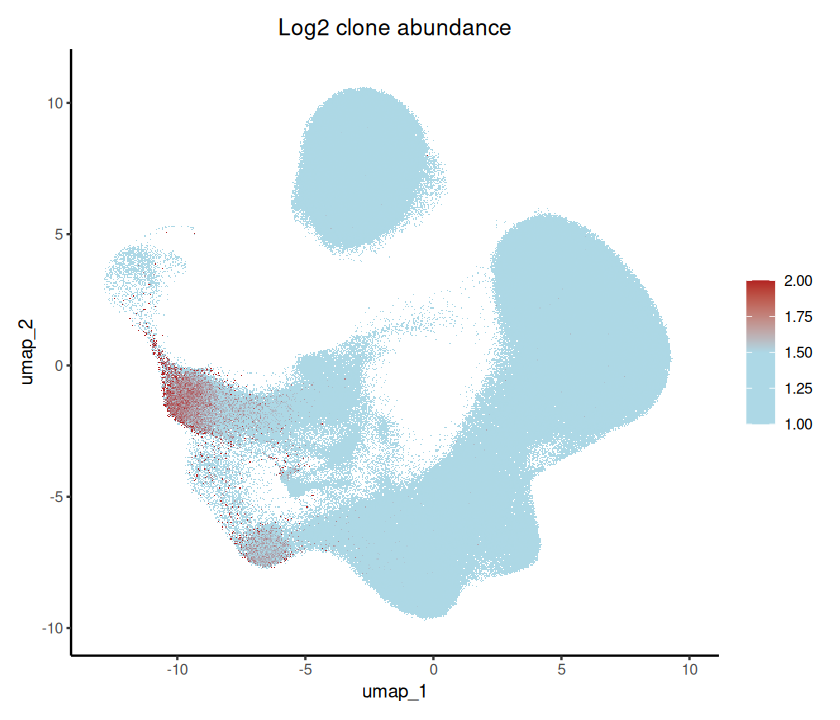

In [20]:
options(repr.plot.width = 7, repr.plot.height = 6)
FeaturePlot(subset(blood_5p, clone_abundance >=1 & clone_abundance < 2000), 
            reduction = "umap", features = "log_clone_abundance", 
            cols = c("lightblue","lightblue","firebrick"), max.cutoff = 10) + 
theme_classic() + theme(plot.title = element_text(hjust = 0.5)) + ggtitle("Log2 clone abundance")

In [71]:
# Clone abundance bar graph
metadata_6 <- metadata_6 %>%
  mutate( clone_abundance_group = case_when(clone_abundance>10 ~ ">10",
                                            clone_abundance>6 & clone_abundance<10 ~ "6-9",
                                            clone_abundance>2 & clone_abundance<=5 ~ "3-5",
                                            clone_abundance== 2 ~ "2",
                                            clone_abundance== 1 ~ "1",
                                            TRUE ~ "1"
                                            ))

In [72]:
metadata_6$seurat_clusters2  %>% table

.
     1      2      4      3      8      7     10      9     11      5      6 
106441 196865  62393  57801  39620  27184  25271  22902  17326  17024  12014 
    12     13 
  4840   3893 

In [73]:
metadata_6$annotations_with_ctl  <- if_else(metadata_6$cd4_ctl, "CD4_CTL", metadata_6$seurat_clusters2)

In [67]:
metadata_6$annotations_with_ctl  %>% table

.
      1      10      11      12      13       2       3       4       5       6 
 106441   25271   15721    4840    3882  196865   57801   62393   17024   12014 
      7       8       9 CD4_CTL 
  27184   39620   22902    1616 

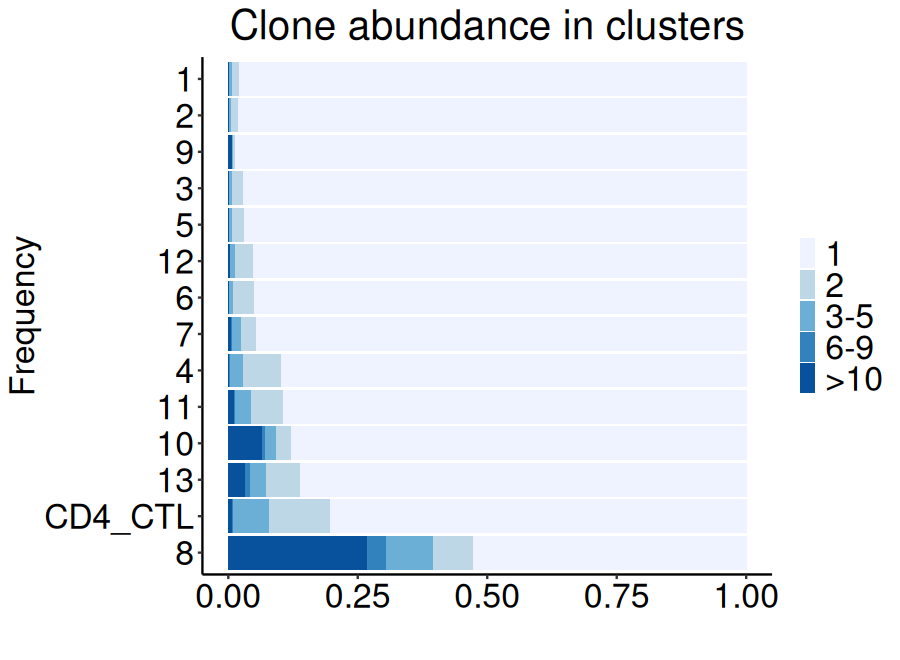

In [78]:
options(repr.plot.width = 7.5, repr.plot.height = 5.5)

metadata_6 %>% 
  filter(!is.na(clone_abundance_group)) %>% 
  ggplot(aes(x = factor(annotations_with_ctl, levels = c(8,"CD4_CTL",13,10,11,4,7,6,12,5,3,9,2,1)))) + 
  geom_bar(aes(fill = factor(clone_abundance_group, 
                             levels = c("1","2","3-5","6-9",">10"))), position = "fill") + 
  coord_flip() +
  scale_fill_brewer(palette = "Blues") + xlab("Frequency")+
  ylab("") + 
  theme_classic() + 
  theme(plot.title = element_text(hjust = 0.5), 
        legend.position="right", 
        panel.border = element_blank(), 
        legend.title = element_blank(),
       axis.text = element_text(color = "black")) + 
  ggtitle("Clone abundance in clusters") + ggtheme() 
ggsave("figures/tcr/clone_abundance_barplot_blood.png", width = 30, height = 12, units = "cm")
ggsave("figures/tcr/clone_abundance_barplot_blood.svg", width = 30, height = 12, units = "cm")

In [19]:
clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          tally %>%
    arrange(desc(n))  %>% dplyr::filter(!grepl(clone_aa, pattern = " NA"))

clone_table

clone_aa,n
<chr>,<int>
CDR3b CASSARSYGDSPLHF CDR3a CATDNYNNNDMRF,842
CDR3b CATSAFSNEQFF CDR3a CAETRGADGLTF,211
CDR3b CASSLKRGIDTGELFF CDR3a CAGGTYGNKLVF,189
CDR3b CASSLARHNSPLHF CDR3a CALSEAETNFGNEKLTF,179
CDR3b CASSLMNSYEQYF CDR3a CALSDNFGNEKLTF,121
CDR3b CASSQRAGGRSGNTIYF CDR3a CGTEGGDYKLSF,120
CDR3b CASSPIYTSGGVWTQYF CDR3a CLVGDMGNNQGGKLIF,117
CDR3b CASSIAGTNAYNEQFF CDR3a CAVSDSGFKTIF,113
CDR3b CSASNPAGKTGELFF CDR3a CAASRDSNYQLIW,112


Warning message:
“Removing 109563 cells missing data for vars requested”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



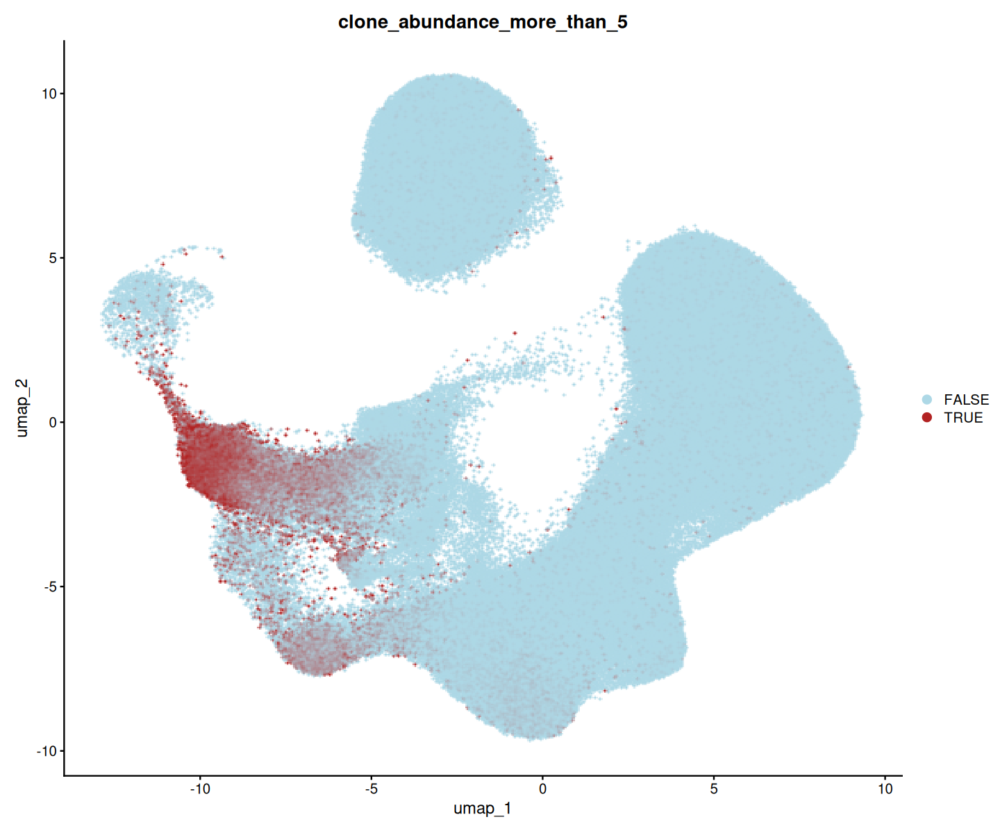

In [99]:
options(repr.plot.width = 12, repr.plot.height = 10)
blood_5p$clone_abundance_more_than_5  <- blood_5p$clone_abundance>2

DimPlot(subset(blood_5p, clone_abundance >=1 & clone_abundance < 2000), 
        pt.size = 1.5, group.by = "clone_abundance_more_than_5", order = TRUE,
        cols = c("lightblue","firebrick"))

✔ Created directory: ../figures/tcr/tcr_plots_blood.



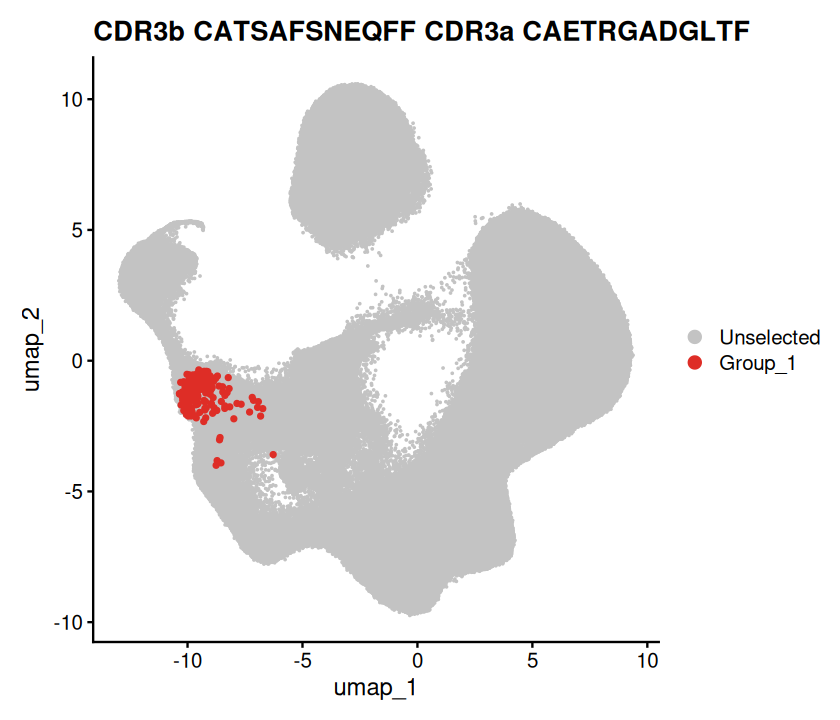

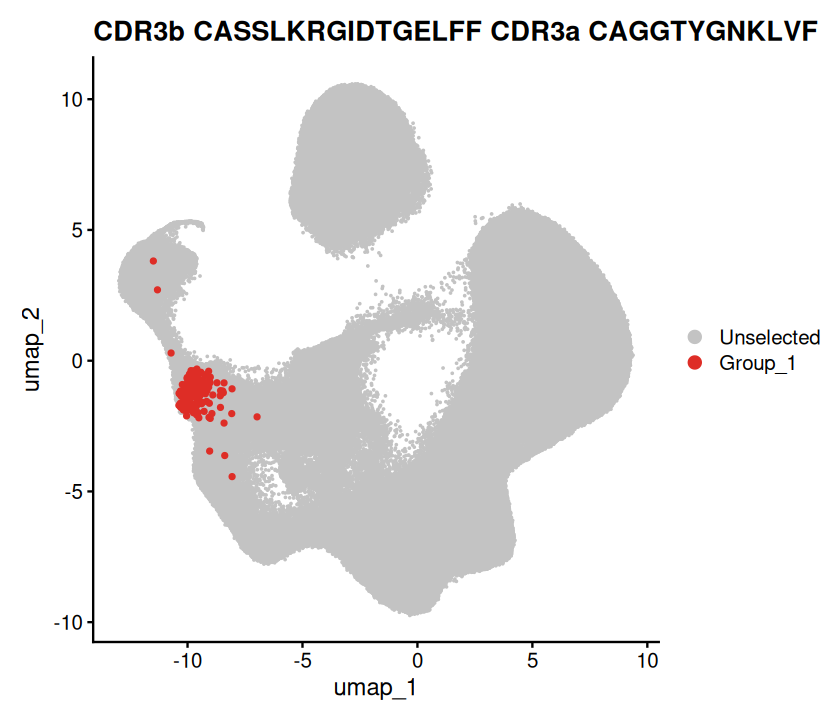

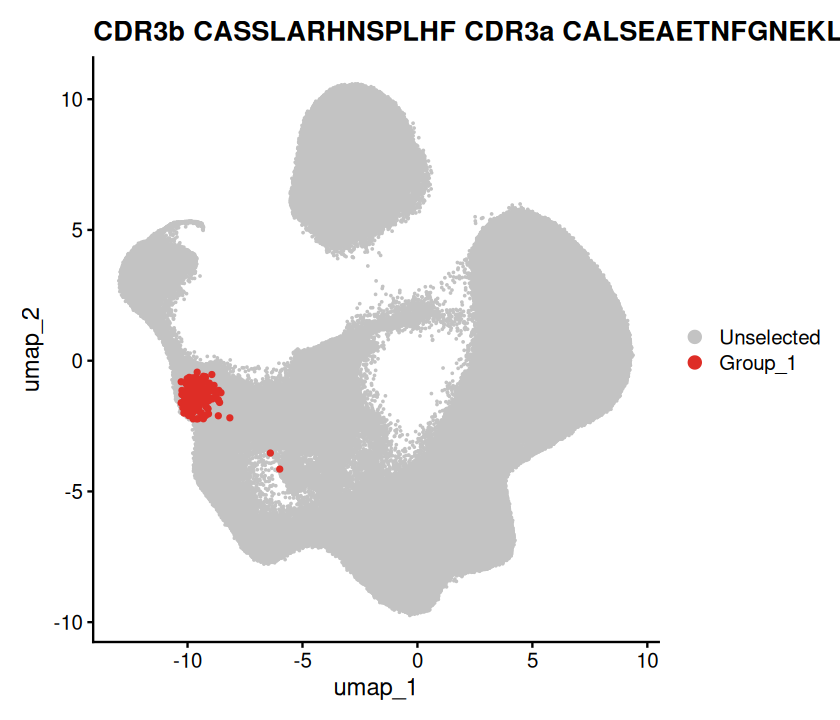

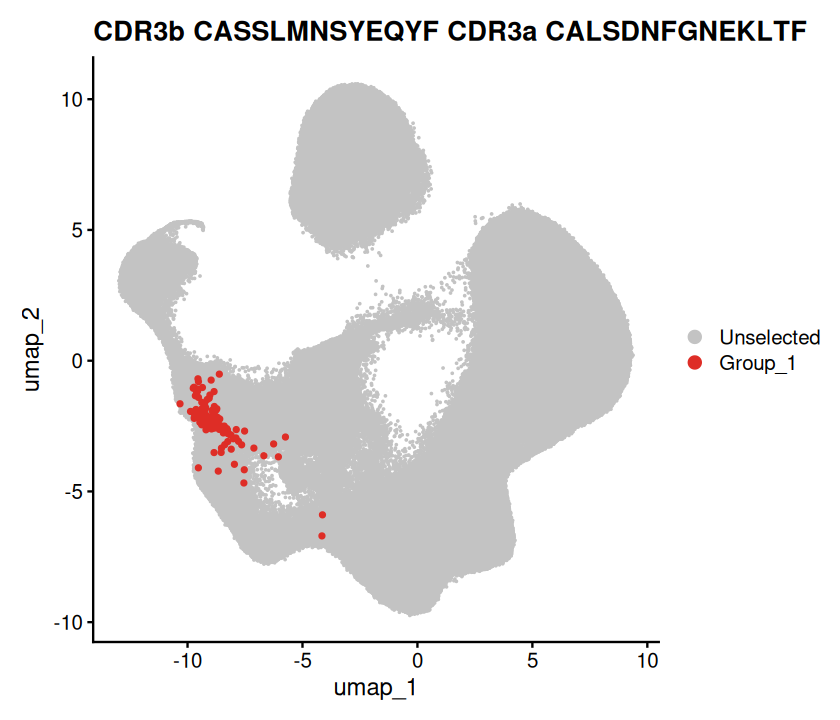

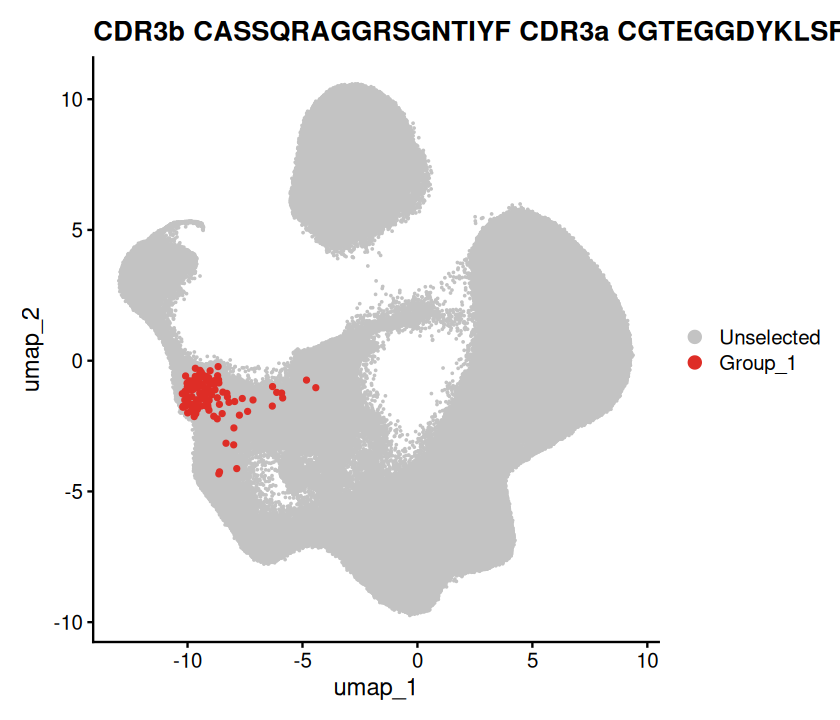

...

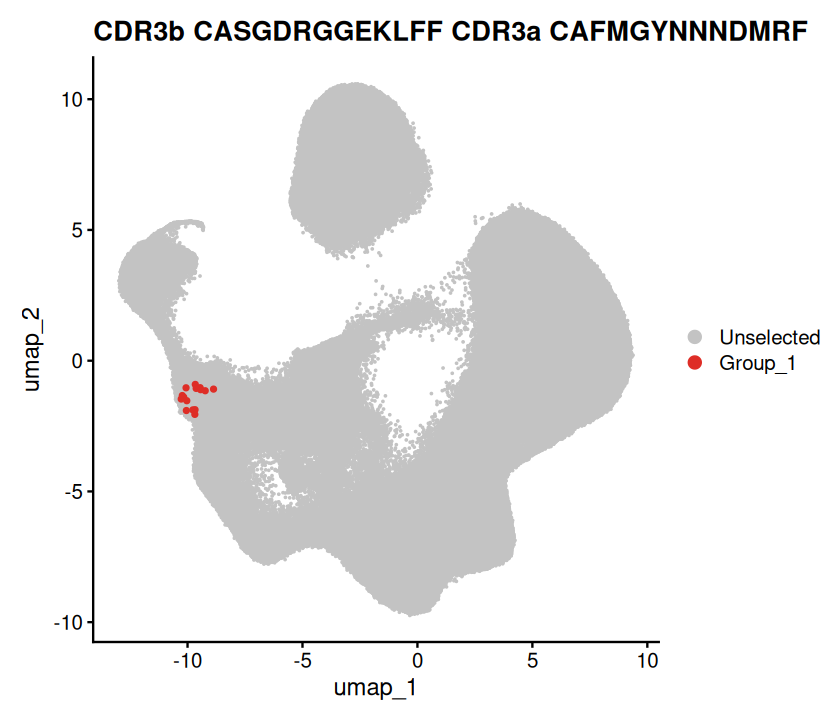

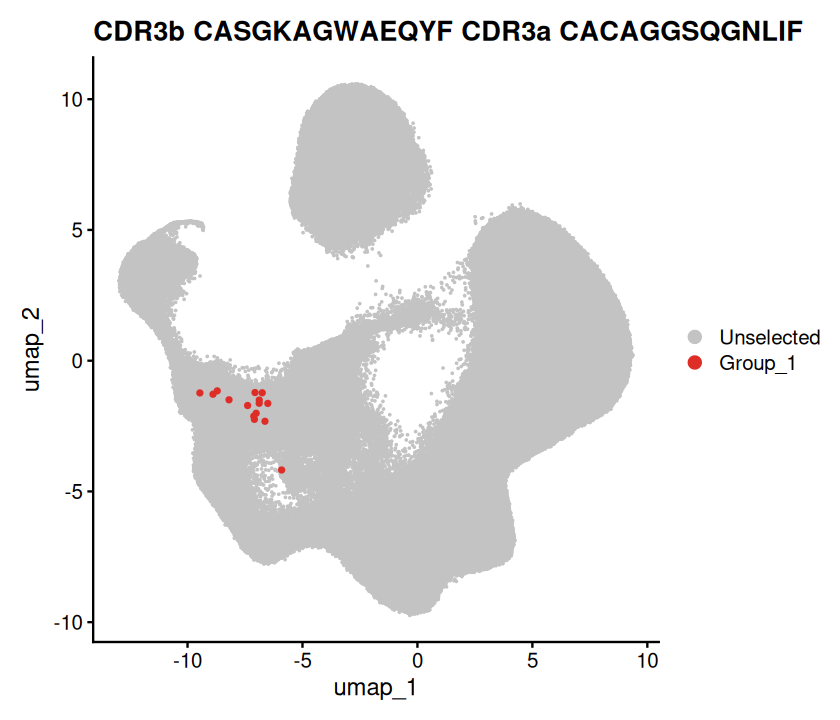

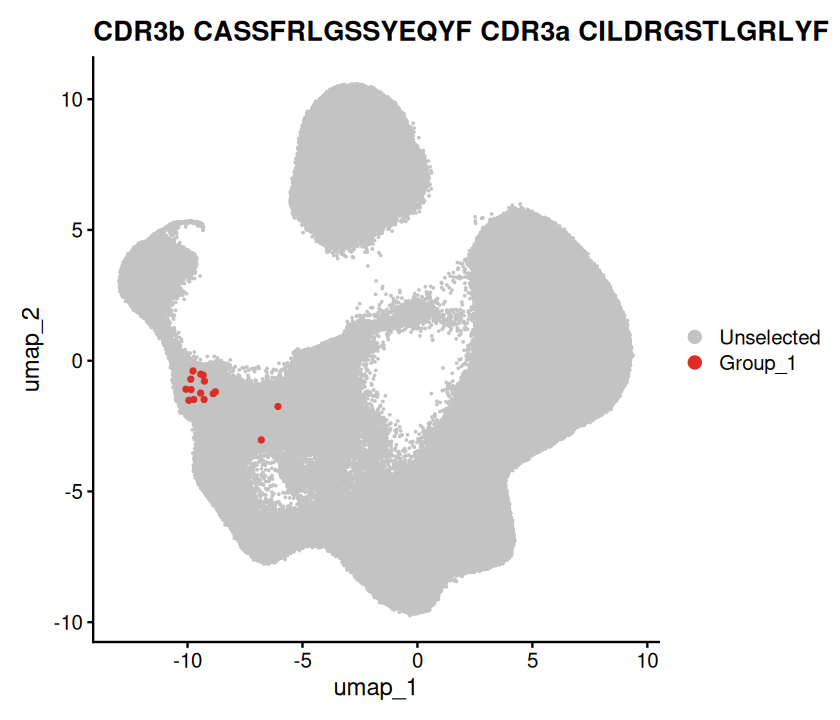

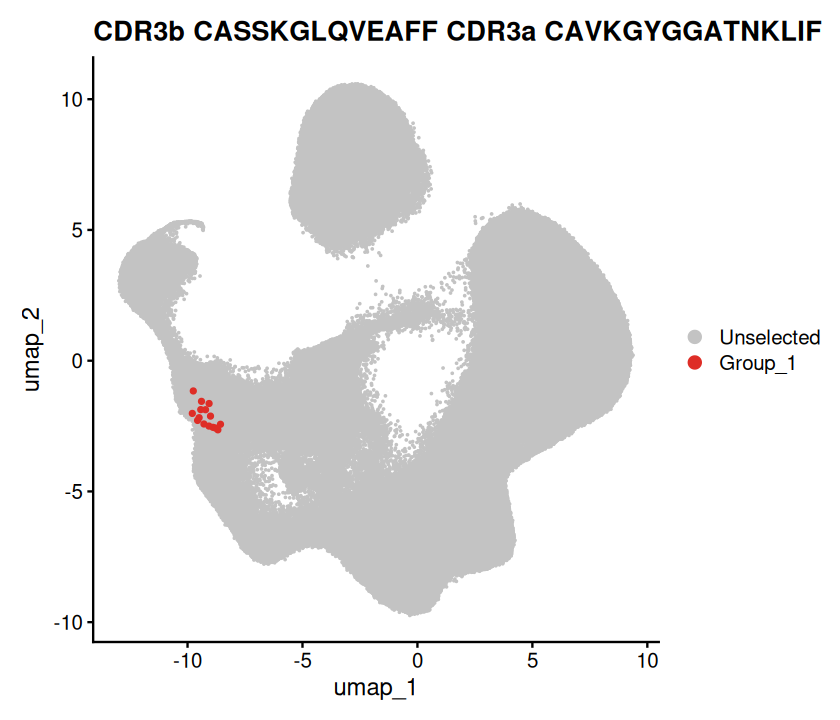

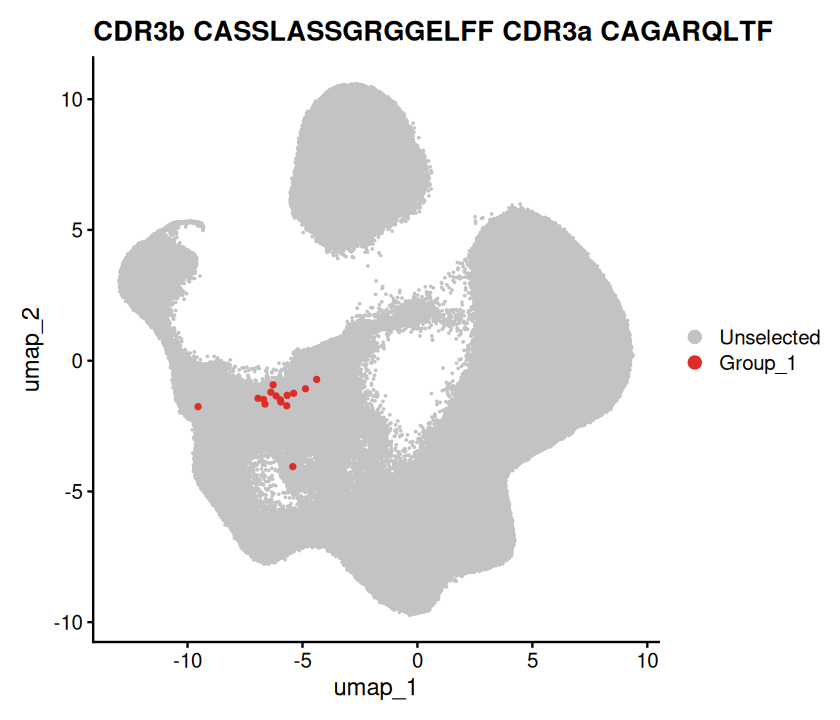

In [31]:
for(i in 2:150){
  print(DimPlot(blood_5p, raster = F, 
          cells.highlight = colnames(blood_5p)[grep(blood_5p$clone_aa, 
                                                       pattern = pull(clone_table, clone_aa)[i])]) +
    ggtitle(pull(clone_table, clone_aa)[i]))
    ggsave(paste0("../figures/tcr/tcr_plots_blood/tcr_clone_",i,".png"), 
    create.dir = TRUE, width = 13, height = 10, units = "cm")

}

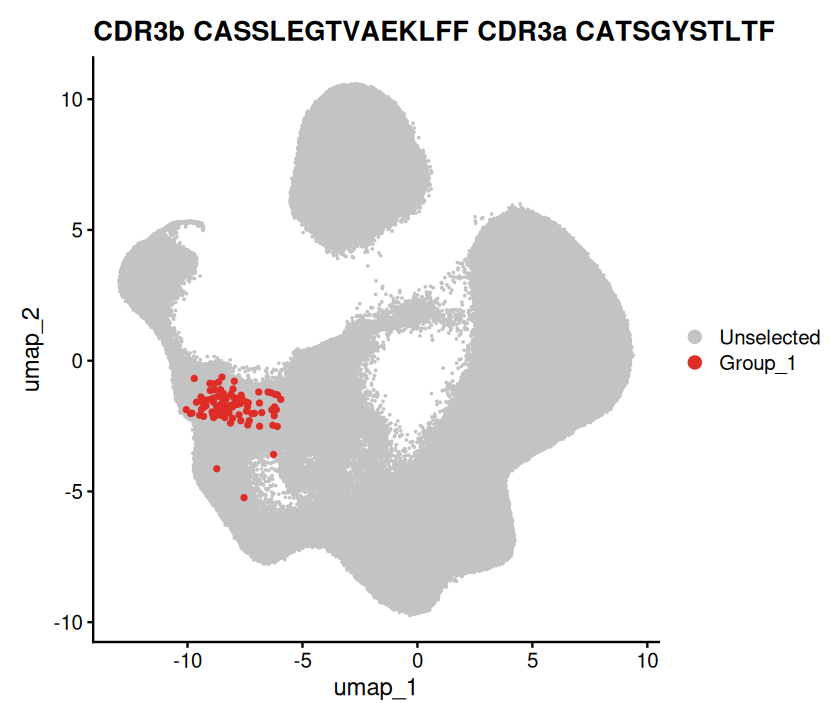

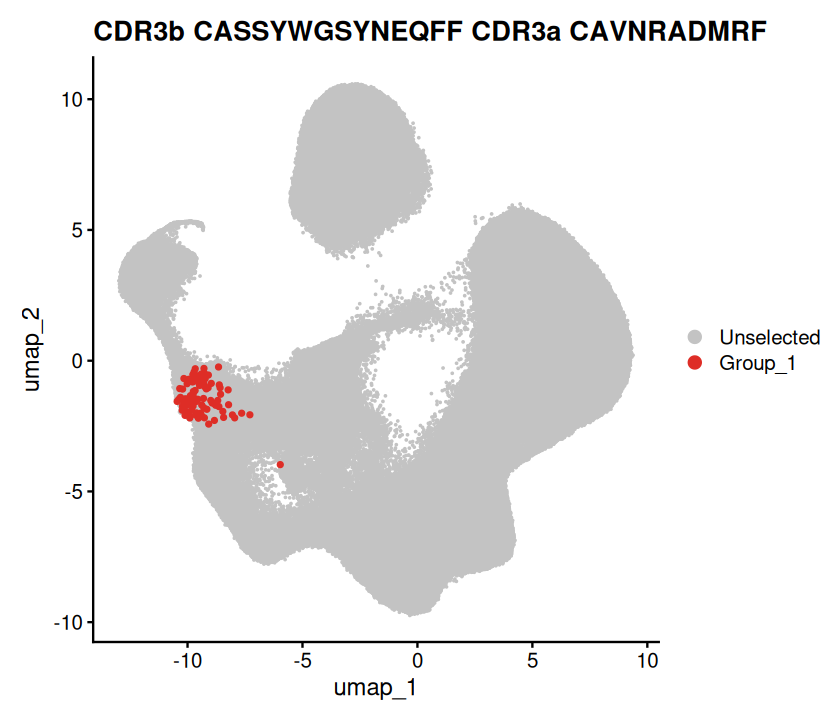

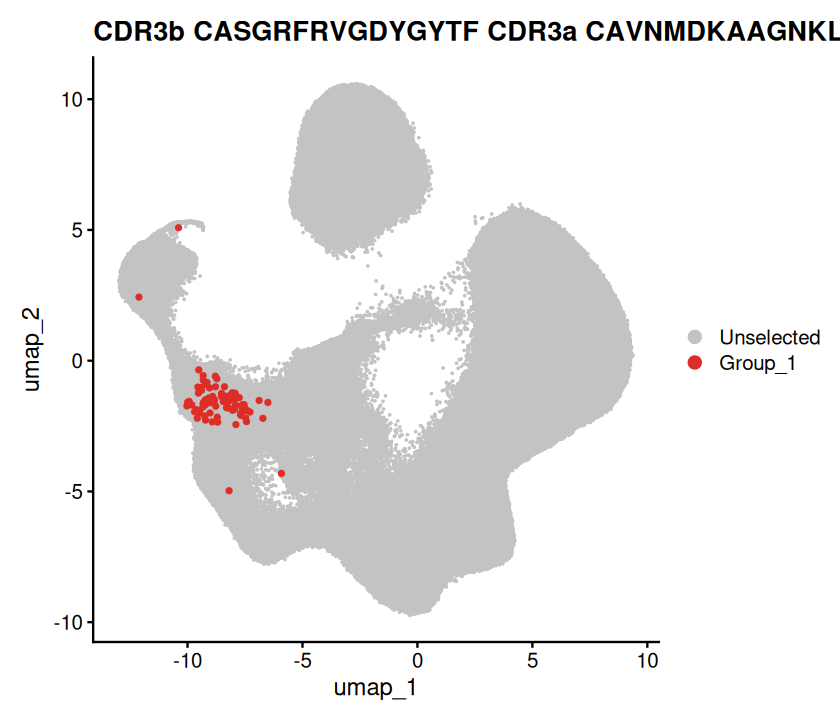

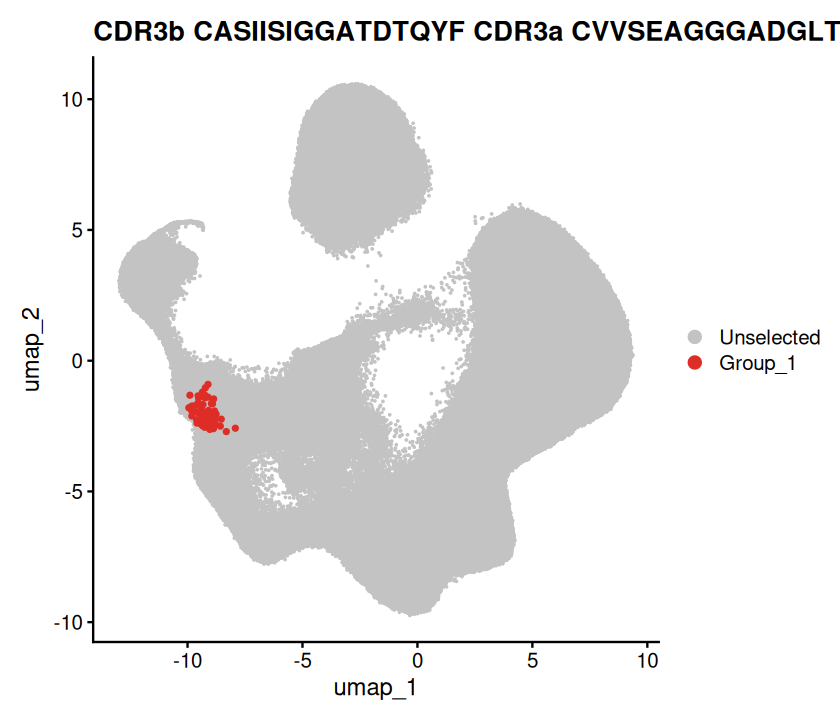

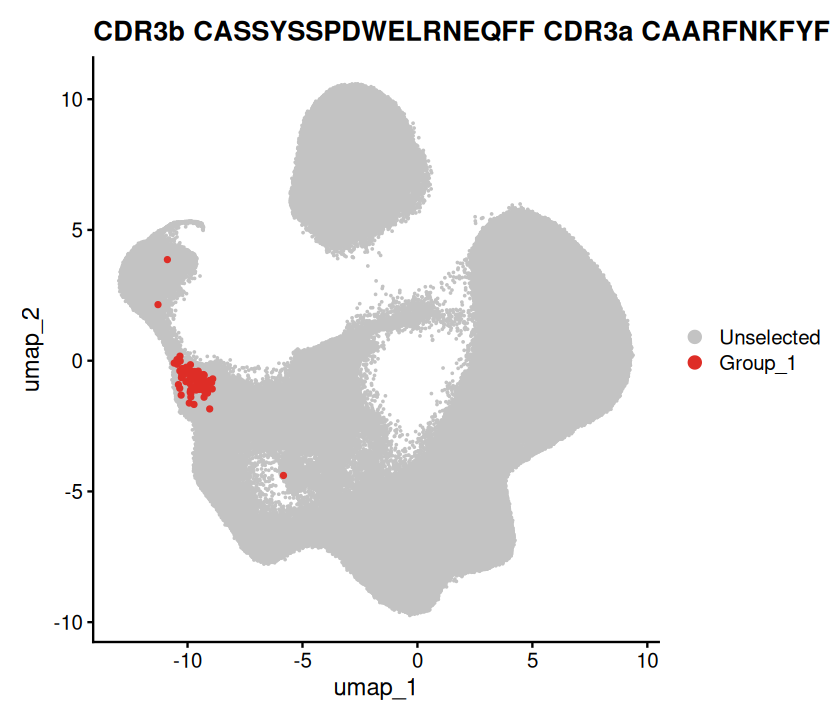

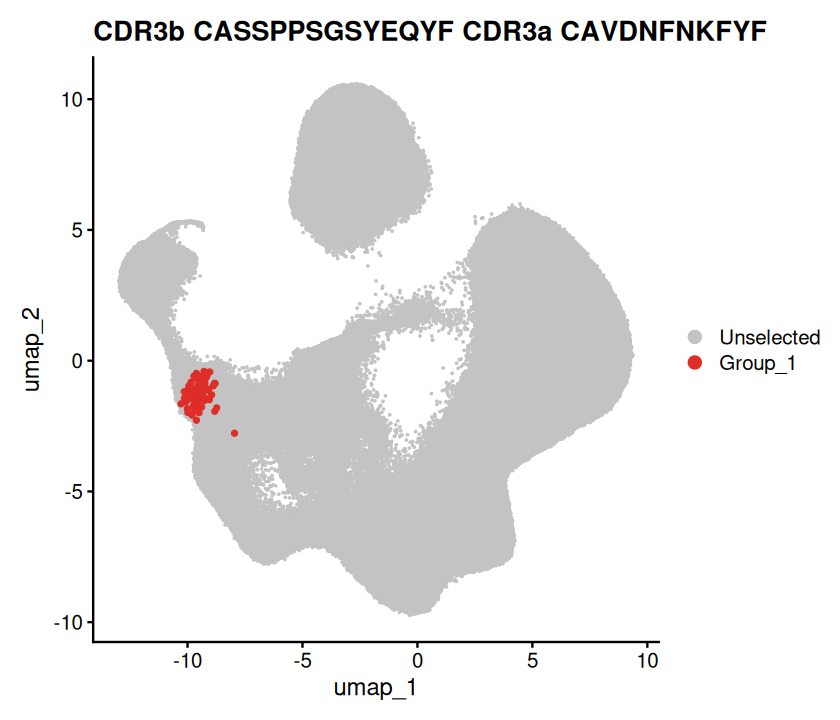

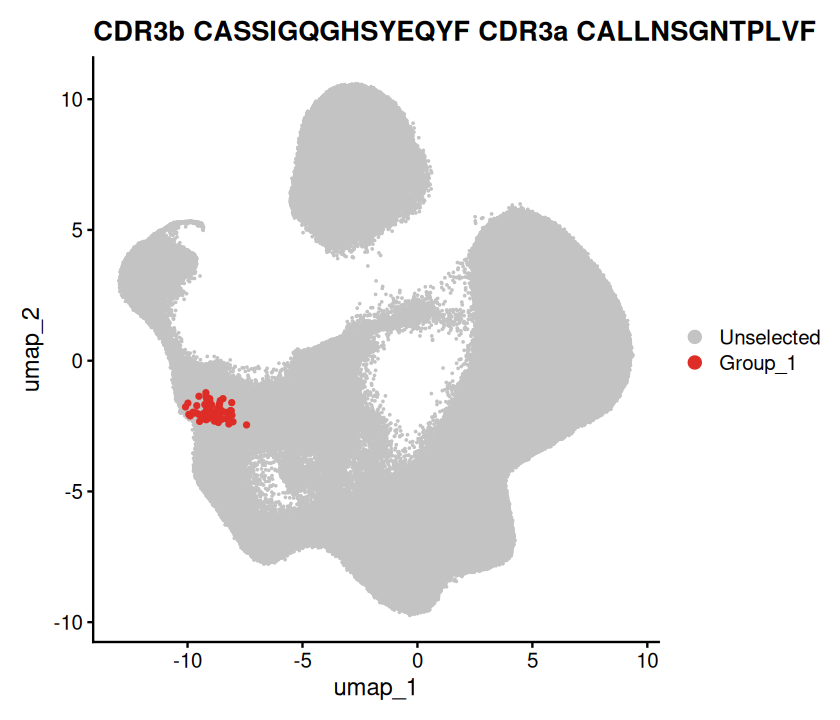

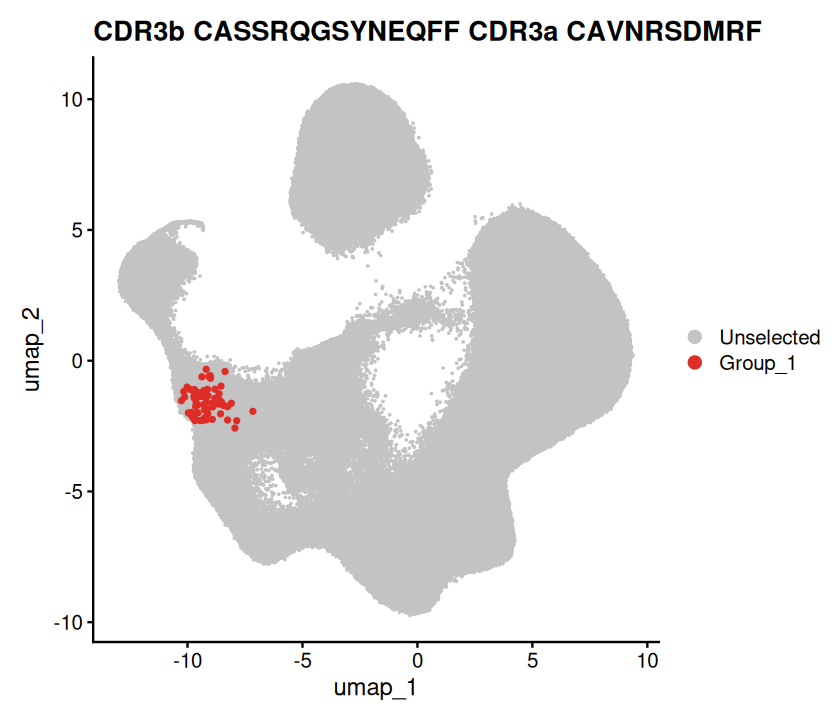

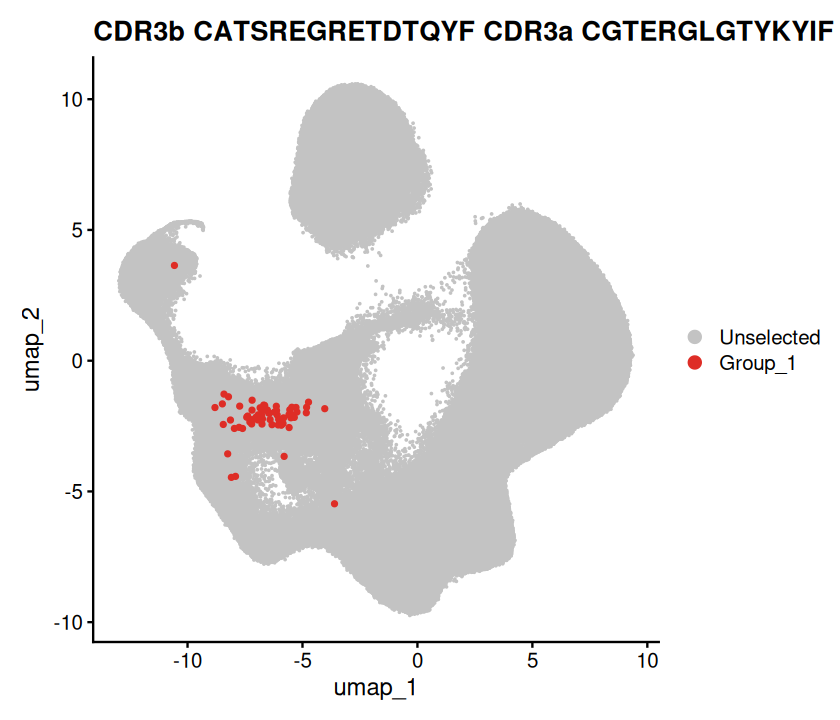

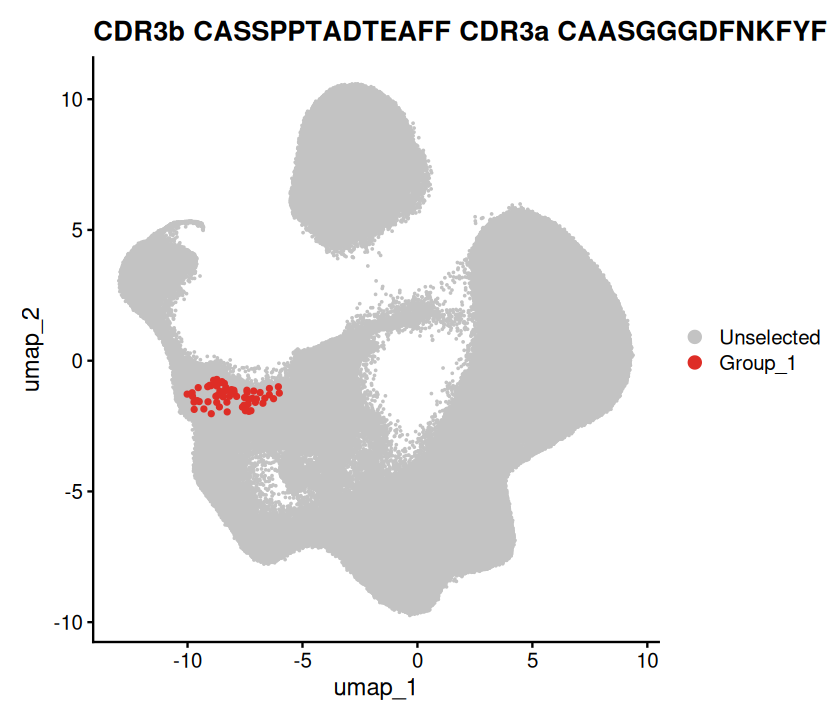

In [30]:
for(i in 11:20){
  print(DimPlot(blood_5p, raster = F, 
          cells.highlight = colnames(blood_5p)[grep(blood_5p$clone_aa, 
                                                       pattern = pull(clone_table, clone_aa)[i])]) +
    ggtitle(pull(clone_table, clone_aa)[i]))
    #ggsave(paste0("../figures/tcr/cd8_tcr/tcr_plots_cd8_full/tcr_clone_",i,".png"), create.dir = TRUE, width = 13, height = 10, units = "cm")

}

# MAIT cells & iNKT

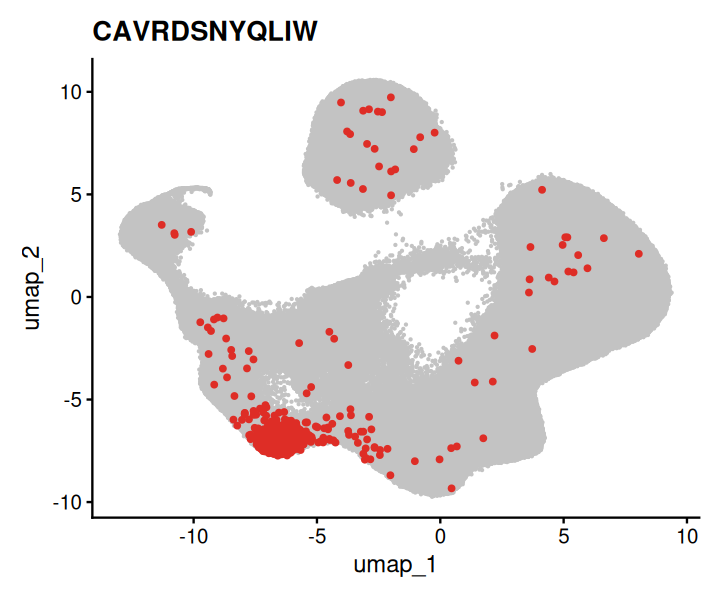

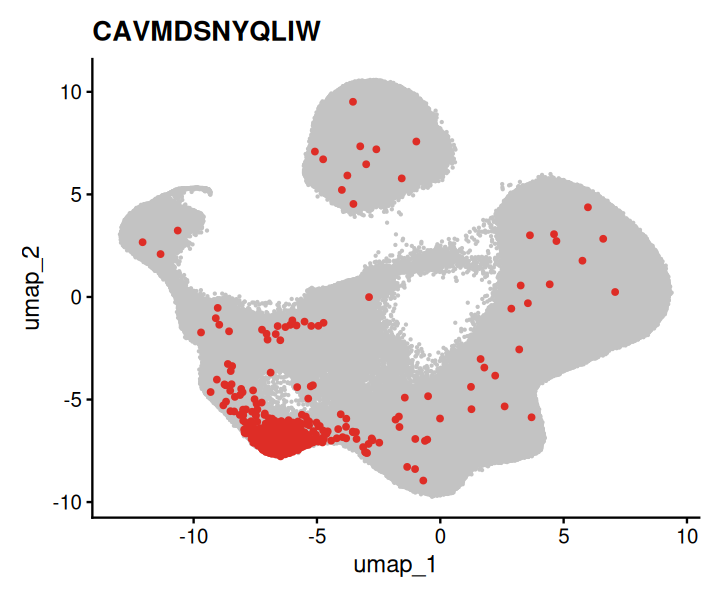

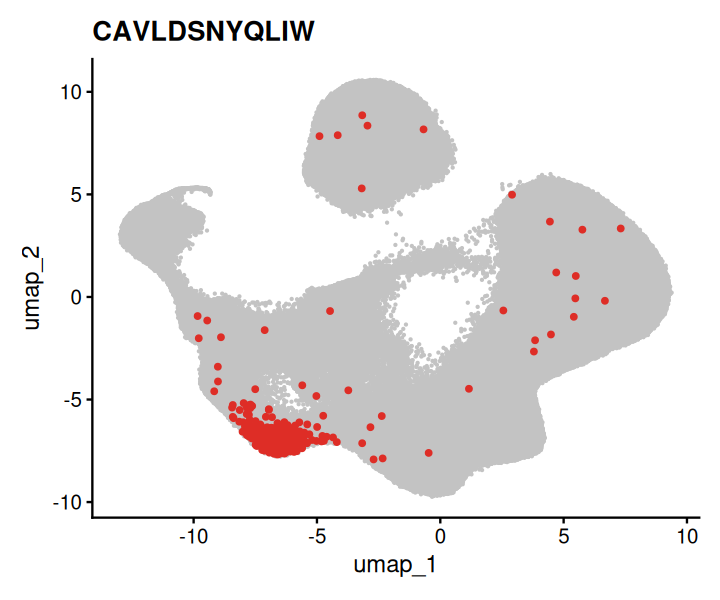

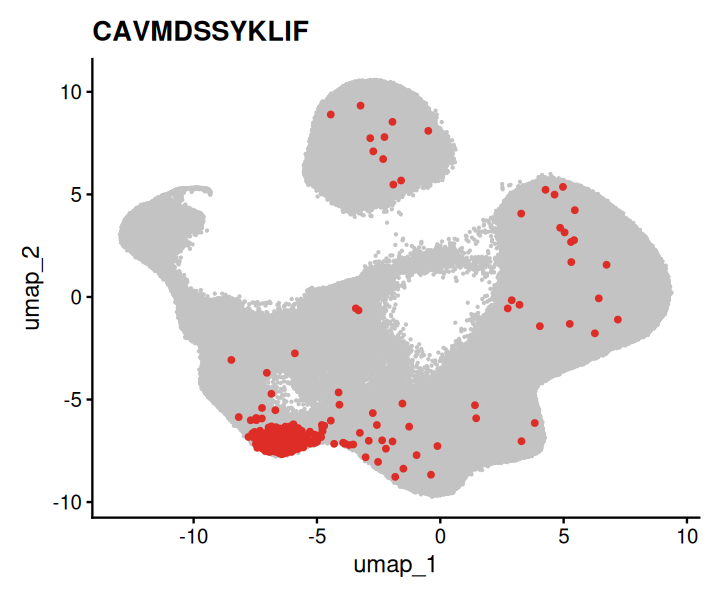

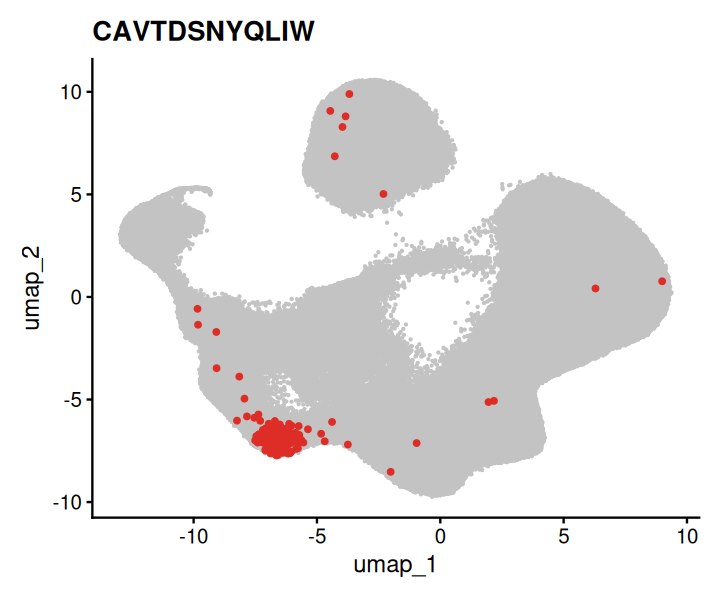

...

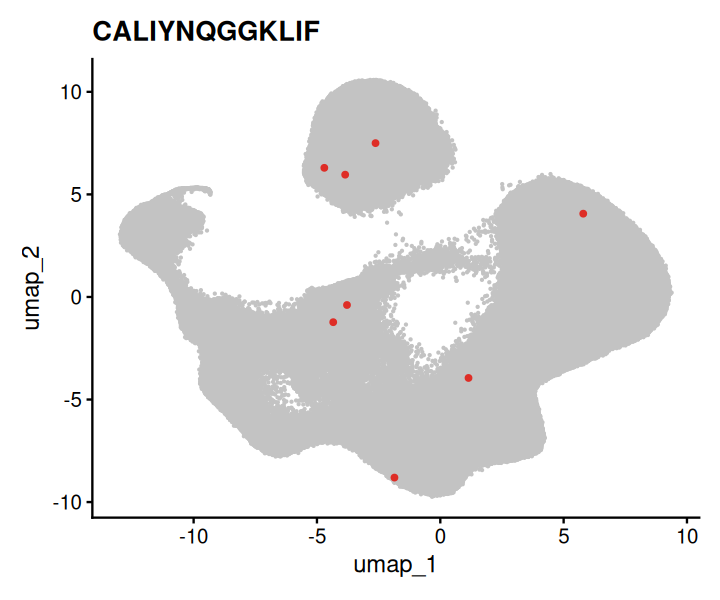

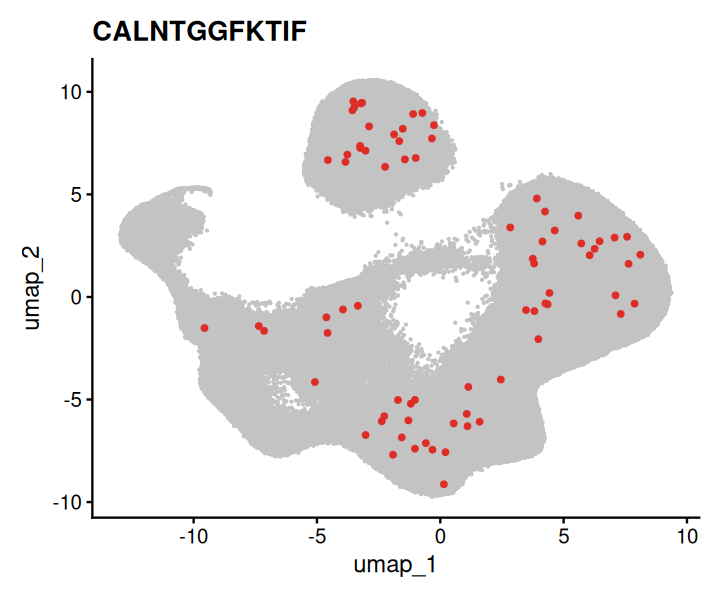

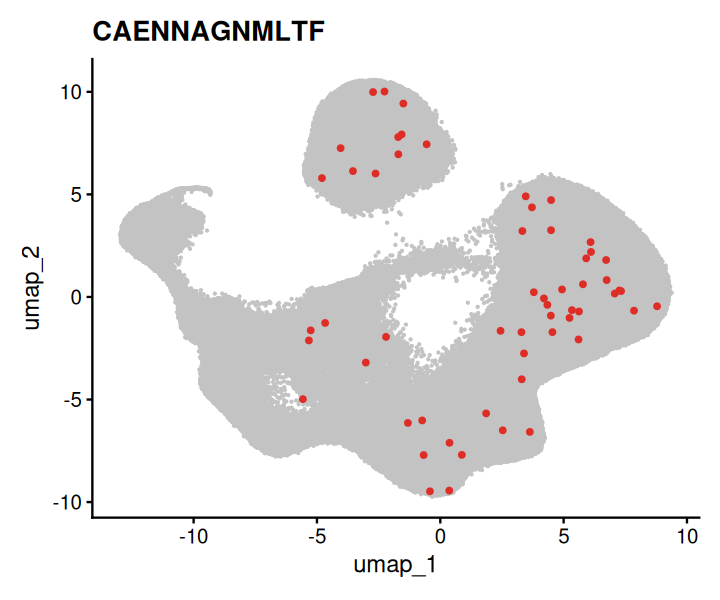

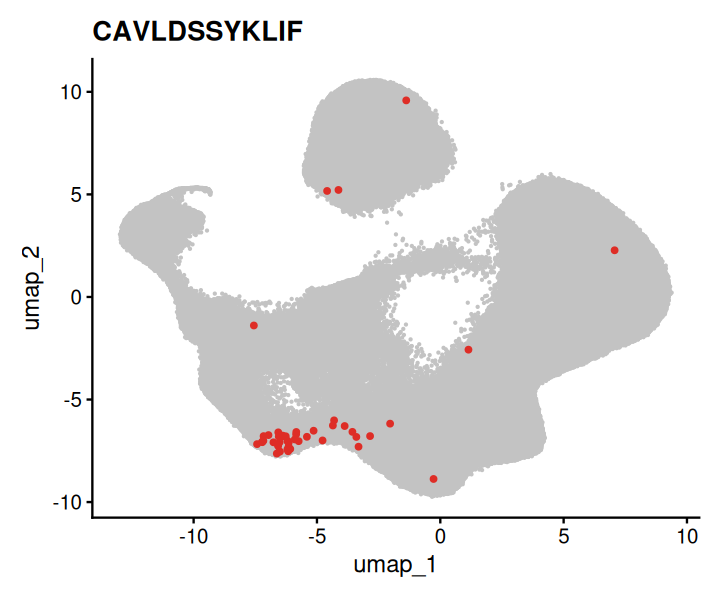

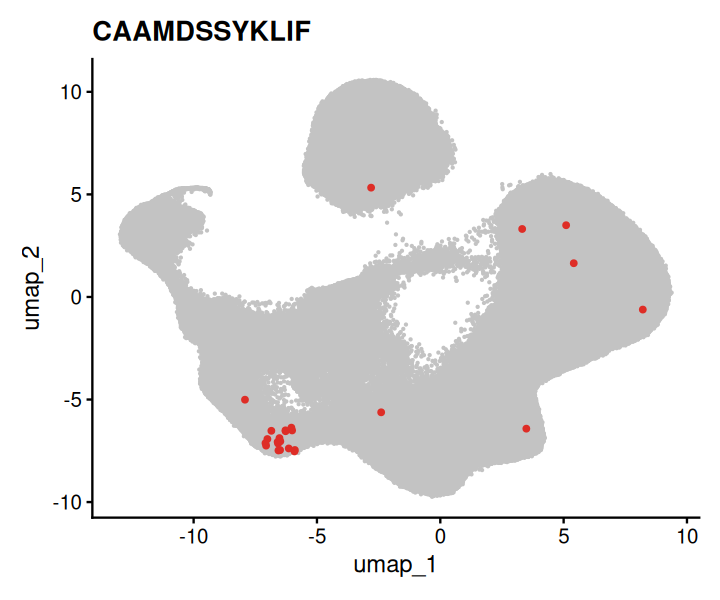

In [24]:
options(repr.plot.width = 6, repr.plot.height = 5)
for(i in c('CAVRDSNYQLIW', 'CAVMDSNYQLIW', 'CAVLDSNYQLIW', 'CAVMDSSYKLIF', 'CAVTDSNYQLIW', 'CAVRDGDYKLSF', 'CAVKDSNYQLIW', 'CAAMDSNYQLIW', 'CAALDSNYQLIW', 'CALNDYKLSF', 'CAVVDSNYQLIW', 'CVVSDRGSTLGRLYF', 'CAVIDSNYQLIW', 'CAENTGGFKTIF', 'CAVSDSNYQLIW', 'CALSGGSNYKLTF', 'CAVEDQTGANNLFF', 'CALSDSGGGADGLTF', 'CAVRDRDYKLSF', 'CAGMDSNYQLIW', 'CAVNDYKLSF', 'CAPMDSNYQLIW', 'CASMDSNYQLIW', 'CAVNRDDKIIF', 'CAENSGGSNYKLTF', 'CAPLDSNYQLIW', 'CALNSGGSNYKLTF', 'CVVNDYKLSF', 'CALSSNDYKLSF', 'CAASNQAGTALIF', 'CVVNTGNQFYF', 'CVVNTNAGKSTF', 'CAVEDTGGFKTIF', 'CAVEDSNYQLIW', 'CAVDNYGQNFVF', 'CALSDSGGSNYKLTF', 'CAVMDSSYKLIF', 'CAVNTGGFKTIF', 'CAVRDGNYQLIW', 'CALNTGFQKLVF', 'CAENTGTASKLTF', 'CAATDSNYQLIW', 'CAVNQAGTALIF', 'CAENYGGSQGNLIF', 'CAVLNRDDKIIF', 'CAVEDNYGQNFVF', 'CAVNDYKLSF', 'CVVNNARLMF', 'CAVDNYGQNFVF', 'CAVDSSASKIIF', 'CALIYNQGGKLIF', 'CALNTGGFKTIF', 'CAENNAGNMLTF', 'CAVLDSSYKLIF', 'CAAMDSSYKLIF')){
   print(DimPlot(blood_5p, raster = F, cells.highlight = colnames(blood_5p)[grep(blood_5p$cdr3_A1, pattern = i)]) + NoLegend() + ggtitle(i))
   #ggsave(create.dir = TRUE, paste0("../figures/tcr/cd8_tcr/invariant_sequences2_cd8_full/",i,".png"), width = 18, height = 16, units = "cm")
}    
    

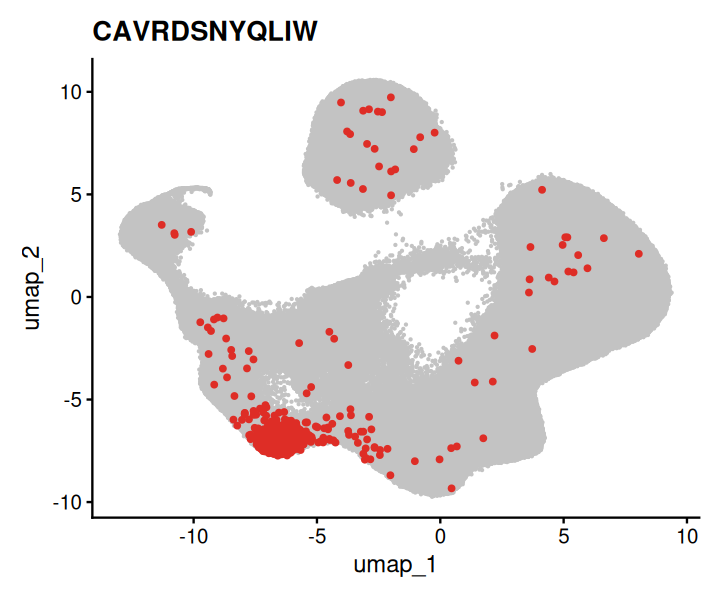

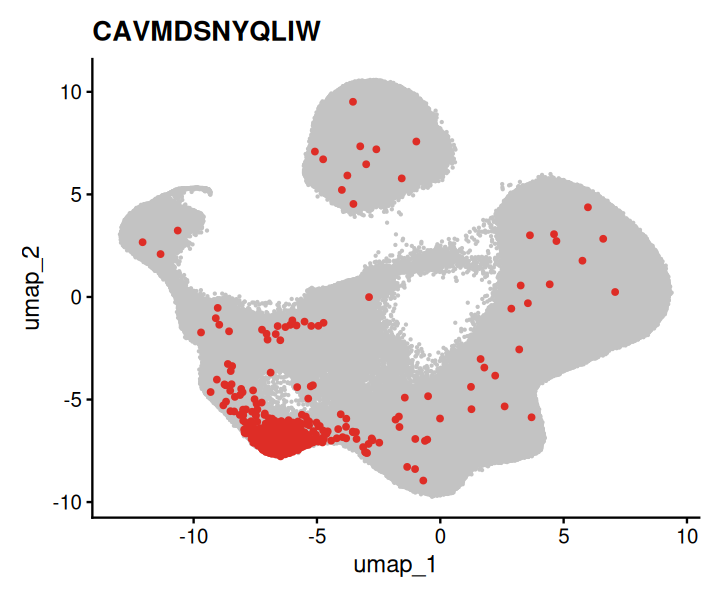

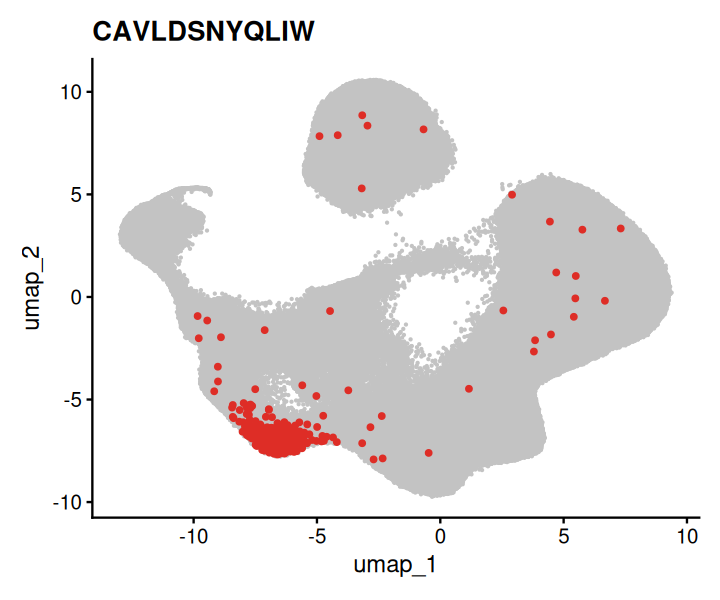

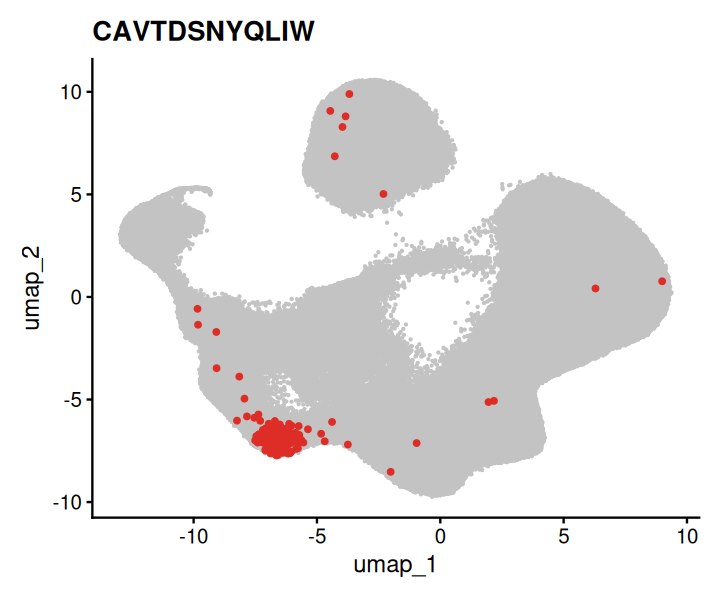

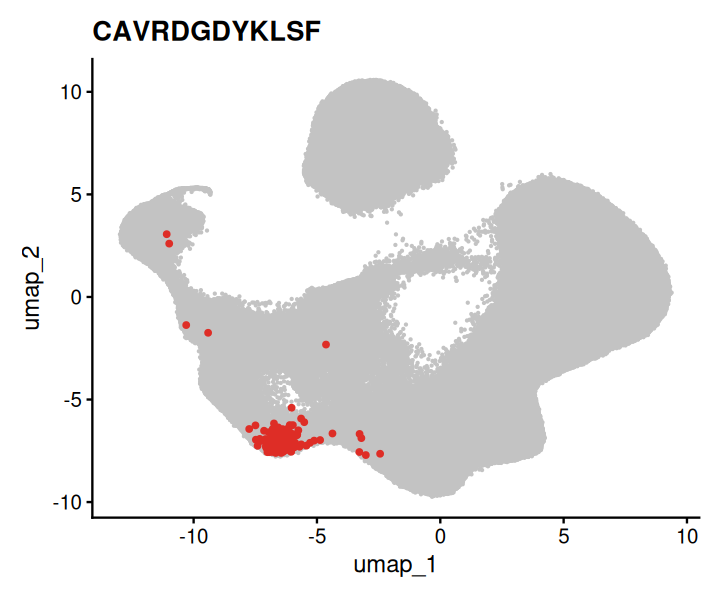

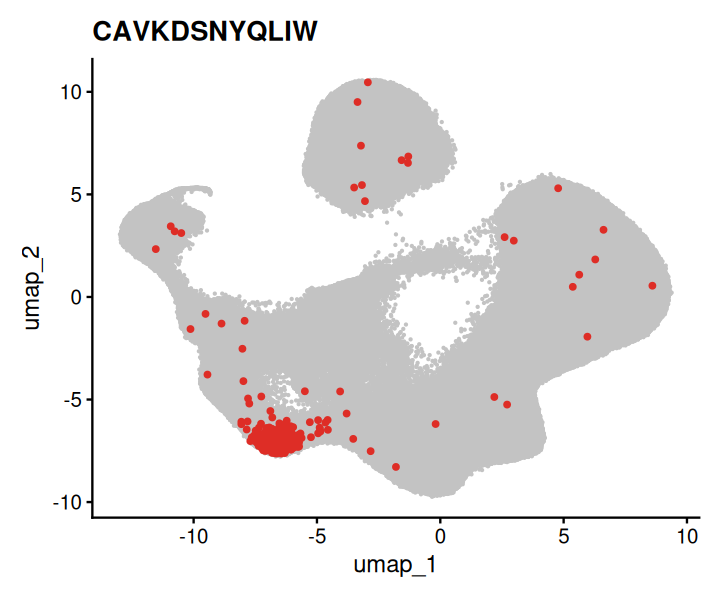

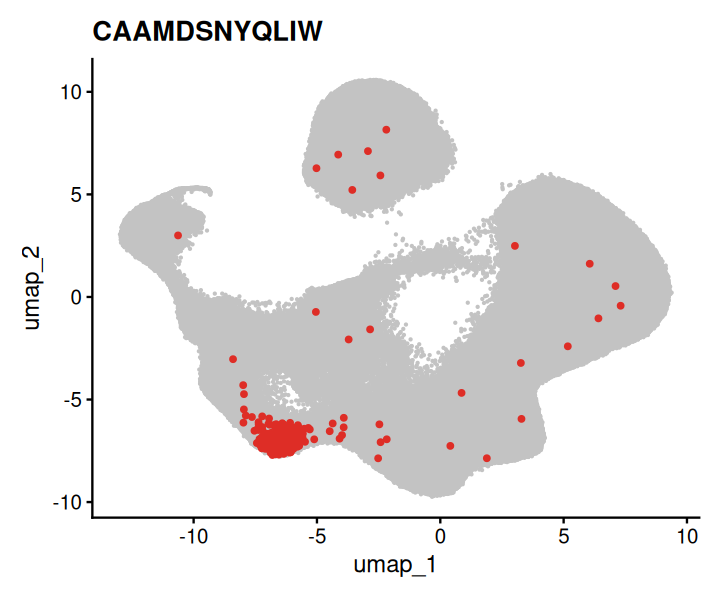

In [25]:
options(repr.plot.width = 6, repr.plot.height = 5)
for(i in c('CAVRDSNYQLIW', 'CAVMDSNYQLIW', 'CAVLDSNYQLIW',
           'CAVTDSNYQLIW', 'CAVRDGDYKLSF', 'CAVKDSNYQLIW', 'CAAMDSNYQLIW')){
   print(DimPlot(blood_5p, raster = F, cells.highlight = colnames(blood_5p)[grep(blood_5p$cdr3_A1, pattern = i)]) + NoLegend() + ggtitle(i))
   #ggsave(create.dir = TRUE, paste0("../figures/tcr/cd8_tcr/invariant_sequences2_cd8_full/",i,".png"), width = 18, height = 16, units = "cm")
}   

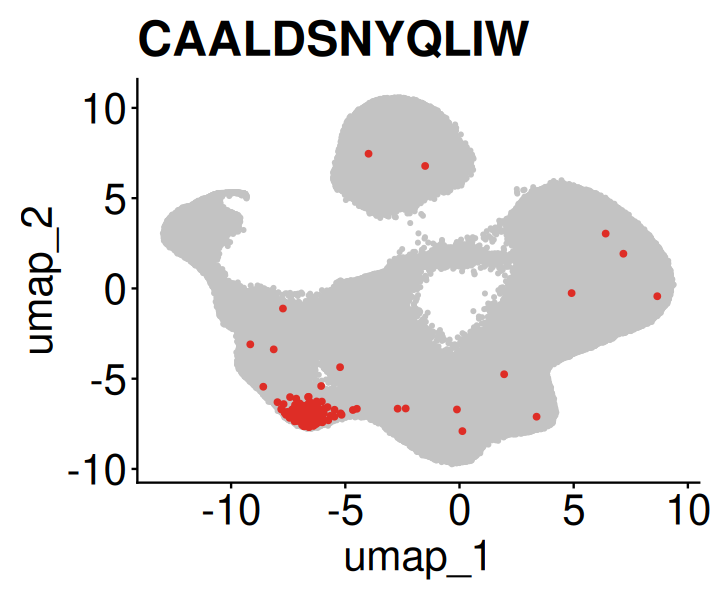

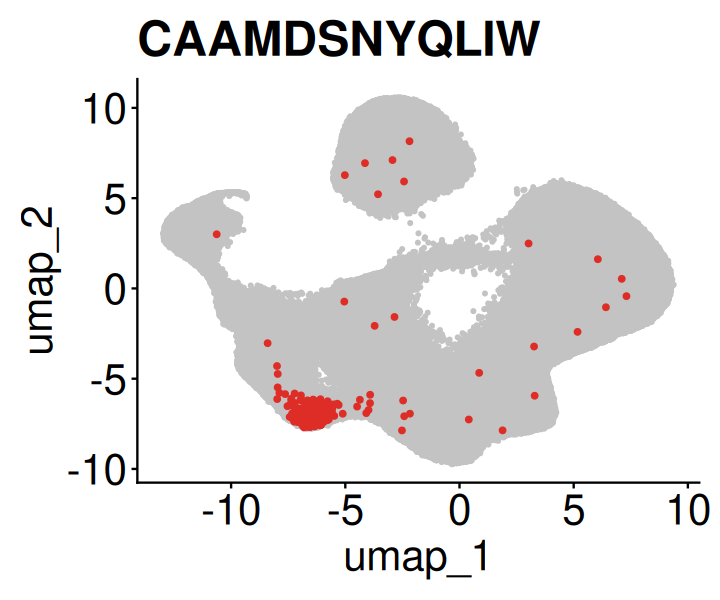

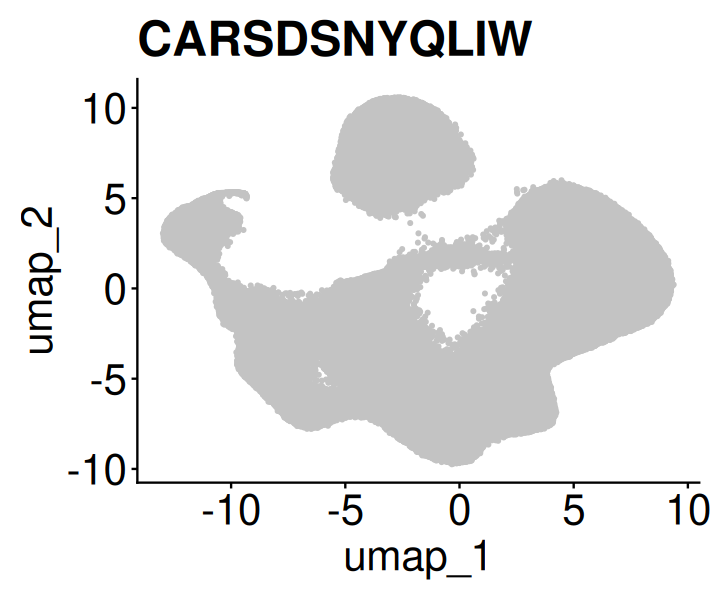

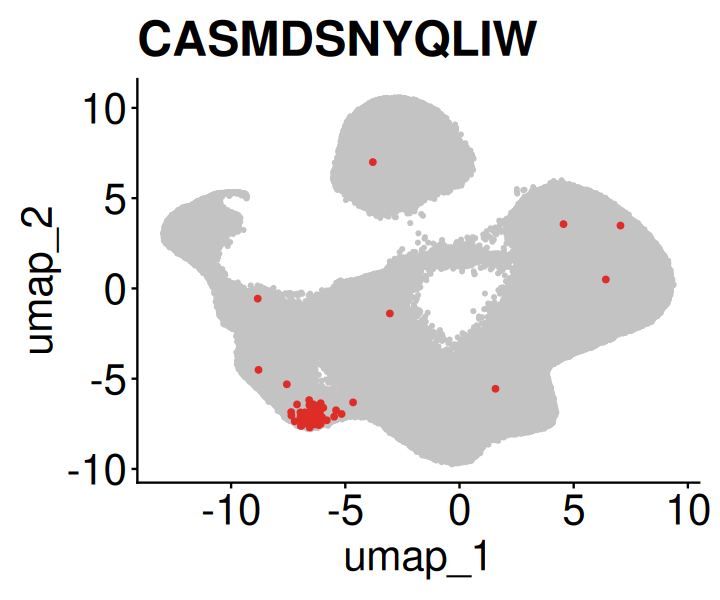

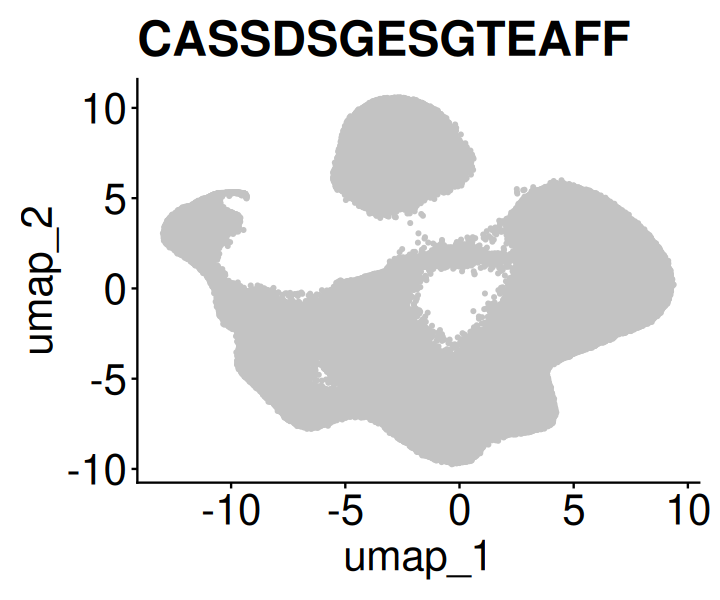

...

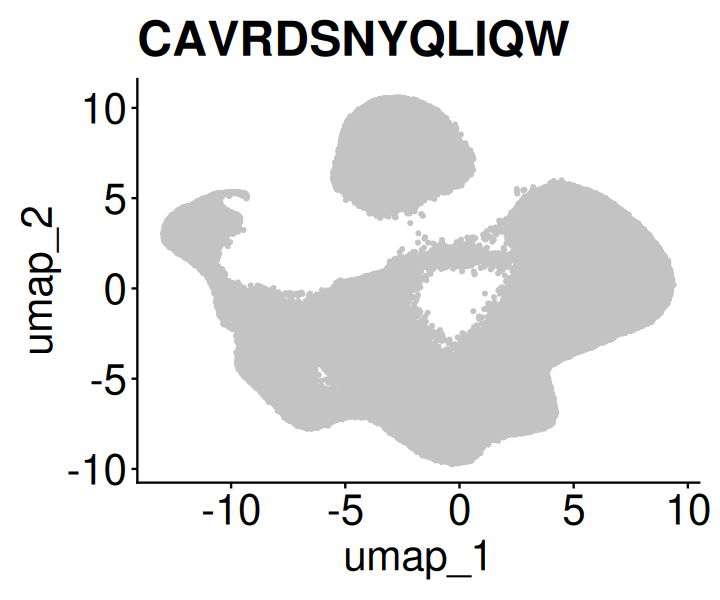

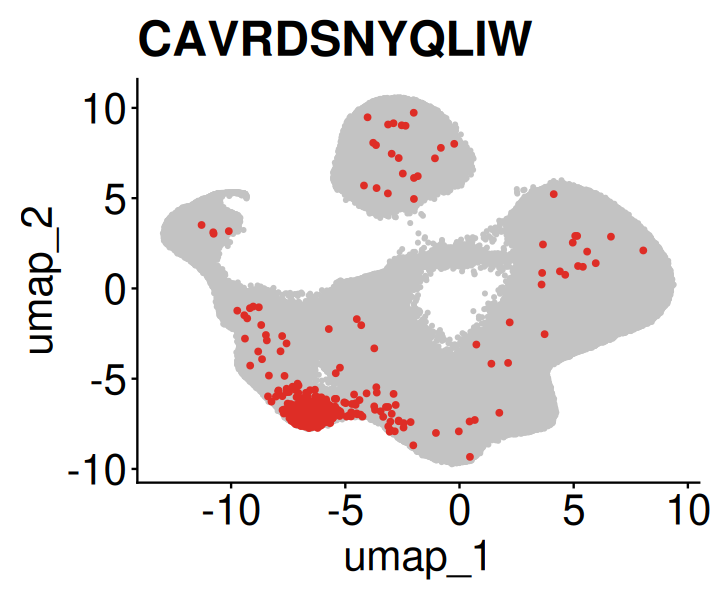

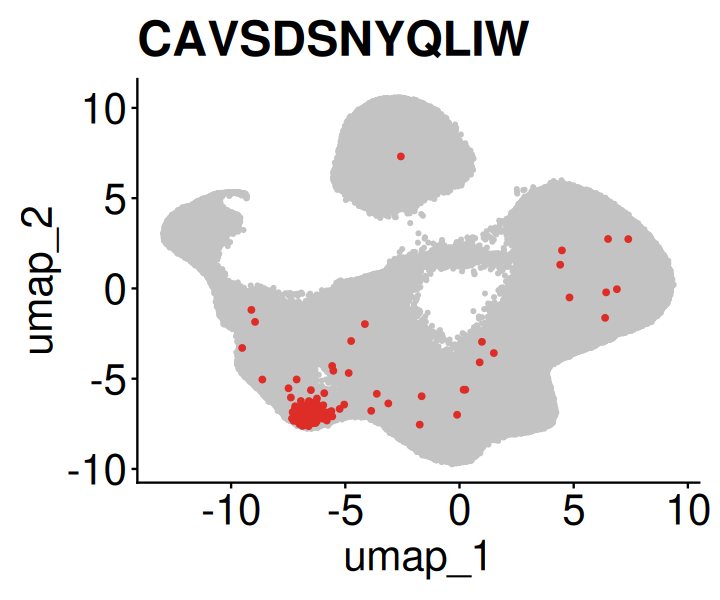

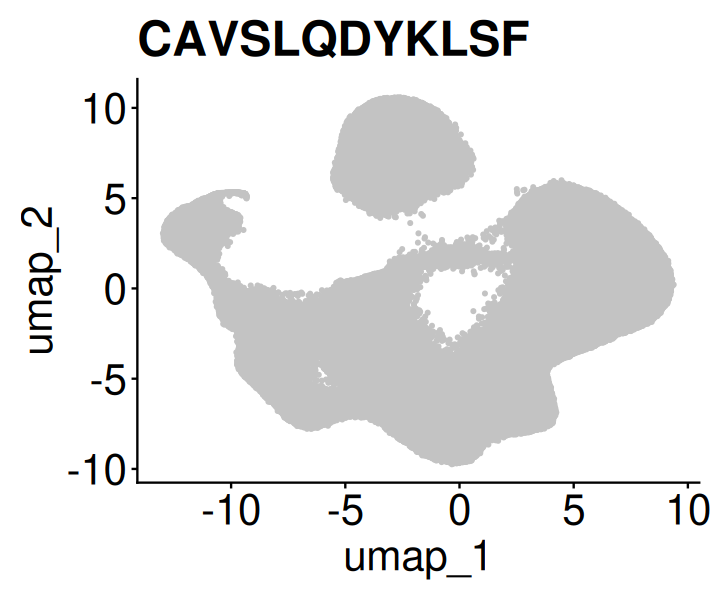

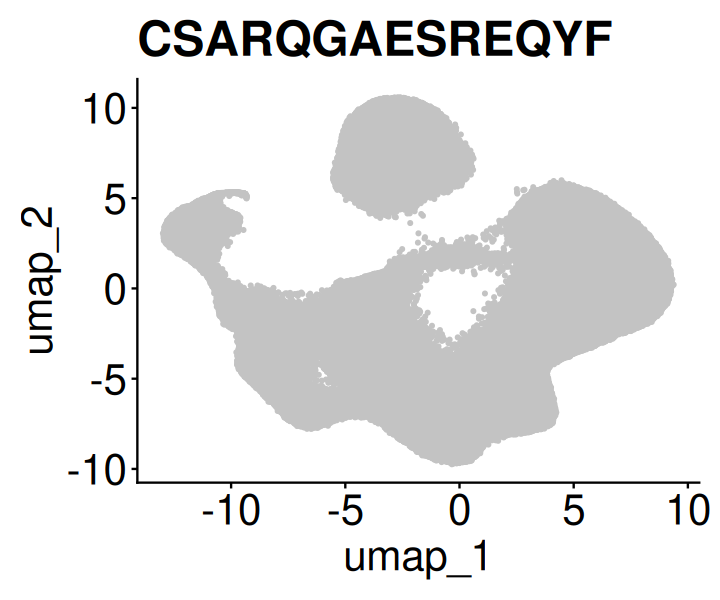

In [26]:
options(repr.plot.width = 6, repr.plot.height = 5)
for(i in c(
"CAALDSNYQLIW",
"CAAMDSNYQLIW",
"CARSDSNYQLIW",
"CASMDSNYQLIW",
"CASSDSGESGTEAFF",
"CASSPSGGDYNEQFF",
"CASSQIAGGQQETQYF",
"CAVLDSNYQLIW",
"CAVMDSNYQLIW",
"CAVNGDDYKLSF",
"CAVRDGDYKLSF",
"CAVRDSDYKLSF",
"CAVRDSNYQLIQW",
"CAVRDSNYQLIW",
"CAVSDSNYQLIW",
"CAVSLQDYKLSF",
"CSARQGAESREQYF"

)){
  print(DimPlot(blood_5p, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(blood_5p)[grep(blood_5p$cdr3_A1, pattern = i)]) + 
    ggtitle(i) + NoLegend() + theme(axis.text = element_text(size = 25), title = element_text(size = 25)))
   #ggsave(create.dir = TRUE, paste0("../figures/tcr/cd8_tcr/mait_sequences_cd8/",i,".png"), width = 18, height = 18, units = "cm")
}

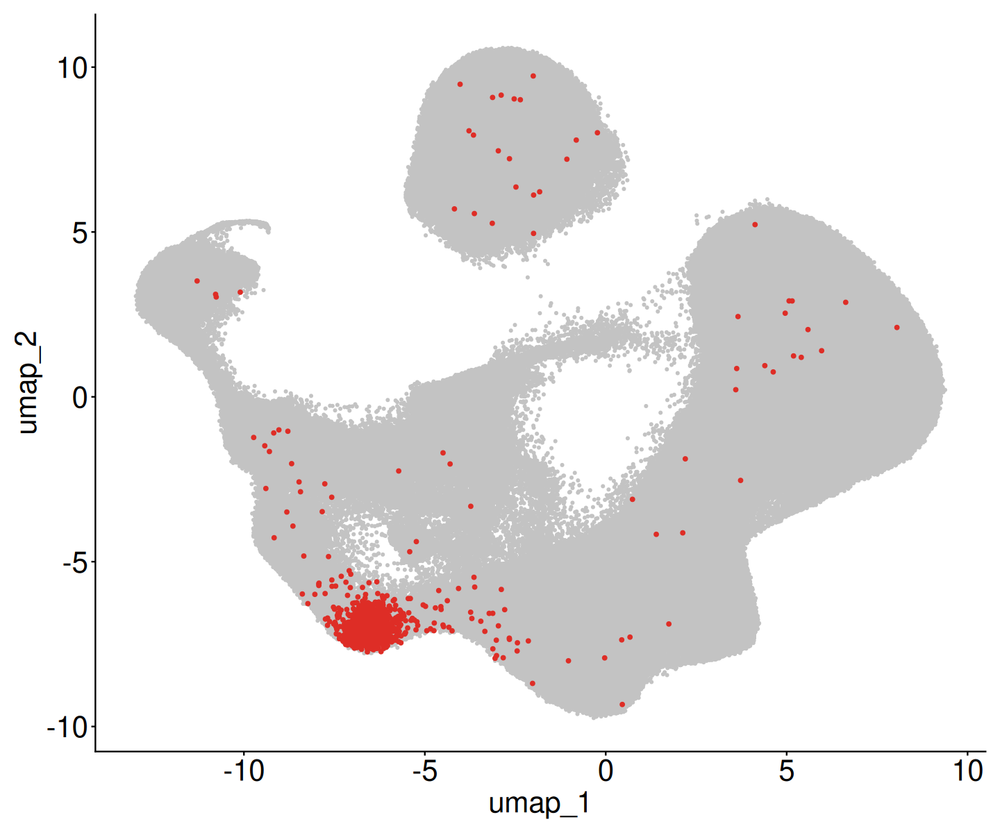

In [42]:
options(repr.plot.width = 12, repr.plot.height = 10)

for(i in c(
"CAVRDSNYQLIW"

)){
  print(DimPlot(blood_5p, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(blood_5p)[grep(blood_5p$cdr3_A1, pattern = i)]) + 
    NoLegend() + theme(axis.text = element_text(size = 25), title = element_text(size = 25)))
   #ggsave(create.dir = TRUE, paste0("../figures/tcr/cd8_tcr/mait_sequences_cd8/",i,".png"), width = 18, height = 18, units = "cm")
}

In [ ]:
### MAIT rearrangement

blood_5p$mait  <- ifelse(blood_5p$v_gene_A1 == "TRAV1-2" & blood_5p$j_gene_A1 == "TRAJ33","TRAV1-2-TRAJ33","Other")

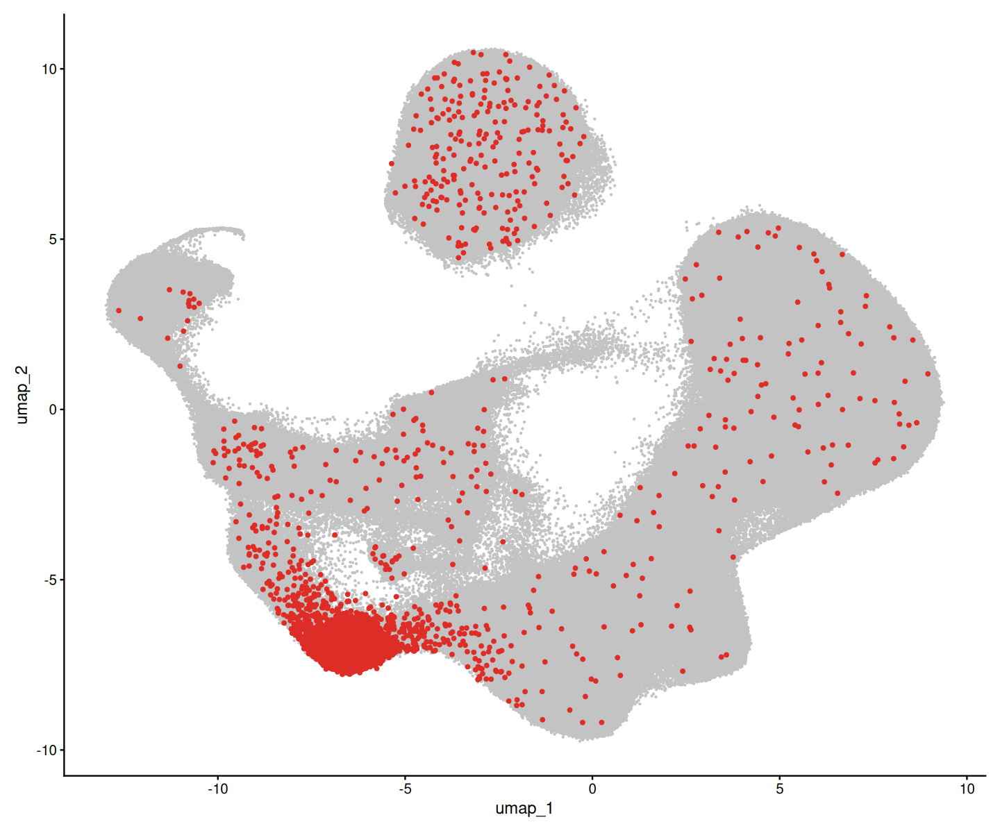

In [29]:
options(repr.plot.width = 12, repr.plot.height = 10)
DimPlot(blood_5p, raster = F,  
                 cells.highlight = colnames(blood_5p)[grep(blood_5p$mait, pattern = "TRAV1-2-TRAJ33")]) +NoLegend()

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
DimPlot(blood_5p, raster = F,  
                 cells.highlight = colnames(blood_5p)[grep(blood_5p$mait, pattern = "TRAV1-2-TRAJ33")]) +NoLegend()

### CD4 CTL clones

In [ ]:
ls()

In [20]:
metadata_6 <- blood_5p@meta.data  %>% dplyr::filter(cd4_ctl == TRUE)

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b NA CDR3a NA,93,0
CDR3b CASSASGQGIAFF CDR3a CAVSALKAAGNKLTF,4,0
CDR3b CASSQDIVAGGQVLTF CDR3a NA,4,0
CDR3b CASSYSGYEQYF CDR3a CAASAPGNQGGKLIF,4,0
CDR3b CSARLVGVPNEQFF CDR3a CAVISSNDYKLSF,4,0
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,3,0
CDR3b CASSLRVYEQFF CDR3a CALSPYTNAGKSTF,3,0
CDR3b CASSPDEQFF CDR3a CATSLGHGQNFVF,3,0
CDR3b CASSPGTGSGNTEAFF CDR3a CALSDKNAGNKLTF,3,0


In [21]:
clone_table_nona  <- clone_table  %>% 
dplyr::filter(!grepl(clone_aa, pattern = " NA"))

In [110]:
clone_table_nona

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b CASSARSYGDSPLHF CDR3a CATDNYNNNDMRF,842,0
CDR3b CATSAFSNEQFF CDR3a CAETRGADGLTF,211,0
CDR3b CASSLKRGIDTGELFF CDR3a CAGGTYGNKLVF,189,0
CDR3b CASSLARHNSPLHF CDR3a CALSEAETNFGNEKLTF,179,0
CDR3b CASSLMNSYEQYF CDR3a CALSDNFGNEKLTF,121,0
CDR3b CASSQRAGGRSGNTIYF CDR3a CGTEGGDYKLSF,120,0
CDR3b CASSPIYTSGGVWTQYF CDR3a CLVGDMGNNQGGKLIF,117,0
CDR3b CASSIAGTNAYNEQFF CDR3a CAVSDSGFKTIF,113,0
CDR3b CSASNPAGKTGELFF CDR3a CAASRDSNYQLIW,112,0


✔ Created directory: ../figures/tcr/tcr_plots_blood_cd4_ctl.



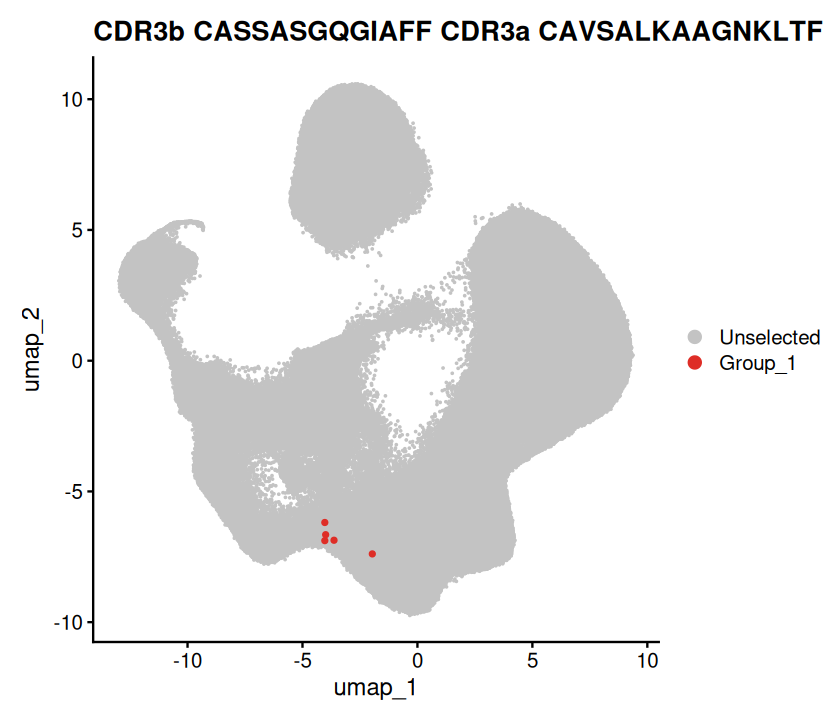

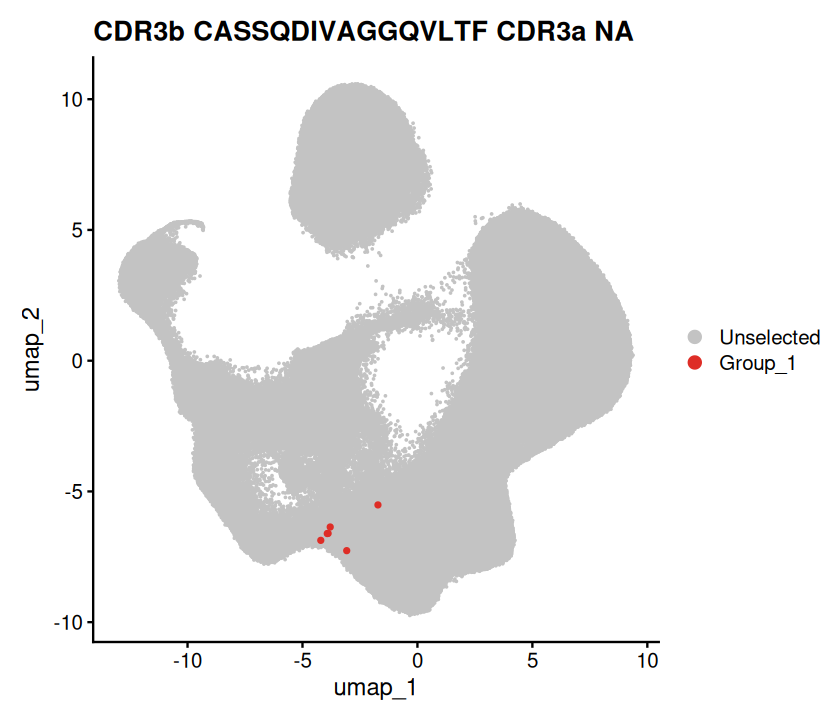

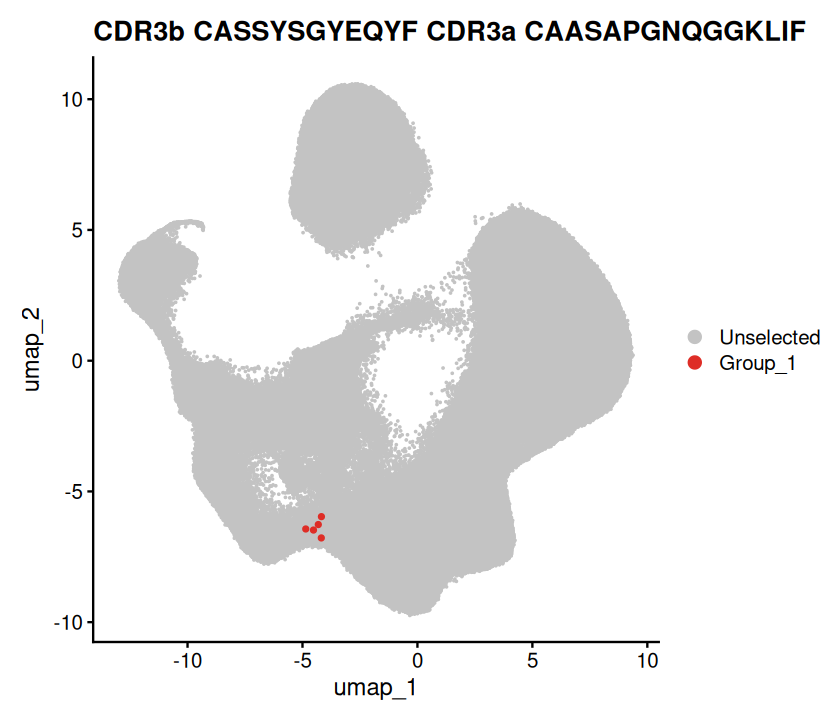

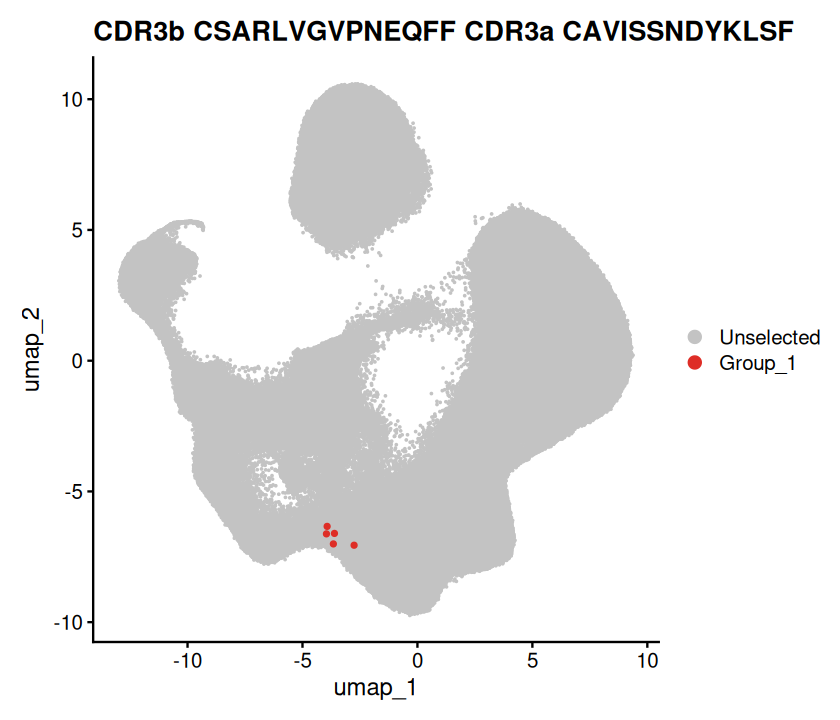

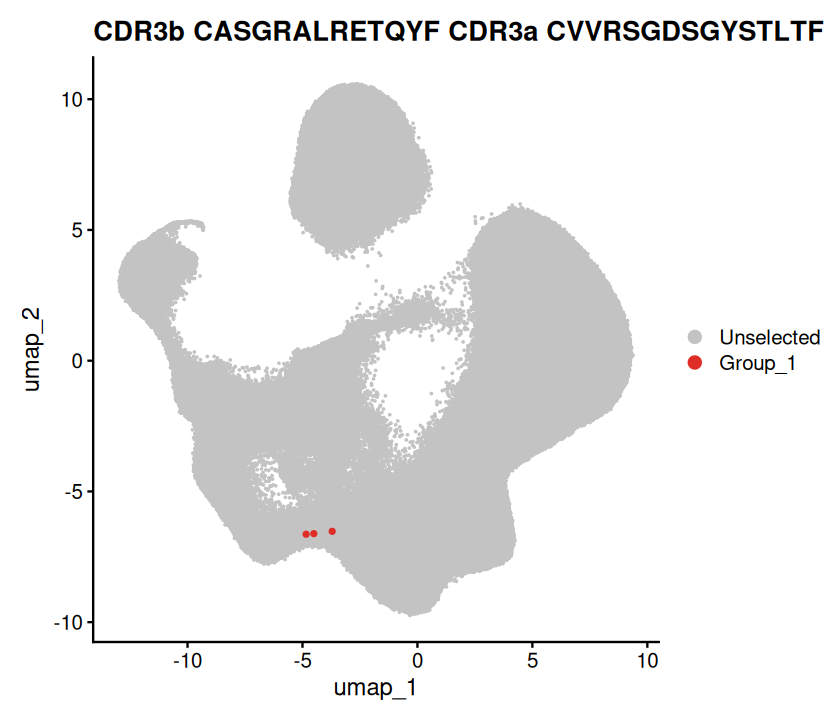

...

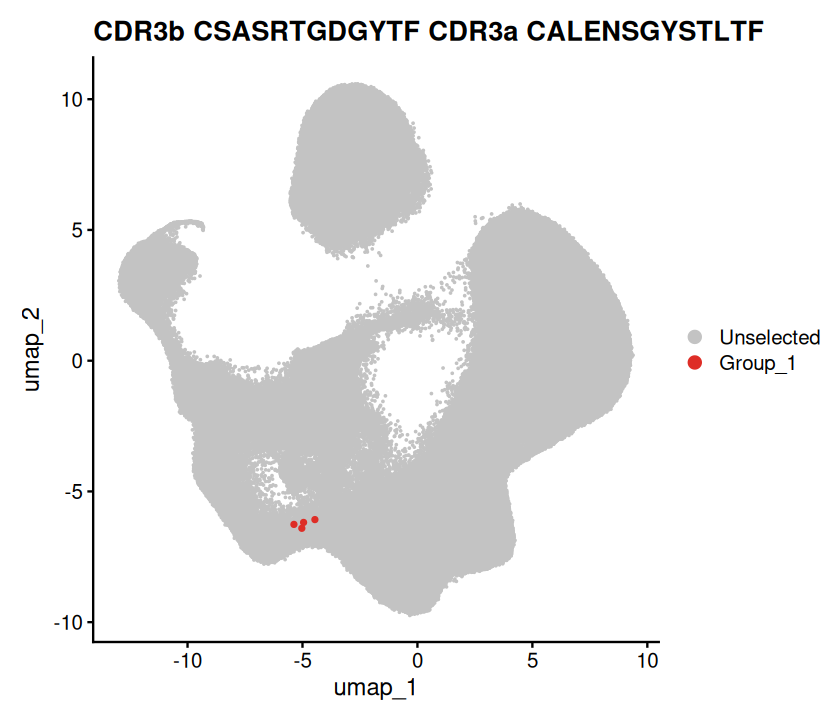

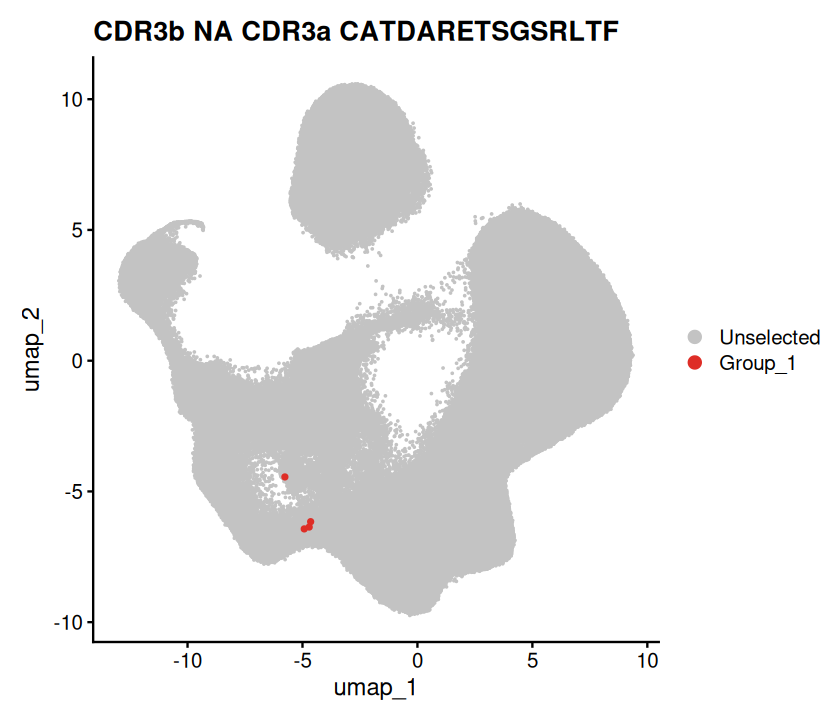

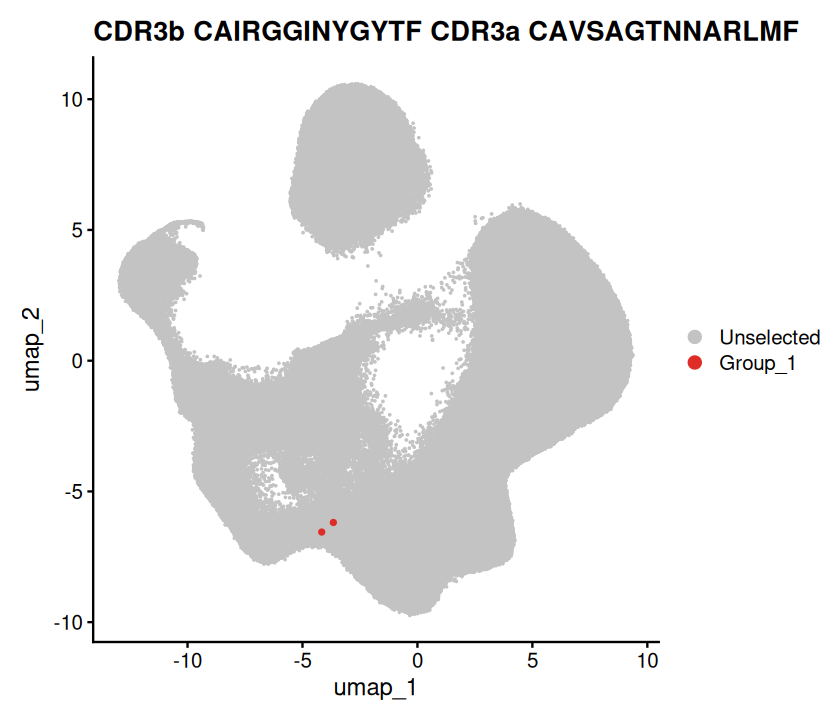

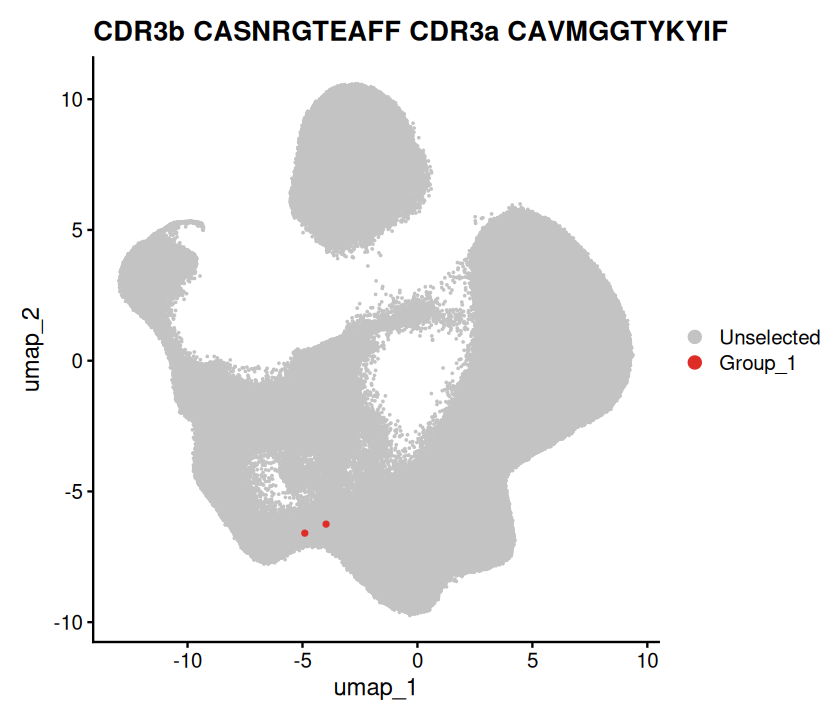

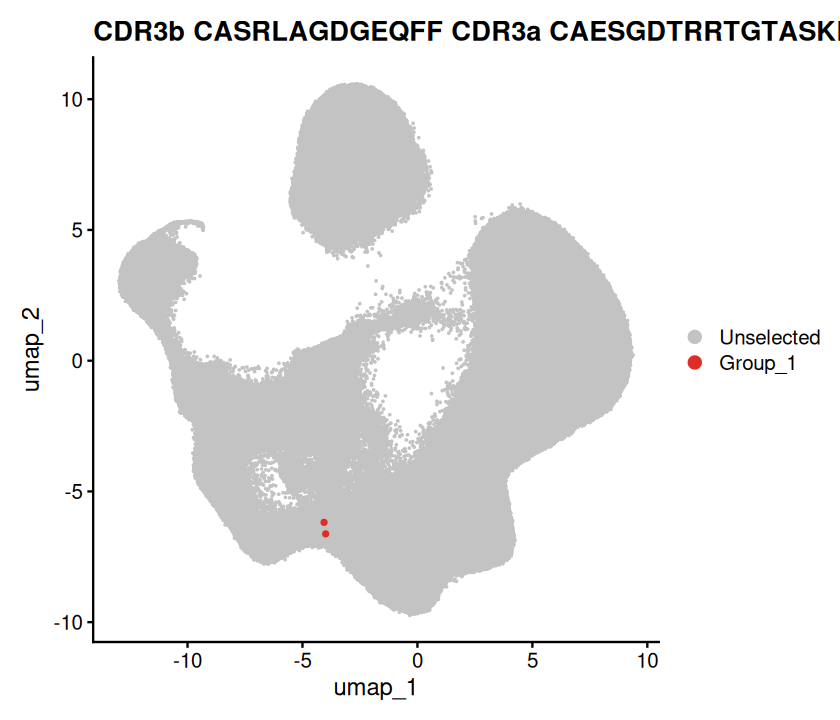

In [33]:
for(i in 2:20){
  print(DimPlot(blood_5p, raster = F, 
          cells.highlight = colnames(blood_5p)[grep(blood_5p$clone_aa, 
                                                       pattern = pull(clone_table, clone_aa)[i])]) +
    ggtitle(pull(clone_table, clone_aa)[i]))
    ggsave(paste0("../figures/tcr/tcr_plots_blood_cd4_ctl/tcr_clone_",i,".png"), 
    create.dir = TRUE, width = 13, height = 10, units = "cm")
}

In [22]:
write.csv(blood_5p@meta.data, "data/metadata/250113_Blood_5p_metadata.csv")

### Are clones CD4 CTL in blood also in gut?

In [22]:
md_tcr_gut  <- read_csv('data/metadata/250121_Gut_5p_metadata.csv')

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [23]:
md_tcr_gut$clone_aa %in% clone_table_nona$clone_aa  %>% table

.
 FALSE   TRUE 
346262    194 

In [24]:
clone_table_nona$clone_in_gut  <- clone_table_nona$clone_aa %in% md_tcr_gut$clone_aa

In [25]:
cd4_clones_in_gut  <- clone_table_nona  %>% arrange(desc(clone_in_gut))  %>% pull(clone_aa)

In [26]:
cd4_clones_in_gut

[1] "CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF"          
   [2] "CDR3b CASSFPPLSLHF CDR3a CAVWGMDSNYQLIW"            
   [3] "CDR3b CASSLGPGTDTQYF CDR3a CALNRPSGNTPLVF"          
   [4] "CDR3b CASSTRASNSPLHF CDR3a CAVSASGTYKYIF"           
   [5] "CDR3b CAISSYLAGGPNEQYF CDR3a CAGQENFNKFYF"          
   [6] "CDR3b CAITGQSSYEQYF CDR3a CVAMEYNFNKFYF"            
   [7] "CDR3b CASATPDGGDTEAFF CDR3a CALSGSGGTSYGKLTF"       
   [8] "CDR3b CASGSTGGGSTEAFF CDR3a CALDNSNSGYALNF"         
   [9] "CDR3b CASHRTGSTGELFF CDR3a CALKADDKIIF"             
  [10] "CDR3b CASKQGISGANVLTF CDR3a CATDGNTGFQKLVF"         
  [11] "CDR3b CASQQGENTGELFF CDR3a CAVIRYSSASKIIF"          
  [12] "CDR3b CASRDRGAGGYNEQFF CDR3a CALGSGGGADGLTF"        
  [13] "CDR3b CASRLAGGPYNEQFF CDR3a CAGSNNARLMF"            
  [14] "CDR3b CASRNTGASTEAFF CDR3a CATEASGNTPLVF"           
  [15] "CDR3b CASRNYNEQFF CDR3a CAVSDNEKLTF"                
  [16] "CDR3b CASRPERTWNEQFF CDR3a CAMREGRDNQGGKLIF"        
  [17] "CDR3b CASRSGVGGDQETQYF CDR3a CLVGTKAAGNKLTF"        
  [18] "CDR3b CASRSRTPGYTEAFF CDR3a CAVTEVSNDYKLSF"         
  [19] "CDR3b CASRTRDTDTQYF CDR3a CAGRNRGSSNTGKLIF"         
  [20] "CDR3b CASSAGGTGTGELFF CDR3a CAVTPIGAGTALIF"         
  [21] "CDR3b CASSDDRVPYEQYF CDR3a CAVSVRRGSTLGRLYF"        
  [22] "CDR3b CASSDRRNTEAFF CDR3a CAVVLPSGTYKYIF"           
  [23] "CDR3b CASSEGGLAVTKNIQYF CDR3a CAASGGSYNQGGKLIF"     
  [24] "CDR3b CASSEQTSGGTDTQYF CDR3a CAVSANAGNMLTF"         
  [25] "CDR3b CASSERGLAAFF CDR3a CAFFGNEKLTF"               
  [26] "CDR3b CASSETGDGNTIYF CDR3a CAEIESFQKLVF"            
  [27] "CDR3b CASSEVGGRQPQHF CDR3a CAGYYNAGNNRKLIW"         
  [28] "CDR3b CASSFGAKYNSPLHF CDR3a CAVKGGFQKLVF"           
  [29] "CDR3b CASSFYQGTEAFF CDR3a CATDAGYGGATNKLIF"         
  [30] "CDR3b CASSGLGSAFF CDR3a CVVNFPGGSARQLTF"            
  [31] "CDR3b CASSIIRESQPQHF CDR3a CAVSDGTGNQFYF"           
  [32] "CDR3b CASSIQGARTDQPQHF CDR3a CATDTGRRALTF"          
  [33] "CDR3b CASSITGTANYGYTF CDR3a CAGGSTDKLIF"            
  [34] "CDR3b CASSLALAEAYEQYF CDR3a CAVGPPAQKLVF"           
  [35] "CDR3b CASSLDRAGANVLTF CDR3a CAATAKAAGNKLTF"         
  [36] "CDR3b CASSLEFTDTEAFF CDR3a CAANPSGYSTLTF"           
  [37] "CDR3b CASSLGGQKNQPQHF CDR3a CAVSDRSGGSNYKLTF"       
  [38] "CDR3b CASSLGVGGLESDTQYF CDR3a CAVRRVGDKIIF"         
  [39] "CDR3b CASSLRGGIQNSPLHF CDR3a CAVLGTSGSRLTF"         
  [40] "CDR3b CASSLSGRGGADTQYF CDR3a CLVGPRNSGAGSYQLTF"     
  [41] "CDR3b CASSLTGSRPQHF CDR3a CAVIGSLGAGGTSYGKLTF"      
  [42] "CDR3b CASSPAGGRGTQYF CDR3a CAVQAGSNYQLIW"           
  [43] "CDR3b CASSPGTGNYGYTF CDR3a CAVTPEPYSGAGSYQLTF"      
  [44] "CDR3b CASSPGTTSTDTQYF CDR3a CALGGFNDYKLSF"          
  [45] "CDR3b CASSPQNEQFF CDR3a CAASDTGRRALTF"              
  [46] "CDR3b CASSPRLAQETQYF CDR3a CATPGGGATNKLIF"          
  [47] "CDR3b CASSPSAGGLGTQYF CDR3a CAMSGGGSFGNVLHC"        
  [48] "CDR3b CASSPWGGPTDTQYF CDR3a CAGRYGGATNKLIF"         
  [49] "CDR3b CASSPWNGDEQYF CDR3a CAVEVDGGSQGNLIF"          
  [50] "CDR3b CASSQALNTEAFF CDR3a CAVSEGGTSYGKLTF"          
  [51] "CDR3b CASSQDQRVIWGTQYF CDR3a CAAPIQGAQKLVF"         
  [52] "CDR3b CASSQDSSLAKNIQYF CDR3a CALNTGTASKLTF"         
  [53] "CDR3b CASSQEGYTTDTQYF CDR3a CLVGDGGGGADGLTF"        
  [54] "CDR3b CASSQERNQPQHF CDR3a CLLAVFNFGNEKLTF"          
  [55] "CDR3b CASSQETGANYGYTF CDR3a CAMSDGGFKTIF"           
  [56] "CDR3b CASSQETGSDTQYF CDR3a CAVSETGFQKLVF"           
  [57] "CDR3b CASSQGGLDPRTYEQYF CDR3a CAVGVRNSGGSNYKLTF"    
  [58] "CDR3b CASSQSETGDDGELFF CDR3a CAASSPNTGNQFYF"        
  [59] "CDR3b CASSQTDRAPYGYTF CDR3a CAGFGAGSYQLTF"          
  [60] "CDR3b CASSQVGDRNSPLHF CDR3a CALNAGAGKSTF"           
  [61] "CDR3b CASSRTGGNYGYTF CDR3a CAVIMSPEGAGSYQLTF"       
  [62] "CDR3b CASSRTSGTYEQYF CDR3a CALSDPVQAGTALIF"         
  [63] "CDR3b CASSSLGQGNYGYTF CDR3a CAMRPPSGTYKYIF"         
  [64] "CDR3b CASSSPSGGFINYEQYF CDR3a CAAFNYNQGGKLIF"       
  [65] "CDR3b CASSSQGAVGYEQYF CDR3a CAASEIYNQGGKLIF"        
  [66] "CDR3b CASSSSGGTDTQYF CDR3a CAV

In [27]:
gut_5p  <- readRDS("data/cdn/gut_5p_integrated_cd4_prolif_filt.rds")

In [28]:
gut_5p@meta.data  %>% dplyr::filter(clone_aa %in% cd4_clones_in_gut[2:20])

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,j_gene_A2,v_gene_B,d_gene_B,j_gene_B,v_gene_Multi,d_gene_Multi,j_gene_Multi,clone_nt,clone_aa,annotations
,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<fct>
GTATTCTGTGCGAAAC-1_1270993_1_1_1,SeuratProject,3461.470,4347,GTATTCTGTGCGAAAC-1_1270993_1_1_1,1270993_1_1_1,1270993_1_1_1,001-026_T0_COL_LP_5p_N1,CD,ileocolonic,non-stricturing|non-penetrating,⋯,NA,TRBV6-6,NA,TRBJ1-1,NA,NA,NA,TGTGCCAGCGCTACACCAGACGGGGGCGACACTGAAGCTTTCTTT TGTGCTCTGAGTGGCTCTGGTGGTACTAGCTATGGAAAGCTGACATTT NA,CDR3b CASATPDGGDTEAFF CDR3a CALSGSGGTSYGKLTF,CTL
GAGCAGAAGTATGACA-1_1193621_1_1_1,SeuratProject,2556.680,1944,GAGCAGAAGTATGACA-1_1193621_1_1_1,1193621_1_1_1,1193621_1_1_1,001-033_T0_COL_LP_5p_N1,FGID,FAP,Unknown,⋯,NA,TRBV7-2,NA,TRBJ2-3,NA,NA,NA,TGTGCCAGCAGAACTAGAGACACAGATACGCAGTATTTT TGTGCAGGGCGGAATCGGGGCTCTAGCAACACAGGCAAACTAATCTTT NA,CDR3b CASRTRDTDTQYF CDR3a CAGRNRGSSNTGKLIF,Th1
GTTCATTTCACTTACT-1_1193621_1_1_1,SeuratProject,2783.731,2108,GTTCATTTCACTTACT-1_1193621_1_1_1,1193621_1_1_1,1193621_1_1_1,001-033_T0_COL_LP_5p_N1,FGID,FAP,Unknown,⋯,NA,TRBV7-2,NA,TRBJ2-3,NA,NA,NA,TGTGCCAGCAGAACTAGAGACACAGATACGCAGTATTTT TGTGCAGGGCGGAATCGGGGCTCTAGCAACACAGGCAAACTAATCTTT NA,CDR3b CASRTRDTDTQYF CDR3a CAGRNRGSSNTGKLIF,CTL
ATCCACCCACATTAGC-1_1271007_1_1_1,SeuratProject,2259.110,1145,ATCCACCCACATTAGC-1_1271007_1_1_1,1271007_1_1_1,1271007_1_1_1,001-041_R_ILE_LP_5p_N1,CD,ileocolonic,non-stricturing|non-penetrating,⋯,NA,TRBV6-5,TRBD2,TRBJ2-1,NA,NA,NA,TGTGCCAGCAGACTAGCGGGAGGGCCCTACAATGAGCAGTTCTTC TGTGCAGGGAGTAACAATGCCAGACTCATGTTT NA,CDR3b CASRLAGGPYNEQFF CDR3a CAGSNNARLMF,CTL
ATTGGTGCACATGACT-1_1271010_1_1_1,SeuratProject,1793.273,834,ATTGGTGCACATGACT-1_1271010_1_1_1,1271010_1_1_1,1271010_1_1_1,001-041_R_COL_LP_5p_N1,CD,ileocolonic,non-stricturing|non-penetrating,⋯,NA,TRBV6-5,TRBD2,TRBJ2-1,NA,NA,NA,TGTGCCAGCAGACTAGCGGGAGGGCCCTACAATGAGCAGTTCTTC TGTGCAGGGAGTAACAATGCCAGACTCATGTTT NA,CDR3b CASRLAGGPYNEQFF CDR3a CAGSNNARLMF,Th1
TACTTACCATGACGGA-1_1271033_1_1_1,SeuratProject,2241.103,1441,TACTTACCATGACGGA-1_1271033_1_1_1,1271033_1_1_1,1271033_1_1_1,001-058_R_DUO_LP_5p_N1,CD,ileal,non-stricturing|non-penetrating,⋯,NA,TRBV6-1,NA,TRBJ2-5,NA,NA,NA,TGTGCCAGCAGGTCGGGGGTGGGAGGGGACCAAGAGACCCAGTACTTC TGCCTCGTGGGTACCAAAGCTGCAGGCAACAAGCTAACTTTT NA,CDR3b CASRSGVGGDQETQYF CDR3a CLVGTKAAGNKLTF,Th1
ATAAGAGGTGACGCCT-1_1271057_1_1_1,SeuratProject,2339.119,1394,ATAAGAGGTGACGCCT-1_1271057_1_1_1,1271057_1_1_1,1271057_1_1_1,001-074_T0_COL_LP_5p_N1,CD,ileocolonic,non-stricturing|non-penetrating,⋯,NA,TRBV12-3,NA,TRBJ2-3,NA,NA,NA,TGTGCCAGCAGTTTAGGTCCCGGCACAGATACGCAGTATTTT TGTGCTCTCAACCGACCTTCAGGAAACACACCTCTTGTCTTT NA,CDR3b CASSLGPGTDTQYF CDR3a CALNRPSGNTPLVF,CTL
TCAGCAAGTTGACGTT-1_1271074_1_1_1,SeuratProject,3416.284,4716,TCAGCAAGTTGACGTT-1_1271074_1_1_1,1271074_1_1_1,1271074_1_1_1,001-082_T0_COL_LP_5p_N1,CD,ileocolonic,non-stricturing|non-penetrating,⋯,NA,TRBV7-2,NA,TRBJ2-1,NA,NA,NA,TGTGCCAGCAGGAACTACAATGAGCAGTTCTTC TGTGCTGTGAGTGATAATGAGAAATTAACCTTT NA,CDR3b CASRNYNEQFF CDR3a CAVSDNEKLTF,CTL
CACAGGCAGGCAAAGA-1_1271110_1_1_1,SeuratProject,1861.494,865,CACAGGCAGGCAAAGA-1_1271110_1_1_1,1271110_1_1_1,1271110_1_1_1,001-094_T0_ILE_LP_5p_N1,CD,ileocolonic,stricturing,⋯,NA,TRBV10-3,NA,TRBJ2-7,NA,NA,NA,TGTGCCATCAGTAGTTACCTAGCGGGGGGGCCGAACGAGCAGTACTTC TGTGCAGGGCAGGAAAACTTCAACAAATTTTACTTT NA,CDR3b CAISSYLAGGPNEQYF CDR3a CAGQENFNKFYF,CTL


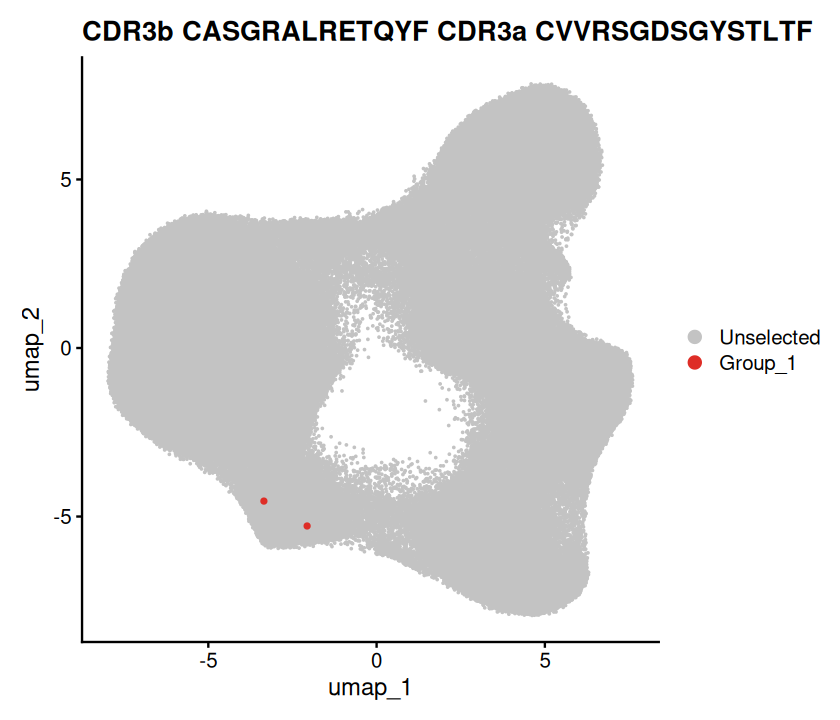

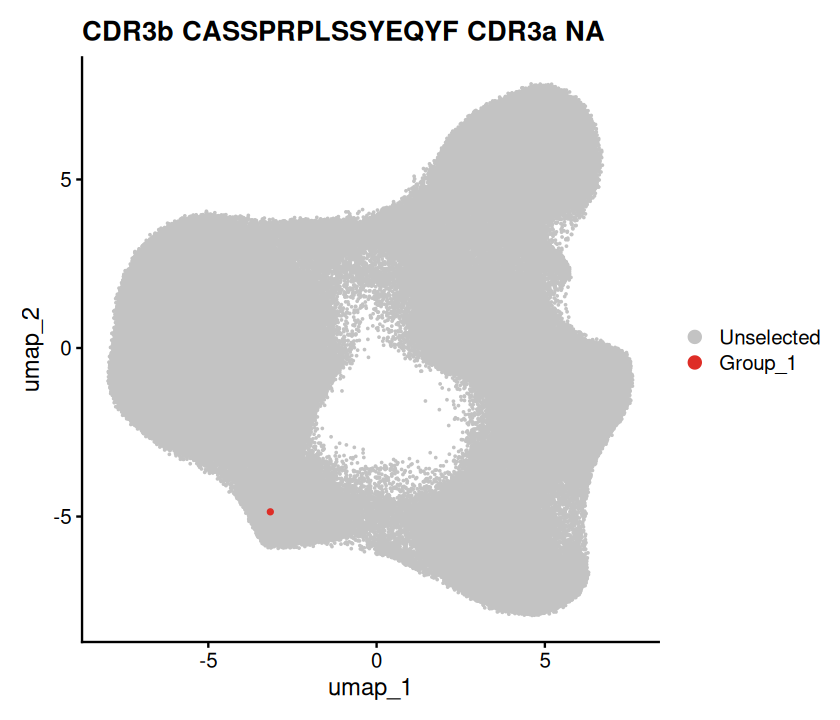

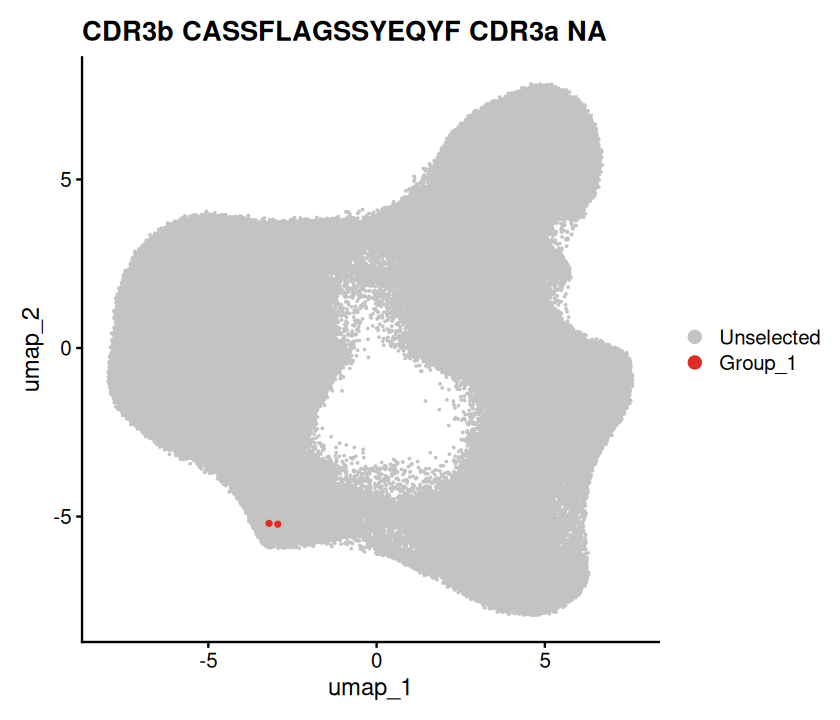

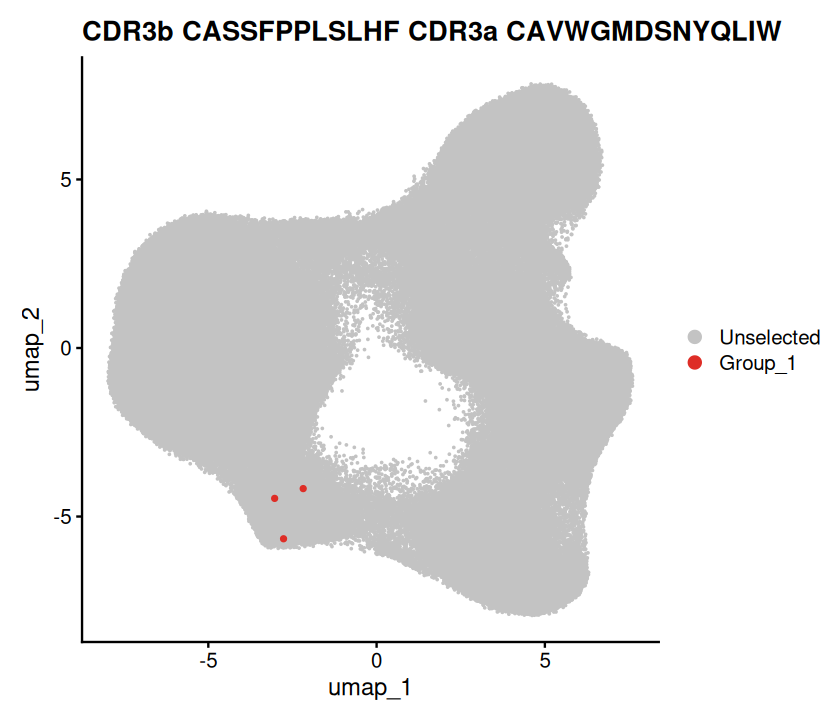

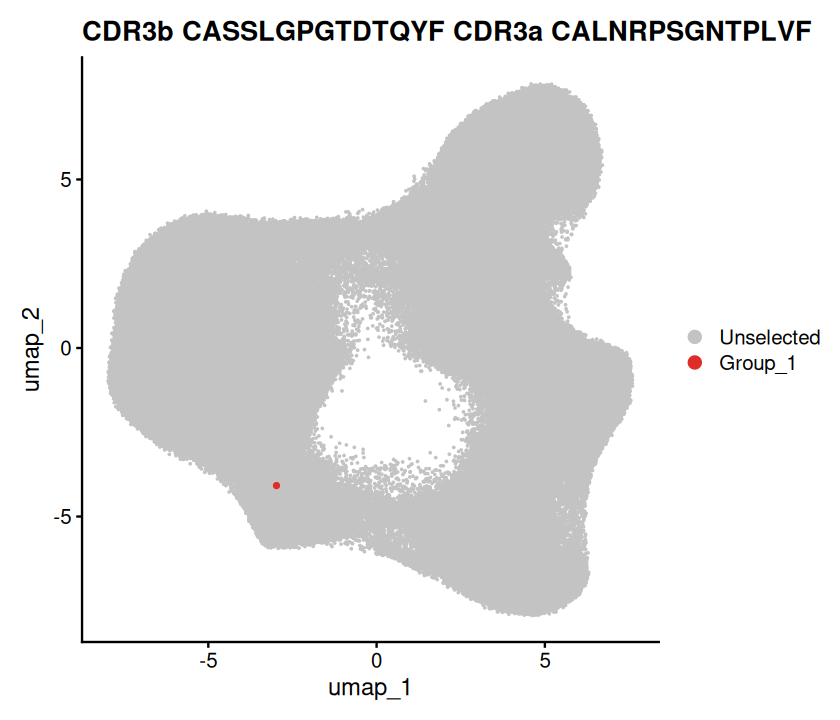

...

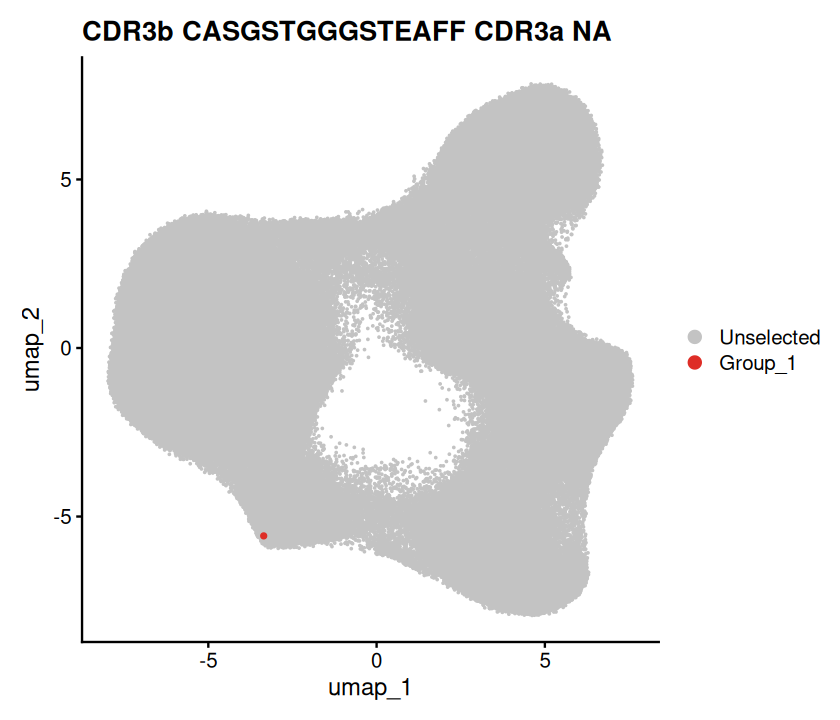

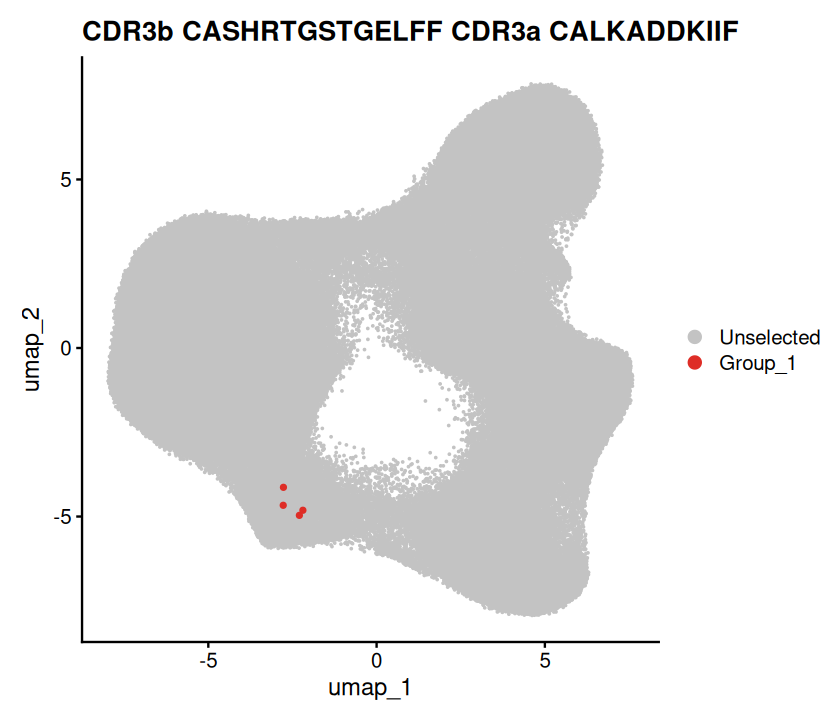

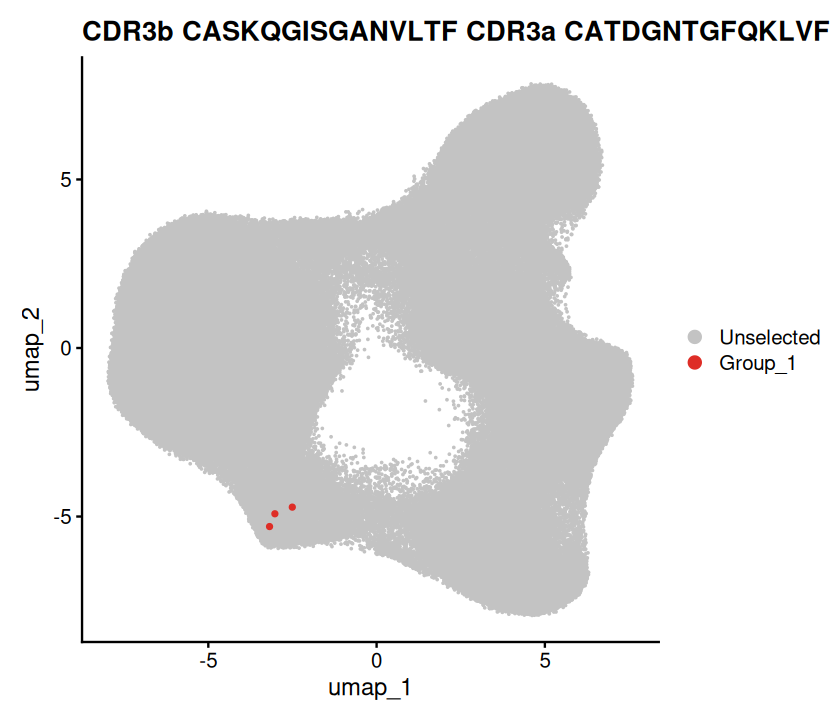

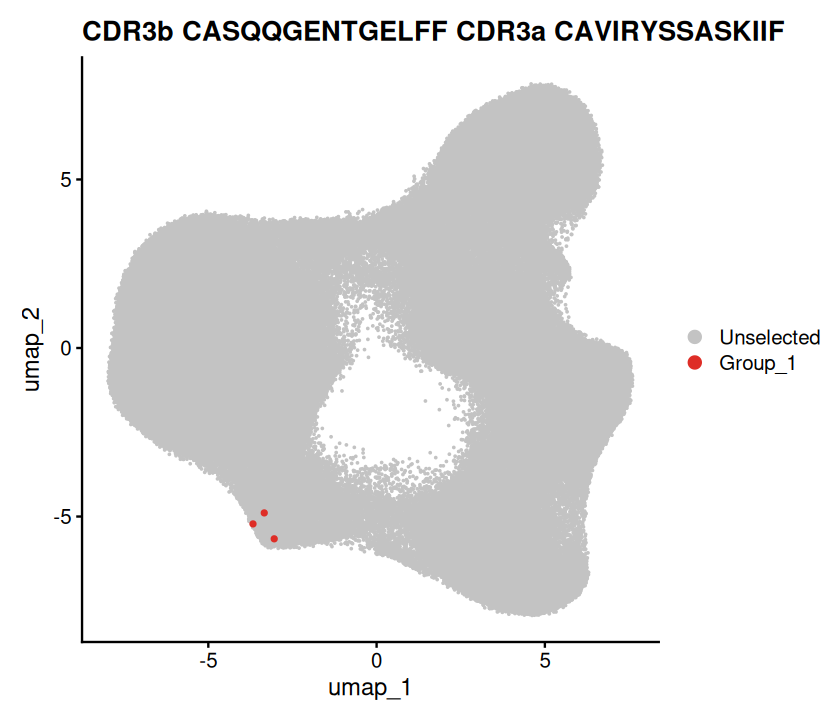

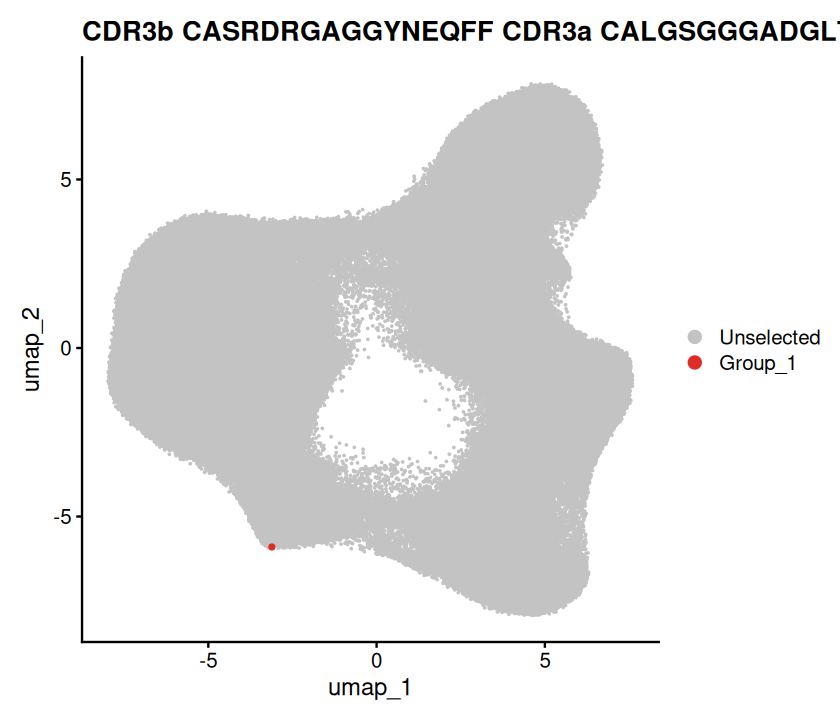

In [60]:
for(i in 2:20){
  print(DimPlot(gut_5p, raster = F, 
          cells.highlight = colnames(gut_5p)[grep(gut_5p$clone_aa, 
                                                       pattern = cd4_clones_in_gut[i])]) +
    ggtitle(cd4_clones_in_gut[i]))
    ggsave(paste0("../figures/tcr/tcr_plots_blood_and_gut_cd4_ctl/tcr_clone_",i,".png"), 
    create.dir = TRUE, width = 13, height = 10, units = "cm")
}

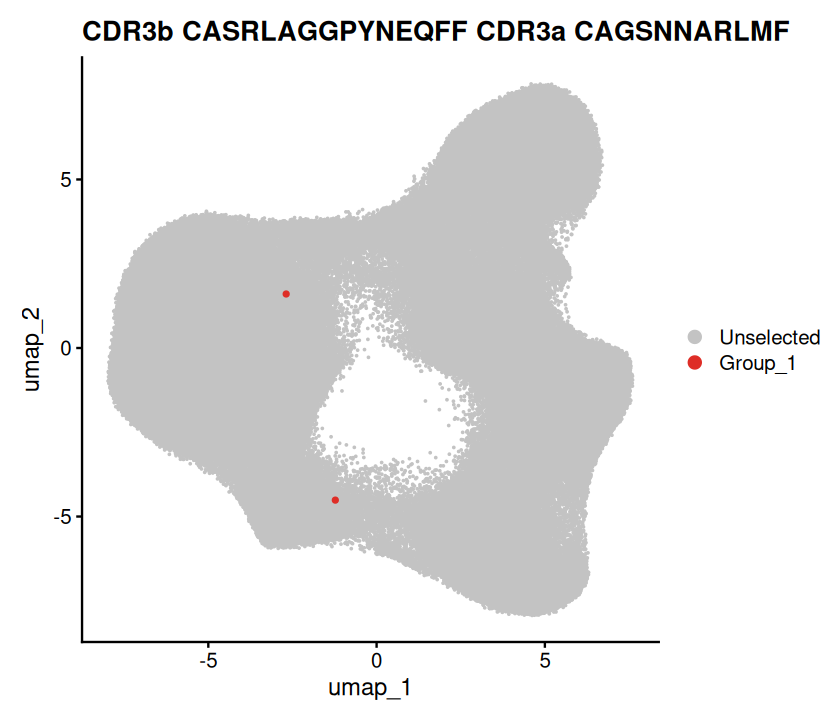

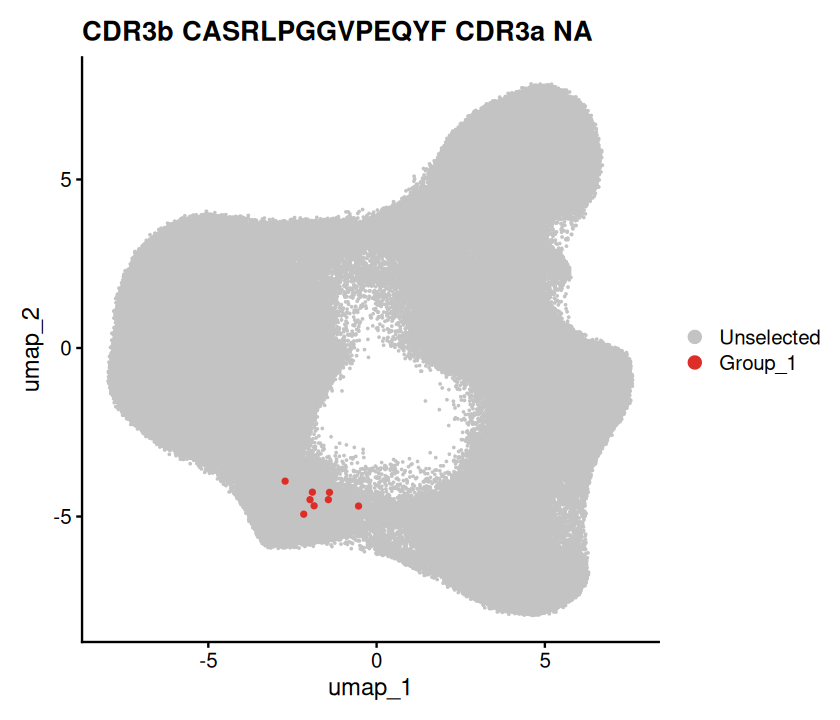

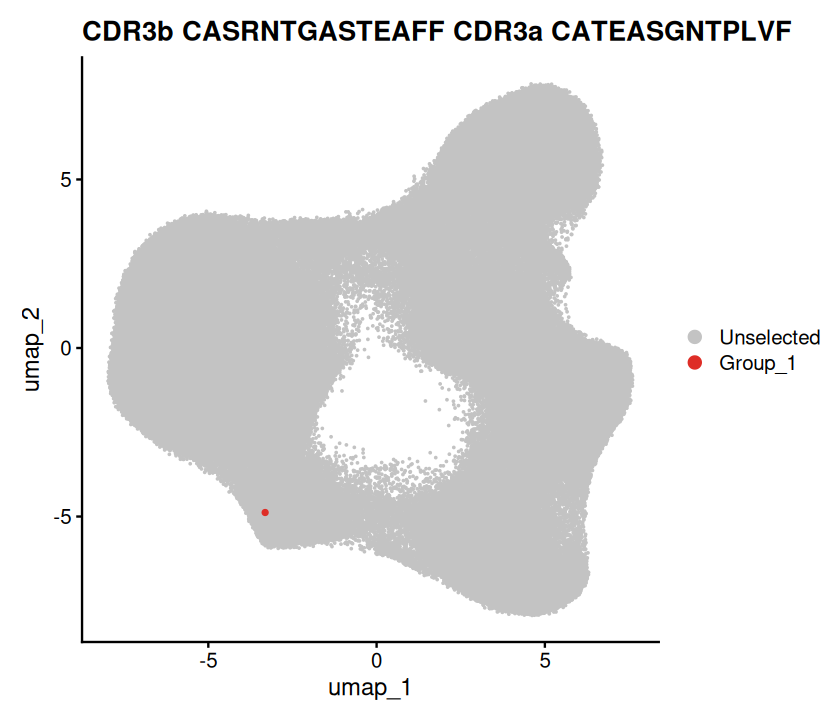

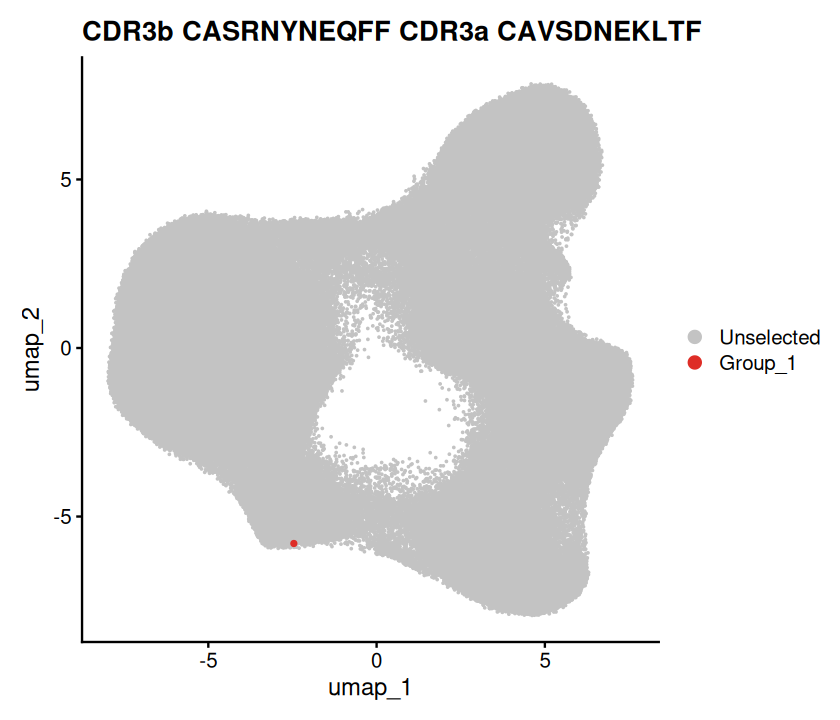

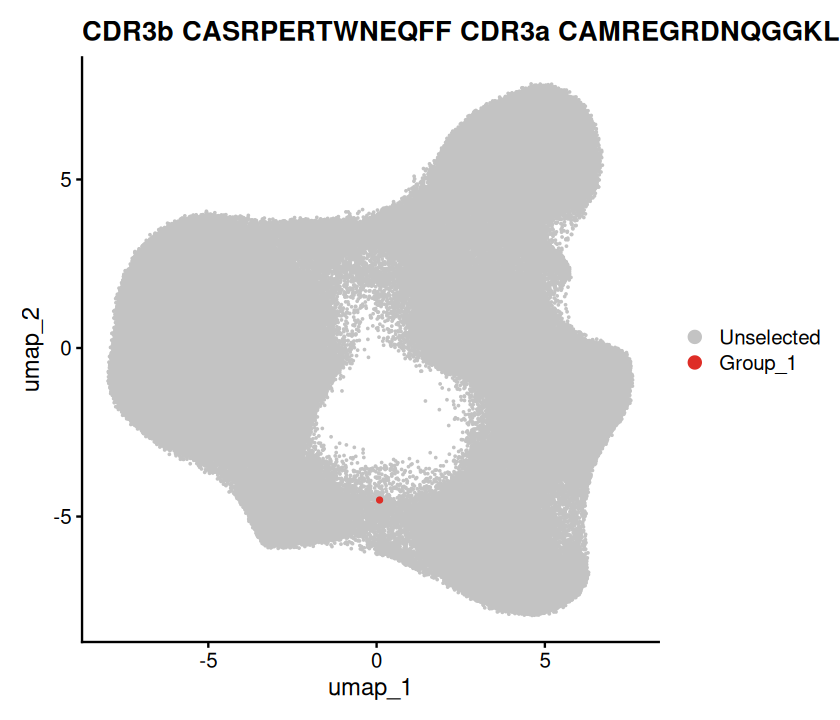

...

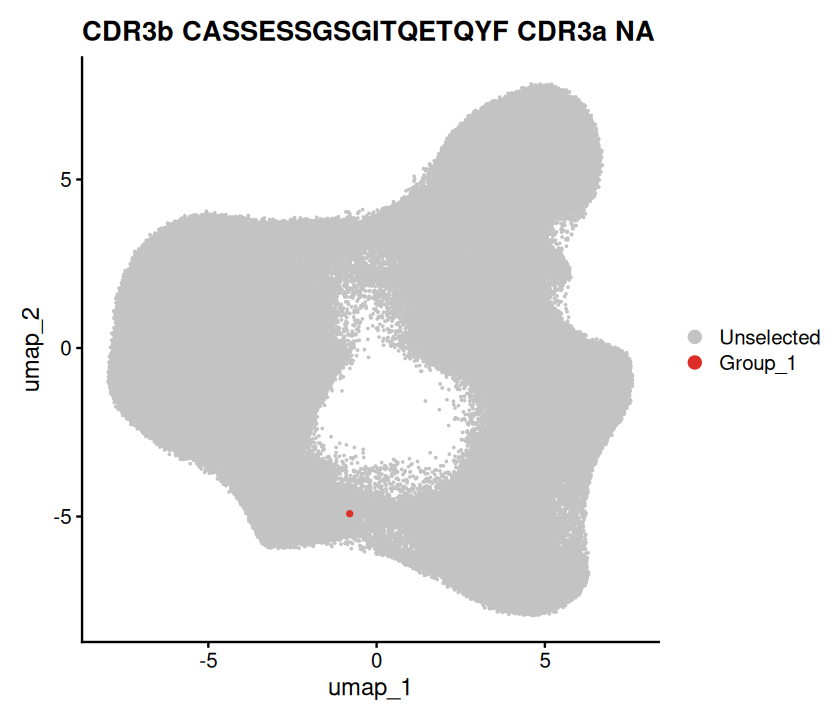

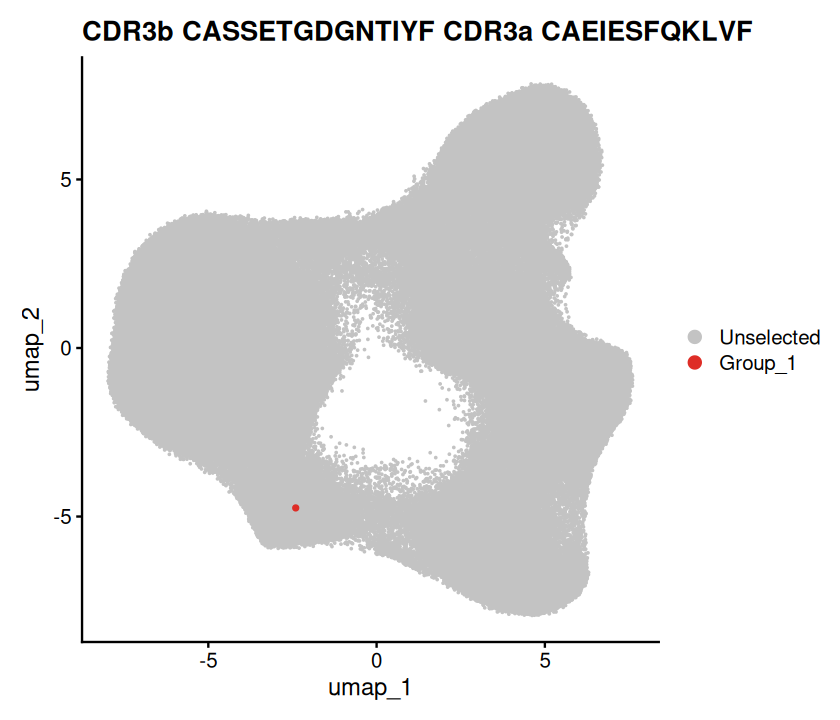

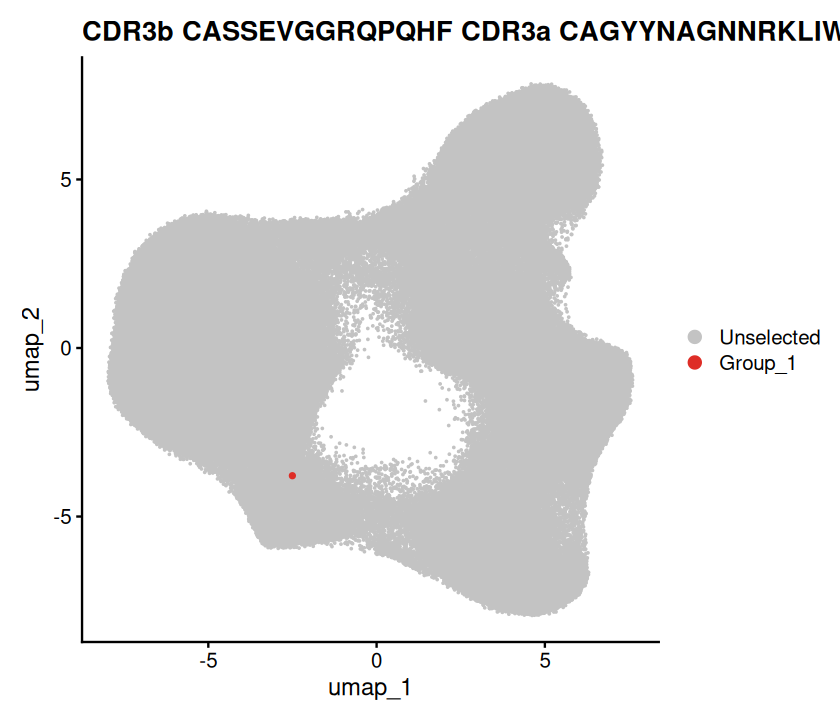

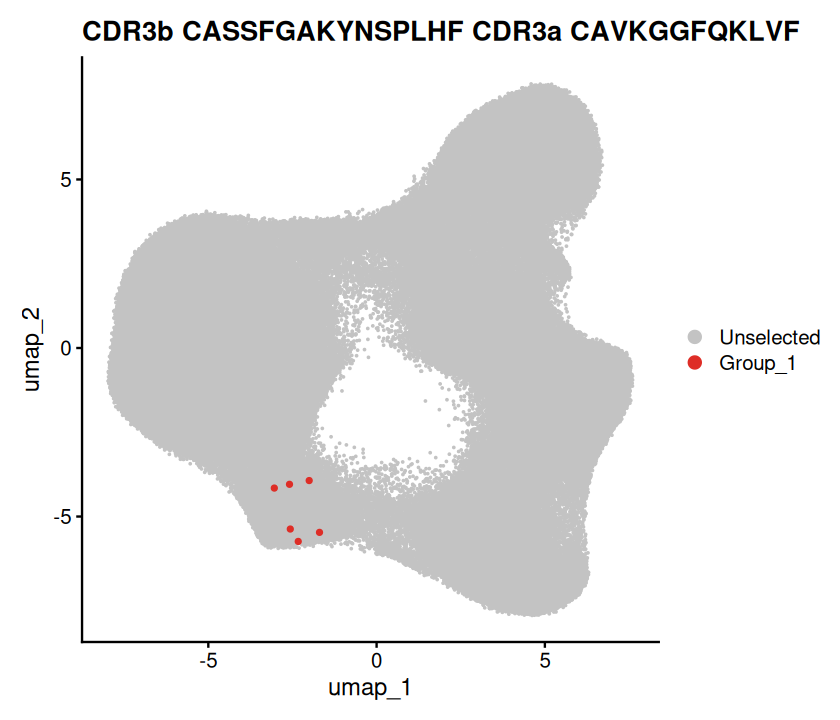

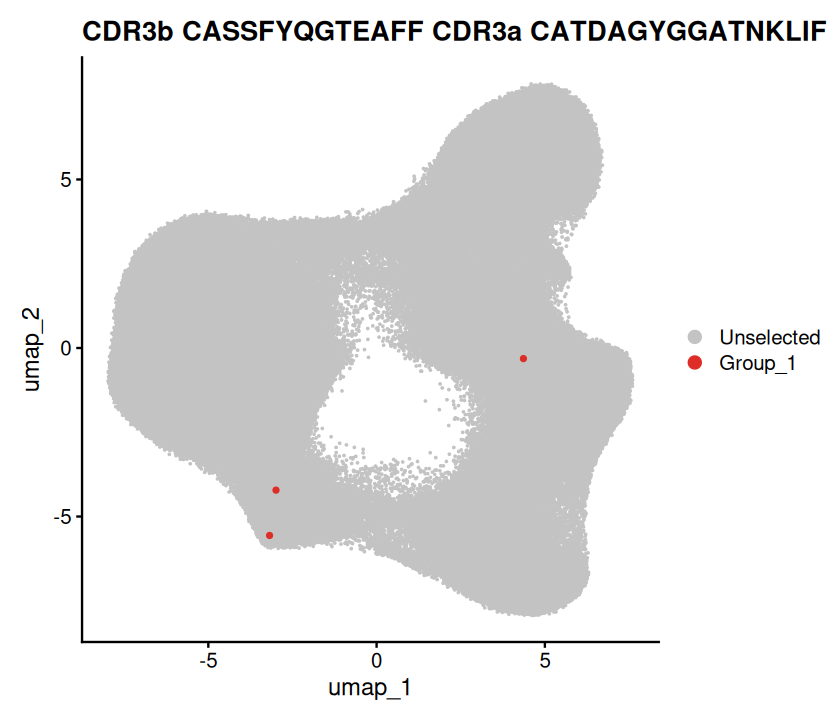

In [61]:
for(i in 21:40){
  print(DimPlot(gut_5p, raster = F, 
          cells.highlight = colnames(gut_5p)[grep(gut_5p$clone_aa, 
                                                       pattern = cd4_clones_in_gut[i])]) +
    ggtitle(cd4_clones_in_gut[i]))
    ggsave(paste0("../figures/tcr/tcr_plots_blood_and_gut_cd4_ctl/tcr_clone_",i,".png"), 
    create.dir = TRUE, width = 13, height = 10, units = "cm")
}

In [29]:
clone_table  %>% dplyr::filter(!grepl(clone_aa, pattern =  " NA"))

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b CASSASGQGIAFF CDR3a CAVSALKAAGNKLTF,4,0
CDR3b CASSYSGYEQYF CDR3a CAASAPGNQGGKLIF,4,0
CDR3b CSARLVGVPNEQFF CDR3a CAVISSNDYKLSF,4,0
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,3,0
CDR3b CASSLRVYEQFF CDR3a CALSPYTNAGKSTF,3,0
CDR3b CASSPDEQFF CDR3a CATSLGHGQNFVF,3,0
CDR3b CASSPGTGSGNTEAFF CDR3a CALSDKNAGNKLTF,3,0
CDR3b CASSPPSGSDTEAFF CDR3a CAVSRGAGGTSYGKLTF,3,0
CDR3b CASSSGRTAQETQYF CDR3a CAVNARGNNRLAF,3,0


In [30]:
clone_table_nona  %>% dplyr::filter(!grepl(clone_aa, pattern =  " NA") &
                                                       clone_in_gut == TRUE) 

clone_aa,n,sum,clone_in_gut
<chr>,<int>,<int>,<lgl>
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,3,0,TRUE
CDR3b CASSFPPLSLHF CDR3a CAVWGMDSNYQLIW,2,0,TRUE
CDR3b CASSLGPGTDTQYF CDR3a CALNRPSGNTPLVF,2,0,TRUE
CDR3b CASSTRASNSPLHF CDR3a CAVSASGTYKYIF,2,0,TRUE
CDR3b CAISSYLAGGPNEQYF CDR3a CAGQENFNKFYF,1,0,TRUE
CDR3b CAITGQSSYEQYF CDR3a CVAMEYNFNKFYF,1,0,TRUE
CDR3b CASATPDGGDTEAFF CDR3a CALSGSGGTSYGKLTF,1,0,TRUE
CDR3b CASGSTGGGSTEAFF CDR3a CALDNSNSGYALNF,1,0,TRUE
CDR3b CASHRTGSTGELFF CDR3a CALKADDKIIF,1,0,TRUE


In [31]:
shared_clones_no_na  <- clone_table_nona  %>% dplyr::filter(!grepl(clone_aa, pattern = " NA") &
                                                       clone_in_gut == TRUE)  %>% pull(clone_aa)

In [32]:
gut_5p@meta.data  %>% dplyr::filter(clone_aa %in% shared_clones_no_na)  %>% group_by(annotations)  %>% tally()  %>% 
mutate(freq = n / sum(n))

annotations,n,freq
<fct>,<int>,<dbl>
Th1,7,0.03608247
Treg activated,3,0.01546392
Th17_1,6,0.03092784
Th2,3,0.01546392
Treg naive,3,0.01546392
CTL,158,0.81443299
Tfh,3,0.01546392
Naive_2,3,0.01546392
Th17_2,8,0.04123711


In [33]:
gut_5p@meta.data  %>% dplyr::filter(clone_aa %in% shared_clones_no_na)  %>% group_by(diagnosis)  %>% tally()  %>% 
mutate(freq = n / sum(n))

diagnosis,n,freq
<chr>,<int>,<dbl>
CD,171,0.88144330
FGID,5,0.02577320
UC,14,0.07216495
Unknown,4,0.02061856


In [34]:
blood_5p$annotations  %>% table

.
          CD8_Naive           CD4_Naive  CD4_Central_Memory        CD4_Teff_Th2 
             106441              196865               57801               62393 
     CD4_Treg_Naive  CD4_Treg_Activated  CD8_Central_Memory CD8_Effector_Memory 
              17024               12014               27184               39620 
           NK_cells             CD8_Tgd   CD4_Teff_Th1/Th17              ISAGhi 
              22902               25271               17326                4840 
      Proliferating 
               3893 

In [35]:
gut_5p$annotations  %>% table

.
           Th1        Naive_1 Treg activated         Th17_1            Tcm 
         54392          51934          47505          44199          38339 
           Th2     Treg naive            CTL            Tfh        Naive_2 
         31992          19573          18771          17587          11276 
        Th17_2 
         10888 

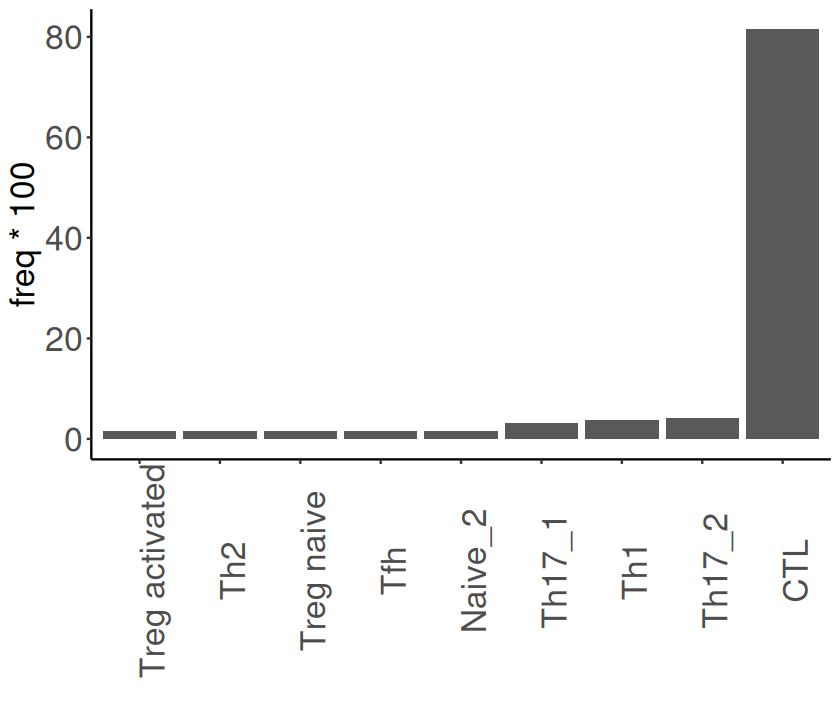

In [37]:
options(repr.plot.width = 7, repr.plot.height = 6)
gut_5p@meta.data  %>% dplyr::filter(clone_aa %in% shared_clones_no_na)  %>% group_by(annotations)  %>% tally()  %>% 
mutate(freq = n / sum(n))  %>% 
ggplot(aes(x = reorder(annotations, X = freq, FUN = max), y = freq*100)) + 
theme_classic() +
stat_summary(geom = "bar", fun = mean) +
xlab("") +
ggtheme() +
theme(axis.text.x = element_text(angle = 90))

In [40]:
ggsave("figures/tcr/barplot_gut_clones_in_blood.svg", width = 10, height = 12, units = "cm")

In [ ]:
###

In [134]:
shared_blood_metadata  <- blood_5p@meta.data  %>% 
dplyr::filter(clone_aa %in% shared_clones_no_na & cd4_ctl == TRUE)  %>% 
group_by(participant_id, clone_aa)  %>% 
tally

In [136]:
shared_gut_metadata  <- gut_5p@meta.data  %>% 
dplyr::filter(clone_aa %in% shared_clones_no_na)  %>% 
group_by(participant_id, clone_aa)  %>% 
tally

In [137]:
shared_blood_metadata$tissue = "Blood"
shared_gut_metadata$tissue = "Gut"


In [138]:
shared_md  <- rbind(shared_blood_metadata, shared_gut_metadata)

In [140]:
shared_md$pt_tissue  <- paste(shared_md$participant_id, shared_md$tissue)

In [144]:
shared_md  %>% ungroup  %>% dplyr::select(pt_tissue, clone_aa, n)  %>% 
pivot_wider(names_from = pt_tissue, values_from = n, values_fill = 0)

clone_aa,001-018 Blood,001-023 Blood,001-026 Blood,001-030 Blood,001-031 Blood,001-033 Blood,001-040 Blood,001-041 Blood,001-047 Blood,⋯,003-026 Gut,003-027 Gut,003-034 Gut,003-036 Gut,003-039 Gut,003-042 Gut,003-046 Gut,003-066 Gut,003-072 Gut,003-074 Gut
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
CDR3b CASSIIRESQPQHF CDR3a CAVSDGTGNQFYF,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CSAPPLAGHSGEQFF CDR3a CALSNNQGGKLIF,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSSSSYEQYF CDR3a CAAGGGGADGLTF,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CSASSGGNPVYGYTF CDR3a CGCHGNKLVF,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASATPDGGDTEAFF CDR3a CALSGSGGTSYGKLTF,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CSARLGTVGWFDTQYF CDR3a CAVRPFSDGQKLLF,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSITGTANYGYTF CDR3a CAGGSTDKLIF,0,0,0,1,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CSVGRRGDTQYF CDR3a CAGQGGKLIF,0,0,0,0,1,0,0,0,0,⋯,0,0,0,0,0,0,1,0,0,0
CDR3b CASRTRDTDTQYF CDR3a CAGRNRGSSNTGKLIF,0,0,0,0,0,1,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [145]:
mtx_cd4_clones  <- shared_md  %>% ungroup  %>% dplyr::select(pt_tissue, clone_aa, n)  %>% 
pivot_wider(names_from = pt_tissue, values_from = n, values_fill = 0)  %>% 
column_to_rownames("clone_aa")  %>% as.matrix()

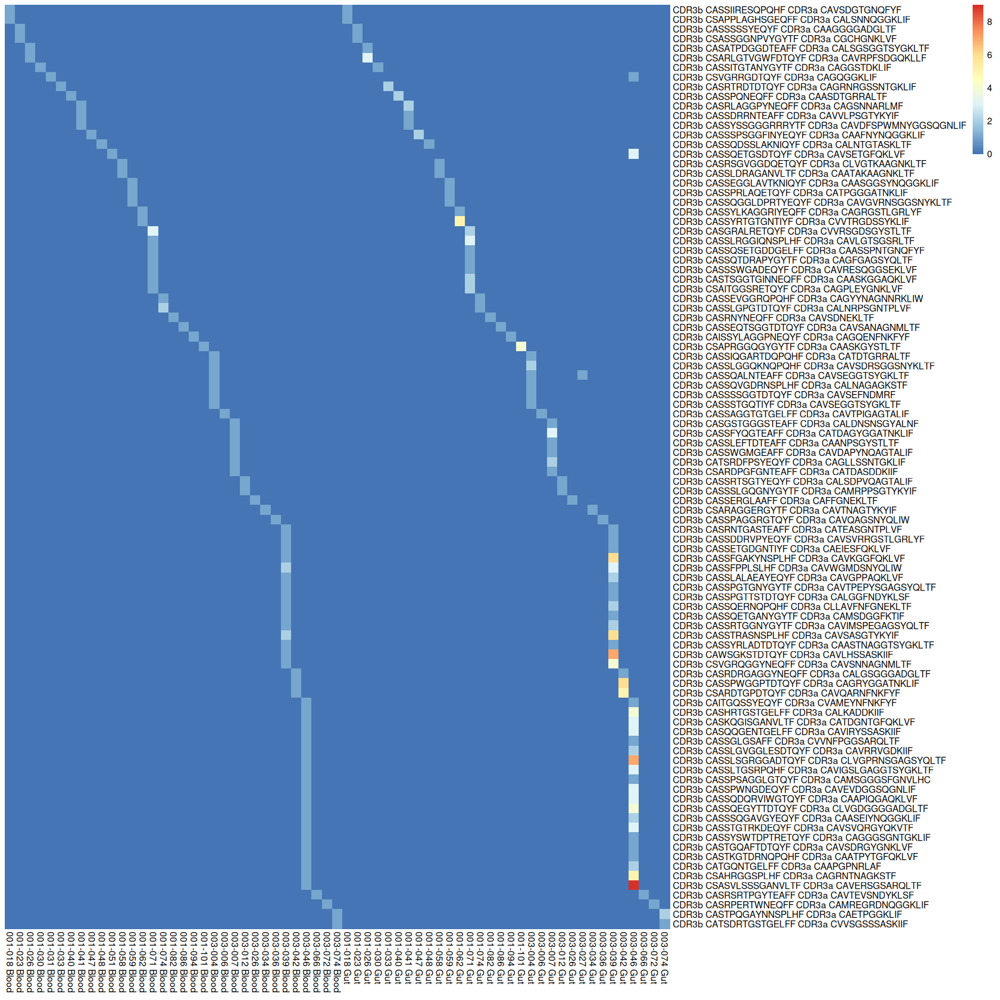

In [161]:
options(repr.plot.width = 14, repr.plot.height = 14)
pheatmap::pheatmap(mtx_cd4_clones, scale = "none", cluster_rows = F, cluster_cols = F,
                  #color=colorRampPalette(c("lightskyblue1", "snow","indianred2", "red4"))(50), 
         border_color = "black",
                  fontsize = 9)

In [ ]:
## Are CD4 CTL betas found more often in bulk TCRseq of Cd?

In [167]:
options(repr.plot.width = 14, repr.plot.height = 14)
pheatmap::pheatmap(mtx_cd4_clones, scale = "none", cluster_rows = F, cluster_cols = F,
                  #color=colorRampPalette(c("lightskyblue1", "snow","indianred2", "red4"))(50), 
         width = 14, height = 14,
                  fontsize = 9, filename = "figures/tcr_repertoire/heatmap_overlap_cd4_ctl_blood_gut.pdf")

## Clones shared between patients

In [84]:
metadata_6 <- blood_5p@meta.data  %>% dplyr::filter(cd4_ctl == TRUE)

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa, participant_id) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))  %>% 
dplyr::filter(clone_aa != "CDR3b NA CDR3a NA")

clone_table

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


clone_aa,participant_id,n,sum
<chr>,<chr>,<int>,<int>
CDR3b CASSASGQGIAFF CDR3a CAVSALKAAGNKLTF,001-063,4,0
CDR3b CASSQDIVAGGQVLTF CDR3a NA,001-063,4,0
CDR3b CASSYSGYEQYF CDR3a CAASAPGNQGGKLIF,001-063,4,0
CDR3b CSARLVGVPNEQFF CDR3a CAVISSNDYKLSF,001-058,4,0
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,001-071,3,0
CDR3b CASSLRVYEQFF CDR3a CALSPYTNAGKSTF,001-071,3,0
CDR3b CASSPDEQFF CDR3a CATSLGHGQNFVF,001-022,3,0
CDR3b CASSPGTGSGNTEAFF CDR3a CALSDKNAGNKLTF,001-051,3,0
CDR3b CASSPPSGSDTEAFF CDR3a CAVSRGAGGTSYGKLTF,001-063,3,0


In [85]:
clone_table  %>% dplyr::select(-sum)  %>% 
pivot_wider(names_from = "participant_id", values_from = "n", values_fill = 0) 

clone_aa,001-063,001-058,001-071,001-022,001-051,001-064,001-023,001-031,003-077,⋯,003-011,001-090,003-059,001-009,001-078,001-019,001-047,003-027,001-092,001-091
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
CDR3b CASSASGQGIAFF CDR3a CAVSALKAAGNKLTF,4,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSQDIVAGGQVLTF CDR3a NA,4,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSYSGYEQYF CDR3a CAASAPGNQGGKLIF,4,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CSARLVGVPNEQFF CDR3a CAVISSNDYKLSF,0,4,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,0,0,3,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSLRVYEQFF CDR3a CALSPYTNAGKSTF,0,0,3,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSPDEQFF CDR3a CATSLGHGQNFVF,0,0,0,3,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSPGTGSGNTEAFF CDR3a CALSDKNAGNKLTF,0,0,0,0,3,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
CDR3b CASSPPSGSDTEAFF CDR3a CAVSRGAGGTSYGKLTF,3,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [89]:
table_with_non_null  <- clone_table  %>% dplyr::select(-sum)  %>% 
mutate(is_null  =ifelse(n>0,1,0))  %>% 
dplyr::select(-n)  %>% 
pivot_wider(names_from = "participant_id", values_from = "is_null", values_fill = 0)   %>% 
column_to_rownames("clone_aa")

In [90]:
table_with_non_null$sum  <- rowSums(table_with_non_null)

In [91]:
table_with_non_null  %>% arrange(desc(sum))

,001-063,001-058,001-071,001-022,001-051,001-064,001-023,001-031,003-077,001-052,⋯,001-090,003-059,001-009,001-078,001-019,001-047,003-027,001-092,001-091,sum
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CDR3b CASSHRDRAYEQYF CDR3a CAASGFGNVLHC,0,0,0,0,1,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,2
CDR3b NA CDR3a CAVRDSNYQLIW,0,0,0,0,0,0,1,0,0,0,⋯,0,0,0,0,0,0,0,0,0,2
CDR3b CASSASGQGIAFF CDR3a CAVSALKAAGNKLTF,1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CASSQDIVAGGQVLTF CDR3a NA,1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CASSYSGYEQYF CDR3a CAASAPGNQGGKLIF,1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CSARLVGVPNEQFF CDR3a CAVISSNDYKLSF,0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CASGRALRETQYF CDR3a CVVRSGDSGYSTLTF,0,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CASSLRVYEQFF CDR3a CALSPYTNAGKSTF,0,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
CDR3b CASSPDEQFF CDR3a CATSLGHGQNFVF,0,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1


In [55]:
ls()

[1] "all_md"              "blood_5p"            "cd4_clones_in_gut"  
 [4] "cl_t"                "clone_table"         "clone_table_nona"   
 [7] "df"                  "df_all"              "ggtheme"            
[10] "gut_5p"              "i"                   "md"                 
[13] "md_joint_with_tcr"   "md_tcr_gut"          "md7"                
[16] "metadata_6"          "n_all"               "n_in_gut"           
[19] "overlap"             "shared_clones_no_na"

In [ ]:
DimPlot(gut_5p, raster = F, 
          cells.highlight = colnames(gut_5p)[grep(gut_5p$clone_aa, 
                                                       pattern = "CDR3b CASSHRDRAYEQYF CDR3a CAASGFGNVLHC")]) +
    ggtitle("CDR3b CASSHRDRAYEQYF CDR3a CAASGFGNVLHC")
   

In [ ]:
DimPlot(blood_5p, raster = F, 
          cells.highlight = colnames(blood_5p)[grep(blood_5p$clone_aa, 
                                                       pattern = "CDR3b CASSHRDRAYEQYF CDR3a CAASGFGNVLHC")]) +
    ggtitle("CDR3b CASSHRDRAYEQYF CDR3a CAASGFGNVLHC")
  

## Clones shared between blood and gut

In [14]:
blood_5p@meta.data  %>% group_by(participant_id, diagnosis)  %>% tally

participant_id,diagnosis,n
<chr>,<chr>,<int>
001-009,FGID,6939
001-011,CD,9269
001-014,CD,4716
001-015,UC,7855
001-018,CD,14411
001-019,CD,14301
001-022,CD,13902
001-023,FGID,10179
001-024,CD,10149


In [41]:
blood_5p$annotations  %>% table

.
          CD8_Naive           CD4_Naive  CD4_Central_Memory        CD4_Teff_Th2 
             106441              196865               57801               62393 
     CD4_Treg_Naive  CD4_Treg_Activated  CD8_Central_Memory CD8_Effector_Memory 
              17024               12014               27184               39620 
           NK_cells             CD8_Tgd   CD4_Teff_Th1/Th17              ISAGhi 
              22902               25271               17326                4840 
      Proliferating 
               3893 

In [44]:
for(i in levels(factor(blood_5p$annotations))){
    
    md7 <- blood_5p@meta.data  %>% dplyr::filter(annotations == i)

cl_t <- md7 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))  %>% 
dplyr::filter(!grepl(clone_aa, pattern = " NA"))
 n_all = nrow(cl_t)
n_in_gut = nrow(cl_t  %>% dplyr::filter(clone_aa %in% gut_5p$clone_aa))
    overlap = n_in_gut/n_all
    df = data.frame(annotation = i,
                   n_all = n_all,
                   n_in_gut = n_in_gut,
                   overlap = overlap)
    if(i == levels(factor(blood_5p$annotations))[1]){
        df_all  <- df
    } else {
        df_all  <- rbind(df_all, df)
    }
    }



In [45]:
df_all

annotation,n_all,n_in_gut,overlap
<chr>,<int>,<int>,<dbl>
CD8_Naive,73899,3,4.059595e-05
CD4_Naive,131632,5,3.798468e-05
CD4_Central_Memory,39384,102,2.589884e-03
CD4_Teff_Th2,40757,316,7.753269e-03
CD4_Treg_Naive,10293,2,1.943068e-04
CD4_Treg_Activated,8539,72,8.431901e-03
CD8_Central_Memory,15206,38,2.499014e-03
CD8_Effector_Memory,13923,73,5.243123e-03
NK_cells,1107,5,4.516712e-03


In [50]:
  md7 <- blood_5p@meta.data  %>% dplyr::filter(cd4_ctl == TRUE)

cl_t <- md7 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))  %>% 
dplyr::filter(!grepl(clone_aa, pattern = " NA"))
 n_all = nrow(cl_t)
n_in_gut = nrow(cl_t  %>% dplyr::filter(clone_aa %in% gut_5p$clone_aa))
    overlap = n_in_gut/n_all
    df = data.frame(annotation = "CD4 CTL",
                   n_all = n_all,
                   n_in_gut = n_in_gut,
                   overlap = overlap)
   df_all  <- rbind(df_all, df)

In [51]:
df_all 

annotation,n_all,n_in_gut,overlap
<chr>,<int>,<int>,<dbl>
CD8_Naive,73899,3,4.059595e-05
CD4_Naive,131632,5,3.798468e-05
CD4_Central_Memory,39384,102,2.589884e-03
CD4_Teff_Th2,40757,316,7.753269e-03
CD4_Treg_Naive,10293,2,1.943068e-04
CD4_Treg_Activated,8539,72,8.431901e-03
CD8_Central_Memory,15206,38,2.499014e-03
CD8_Effector_Memory,13923,73,5.243123e-03
NK_cells,1107,5,4.516712e-03


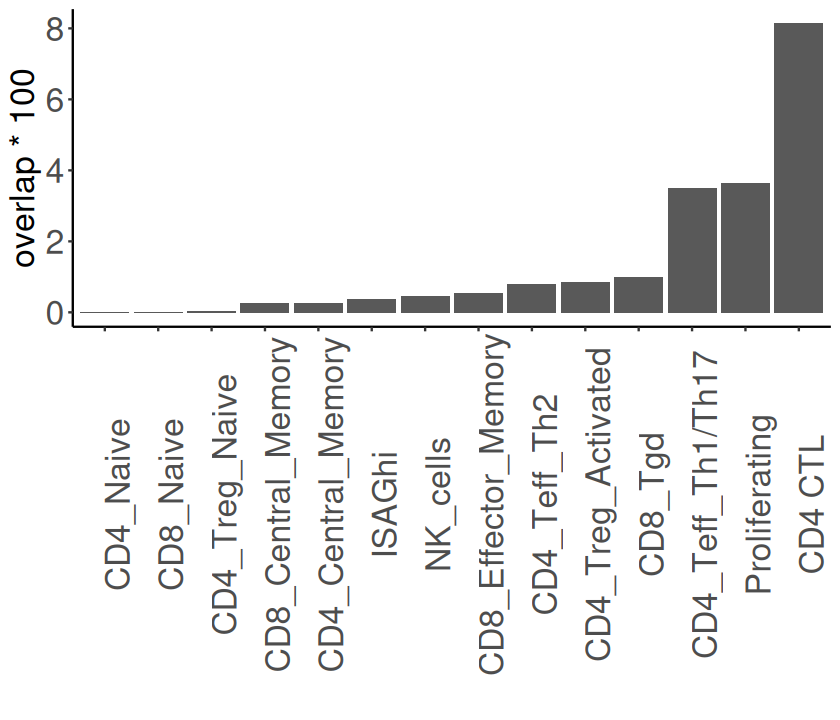

In [52]:
options(repr.plot.width = 7, repr.plot.height = 6)
df_all  %>% 
ggplot(aes(x = reorder(annotation, X = overlap, FUN = max), y = overlap*100)) + 
theme_classic() +
stat_summary(geom = "bar", fun = mean) +
xlab("") +
ggtheme() +
theme(axis.text.x = element_text(angle = 90))

In [54]:
ggsave("figures/tcr/barplot_gut_clones_in_blood2.svg", width = 14, height = 15, units = "cm")

# TCR specificity - TCRMatch

In [ ]:
blood_5p$cdr3_B

In [25]:
tcrb2 <- as.data.frame(blood_5p$cdr3_B)

colnames(tcrb2) = "seq"

In [28]:
tcrb2  <- tcrb2  %>% dplyr::filter(seq != "NA")  %>% unique

In [29]:
rownames(tcrb2)  <- NULL

In [31]:
tcrb2$seq  %>% duplicated  %>% table

.
 FALSE 
394185 

In [32]:
tcrb2

write_delim(tcrb2, delim = "\t", quote = "none", col_names = F, file = "blood_5p_tcrb_for_tcrmatch_trimmed.csv")

seq
<chr>
CASSSVRTGRMNTEAFF
CASSQSRGGNTIYF
CSVEGTSDEQYF
CASSLPGQVAGTEAFF
CASSQVYGTSGIF
CSAPAPGAGNTIYF
CASRVAGGRRGYNEQFF
CASSLVASGTDTQYF
CASSSGLGFEQFF


In [34]:
rm(list = ls())